<a href="https://colab.research.google.com/github/renuka-rajappan/renuka-rajappan/blob/main/SMD_Complete_Colab_Original_Hyperparameter_Tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  SMD DataSet


In [1]:
# GOOGLE COLAB: DRIVE MOUNT AND PROJECT PATHS
from pathlib import Path
import os, sys
from google.colab import drive

drive.mount('/content/drive')

MYDRIVE = Path('/content/drive/MyDrive')

# OPTIONAL: set these explicitly if your folders are stored elsewhere.
# Example: DATASET_PATH_OVERRIDE = "/content/drive/MyDrive/datasets/ServerMachineDataset"
DATASET_PATH_OVERRIDE = None
# Example: PROJECT_ROOT_OVERRIDE = "/content/drive/MyDrive/cloud-anomaly-research/SMD_Anomaly_Detection"
PROJECT_ROOT_OVERRIDE = None


def _valid_smd_folder(path):
    path = Path(path).expanduser()
    return all((path / sub).is_dir() for sub in ('train', 'test', 'test_label'))

if DATASET_PATH_OVERRIDE:
    DATASET_PATH = Path(DATASET_PATH_OVERRIDE).expanduser()
    if not _valid_smd_folder(DATASET_PATH):
        raise FileNotFoundError(
            f"SMD data folder is incomplete: {DATASET_PATH}. It must contain train, test and test_label."
        )
else:
    _dataset_candidates = [
        MYDRIVE / 'cloud-anomaly-research' / 'SMD_Anomaly_Detection' / 'data' / 'raw' / 'OmniAnomaly' / 'ServerMachineDataset',
        MYDRIVE / 'SMD_Anomaly_Detection' / 'data' / 'raw' / 'OmniAnomaly' / 'ServerMachineDataset',
        MYDRIVE / 'data' / 'raw' / 'OmniAnomaly' / 'ServerMachineDataset',
        MYDRIVE / 'ServerMachineDataset',
        MYDRIVE / 'datasets' / 'ServerMachineDataset',
        MYDRIVE / 'SMD' / 'ServerMachineDataset',
    ]
    DATASET_PATH = next((p for p in _dataset_candidates if _valid_smd_folder(p)), None)
    if DATASET_PATH is None:
        raise FileNotFoundError(
            'Could not find ServerMachineDataset in the common MyDrive folders. '
            'Set DATASET_PATH_OVERRIDE in this cell to the exact Drive folder containing train/, test/ and test_label/.'
        )

if PROJECT_ROOT_OVERRIDE:
    PROJECT_ROOT = Path(PROJECT_ROOT_OVERRIDE).expanduser()
else:
    # Preserve the original project root layout when data/raw/OmniAnomaly is present.
    if DATASET_PATH.name == 'ServerMachineDataset' and DATASET_PATH.parent.name == 'OmniAnomaly' and DATASET_PATH.parent.parent.name == 'raw':
        PROJECT_ROOT = DATASET_PATH.parents[3]
    else:
        # Dataset-only Drive upload: keep all generated artifacts in this Drive folder.
        PROJECT_ROOT = MYDRIVE / 'SMD_Anomaly_Detection_Colab'

PROJECT_ROOT.mkdir(parents=True, exist_ok=True)
DATASET_PATH = Path(DATASET_PATH)
TRAIN_PATH = DATASET_PATH / 'train'
TEST_PATH = DATASET_PATH / 'test'
LABEL_PATH = DATASET_PATH / 'test_label'
INTERPRETATION_PATH = DATASET_PATH / 'interpretation_label'  # optional in this notebook

for name, path in {'train': TRAIN_PATH, 'test': TEST_PATH, 'test_label': LABEL_PATH}.items():
    assert path.is_dir(), f'Missing {name} folder: {path}'

print('Google Drive mounted.')
print('Dataset:', DATASET_PATH)
print('Project/output root:', PROJECT_ROOT)
print('Train files:', len(list(TRAIN_PATH.glob('*.txt'))))
print('Test files:', len(list(TEST_PATH.glob('*.txt'))))
print('Label files:', len(list(LABEL_PATH.glob('*.txt'))))
print('GPU available:', __import__('torch').cuda.is_available() if 'torch' in sys.modules else 'PyTorch will be checked in the next cell')


Mounted at /content/drive
Google Drive mounted.
Dataset: /content/drive/MyDrive/ServerMachineDataset
Project/output root: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab
Train files: 28
Test files: 28
Label files: 28
GPU available: PyTorch will be checked in the next cell


# PHASE 1 - Dataset Acquisition and Verification
### 1.1 Dataset Verification

In [ ]:
#check dependencies
from importlib.metadata import version, PackageNotFoundError

required_packages = {
    "six": "1.11.0",
    "matplotlib": "3.0.2",
    "numpy": "1.15.4",
    "pandas": "0.23.4",
    "scipy": "1.2.0",
    "scikit-learn": "0.20.2",
    "tensorflow-gpu": "1.12.0",
    "tensorflow-probability": "0.5.0",
    "tqdm": "4.28.1",
    "imageio": "2.4.1",
    "fs": "2.3.0",
    "click": "7.0",
}

print("=" * 75)
print("DEPENDENCY VERSION CHECK")
print("=" * 75)

for package, required_version in required_packages.items():
    try:
        installed_version = version(package)

        if installed_version == required_version:
            status = "MATCH"
        else:
            status = "DIFFERENT VERSION"

        print(
            f"{package:<25} "
            f"Required: {required_version:<12} "
            f"Installed: {installed_version:<12} "
            f"{status}"
        )

    except PackageNotFoundError:
        print(
            f"{package:<25} "
            f"Required: {required_version:<12} "
            f"NOT INSTALLED"
        )

print("=" * 75)

DEPENDENCY VERSION CHECK
six                       Required: 1.11.0       Installed: 1.17.0       DIFFERENT VERSION
matplotlib                Required: 3.0.2        Installed: 3.10.0       DIFFERENT VERSION
numpy                     Required: 1.15.4       Installed: 2.1.3        DIFFERENT VERSION
pandas                    Required: 0.23.4       Installed: 2.2.3        DIFFERENT VERSION
scipy                     Required: 1.2.0        Installed: 1.16.3       DIFFERENT VERSION
scikit-learn              Required: 0.20.2       Installed: 1.6.1        DIFFERENT VERSION
tensorflow-gpu            Required: 1.12.0       NOT INSTALLED
tensorflow-probability    Required: 0.5.0        Installed: 0.25.0       DIFFERENT VERSION
tqdm                      Required: 4.28.1       Installed: 4.67.3       DIFFERENT VERSION
imageio                   Required: 2.4.1        Installed: 2.38.1       DIFFERENT VERSION
fs                        Required: 2.3.0        NOT INSTALLED
click                     Requ

In [ ]:
import numpy as np
import pandas as pd
import matplotlib
import scipy
import sklearn
import torch
import os
import json
import hashlib

import matplotlib.pyplot as plt
import seaborn as sns
import gc
import itertools
import platform
import random
import threading
import time
import traceback
from datetime import datetime, timezone
from pathlib import Path
from types import SimpleNamespace

import psutil
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from IPython.display import display, Markdown

print("Libraries imported successfully!")

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("PyTorch:", torch.__version__)

print("\nAll libraries imported successfully!")

Libraries imported successfully!
NumPy: 2.1.3
Pandas: 2.2.3
Matplotlib: 3.10.0
SciPy: 1.16.3
Scikit-learn: 1.6.1
PyTorch: 2.11.0+cpu

All libraries imported successfully!


### 1.2 Define project paths

In [ ]:

from pathlib import Path
import sys
from IPython.display import display

# ------------------------------------------------------------
# PROJECT CONFIGURATION (set in the first Colab setup cell)
# ------------------------------------------------------------
PROJECT_ROOT = Path(PROJECT_ROOT)
DATASET_PATH = Path(DATASET_PATH)

# ------------------------------------------------------------
# DATASET PATHS
# ------------------------------------------------------------
TRAIN_PATH = DATASET_PATH / "train"
TEST_PATH = DATASET_PATH / "test"
LABEL_PATH = DATASET_PATH / "test_label"
INTERPRETATION_PATH = DATASET_PATH / "interpretation_label"  # optional

# ------------------------------------------------------------
# OUTPUT PATHS
# ------------------------------------------------------------

RESULTS = PROJECT_ROOT / "results"
PLOTS_PATH = RESULTS / "plots"
METRICS_PATH = RESULTS / "metrics"
EDA_REPORT_PATH = PROJECT_ROOT / "reports" / "EDA_Report"
REPORT_PATH = PROJECT_ROOT / "reports"

for folder in [PLOTS_PATH, METRICS_PATH, EDA_REPORT_PATH]:
    folder.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# DATASET DIRECTORY CHECK
# ------------------------------------------------------------

for name, path in {
    "Training": TRAIN_PATH,
    "Testing": TEST_PATH,
    "Test labels": LABEL_PATH
}.items():
    assert path.is_dir(), f"{name} folder missing: {path}"
    print(f"{name}: VERIFIED")

if INTERPRETATION_PATH.is_dir():
    print("Interpretation labels: VERIFIED")
else:
    print("Interpretation labels: not present (optional; main SMD phases use test_label).")

# ------------------------------------------------------------
# MACHINE DISCOVERY
# ------------------------------------------------------------

train_files = sorted(TRAIN_PATH.glob("*.txt"))
test_files = sorted(TEST_PATH.glob("*.txt"))
label_files = sorted(LABEL_PATH.glob("*.txt"))

train_machines = [f.stem for f in train_files]
test_machines = [f.stem for f in test_files]
label_machines = [f.stem for f in label_files]

print("\nSMD DATASET SUMMARY")
print("-" * 40)
print("Training machines:", len(train_machines))
print("Testing machines:", len(test_machines))
print("Label files:", len(label_machines))

print("\nMachine names:")
print(train_machines)

# ------------------------------------------------------------
# CONSISTENCY CHECKS
# ------------------------------------------------------------

EXPECTED_MACHINES = 28

assert len(train_machines) == EXPECTED_MACHINES, \
    f"Expected {EXPECTED_MACHINES} machines, found {len(train_machines)}"

assert set(train_machines) == set(test_machines), \
    "Training and testing machine files do not match."

assert set(train_machines) == set(label_machines), \
    "Training and label machine files do not match."

print("\nSUCCESS: Dataset files verified.")


Training: VERIFIED
Testing: VERIFIED
Test labels: VERIFIED
Interpretation labels: VERIFIED

SMD DATASET SUMMARY
----------------------------------------
Training machines: 28
Testing machines: 28
Label files: 28

Machine names:
['machine-1-1', 'machine-1-2', 'machine-1-3', 'machine-1-4', 'machine-1-5', 'machine-1-6', 'machine-1-7', 'machine-1-8', 'machine-2-1', 'machine-2-2', 'machine-2-3', 'machine-2-4', 'machine-2-5', 'machine-2-6', 'machine-2-7', 'machine-2-8', 'machine-2-9', 'machine-3-1', 'machine-3-10', 'machine-3-11', 'machine-3-2', 'machine-3-3', 'machine-3-4', 'machine-3-5', 'machine-3-6', 'machine-3-7', 'machine-3-8', 'machine-3-9']

SUCCESS: Dataset files verified.


In [ ]:

# ============================================================
# PHASE 2: SMD ANOMALY DETECTION
# INITIAL PROJECT CONFIGURATION
# ============================================================

# ------------------------------------------------------------
# 1. IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

import sys
import os
import json
import hashlib
import inspect
import importlib

from pathlib import Path
from IPython.display import display

# ------------------------------------------------------------
# 2. MAIN PROJECT AND DATASET DIRECTORIES
# ------------------------------------------------------------

# These are defined by the Google Drive setup cell at the top of the notebook.
PROJECT_ROOT = Path(PROJECT_ROOT)
DATASET_PATH = Path(DATASET_PATH)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

TRAIN_PATH = DATASET_PATH / "train"
TEST_PATH = DATASET_PATH / "test"
LABEL_PATH = DATASET_PATH / "test_label"
INTERPRETATION_PATH = DATASET_PATH / "interpretation_label"  # optional

# ------------------------------------------------------------
# 4. EXPECTED DATASET PROPERTIES
# ------------------------------------------------------------

EXPECTED_MACHINES = 28
EXPECTED_FEATURES = 38

# ------------------------------------------------------------
# 5. PYTHON SOURCE MODULES
# ------------------------------------------------------------

SRC_PATH = PROJECT_ROOT / "src"
dl = None

# The original project may include an optional src/data_loader.py module.
# The notebook also defines its own load_machine() function, so this module
# is not required when only the SMD data folder is stored in Google Drive.
if (SRC_PATH / "data_loader.py").is_file():
    import src.data_loader as dl
    importlib.reload(dl)

print("=" * 65)
print("DATA LOADER INSPECTION")
print("=" * 65)

if dl is not None:
    print("\nDATA LOADER LOCATION:")
    print(inspect.getfile(dl))
    print("\nAVAILABLE FUNCTIONS:")
    for name, obj in inspect.getmembers(dl, inspect.isfunction):
        if obj.__module__ == dl.__name__:
            print(f"{name}{inspect.signature(obj)}")
else:
    print("Optional src.data_loader.py not found; using the notebook's own data loader.")

# ------------------------------------------------------------
# 6. INSPECT EXPECTED DATA LOADER FUNCTIONS
# ------------------------------------------------------------

required_functions = [
    "discover_machines",
    "load_machine",
    "anomaly_segments"
]

print("\nEXPECTED FUNCTION AVAILABILITY:")

for name in required_functions:

    available = (dl is not None and hasattr(dl, name))

    print(
        f"{name:<25}: "
        f"{'AVAILABLE' if available else 'NOT DEFINED'}"
    )


DATA LOADER INSPECTION
Optional src.data_loader.py not found; using the notebook's own data loader.

EXPECTED FUNCTION AVAILABILITY:
discover_machines        : NOT DEFINED
load_machine             : NOT DEFINED
anomaly_segments         : NOT DEFINED


In [ ]:

# ------------------------------------------------------------
# 1. MASTER COLOUR PALETTE
# ------------------------------------------------------------

MASTER_PALETTE = {
    "gold":       "#FFD700",
    "electric":   "#00BFFF",
    "ruby":       "#E0115F",
    "emerald":    "#00C957",
    "purple":     "#8A2BE2",
    "rose_gold":  "#B76E79",
    "silver":     "#AEB6BF",
    "pink":       "#FF1493",
    "white":      "#F8F8FF",
    "amber":      "#FFBF00",
    "turquoise":  "#40E0D0",
    "black":      "#171717",
    "navy":       "#191970",
    "coral":      "#FF7F50",
    "teal":       "#008080",
}

# ------------------------------------------------------------
# 2. DEFAULT COLOUR SEQUENCE FOR ALL GRAPHS
# ------------------------------------------------------------

MASTER_COLORS = list(MASTER_PALETTE.values())

# ------------------------------------------------------------
# 3. MATPLOTLIB GLOBAL SETTINGS
# ------------------------------------------------------------

plt.rcParams.update({

    # Figure
    "figure.figsize": (12, 6),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",

    # Background
    "figure.facecolor": "#FFFFFF",
    "axes.facecolor": "#FFFFFF",

    # Colour cycle
    "axes.prop_cycle": plt.cycler(
        color=MASTER_COLORS
    ),

    # Titles
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.titlecolor": MASTER_PALETTE["navy"],

    # Axis labels
    "axes.labelsize": 12,
    "axes.labelcolor": MASTER_PALETTE["black"],

    # Tick labels
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,

    # Grid
    "axes.grid": True,
    "grid.color": MASTER_PALETTE["silver"],
    "grid.linestyle": "--",
    "grid.alpha": 0.30,

    # Borders
    "axes.spines.top": False,
    "axes.spines.right": False,

    # Font
    "font.family": "DejaVu Sans",

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": True,

})

# ------------------------------------------------------------
# 4. SEABORN GLOBAL THEME
# ------------------------------------------------------------

sns.set_theme(
    style="whitegrid",
    palette=MASTER_COLORS,
    font="DejaVu Sans"
)

# ------------------------------------------------------------
# 5. CONFIRMATION
# ------------------------------------------------------------

print("MASTER COLOUR PALETTE ACTIVATED")
print("Matplotlib and Seaborn themes configured.")


MASTER COLOUR PALETTE ACTIVATED
Matplotlib and Seaborn themes configured.


In [ ]:
#Check machine files
train_files = sorted(TRAIN_PATH.glob("*.txt"))
test_files = sorted(TEST_PATH.glob("*.txt"))
label_files = sorted(LABEL_PATH.glob("*.txt"))
interpretation_files = sorted(INTERPRETATION_PATH.glob("*.txt"))

train_machines = {f.stem for f in train_files}
test_machines = {f.stem for f in test_files}
label_machines = {f.stem for f in label_files}

print("Training files:", len(train_files))
print("Testing files:", len(test_files))
print("Test label files:", len(label_files))
print("Interpretation files:", len(interpretation_files))

print("\nMachine matching:")

print(
    "Training and testing match:",
    train_machines == test_machines
)

print(
    "Training and labels match:",
    train_machines == label_machines
)

print("\nMissing files:")

print("Missing training:", sorted(test_machines - train_machines))
print("Missing testing:", sorted(train_machines - test_machines))
print("Missing labels:", sorted(train_machines - label_machines))

print("\nFirst five machines:")

for machine in sorted(train_machines)[:5]:
    print(machine)

Training files: 28
Testing files: 28
Test label files: 28
Interpretation files: 28

Machine matching:
Training and testing match: True
Training and labels match: True

Missing files:
Missing training: []
Missing testing: []
Missing labels: []

First five machines:
machine-1-1
machine-1-2
machine-1-3
machine-1-4
machine-1-5


### 1.3 Create a machine data loading function

In [ ]:
def load_machine(machine_name=None, dataset_path=None, machine_id=None):

    machine_name = machine_name if machine_name is not None else machine_id
    if machine_name is None:
        raise ValueError("Supply machine_name or machine_id.")
    root = Path(dataset_path) if dataset_path is not None else DATASET_PATH
    train_path = root / "train"
    test_path = root / "test"
    label_path = root / "test_label"

    train_file = train_path / f"{machine_name}.txt"
    test_file = test_path / f"{machine_name}.txt"
    label_file = label_path / f"{machine_name}.txt"

    # Load training data
    train_data = np.loadtxt(
        train_file,
        delimiter=",",
        dtype=np.float32
    )

    # Load testing data
    test_data = np.loadtxt(
        test_file,
        delimiter=",",
        dtype=np.float32
    )

    # Load labels as float first to detect invalid values
    labels = np.loadtxt(
        label_file,
        delimiter=",",
        dtype=np.float32
    )

    # Ensure consistent dimensions
    train_data = np.atleast_2d(train_data)
    test_data = np.atleast_2d(test_data)
    labels = np.asarray(labels).reshape(-1)

    return train_data, test_data, labels


# Test the loading function using the first machine
first_machine = sorted(train_machines)[0]

train_data, test_data, labels = load_machine(first_machine)

print("Machine:", first_machine)

print("\nTraining data shape:", train_data.shape)
print("Testing data shape:", test_data.shape)
print("Labels shape:", labels.shape)

print("\nFirst five training observations:")
print(train_data[:5])

print("\nFirst five labels:")
print(labels[:5])

Machine: machine-1-1

Training data shape: (28479, 38)
Testing data shape: (28479, 38)
Labels shape: (28479,)

First five training observations:
[[3.22580e-02 3.91950e-02 2.78710e-02 2.43900e-02 0.00000e+00 9.15385e-01
  3.43691e-01 0.00000e+00 2.00110e-02 1.22000e-04 1.06312e-01 8.10810e-02
  2.73970e-02 6.02660e-02 8.50180e-02 1.22516e-01 0.00000e+00 0.00000e+00
  6.21950e-02 4.12210e-02 4.32420e-02 3.16070e-02 5.33195e-01 1.02240e-02
  1.11950e-02 9.27400e-03 0.00000e+00 3.66250e-02 0.00000e+00 4.29800e-03
  2.99930e-02 2.21310e-02 0.00000e+00 4.50000e-05 3.46770e-02 3.47470e-02
  0.00000e+00 0.00000e+00]
 [4.30110e-02 4.87290e-02 3.34450e-02 2.55520e-02 0.00000e+00 9.15385e-01
  3.44633e-01 0.00000e+00 1.91600e-02 1.72200e-03 1.36174e-01 8.10810e-02
  2.73970e-02 5.40290e-02 8.46210e-02 1.51205e-01 0.00000e+00 0.00000e+00
  5.11310e-02 3.66510e-02 4.25540e-02 3.12290e-02 5.76976e-01 7.56400e-03
  1.17190e-02 6.76100e-03 0.00000e+00 3.65460e-02 0.00000e+00 4.29800e-03
  3.00410e-02 

### 1.4 Verify all 28 machines
We collect:

Training observations.
Testing observations.
Number of features.
Number of normal observations.
Number of anomalous observations.
Anomaly percentage.

In [ ]:
machine_summary = []

for machine in sorted(train_machines):

    train_data, test_data, labels = load_machine(machine)

    normal_count = int(np.sum(labels == 0))
    anomaly_count = int(np.sum(labels == 1))

    anomaly_percentage = (
        anomaly_count / len(labels) * 100
        if len(labels) > 0 else np.nan
    )

    machine_summary.append({

        "machine": machine,

        "train_rows": train_data.shape[0],

        "test_rows": test_data.shape[0],

        "train_features": train_data.shape[1],

        "test_features": test_data.shape[1],

        "label_count": len(labels),

        "normal_count": normal_count,

        "anomaly_count": anomaly_count,

        "anomaly_percentage": anomaly_percentage

    })


machine_summary_df = pd.DataFrame(machine_summary)

display(machine_summary_df)

,machine,train_rows,test_rows,train_features,test_features,label_count,normal_count,anomaly_count,anomaly_percentage
0,machine-1-1,28479,28479,38,38,28479,25785,2694,9.459602
1,machine-1-2,23694,23694,38,38,23694,23152,542,2.287499
2,machine-1-3,23702,23703,38,38,23703,22886,817,3.446821
3,machine-1-4,23706,23707,38,38,23707,22987,720,3.037078
4,machine-1-5,23705,23706,38,38,23706,23606,100,0.421834
5,machine-1-6,23688,23689,38,38,23689,19981,3708,15.652835
6,machine-1-7,23697,23697,38,38,23697,21299,2398,10.119424
7,machine-1-8,23698,23699,38,38,23699,22936,763,3.219545
8,machine-2-1,23693,23694,38,38,23694,22524,1170,4.937959
9,machine-2-2,23699,23700,38,38,23700,20867,2833,11.953586


### 1.5 Data quality verification
Now we check the original data for:

Missing values (NaN).
Infinite values.
Duplicate observations.
Invalid labels.
Unexpected feature counts.

In [ ]:
quality_results = []

for machine in sorted(train_machines):

    train_data, test_data, labels = load_machine(machine)

    # Missing values
    train_nan = int(np.isnan(train_data).sum())
    test_nan = int(np.isnan(test_data).sum())
    label_nan = int(np.isnan(labels).sum())

    # Infinite values
    train_inf = int(np.isinf(train_data).sum())
    test_inf = int(np.isinf(test_data).sum())
    label_inf = int(np.isinf(labels).sum())

    # Duplicate rows
    train_duplicates = int(
        pd.DataFrame(train_data).duplicated().sum()
    )

    test_duplicates = int(
        pd.DataFrame(test_data).duplicated().sum()
    )

    # Binary label verification
    valid_labels = np.isin(
        labels[np.isfinite(labels)],
        [0, 1]
    ).all()

    quality_results.append({

        "machine": machine,

        "train_nan": train_nan,

        "test_nan": test_nan,

        "label_nan": label_nan,

        "train_inf": train_inf,

        "test_inf": test_inf,

        "label_inf": label_inf,

        "train_duplicates": train_duplicates,

        "test_duplicates": test_duplicates,

        "valid_binary_labels": valid_labels

    })


quality_df = pd.DataFrame(quality_results)

display(quality_df)

,machine,train_nan,test_nan,label_nan,train_inf,test_inf,label_inf,train_duplicates,test_duplicates,valid_binary_labels
0,machine-1-1,0,0,0,0,0,0,0,0,True
1,machine-1-2,0,0,0,0,0,0,0,0,True
2,machine-1-3,0,0,0,0,0,0,0,0,True
3,machine-1-4,0,0,0,0,0,0,0,0,True
4,machine-1-5,0,0,0,0,0,0,0,0,True
5,machine-1-6,0,0,0,0,0,0,0,0,True
6,machine-1-7,0,0,0,0,0,0,0,0,True
7,machine-1-8,0,0,0,0,0,0,0,0,True
8,machine-2-1,0,0,0,0,0,0,0,0,True
9,machine-2-2,0,0,0,0,0,0,0,0,True


### 1.6 Verify label alignment

In [ ]:
alignment_results = []

for machine in sorted(train_machines):

    train_data, test_data, labels = load_machine(machine)

    alignment_results.append({

        "machine": machine,

        "test_observations": len(test_data),

        "label_observations": len(labels),

        "alignment_valid": len(test_data) == len(labels)

    })


alignment_df = pd.DataFrame(alignment_results)

display(alignment_df)

print(
    "\nAll machines have correct label alignment:",
    alignment_df["alignment_valid"].all()
)

,machine,test_observations,label_observations,alignment_valid
0,machine-1-1,28479,28479,True
1,machine-1-2,23694,23694,True
2,machine-1-3,23703,23703,True
3,machine-1-4,23707,23707,True
4,machine-1-5,23706,23706,True
5,machine-1-6,23689,23689,True
6,machine-1-7,23697,23697,True
7,machine-1-8,23699,23699,True
8,machine-2-1,23694,23694,True
9,machine-2-2,23700,23700,True



All machines have correct label alignment: True


### 1.7 Verify feature dimensions

In [ ]:
feature_results = []

for machine in sorted(train_machines):

    train_data, test_data, labels = load_machine(machine)

    feature_results.append({

        "machine": machine,

        "train_features": train_data.shape[1],

        "test_features": test_data.shape[1],

        "expected_features": EXPECTED_FEATURES,

        "train_valid": train_data.shape[1] == EXPECTED_FEATURES,

        "test_valid": test_data.shape[1] == EXPECTED_FEATURES

    })


feature_df = pd.DataFrame(feature_results)

display(feature_df)

print(
    "\nAll machines have 38 training features:",
    feature_df["train_valid"].all()
)

print(
    "All machines have 38 testing features:",
    feature_df["test_valid"].all()
)

### 1.8 Examine label distribution

In [ ]:

# ============================================================
# OVERALL ANOMALY DISTRIBUTION
# ============================================================

# 1. Calculate overall statistics

total_normal = machine_summary_df["normal_count"].sum()
total_anomaly = machine_summary_df["anomaly_count"].sum()

total_labels = total_normal + total_anomaly

overall_anomaly_percentage = (
    total_anomaly / total_labels * 100
    if total_labels > 0 else np.nan
)

print("Total normal observations:", total_normal)
print("Total anomalous observations:", total_anomaly)
print("Total labelled observations:", total_labels)

print(
    f"Overall anomaly percentage: "
    f"{overall_anomaly_percentage:.2f}%"
)


# ============================================================
# 2. VISUALISE ANOMALY DISTRIBUTION
# ============================================================

plt.figure(figsize=(14, 6))

ax = sns.barplot(
    data=machine_summary_df,
    x="machine",
    y="anomaly_percentage",
    color=MASTER_PALETTE["electric"],
    edgecolor=MASTER_PALETTE["navy"],
    linewidth=0.8
)

# Add average anomaly percentage reference line
plt.axhline(
    y=overall_anomaly_percentage,
    color=MASTER_PALETTE["ruby"],
    linestyle="--",
    linewidth=2,
    label=f"Overall Average: {overall_anomaly_percentage:.2f}%"
)

# Titles and labels
plt.title(
    "Anomaly Percentage Across 28 SMD Machines",
    pad=18
)

plt.xlabel("Machine")
plt.ylabel("Anomaly Percentage (%)")

plt.xticks(rotation=90)

# Grid
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

# Legend
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
#Save verification reports
# Save machine summary
machine_summary_df.to_csv(
    REPORT_PATH / "machine_summary.csv",
    index=False
)

# Save data quality report
quality_df.to_csv(
    REPORT_PATH / "data_quality_report.csv",
    index=False
)

# Save label alignment report
alignment_df.to_csv(
    REPORT_PATH / "label_alignment_report.csv",
    index=False
)

# Save feature verification report
feature_df.to_csv(
    REPORT_PATH / "feature_verification.csv",
    index=False
)

print("All verification reports saved successfully!")

print("\nReport location:")
print(REPORT_PATH)

In [ ]:
#Generate final verification summary
machine_count_valid = (
    len(train_machines) == EXPECTED_MACHINES
    and len(test_machines) == EXPECTED_MACHINES
    and len(label_machines) == EXPECTED_MACHINES
)

machine_matching_valid = (
    train_machines == test_machines == label_machines
)

alignment_valid = alignment_df["alignment_valid"].all()

feature_valid = (
    feature_df["train_valid"].all()
    and feature_df["test_valid"].all()
)

finite_valid = (
    quality_df[
        [
            "train_nan", "test_nan", "label_nan",
            "train_inf", "test_inf", "label_inf"
        ]
    ].to_numpy() == 0
).all()

binary_labels_valid = quality_df["valid_binary_labels"].all()

verification_summary = {

    "verification_date": datetime.now().isoformat(),

    "expected_machines": EXPECTED_MACHINES,

    "actual_training_machines": len(train_machines),

    "actual_testing_machines": len(test_machines),

    "actual_label_machines": len(label_machines),

    "machine_count_valid": bool(machine_count_valid),

    "machine_matching_valid": bool(machine_matching_valid),

    "label_alignment_valid": bool(alignment_valid),

    "feature_count_valid": bool(feature_valid),

    "all_values_finite": bool(finite_valid),

    "binary_labels_valid": bool(binary_labels_valid),

    "total_normal_observations": int(total_normal),

    "total_anomaly_observations": int(total_anomaly),

    "overall_anomaly_percentage": float(overall_anomaly_percentage)

}

# Save JSON report
with open(
    REPORT_PATH / "verification_summary.json",
    "w"
) as file:

    json.dump(
        verification_summary,
        file,
        indent=4
    )


display(pd.DataFrame([verification_summary]).T)


In [ ]:
#Final Phase 1 Status

In [ ]:
checks = {

    "28 machines available": machine_count_valid,

    "Machine files match": machine_matching_valid,

    "Test observations and labels align": alignment_valid,

    "All machines have 38 features": feature_valid,

    "No NaN or infinite values": finite_valid,

    "Labels contain only 0 and 1": binary_labels_valid

}

print("=" * 55)
print("PHASE 1 - DATASET VERIFICATION")
print("=" * 55)

for check, result in checks.items():

    status = "PASS" if result else "FAIL"

    print(f"{check}: {status}")

print("=" * 55)

if all(checks.values()):

    print("PHASE 1 STATUS: PASSED")

else:

    print("PHASE 1 STATUS: REVIEW REQUIRED")

print("=" * 55)

# PHASE 2: Exploratory Data Analysis (EDA)

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path(PROJECT_ROOT)
DATASET_PATH = Path(DATASET_PATH)
TRAIN_PATH = DATASET_PATH / "train"
TEST_PATH = DATASET_PATH / "test"
LABEL_PATH = DATASET_PATH / "test_label"
EDA_REPORT_PATH = PROJECT_ROOT / "reports" / "EDA_Report"
PLOTS_PATH = EDA_REPORT_PATH / "plots"
for p in (EDA_REPORT_PATH, PLOTS_PATH): p.mkdir(parents=True, exist_ok=True)
train_machines = sorted(p.stem for p in TRAIN_PATH.glob("*.txt"))
assert len(train_machines) == 28, f"Expected 28 machines, found {len(train_machines)}"
assert set(train_machines) == {p.stem for p in TEST_PATH.glob("*.txt")}
assert set(train_machines) == {p.stem for p in LABEL_PATH.glob("*.txt")}

def load_machine(machine=None, dataset_path=None, machine_id=None):
    machine = machine if machine is not None else machine_id
    if machine is None:
        raise ValueError("Supply machine or machine_id.")
    root = Path(dataset_path) if dataset_path is not None else DATASET_PATH
    train_dir, test_dir, label_dir = root / "train", root / "test", root / "test_label"
    train = np.atleast_2d(np.loadtxt(train_dir / f"{machine}.txt", delimiter=","))
    test = np.atleast_2d(np.loadtxt(test_dir / f"{machine}.txt", delimiter=","))
    labels = np.asarray(np.loadtxt(label_dir / f"{machine}.txt", delimiter=",")).reshape(-1)
    assert len(test) == len(labels), f"Label mismatch: {machine}"
    assert np.isin(labels, [0, 1]).all(), f"Nonbinary labels: {machine}"
    assert train.shape[1] == test.shape[1], f"Feature mismatch: {machine}"
    return train, test, labels.astype(int)

print("Verified machines:", len(train_machines))

Verified machines: 28


### 2.1 Machine-wise exploration and data quality

#### Class imbalance analysis across all machines

In [ ]:
machine_rows, feature_rows = [], []
for machine in train_machines:
    train, test, labels = load_machine(machine)
    normal, anomaly = int((labels==0).sum()), int((labels==1).sum())
    for split, arr in (("train", train), ("test", test)):
        for j in range(arr.shape[1]):
            col = arr[:, j]
            finite = col[np.isfinite(col)]
            q1, q3 = np.percentile(finite, [25, 75]) if len(finite) else (np.nan, np.nan)
            iqr = q3-q1
            outliers = int(((finite < q1-1.5*iqr)|(finite > q3+1.5*iqr)).sum()) if len(finite) and iqr>0 else 0
            feature_rows.append(dict(machine=machine, split=split, feature=f"metric_{j+1:02d}",
                mean=np.mean(finite) if len(finite) else np.nan,
                median=np.median(finite) if len(finite) else np.nan,
                std=np.std(finite) if len(finite) else np.nan,
                minimum=np.min(finite) if len(finite) else np.nan,
                maximum=np.max(finite) if len(finite) else np.nan,
                q1=q1, q3=q3, iqr=iqr, iqr_outlier_count=outliers,
                missing_count=int(np.isnan(col).sum()), infinite_count=int(np.isinf(col).sum()),
                constant=(len(finite)>0 and np.ptp(finite)==0)))
    machine_rows.append(dict(machine=machine, train_rows=len(train), test_rows=len(test),
        features=train.shape[1], normal_count=normal, anomaly_count=anomaly,
        normal_pct=100*normal/len(labels), anomaly_pct=100*anomaly/len(labels),
        normal_to_anomaly_ratio=normal/anomaly if anomaly else np.inf,
        train_missing=int(np.isnan(train).sum()), test_missing=int(np.isnan(test).sum()),
        train_infinite=int(np.isinf(train).sum()), test_infinite=int(np.isinf(test).sum()),
        train_constant_features=int(sum(np.ptp(train[np.isfinite(train[:,j]),j])==0 for j in range(train.shape[1]) if np.isfinite(train[:,j]).any())),
        train_duplicate_rows=int(pd.DataFrame(train).duplicated().sum()),
        test_duplicate_rows=int(pd.DataFrame(test).duplicated().sum())))
machine_df=pd.DataFrame(machine_rows)
feature_df=pd.DataFrame(feature_rows)
machine_df.to_csv(EDA_REPORT_PATH/'machine_wise_statistics.csv', index=False)
feature_df.to_csv(EDA_REPORT_PATH/'feature_descriptive_statistics.csv', index=False)
display(machine_df)
print('Features per machine:', sorted(machine_df.features.unique()))

In [ ]:
#Calculate class distribution
class_imbalance_results = []

for machine in train_machines:

    train, test, labels = load_machine(machine)

    normal_count = int(np.sum(labels == 0))
    anomaly_count = int(np.sum(labels == 1))

    total = len(labels)

    normal_percentage = normal_count / total * 100
    anomaly_percentage = anomaly_count / total * 100

    imbalance_ratio = (
        normal_count / anomaly_count
        if anomaly_count > 0 else np.inf
    )

    class_imbalance_results.append({

        "machine": machine,

        "total_observations": total,

        "normal_count": normal_count,

        "anomaly_count": anomaly_count,

        "normal_percentage": normal_percentage,

        "anomaly_percentage": anomaly_percentage,

        "normal_to_anomaly_ratio": imbalance_ratio

    })


class_imbalance_df = pd.DataFrame(
    class_imbalance_results
)

display(class_imbalance_df)

,machine,total_observations,normal_count,anomaly_count,normal_percentage,anomaly_percentage,normal_to_anomaly_ratio
0,machine-1-1,28479,25785,2694,90.540398,9.459602,9.571269
1,machine-1-2,23694,23152,542,97.712501,2.287499,42.715867
2,machine-1-3,23703,22886,817,96.553179,3.446821,28.012240
3,machine-1-4,23707,22987,720,96.962922,3.037078,31.926389
4,machine-1-5,23706,23606,100,99.578166,0.421834,236.060000
5,machine-1-6,23689,19981,3708,84.347165,15.652835,5.388619
6,machine-1-7,23697,21299,2398,89.880576,10.119424,8.881985
7,machine-1-8,23699,22936,763,96.780455,3.219545,30.060288
8,machine-2-1,23694,22524,1170,95.062041,4.937959,19.251282
9,machine-2-2,23700,20867,2833,88.046414,11.953586,7.365690


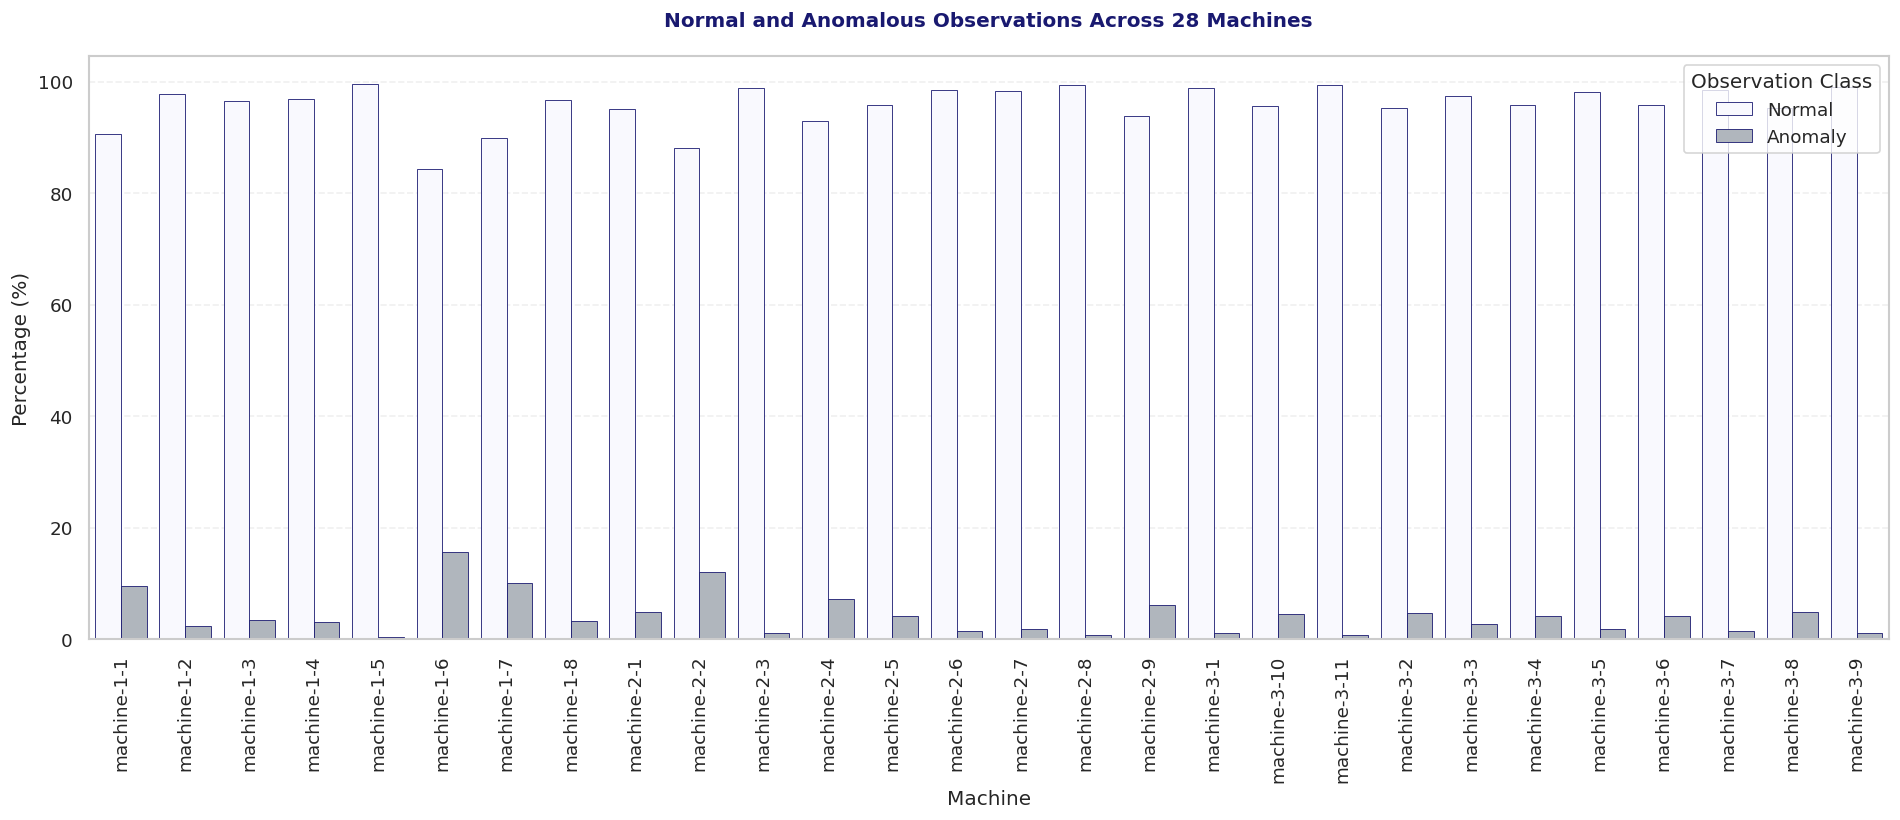

In [ ]:

# ============================================================
# CLASS IMBALANCE VISUALIZATION
# ============================================================

plt.figure(figsize=(16, 7))

# Reshape data for visualization
class_plot = class_imbalance_df.melt(
    id_vars="machine",
    value_vars=[
        "normal_percentage",
        "anomaly_percentage"
    ],
    var_name="class",
    value_name="percentage"
)

# Rename categories for a cleaner legend
class_plot["class"] = class_plot["class"].map({
    "normal_percentage": "Normal",
    "anomaly_percentage": "Anomaly"
})

# Plot using MASTER PALETTE
ax = sns.barplot(
    data=class_plot,
    x="machine",
    y="percentage",
    hue="class",
    palette={
        "Normal": MASTER_PALETTE["white"],
        "Anomaly": MASTER_PALETTE["silver"]
    },
    edgecolor=MASTER_PALETTE["navy"],
    linewidth=0.5
)

# Titles and labels
plt.title(
    "Normal and Anomalous Observations Across 28 Machines",
    pad=18
)

plt.xlabel("Machine")
plt.ylabel("Percentage (%)")

# Axis formatting
plt.xticks(rotation=90)

# Grid formatting
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

# Legend formatting
plt.legend(
    title="Observation Class",
    frameon=True
)

plt.tight_layout()

# Save high-resolution figure
plt.savefig(
    PLOTS_PATH / "class_imbalance_by_machine.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:
#Identify machines with different imbalance levels
print("MACHINES WITH HIGHEST ANOMALY PREVALENCE")

display(
    class_imbalance_df.sort_values(
        "anomaly_percentage",
        ascending=False
    ).head(10)
)

print("\nMACHINES WITH LOWEST ANOMALY PREVALENCE")

display(
    class_imbalance_df.sort_values(
        "anomaly_percentage"
    ).head(10)
)


MACHINES WITH HIGHEST ANOMALY PREVALENCE


,machine,total_observations,normal_count,anomaly_count,normal_percentage,anomaly_percentage,normal_to_anomaly_ratio
5,machine-1-6,23689,19981,3708,84.347165,15.652835,5.388619
9,machine-2-2,23700,20867,2833,88.046414,11.953586,7.365690
6,machine-1-7,23697,21299,2398,89.880576,10.119424,8.881985
0,machine-1-1,28479,25785,2694,90.540398,9.459602,9.571269
11,machine-2-4,23689,21995,1694,92.849002,7.150998,12.984061
16,machine-2-9,28722,26967,1755,93.889701,6.110299,15.365812
8,machine-2-1,23694,22524,1170,95.062041,4.937959,19.251282
26,machine-3-8,28704,27333,1371,95.223662,4.776338,19.936543
20,machine-3-2,23703,22594,1109,95.321267,4.678733,20.373309
18,machine-3-10,23693,22646,1047,95.580973,4.419027,21.629417



MACHINES WITH LOWEST ANOMALY PREVALENCE


,machine,total_observations,normal_count,anomaly_count,normal_percentage,anomaly_percentage,normal_to_anomaly_ratio
4,machine-1-5,23706,23606,100,99.578166,0.421834,236.060000
15,machine-2-8,23703,23542,161,99.320761,0.679239,146.223602
19,machine-3-11,28696,28498,198,99.310008,0.689992,143.929293
27,machine-3-9,28713,28410,303,98.944729,1.055271,93.762376
17,machine-3-1,28700,28392,308,98.926829,1.073171,92.181818
10,machine-2-3,23689,23420,269,98.864452,1.135548,87.063197
13,machine-2-6,28743,28319,424,98.524858,1.475142,66.790094
25,machine-3-7,28705,28271,434,98.488068,1.511932,65.140553
14,machine-2-7,23696,23279,417,98.240209,1.759791,55.824940
23,machine-3-5,23691,23265,426,98.201849,1.798151,54.612676


In [ ]:
# Save the report
class_imbalance_df.to_csv(
    EDA_REPORT_PATH / "class_imbalance_analysis.csv",
    index=False
)


### 2.2 Feature-level Exploration

**SMD Phase 2 EDA** · Run cells in order. All results are calculated from files; no observation counts are hard-coded.

**Paths:** `data/raw/OmniAnomaly/ServerMachineDataset/` → `results/metrics/`, `results/plots/`. Test labels are for descriptive EDA only, not model fitting.

In [ ]:
from pathlib import Path
import sys

# Project and dataset paths are defined in the first Google Colab setup cell.
PROJECT_ROOT = Path(PROJECT_ROOT)
DATASET_PATH = Path(DATASET_PATH)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


TRAIN_PATH = DATASET_PATH / "train"
TEST_PATH = DATASET_PATH / "test"
LABEL_PATH = DATASET_PATH / "test_label"
INTERPRETATION_PATH = DATASET_PATH / "interpretation_label"

# Output paths
RESULTS = PROJECT_ROOT / "results"
PLOTS_PATH = RESULTS / "plots"
METRICS_PATH = RESULTS / "metrics"
EDA_REPORT_PATH = PROJECT_ROOT / "reports/EDA_Report"

for folder in [PLOTS_PATH, METRICS_PATH, EDA_REPORT_PATH]:
    folder.mkdir(parents=True, exist_ok=True)

# Discover machines directly from training files
train_machines = sorted(
    file.stem for file in TRAIN_PATH.glob("*.txt")
)

test_machines = sorted(
    file.stem for file in TEST_PATH.glob("*.txt")
)

label_machines = sorted(
    file.stem for file in LABEL_PATH.glob("*.txt")
)

print("Training machines:", len(train_machines))
print("Testing machines:", len(test_machines))
print("Label files:", len(label_machines))

print("\nMachine names:")
print(train_machines)

assert len(train_machines) == 28, "Expected 28 training machines."
assert set(train_machines) == set(test_machines)
assert set(train_machines) == set(label_machines)

print("\nDataset verification successful!")

Training machines: 28
Testing machines: 28
Label files: 28

Machine names:
['machine-1-1', 'machine-1-2', 'machine-1-3', 'machine-1-4', 'machine-1-5', 'machine-1-6', 'machine-1-7', 'machine-1-8', 'machine-2-1', 'machine-2-2', 'machine-2-3', 'machine-2-4', 'machine-2-5', 'machine-2-6', 'machine-2-7', 'machine-2-8', 'machine-2-9', 'machine-3-1', 'machine-3-10', 'machine-3-11', 'machine-3-2', 'machine-3-3', 'machine-3-4', 'machine-3-5', 'machine-3-6', 'machine-3-7', 'machine-3-8', 'machine-3-9']

Dataset verification successful!


#### All-feature descriptive statistics and outliers

For each of the 38 anonymous metrics per machine, calculate variability, quantiles, IQR outlier counts, and missingness. Outliers are **statistical candidates**, not verified anomalies.

In [ ]:

# ============================================================
# FEATURE-LEVEL STATISTICS AND OUTLIER ANALYSIS
# SMD ANOMALY DETECTION
# ============================================================

import numpy as np
import pandas as pd
# Use the notebook-local load_machine() function created in Phase 1.
# It accepts both load_machine(machine) and load_machine(machine_id=..., dataset_path=...).

# ------------------------------------------------------------
# 2. CONFIGURATION
# ------------------------------------------------------------

FEATURE_NAMES = [
    f"feature_{i:02d}"
    for i in range(EXPECTED_FEATURES)
]

rows = []

# ------------------------------------------------------------
# 3. MACHINE-WISE FEATURE STATISTICS
# ------------------------------------------------------------

for machine in train_machines:

    print(f"Processing: {machine}")

    # Load machine data
    train_array, test_array, labels = load_machine(
        machine_id=machine,
        dataset_path=DATASET_PATH
    )

    # Convert NumPy arrays to Pandas DataFrames
    train = pd.DataFrame(
        train_array,
        columns=FEATURE_NAMES
    )

    test = pd.DataFrame(
        test_array,
        columns=FEATURE_NAMES
    )

    # --------------------------------------------------------
    # FEATURE-WISE ANALYSIS
    # --------------------------------------------------------

    for feature in train.columns:

        x = train[feature].dropna()

        # Descriptive statistics
        mean_value = x.mean()
        median_value = x.median()
        std_value = x.std()

        minimum = x.min()
        maximum = x.max()

        q1 = x.quantile(0.25)
        q3 = x.quantile(0.75)

        iqr = q3 - q1

        # ----------------------------------------------------
        # OUTLIER DETECTION USING IQR
        # ----------------------------------------------------

        if iqr > 0:

            lower_bound = q1 - 1.5 * iqr
            upper_bound = q3 + 1.5 * iqr

            outliers = int(
                (
                    (x < lower_bound) |
                    (x > upper_bound)
                ).sum()
            )

        else:

            outliers = int(
                (x != median_value).sum()
            )

        # ----------------------------------------------------
        # MISSING VALUES
        # ----------------------------------------------------

        missing_train = int(
            train[feature].isna().sum()
        )

        missing_test = int(
            test[feature].isna().sum()
        )

        # ----------------------------------------------------
        # CONSTANT FEATURE DETECTION
        # ----------------------------------------------------

        constant_feature = (
            x.nunique() <= 1
        )

        # ----------------------------------------------------
        # STORE RESULTS
        # ----------------------------------------------------

        rows.append({

            "machine": machine,

            "feature": feature,

            "mean": mean_value,

            "median": median_value,

            "std": std_value,

            "minimum": minimum,

            "maximum": maximum,

            "q1": q1,

            "q3": q3,

            "iqr": iqr,

            "missing_train": missing_train,

            "missing_test": missing_test,

            "constant": constant_feature,

            "outlier_count": outliers,

            "outlier_pct": (
                100 * outliers / len(x)
                if len(x) > 0
                else np.nan
            )

        })


# ------------------------------------------------------------
# 4. CREATE FEATURE STATISTICS DATAFRAME
# ------------------------------------------------------------

feature_stats = pd.DataFrame(rows)

print("\nFEATURE STATISTICS GENERATED")
print("-" * 60)

print("Total machines:", len(train_machines))

print("Total features:", len(FEATURE_NAMES))

print("Total records:", len(feature_stats))

# ------------------------------------------------------------
# 5. SAVE FEATURE STATISTICS
# ------------------------------------------------------------

METRICS_PATH.mkdir(
    parents=True,
    exist_ok=True
)

output_file = (
    METRICS_PATH / "feature_statistics.csv"
)

feature_stats.to_csv(
    output_file,
    index=False
)

print("\nSaved:", output_file)

# ------------------------------------------------------------
# 6. TOP 15 FEATURES BY STANDARD DEVIATION
# ------------------------------------------------------------

print("\nTOP 15 MACHINE-FEATURE COMBINATIONS BY STD")
print("-" * 60)

top_std = feature_stats.sort_values(
    "std",
    ascending=False
).head(15)

display(top_std)

# ------------------------------------------------------------
# 7. AGGREGATED FEATURE ANALYSIS
# ------------------------------------------------------------

feature_summary = (

    feature_stats

    .groupby("feature")

    .agg(

        median_std=("std", "median"),

        mean_std=("std", "mean"),

        max_std=("std", "max"),

        constant_machines=("constant", "sum"),

        median_outlier_pct=("outlier_pct", "median"),

        mean_outlier_pct=("outlier_pct", "mean"),

        median_iqr=("iqr", "median"),

        total_missing_train=("missing_train", "sum"),

        total_missing_test=("missing_test", "sum")

    )

    .sort_values(
        "median_std",
        ascending=False
    )

)

print("\nAGGREGATED FEATURE SUMMARY")
print("-" * 60)

display(feature_summary)

# ------------------------------------------------------------
# 8. SAVE AGGREGATED FEATURE SUMMARY
# ------------------------------------------------------------

summary_file = (
    METRICS_PATH / "feature_summary.csv"
)

feature_summary.to_csv(
    summary_file
)

print("\nSaved:", summary_file)

# ------------------------------------------------------------
# 9. DATA QUALITY SUMMARY
# ------------------------------------------------------------

print("\nDATA QUALITY SUMMARY")
print("-" * 60)

print(
    "Total missing training values:",
    feature_stats["missing_train"].sum()
)

print(
    "Total missing testing values:",
    feature_stats["missing_test"].sum()
)

print(
    "Constant machine-feature combinations:",
    feature_stats["constant"].sum()
)

print(
    "Total detected training outliers:",
    feature_stats["outlier_count"].sum()
)

print(
    "Features constant across all machines:",
    (feature_summary["constant_machines"] == len(train_machines)).sum()
)

print("\nFEATURE ANALYSIS COMPLETED SUCCESSFULLY")

Processing: machine-1-1
Processing: machine-1-2
Processing: machine-1-3
Processing: machine-1-4
Processing: machine-1-5
Processing: machine-1-6
Processing: machine-1-7
Processing: machine-1-8
Processing: machine-2-1
Processing: machine-2-2
Processing: machine-2-3
Processing: machine-2-4
Processing: machine-2-5
Processing: machine-2-6
Processing: machine-2-7
Processing: machine-2-8
Processing: machine-2-9
Processing: machine-3-1
Processing: machine-3-10
Processing: machine-3-11
Processing: machine-3-2
Processing: machine-3-3
Processing: machine-3-4
Processing: machine-3-5
Processing: machine-3-6
Processing: machine-3-7
Processing: machine-3-8
Processing: machine-3-9

FEATURE STATISTICS GENERATED
------------------------------------------------------------
Total machines: 28
Total features: 38
Total records: 1064

Saved: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/metrics/feature_statistics.csv

TOP 15 MACHINE-FEATURE COMBINATIONS BY STD
-----------------------------------

,machine,feature,mean,median,std,minimum,maximum,q1,q3,iqr,missing_train,missing_test,constant,outlier_count,outlier_pct
689,machine-3-10,feature_05,0.532462,0.491112,0.402827,0.000000,1.000000,0.063087,0.999410,0.936323,0,0,False,0,0.0
516,machine-2-6,feature_22,0.729889,0.887298,0.308647,0.097162,0.999936,0.499711,0.948883,0.449172,0,0,False,0,0.0
934,machine-3-6,feature_22,0.741946,0.891956,0.293677,0.140597,1.000000,0.522873,0.950528,0.427655,0,0,False,0,0.0
22,machine-1-1,feature_22,0.648472,0.667337,0.285745,0.000000,1.000000,0.452451,0.914340,0.461889,0,0,False,0,0.0
42,machine-1-2,feature_04,0.498322,0.481132,0.273193,0.000000,1.000000,0.245283,0.745283,0.500000,0,0,False,0,0.0
980,machine-3-7,feature_30,0.456968,0.475656,0.268578,0.007747,0.982472,0.231098,0.659382,0.428284,0,0,False,0,0.0
977,machine-3-7,feature_27,0.434789,0.444479,0.267943,0.006572,0.997984,0.203270,0.635745,0.432475,0,0,False,0,0.0
971,machine-3-7,feature_21,0.458524,0.478741,0.266115,0.007775,0.974014,0.231402,0.659462,0.428060,0,0,False,0,0.0
968,machine-3-7,feature_18,0.427993,0.438070,0.261836,0.008089,1.000000,0.200008,0.625800,0.425792,0,0,False,0,0.0
970,machine-3-7,feature_20,0.421674,0.429289,0.259333,0.006486,1.000000,0.195958,0.613877,0.417919,0,0,False,0,0.0



AGGREGATED FEATURE SUMMARY
------------------------------------------------------------


,median_std,mean_std,max_std,constant_machines,median_outlier_pct,mean_outlier_pct,median_iqr,total_missing_train,total_missing_test
feature,,,,,,,,,
feature_35,0.119978,0.114080,0.255326,1,0.048533,0.877759,0.158546,0,0
feature_34,0.119913,0.115929,0.255326,1,0.044312,0.872609,0.158468,0,0
feature_05,0.115184,0.119398,0.402827,0,1.441935,2.880451,0.109008,0,0
feature_27,0.099902,0.103422,0.267943,0,0.514758,2.046794,0.160472,0,0
feature_30,0.094645,0.109779,0.268578,0,0.476834,1.899846,0.150134,0,0
feature_20,0.093956,0.102431,0.259333,0,0.466238,2.530822,0.154753,0,0
feature_00,0.080874,0.088607,0.248634,0,1.107901,3.310187,0.094244,0,0
feature_21,0.076689,0.104731,0.266115,0,0.316449,2.202758,0.114204,0,0
feature_22,0.075969,0.117425,0.308647,0,1.840594,5.145869,0.088347,0,0



Saved: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/metrics/feature_summary.csv

DATA QUALITY SUMMARY
------------------------------------------------------------
Total missing training values: 0
Total missing testing values: 0
Constant machine-feature combinations: 192
Total detected training outliers: 896685
Features constant across all machines: 1

FEATURE ANALYSIS COMPLETED SUCCESSFULLY


#### Histograms and box plots for all 38 metrics

One histogram and box plot per metric per machine, saved in dedicated folders. Comparisons are within feature; cross-feature standard deviations can be misleading if scales differ.

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Create output directories
# --------------------------------------------------

hist_dir = PLOTS_PATH / "histograms"
box_dir = PLOTS_PATH / "boxplots"

hist_dir.mkdir(parents=True, exist_ok=True)
box_dir.mkdir(parents=True, exist_ok=True)


# --------------------------------------------------
# 2. Define feature names
# --------------------------------------------------

FEATURE_NAMES = [f"feature_{i:02d}" for i in range(38)]


# --------------------------------------------------
# 3. Generate histograms and boxplots
# --------------------------------------------------

total_plots = 0

for machine in train_machines:

    # Load training data
    train_array, _, _ = load_machine(
        machine_id=machine,
        dataset_path=DATASET_PATH
    )

    # Convert NumPy array into DataFrame
    train = pd.DataFrame(
        train_array,
        columns=FEATURE_NAMES
    )

    # Generate plots for each feature
    for feature in train.columns:

        x = train[feature].dropna()

        if x.empty:
            continue

        # ------------------------------------------
        # Histogram
        # ------------------------------------------

        fig, ax = plt.subplots(figsize=(8, 4))

        ax.hist(
            x,
            bins=40,
            color=MASTER_PALETTE["electric"],
            edgecolor=MASTER_PALETTE["navy"],
            alpha=0.8
        )

        ax.set(
            title=f"{machine} | {feature} Distribution",
            xlabel="Value",
            ylabel="Frequency"
        )

        ax.grid(axis="y", alpha=0.25)

        fig.tight_layout()

        fig.savefig(
            hist_dir / f"{machine}_{feature}.png",
            dpi=150,
            bbox_inches="tight"
        )

        plt.close(fig)


        # ------------------------------------------
        # Horizontal Boxplot
        # ------------------------------------------

        fig, ax = plt.subplots(figsize=(8, 3))

        ax.boxplot(
            x,
            orientation="horizontal",
            patch_artist=True,
            boxprops={
                "facecolor": MASTER_PALETTE["silver"]
            },
            medianprops={
                "color": MASTER_PALETTE["navy"],
                "linewidth": 2
            }
        )

        ax.set(
            title=f"{machine} | {feature} Boxplot",
            xlabel="Value"
        )

        ax.grid(axis="x", alpha=0.25)

        fig.tight_layout()

        fig.savefig(
            box_dir / f"{machine}_{feature}.png",
            dpi=150,
            bbox_inches="tight"
        )

        plt.close(fig)

        total_plots += 2


# --------------------------------------------------
# 4. Display completion summary
# --------------------------------------------------

print("=" * 55)
print("EDA HISTOGRAM AND BOXPLOT GENERATION COMPLETED")
print("=" * 55)

print(f"Machines analysed       : {len(train_machines)}")
print(f"Features per machine    : {len(FEATURE_NAMES)}")
print(f"Total plots generated   : {total_plots}")

print(f"\nHistograms saved in: {hist_dir}")
print(f"Boxplots saved in  : {box_dir}")


EDA HISTOGRAM AND BOXPLOT GENERATION COMPLETED
Machines analysed       : 28
Features per machine    : 38
Total plots generated   : 2128

Histograms saved in: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/plots/histograms
Boxplots saved in  : /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/plots/boxplots


#### Correlations and cross-machine distributions

Spearman correlations are computed on **training** observations, excluding constant metrics. A single metric is compared across machines to expose heterogeneity.

Correlation analysis completed.
Machines analysed: 28
Correlation records: 13191
Heatmaps saved in: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/plots/correlations


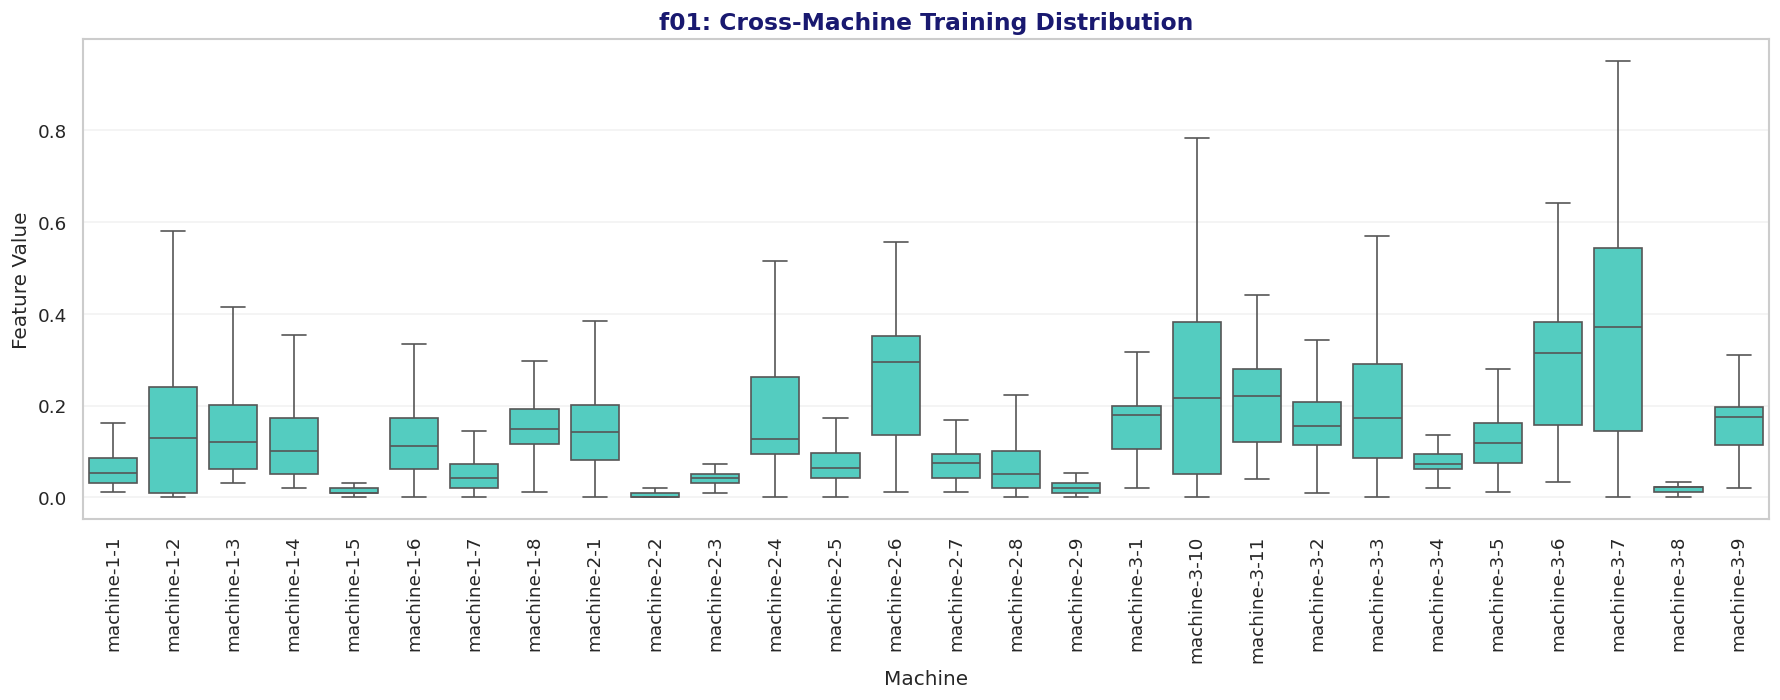


CORRELATION AND CROSS-MACHINE ANALYSIS COMPLETED
Machines analysed: 28
Feature compared: f01
Correlation records: 13191

Correlation heatmaps: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/plots/correlations
Correlation CSV: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/metrics/feature_correlations.csv
Cross-machine plot: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/plots/cross_machine_f01.png


In [ ]:

# --------------------------------------------------
# 1. Create output directory
# --------------------------------------------------

corr_dir = PLOTS_PATH / "correlations"
corr_dir.mkdir(parents=True, exist_ok=True)

# Define feature names
FEATURE_NAMES = [f"f{i:02d}" for i in range(1, 39)]

# Store correlation results
correlations = []


# --------------------------------------------------
# 2. Feature correlation analysis for each machine
# --------------------------------------------------

for machine in train_machines:

    # Load training data
    train_array, _, _ = load_machine(
        machine_id=machine,
        dataset_path=DATASET_PATH
    )

    # Convert NumPy array to DataFrame
    train = pd.DataFrame(
        train_array,
        columns=FEATURE_NAMES
    )

    # Remove constant features
    active = train.loc[
        :,
        train.nunique(dropna=True) > 1
    ]

    # Calculate Spearman correlation
    corr = active.corr(method="spearman")

    # ----------------------------------------------
    # Generate correlation heatmap
    # ----------------------------------------------

    fig, ax = plt.subplots(figsize=(12, 10))

    sns.heatmap(
        corr,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        ax=ax,
        xticklabels=3,
        yticklabels=3,
        square=False
    )

    ax.set_title(
        f"{machine}: Spearman Correlation (Training Data)",
        fontsize=13
    )

    fig.tight_layout()

    fig.savefig(
        corr_dir / f"{machine}.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.close(fig)

    # ----------------------------------------------
    # Store feature-pair correlations
    # ----------------------------------------------

    for i, feature_a in enumerate(corr.columns):

        for feature_b in corr.columns[i + 1:]:

            correlations.append({
                "machine": machine,
                "feature_a": feature_a,
                "feature_b": feature_b,
                "spearman_r": corr.loc[feature_a, feature_b]
            })


# --------------------------------------------------
# 3. Save correlation results
# --------------------------------------------------

correlation_df = pd.DataFrame(
    correlations,
    columns=[
        "machine",
        "feature_a",
        "feature_b",
        "spearman_r"
    ]
)

correlation_df.to_csv(
    METRICS_PATH / "feature_correlations.csv",
    index=False
)

print("Correlation analysis completed.")
print(f"Machines analysed: {len(train_machines)}")
print(f"Correlation records: {len(correlation_df)}")
print(f"Heatmaps saved in: {corr_dir}")


# --------------------------------------------------
# 4. Cross-machine feature comparison
# --------------------------------------------------

feature = "f01"

comparison = []

for machine in train_machines:

    # Load training data
    train_array, _, _ = load_machine(
        machine_id=machine,
        dataset_path=DATASET_PATH
    )

    # Convert to DataFrame
    train = pd.DataFrame(
        train_array,
        columns=FEATURE_NAMES
    )

    # Sample observations
    sample_size = min(2000, len(train))

    sampled_values = train[feature].sample(
        n=sample_size,
        random_state=42
    )

    comparison.append(
        pd.DataFrame({
            "machine": machine,
            "value": sampled_values.values
        })
    )


# --------------------------------------------------
# 5. Generate cross-machine boxplot
# --------------------------------------------------

comparison_df = pd.concat(
    comparison,
    ignore_index=True
)

fig, ax = plt.subplots(figsize=(15, 6))

sns.boxplot(
    data=comparison_df,
    x="machine",
    y="value",
    color=MASTER_PALETTE["turquoise"],
    showfliers=False,
    ax=ax
)

ax.tick_params(
    axis="x",
    rotation=90
)

ax.set_title(
    f"{feature}: Cross-Machine Training Distribution",
    fontsize=14
)

ax.set_xlabel("Machine")
ax.set_ylabel("Feature Value")

ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

fig.savefig(
    PLOTS_PATH / f"cross_machine_{feature}.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# --------------------------------------------------
# 6. Completion summary
# --------------------------------------------------

print("\n" + "=" * 55)
print("CORRELATION AND CROSS-MACHINE ANALYSIS COMPLETED")
print("=" * 55)

print(f"Machines analysed: {len(train_machines)}")
print(f"Feature compared: {feature}")
print(f"Correlation records: {len(correlation_df)}")

print(f"\nCorrelation heatmaps: {corr_dir}")
print(f"Correlation CSV: {METRICS_PATH / 'feature_correlations.csv'}")
print(f"Cross-machine plot: {PLOTS_PATH / f'cross_machine_{feature}.png'}")


### 2.3 — Temporal Pattern Exploration

**SMD Phase 2 EDA** · Run cells in order. All results are calculated from files; no observation counts are hard-coded.

**Paths:** `data/raw/OmniAnomaly/ServerMachineDataset/` → `results/metrics/`, `results/plots/`. Test labels are for descriptive EDA only, not model fitting.

#### Rolling behavior, sudden changes and trend

Analyze each metric on training data in **observation index**, not unverified clock time. ACF indicates lag dependence, not necessarily periodicity.

In [ ]:

from scipy.stats import linregress

# --------------------------------------------------
# 1. Define feature names
# --------------------------------------------------

FEATURE_NAMES = [f"f{i:02d}" for i in range(1, 39)]

# Store temporal statistics and autocorrelation results
records = []
acf_rows = []

# Autocorrelation lags
LAGS = [1, 5, 10, 30, 60, 120]


# --------------------------------------------------
# 2. Analyse every machine and feature
# --------------------------------------------------

for machine in train_machines:

    # Load training data
    train_array, _, _ = load_machine(
        machine_id=machine,
        dataset_path=DATASET_PATH
    )

    # Convert NumPy array into DataFrame
    train = pd.DataFrame(
        train_array,
        columns=FEATURE_NAMES
    )

    print(f"Analysing {machine}...")

    for feature in train.columns:

        # Extract feature values
        x = train[feature].astype(float)

        # Handle missing values, if present
        x = x.interpolate(limit_direction="both").to_numpy()

        # Skip features containing invalid values
        if not np.isfinite(x).all():
            continue

        n = len(x)

        if n < 2:
            continue

        # ------------------------------------------
        # A. Temporal statistics
        # ------------------------------------------

        # Absolute change between consecutive observations
        differences = np.abs(np.diff(x))

        # Overall trend
        if np.std(x) > 0:
            slope = linregress(
                np.arange(n),
                x
            ).slope
        else:
            slope = 0.0

        # Mean absolute change
        mean_change = differences.mean()

        # 99th percentile of absolute changes
        p99_change = np.quantile(
            differences,
            0.99
        )

        # Rolling 30-observation mean
        rolling_mean = pd.Series(x).rolling(
            window=30,
            min_periods=30
        ).mean()

        # Range of rolling means
        rolling_range = (
            rolling_mean.max() - rolling_mean.min()
        )

        # Store temporal statistics
        records.append({
            "machine": machine,
            "feature": feature,
            "trend_slope": slope,
            "mean_absolute_change": mean_change,
            "p99_absolute_change": p99_change,
            "rolling30_mean_range": rolling_range
        })

        # ------------------------------------------
        # B. Autocorrelation analysis
        # ------------------------------------------

        # Centre the observations around their mean
        centered = x - x.mean()

        # Denominator for autocorrelation
        denominator = np.dot(
            centered,
            centered
        )

        for lag in LAGS:

            if denominator > 0 and lag < n:

                acf_value = (
                    np.dot(
                        centered[:-lag],
                        centered[lag:]
                    ) / denominator
                )

            else:
                acf_value = np.nan

            # Store autocorrelation results
            acf_rows.append({
                "machine": machine,
                "feature": feature,
                "lag": lag,
                "acf": acf_value
            })


# --------------------------------------------------
# 3. Convert results into DataFrames
# --------------------------------------------------

temporal_df = pd.DataFrame(records)

autocorrelation_df = pd.DataFrame(acf_rows)


# --------------------------------------------------
# 4. Save results as CSV files
# --------------------------------------------------

temporal_path = METRICS_PATH / "temporal_statistics.csv"

acf_path = METRICS_PATH / "autocorrelation.csv"

temporal_df.to_csv(
    temporal_path,
    index=False
)

autocorrelation_df.to_csv(
    acf_path,
    index=False
)


# --------------------------------------------------
# 5. Display results
# --------------------------------------------------

print("\n" + "=" * 60)
print("TEMPORAL AND AUTOCORRELATION ANALYSIS COMPLETED")
print("=" * 60)

print(f"Machines analysed: {len(train_machines)}")
print(f"Temporal records: {len(temporal_df)}")
print(f"Autocorrelation records: {len(autocorrelation_df)}")

print(f"\nTemporal statistics saved: {temporal_path}")
print(f"Autocorrelation saved: {acf_path}")

print("\nTemporal statistics preview:")

display(temporal_df.head(10))

print("\nAutocorrelation preview:")

display(autocorrelation_df.head(10))


Analysing machine-1-1...
Analysing machine-1-2...
Analysing machine-1-3...
Analysing machine-1-4...
Analysing machine-1-5...
Analysing machine-1-6...
Analysing machine-1-7...
Analysing machine-1-8...
Analysing machine-2-1...
Analysing machine-2-2...
Analysing machine-2-3...
Analysing machine-2-4...
Analysing machine-2-5...
Analysing machine-2-6...
Analysing machine-2-7...
Analysing machine-2-8...
Analysing machine-2-9...
Analysing machine-3-1...
Analysing machine-3-10...
Analysing machine-3-11...
Analysing machine-3-2...
Analysing machine-3-3...
Analysing machine-3-4...
Analysing machine-3-5...
Analysing machine-3-6...
Analysing machine-3-7...
Analysing machine-3-8...
Analysing machine-3-9...

TEMPORAL AND AUTOCORRELATION ANALYSIS COMPLETED
Machines analysed: 28
Temporal records: 1064
Autocorrelation records: 6384

Temporal statistics saved: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/metrics/temporal_statistics.csv
Autocorrelation saved: /content/drive/MyDrive/SMD_Anoma

,machine,feature,trend_slope,mean_absolute_change,p99_absolute_change,rolling30_mean_range
0,machine-1-1,f01,1.891217e-06,0.004325,0.021505,0.459498
1,machine-1-1,f02,2.448830e-06,0.020500,0.092161,0.229025
2,machine-1-1,f03,2.584350e-06,0.005352,0.024526,0.234671
3,machine-1-1,f04,2.690548e-06,0.001882,0.009291,0.235850
4,machine-1-1,f05,0.000000e+00,0.000000,0.000000,0.000000
5,machine-1-1,f06,3.088056e-07,0.002422,0.020513,0.711368
6,machine-1-1,f07,-3.054778e-07,0.000882,0.003767,0.334746
7,machine-1-1,f08,0.000000e+00,0.000000,0.000000,0.000000
8,machine-1-1,f09,1.630807e-07,0.002813,0.014760,0.046925
9,machine-1-1,f10,8.273994e-10,0.000223,0.002467,0.004783



Autocorrelation preview:


,machine,feature,lag,acf
0,machine-1-1,f01,1,0.973271
1,machine-1-1,f01,5,0.946407
2,machine-1-1,f01,10,0.929401
3,machine-1-1,f01,30,0.882286
4,machine-1-1,f01,60,0.792937
5,machine-1-1,f01,120,0.618574
6,machine-1-1,f02,1,0.771930
7,machine-1-1,f02,5,0.617083
8,machine-1-1,f02,10,0.619097
9,machine-1-1,f02,30,0.602716


#### Representative temporal visualization

Choose the highest-variance nonconstant training feature for each representative machine. This is not assumed to be CPU.


PROCESSING: machine-1-6


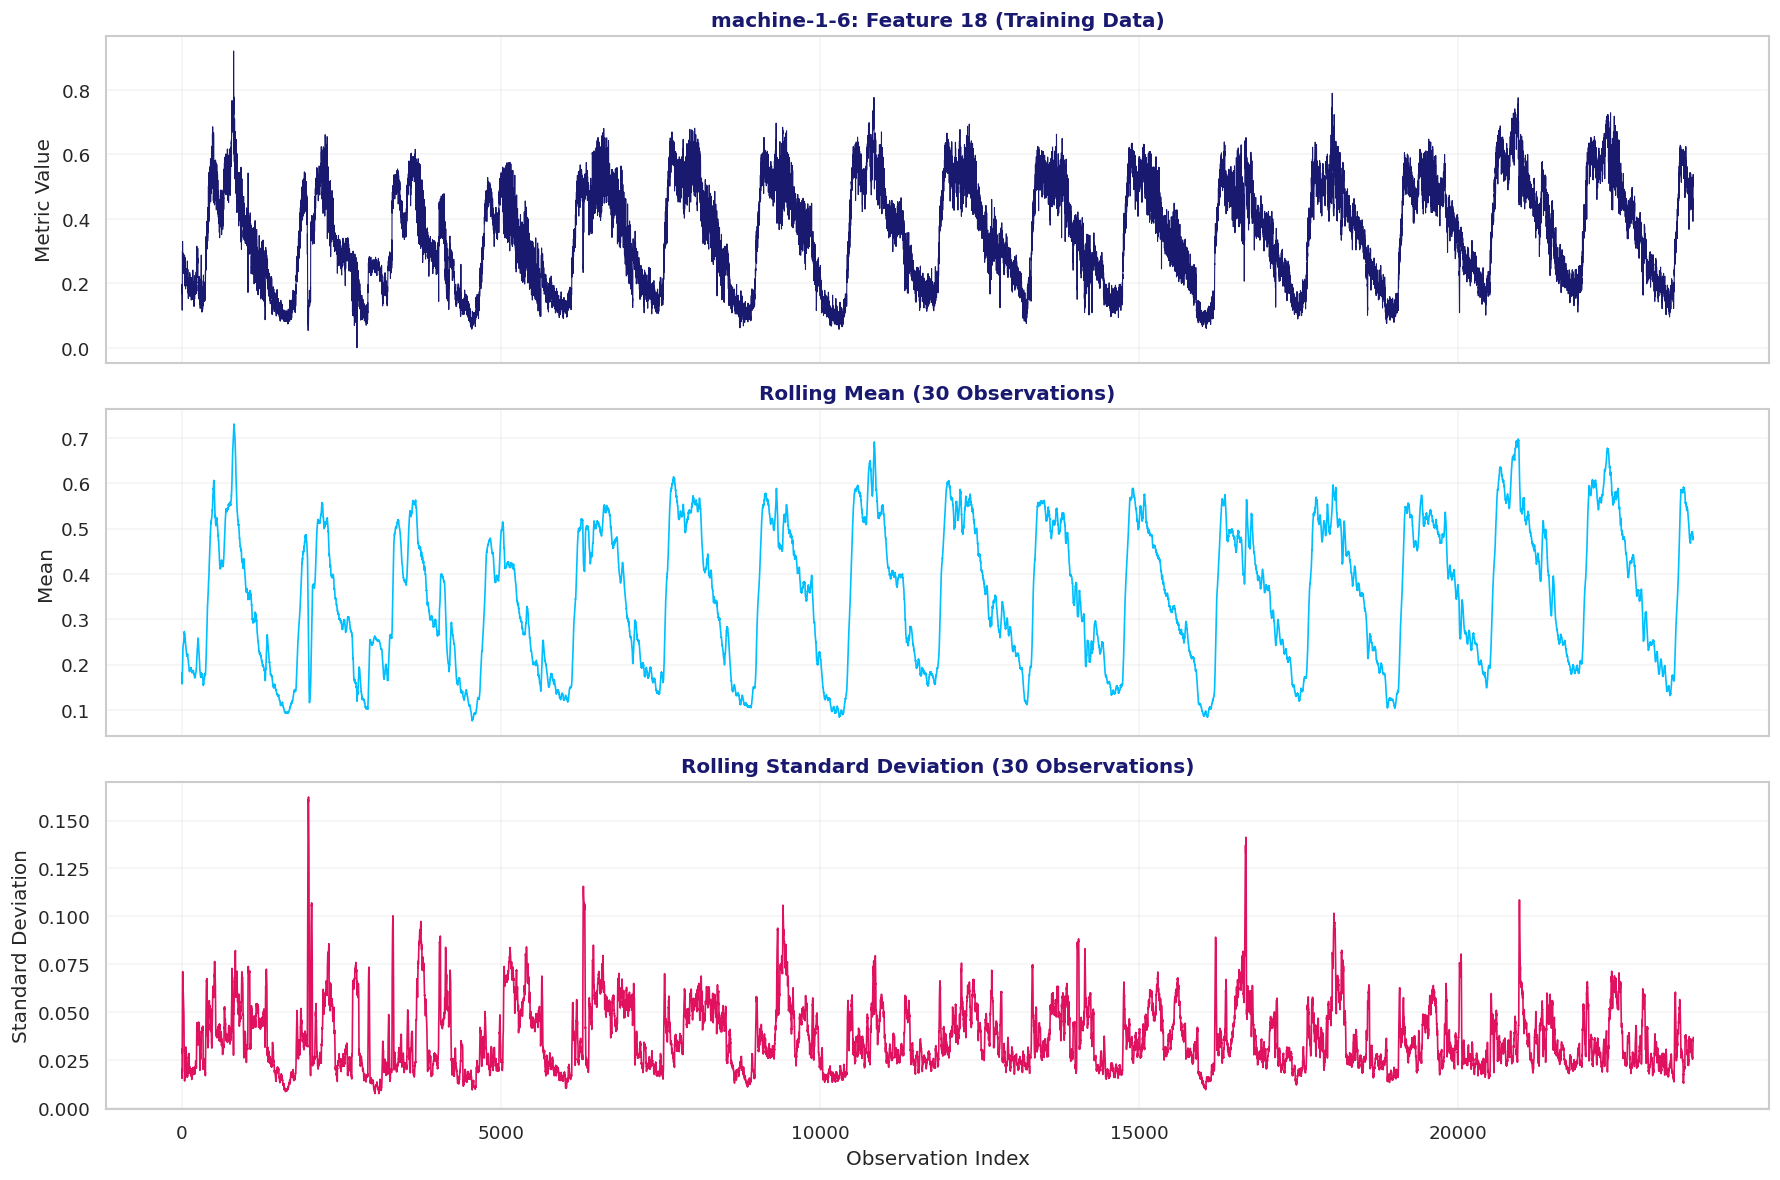

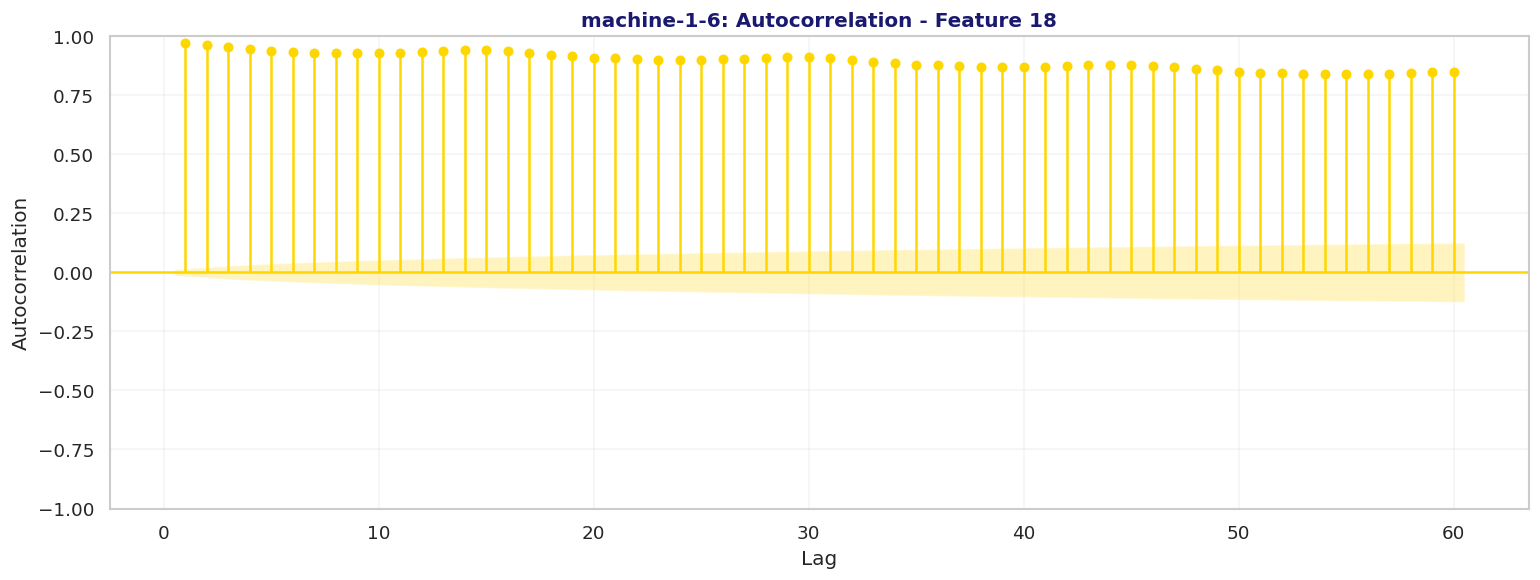

Selected feature: 18
Observations: 23,688
Missing values: 0
Missing percentage: 0.00%
Standard deviation: 0.1604
Temporal plot: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/plots/machine-1-6_temporal.png
ACF plot: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/plots/machine-1-6_acf.png

PROCESSING: machine-2-2


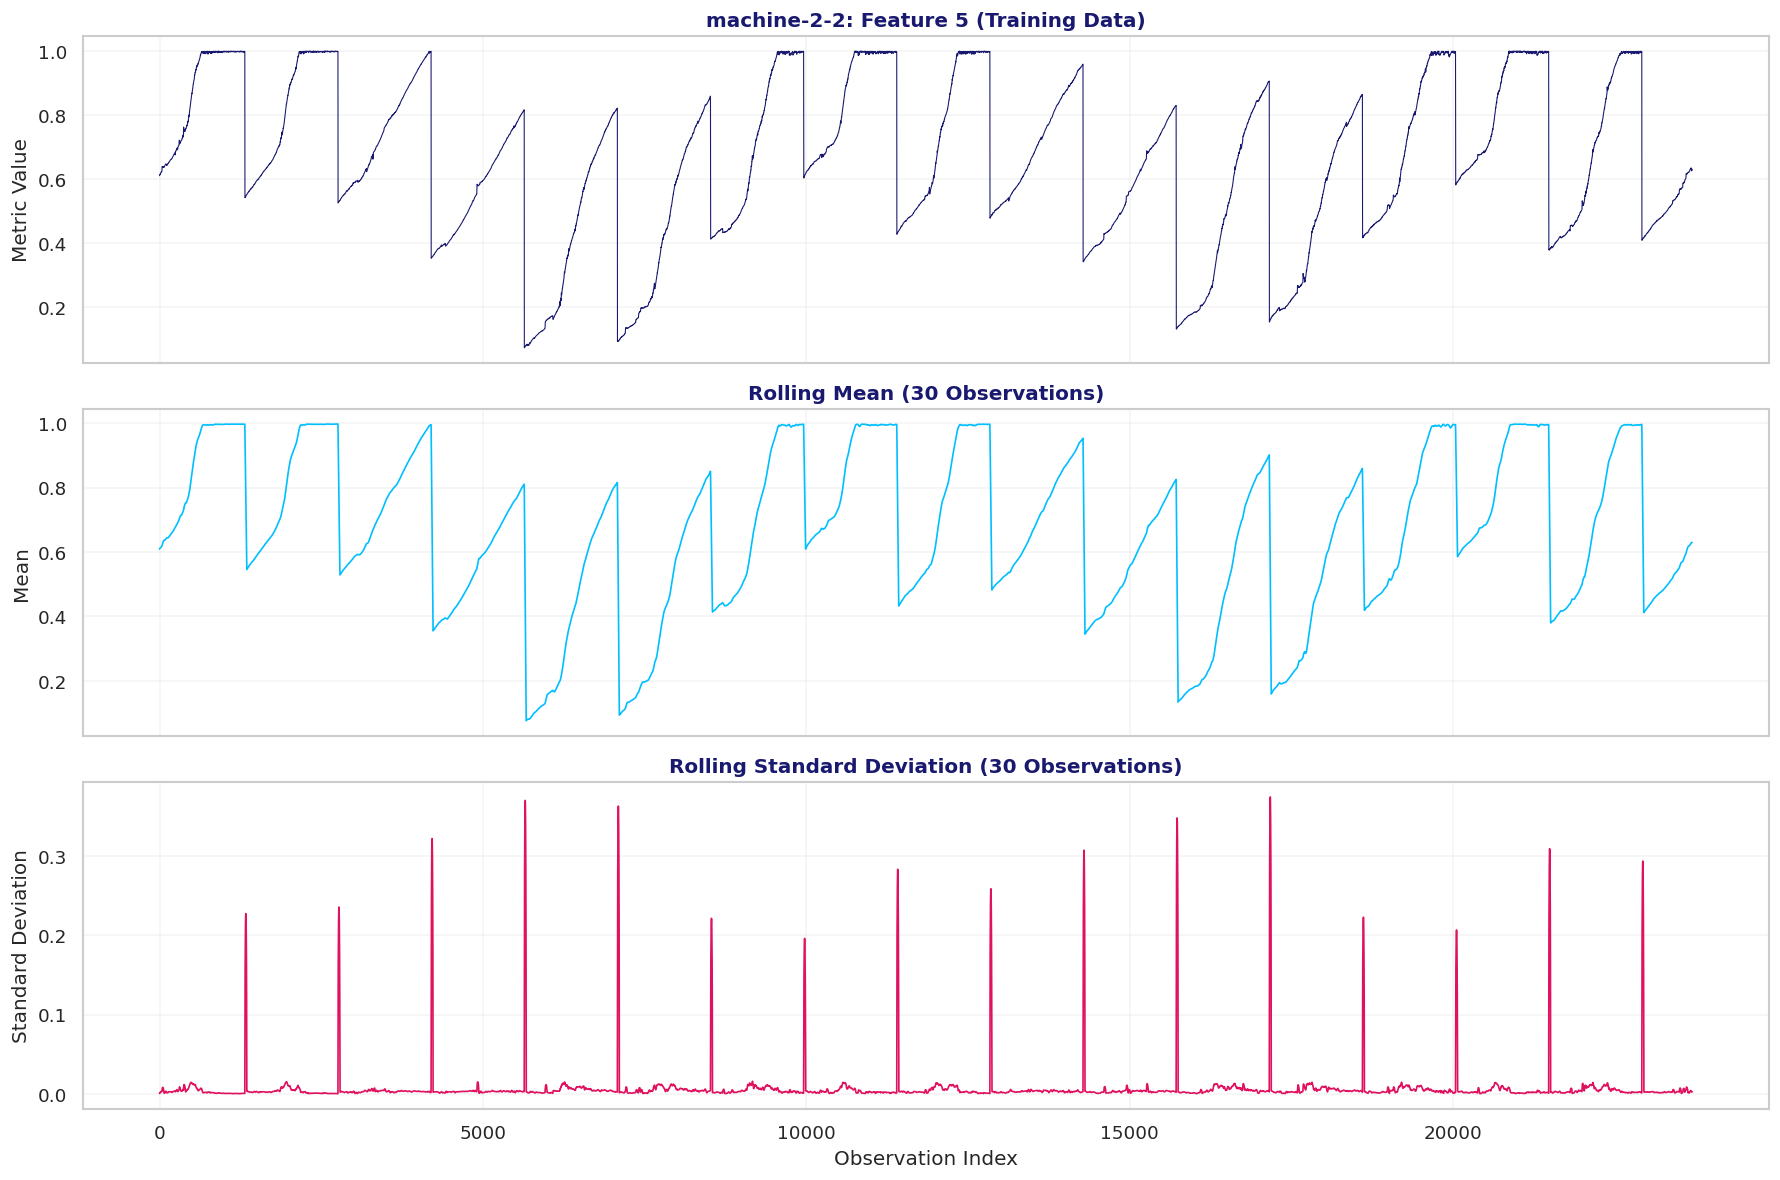

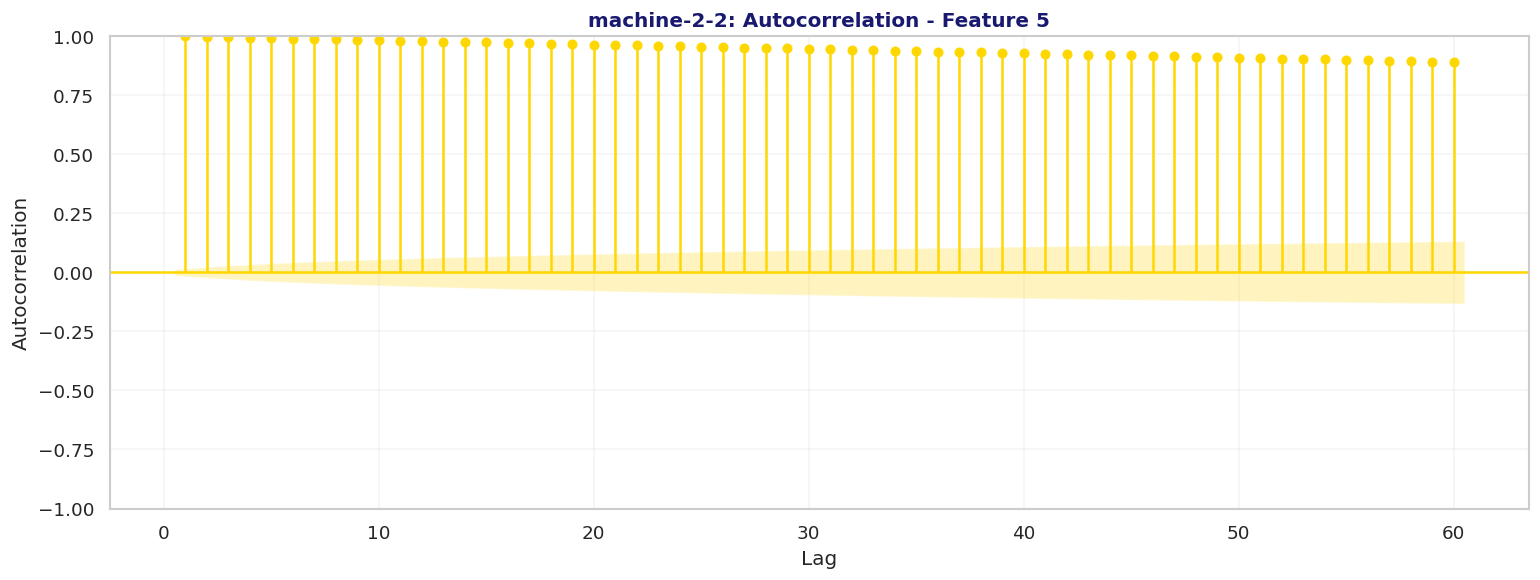

Selected feature: 5
Observations: 23,699
Missing values: 0
Missing percentage: 0.00%
Standard deviation: 0.2524
Temporal plot: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/plots/machine-2-2_temporal.png
ACF plot: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/plots/machine-2-2_acf.png

PROCESSING: machine-3-8


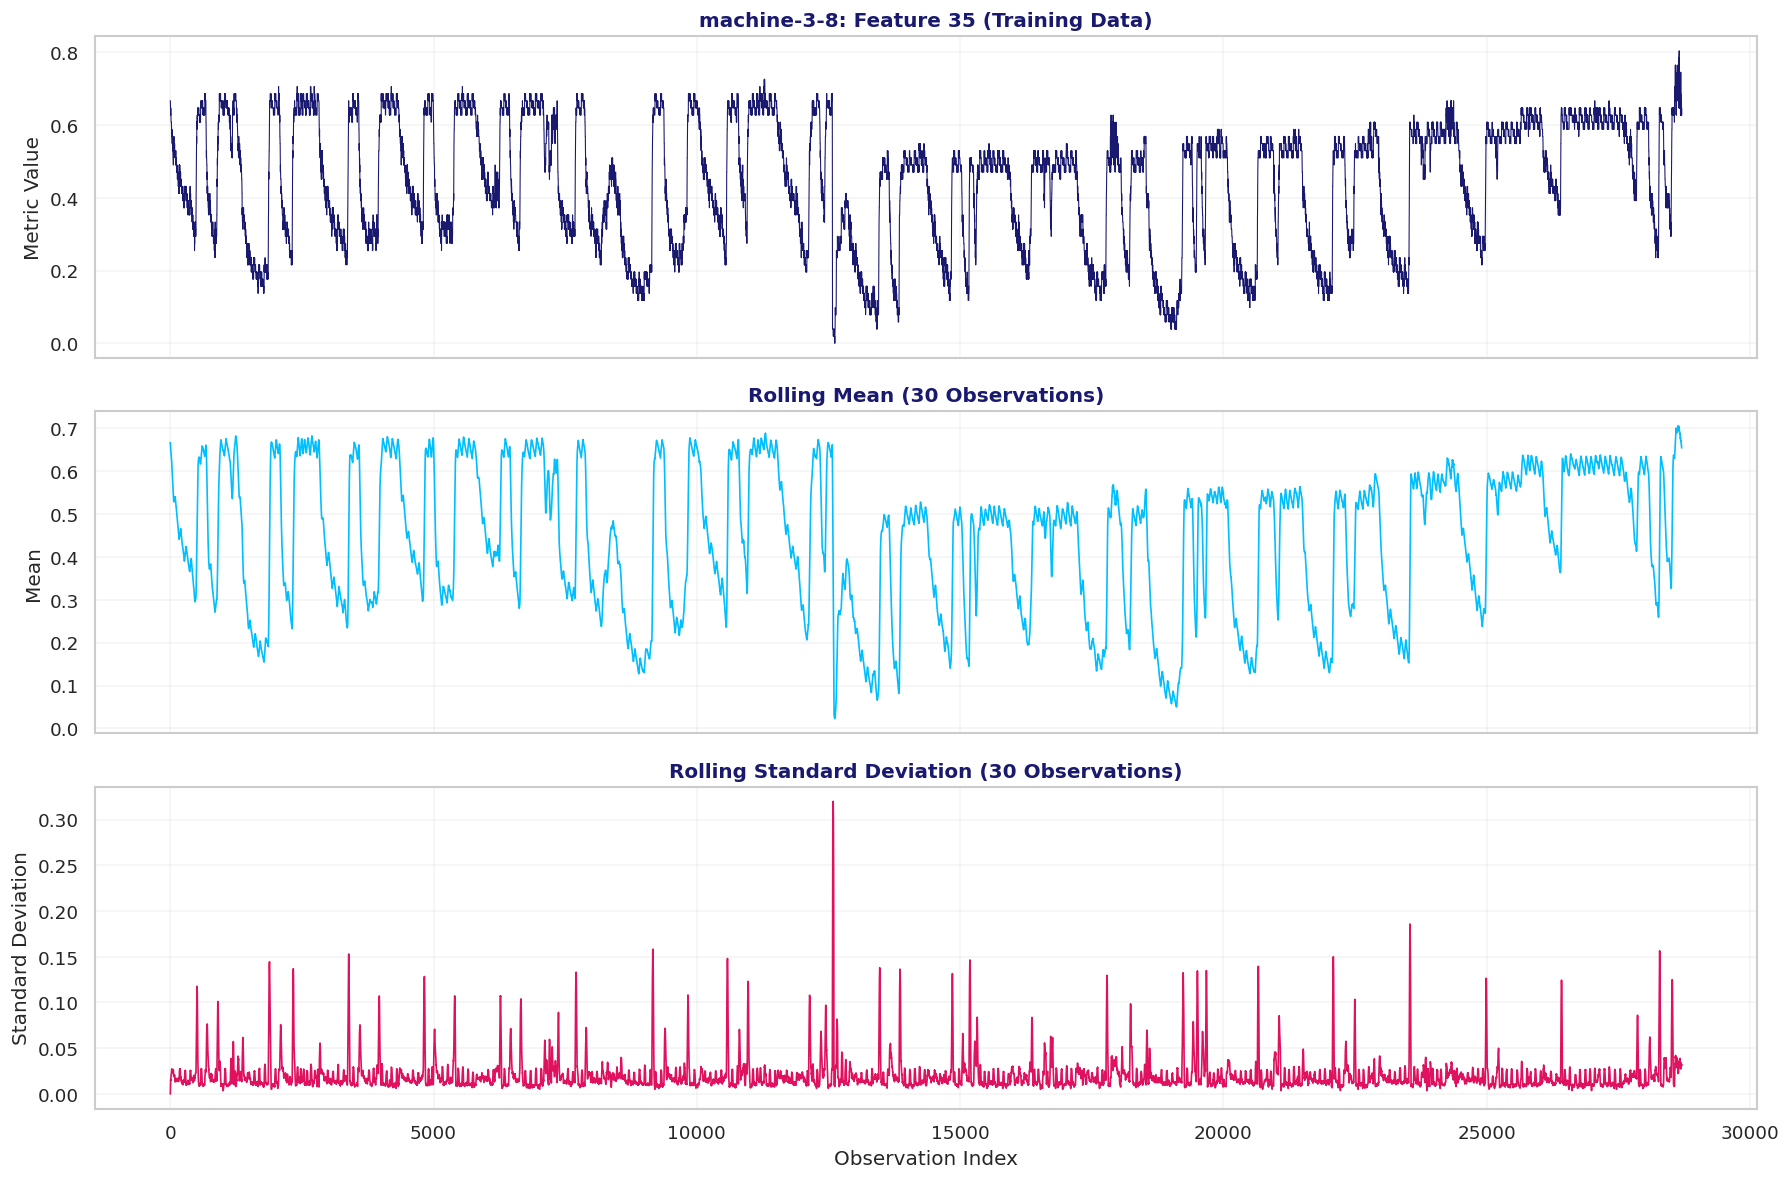

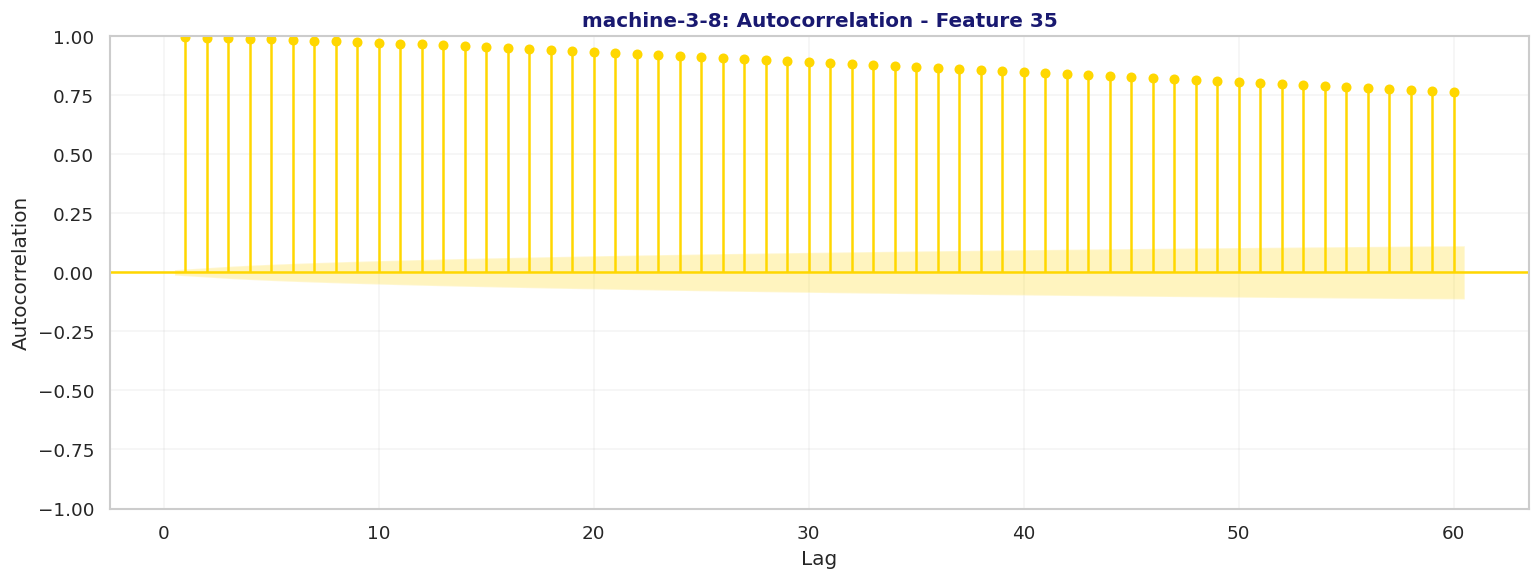

Selected feature: 35
Observations: 28,703
Missing values: 0
Missing percentage: 0.00%
Standard deviation: 0.1679
Temporal plot: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/plots/machine-3-8_temporal.png
ACF plot: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/plots/machine-3-8_acf.png

PROCESSING: machine-3-9


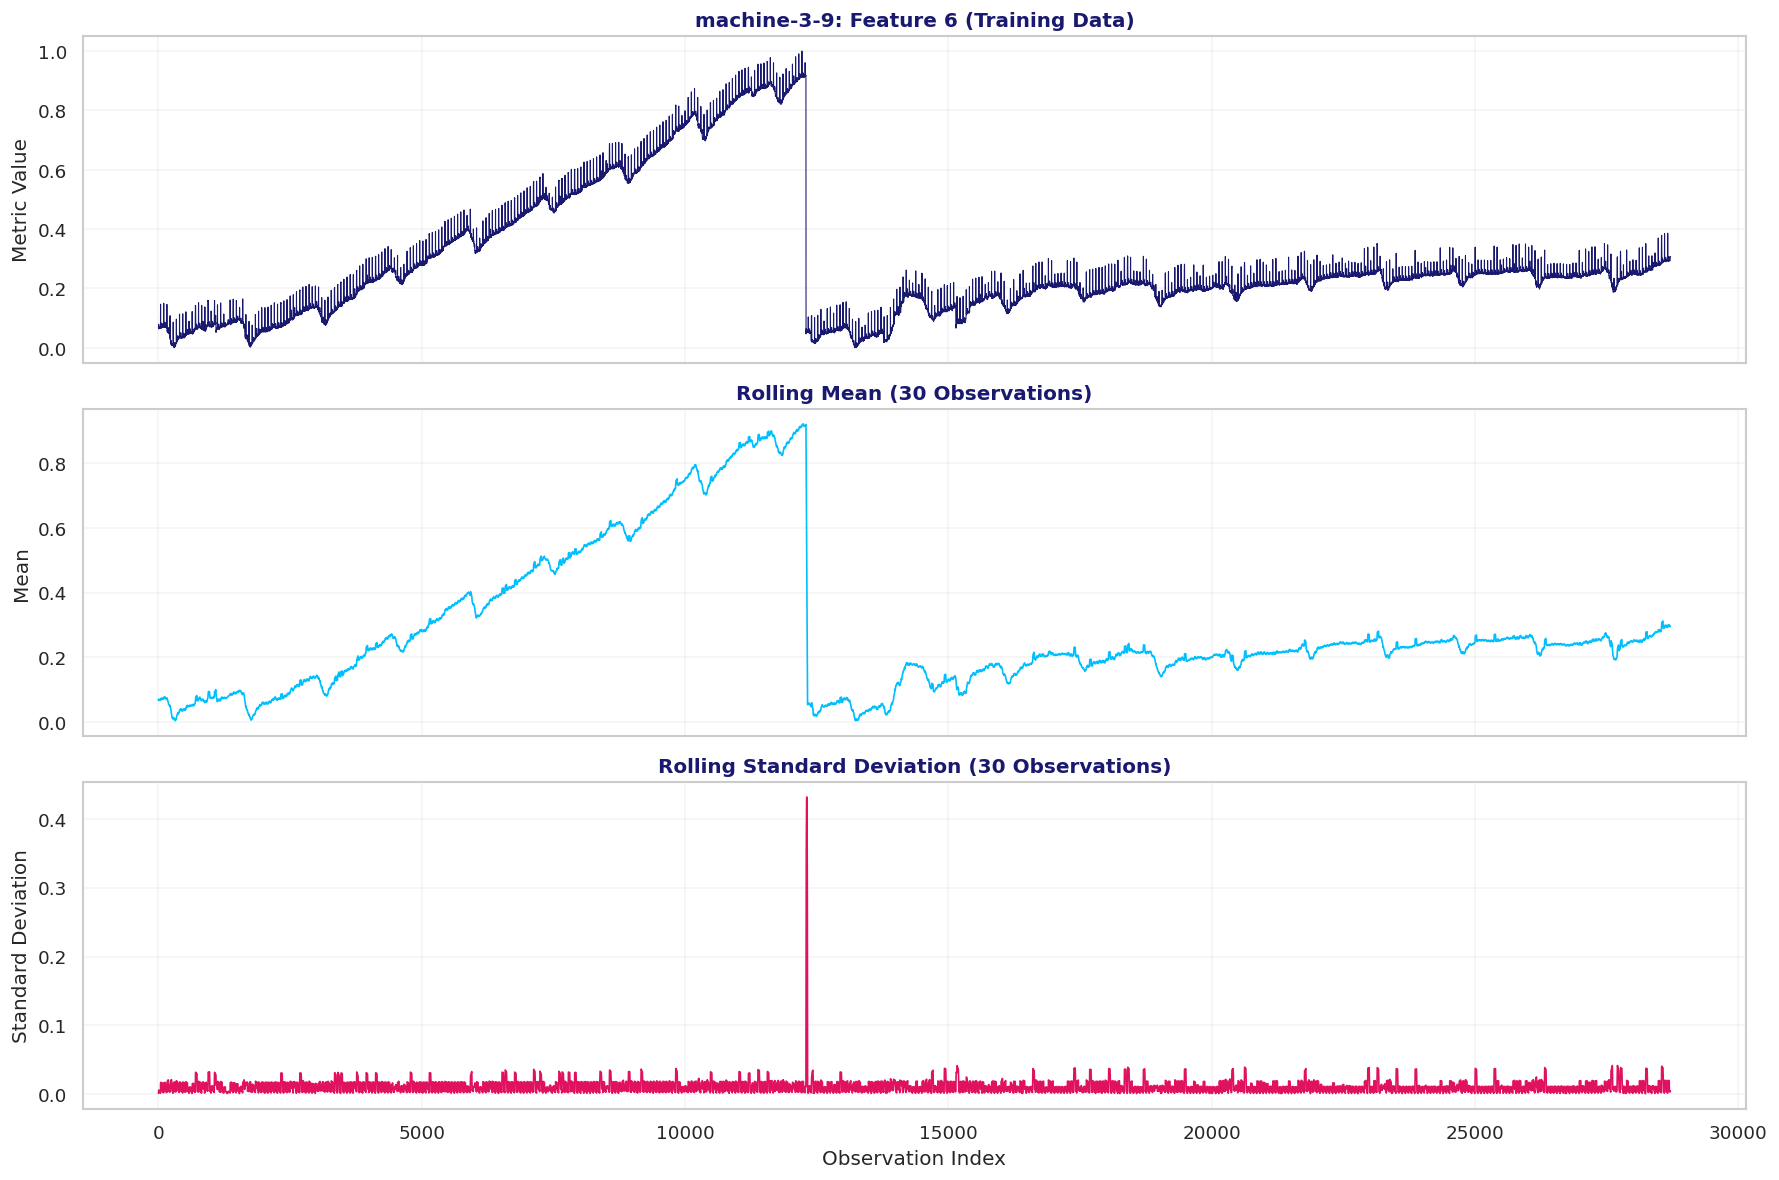

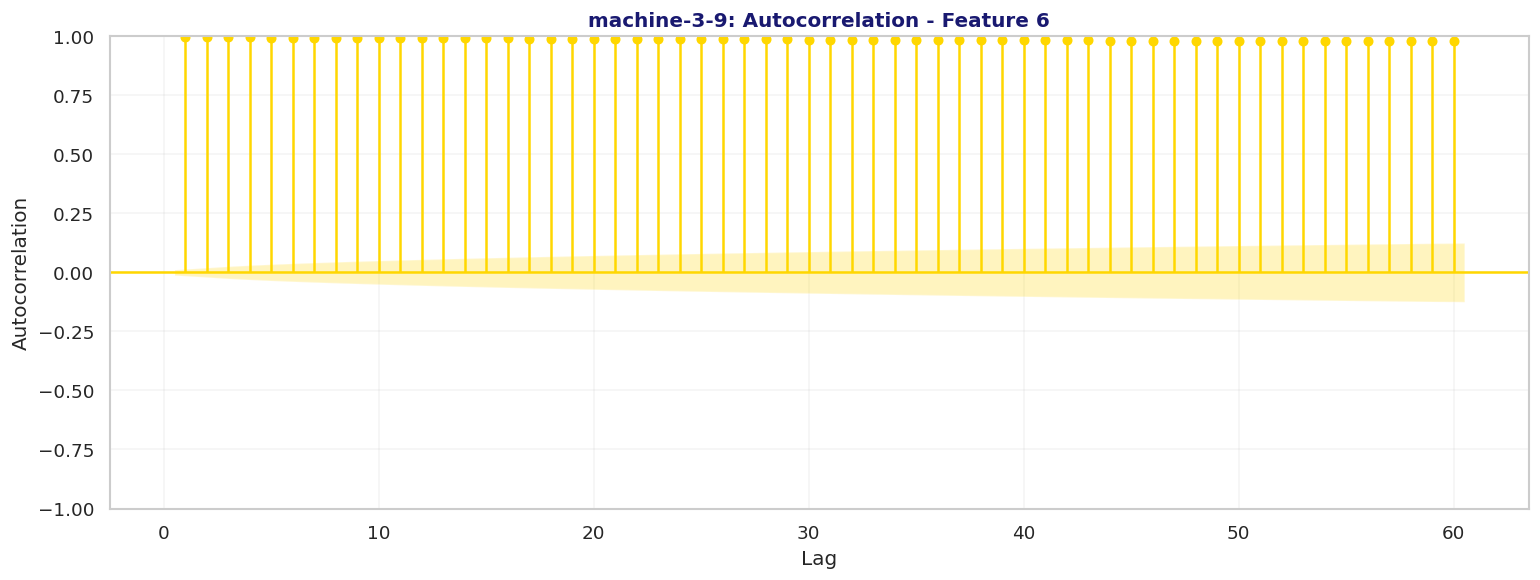

Selected feature: 6
Observations: 28,713
Missing values: 0
Missing percentage: 0.00%
Standard deviation: 0.2173
Temporal plot: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/plots/machine-3-9_temporal.png
ACF plot: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/plots/machine-3-9_acf.png

PROCESSING: machine-1-5


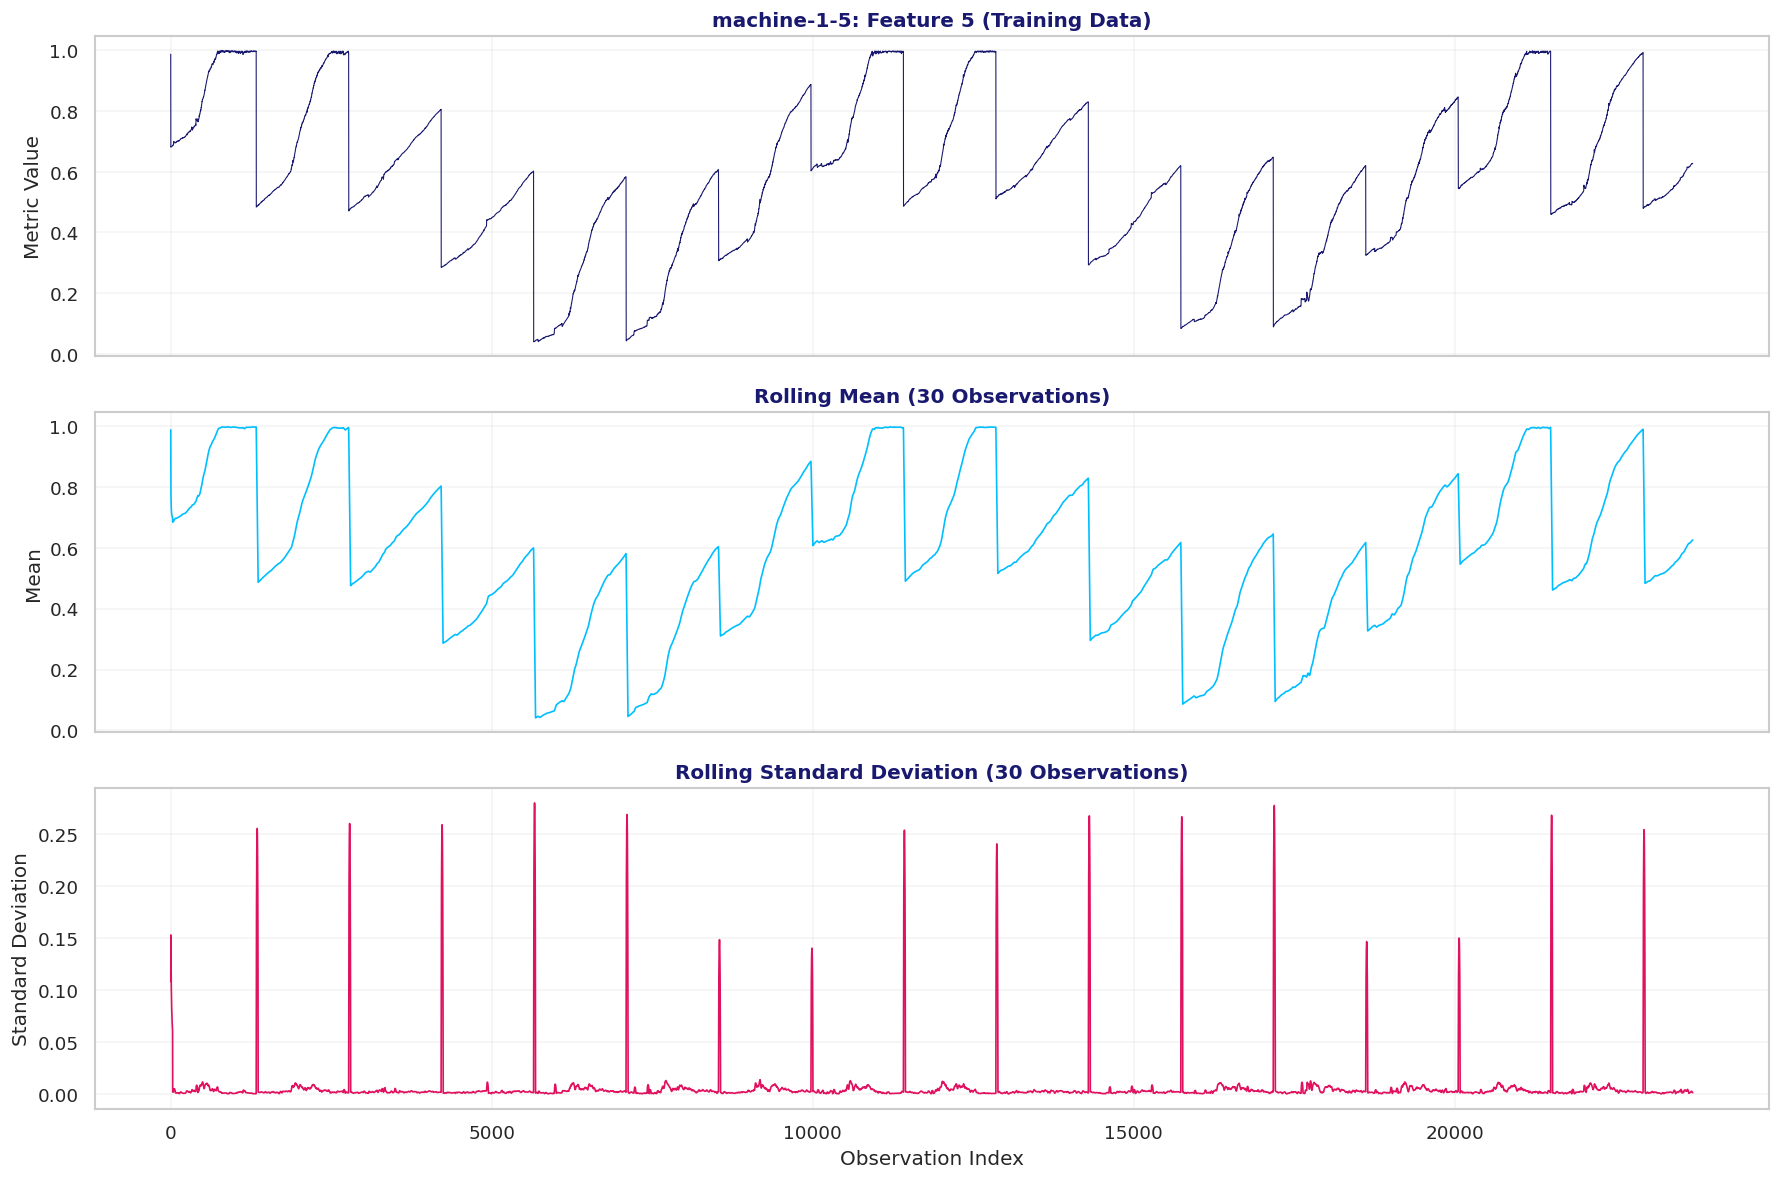

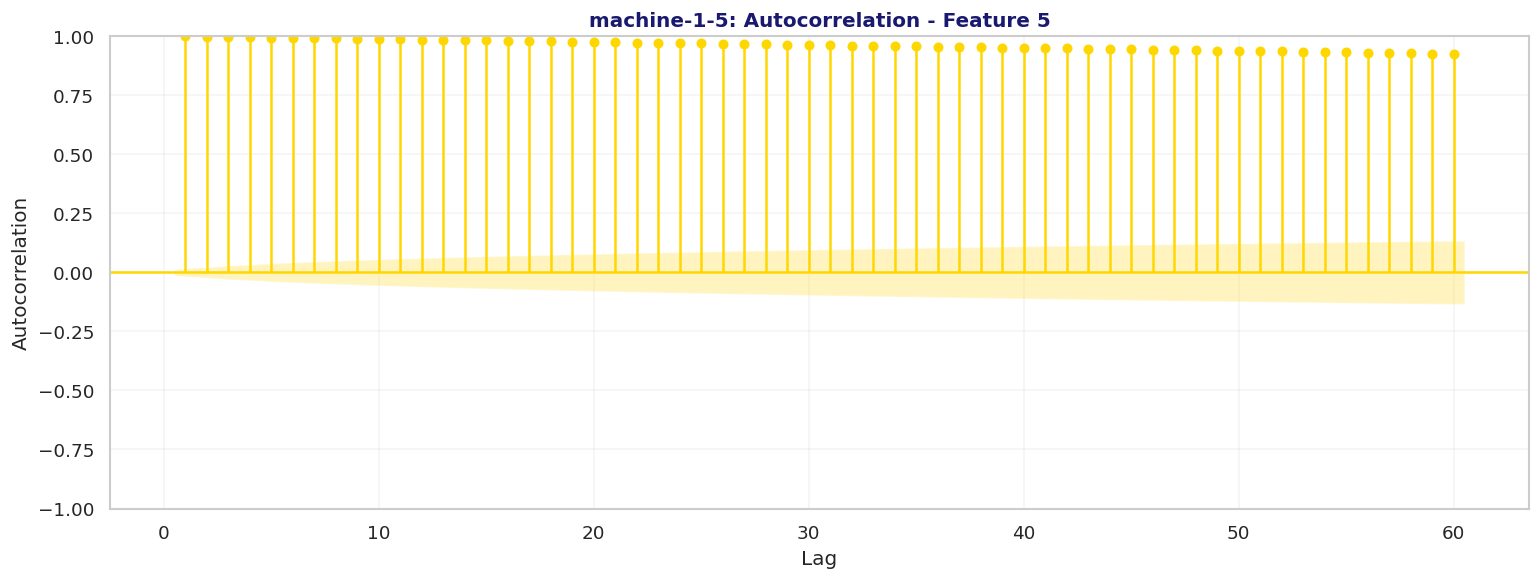

Selected feature: 5
Observations: 23,705
Missing values: 0
Missing percentage: 0.00%
Standard deviation: 0.2525
Temporal plot: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/plots/machine-1-5_temporal.png
ACF plot: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/plots/machine-1-5_acf.png

TEMPORAL ANALYSIS SUMMARY


,Machine,Selected Feature,Feature Standard Deviation,Mean,Overall Standard Deviation,Minimum,Maximum,Rolling Mean Range,Maximum Rolling Std,Observations,Missing Count,Missing Percentage,Plot,ACF Plot
0,machine-1-6,18,0.1604,0.3528,0.1604,0.0000,0.9202,0.6548,0.1623,23688,0,0.0,machine-1-6_temporal.png,machine-1-6_acf.png
1,machine-2-2,5,0.2524,0.6621,0.2524,0.0719,0.9990,0.9218,0.3741,23699,0,0.0,machine-2-2_temporal.png,machine-2-2_acf.png
2,machine-3-8,35,0.1679,0.4438,0.1679,0.0000,0.8039,0.6824,0.3199,28703,0,0.0,machine-3-8_temporal.png,machine-3-8_acf.png
3,machine-3-9,6,0.2173,0.2863,0.2173,0.0000,1.0000,0.9170,0.4315,28713,0,0.0,machine-3-9_temporal.png,machine-3-9_acf.png
4,machine-1-5,5,0.2525,0.5756,0.2525,0.0400,0.9986,0.9557,0.2801,23705,0,0.0,machine-1-5_temporal.png,machine-1-5_acf.png



AUTOCORRELATION SUMMARY


,Machine,Feature,ACF Lag 1,ACF Lag 5,ACF Lag 10,ACF Lag 30,ACF Lag 60
0,machine-1-6,18,0.9716,0.9391,0.9285,0.9142,0.8490
1,machine-2-2,5,0.9991,0.9918,0.9828,0.9462,0.8906
2,machine-3-8,35,0.9963,0.9877,0.9727,0.8926,0.7667
3,machine-3-9,6,0.9987,0.9945,0.9926,0.9865,0.9806
4,machine-1-5,5,0.9994,0.9944,0.9882,0.9633,0.9255



EDA COMPLETED
Machines processed: 5
Output directory: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/plots

Generated files:
 - anomaly_duration_position.png
 - autocorrelation_summary.csv
 - boxplots
 - correlations
 - cross_machine_f01.png
 - histograms
 - machine-1-5_acf.png
 - machine-1-5_temporal.png
 - machine-1-6_acf.png
 - machine-1-6_temporal.png
 - machine-2-2_acf.png
 - machine-2-2_temporal.png
 - machine-3-8_acf.png
 - machine-3-8_temporal.png
 - machine-3-9_acf.png
 - machine-3-9_temporal.png
 - temporal_summary.csv
 - window_anomaly_point_coverage.png
 - window_coverage.png


In [ ]:
# ============================================================
# TEMPORAL EDA: REPRESENTATIVE SMD MACHINES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from statsmodels.graphics.tsaplots import plot_acf


# ============================================================
# 1. CONFIGURATION
# ============================================================

representatives = [
    'machine-1-6',
    'machine-2-2',
    'machine-3-8',
    'machine-3-9',
    'machine-1-5'
]

WINDOW_SIZE = 30
MAX_LAGS = 60

# Create output directory
PLOTS_PATH = Path(PLOTS_PATH)
PLOTS_PATH.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. INITIALISE RESULTS
# ============================================================

temporal_results = []
acf_results = []


# ============================================================
# 3. TEMPORAL ANALYSIS
# ============================================================

for machine in representatives:

    print("\n" + "=" * 65)
    print(f"PROCESSING: {machine}")
    print("=" * 65)

    # --------------------------------------------------------
    # 3.1 Load training data
    # --------------------------------------------------------

    train, _, _ = load_machine(machine, DATASET_PATH)

    # Convert NumPy array into DataFrame
    train = pd.DataFrame(train)

    # Check whether training data is empty
    if train.empty:
        print(f"Skipping {machine}: Empty training dataset.")
        continue

    # Convert columns to numeric
    train = train.apply(pd.to_numeric, errors='coerce')

    # --------------------------------------------------------
    # 3.2 Identify feature with highest variability
    # --------------------------------------------------------

    feature_std = train.std().dropna()

    if feature_std.empty:
        print(f"Skipping {machine}: No valid numerical features.")
        continue

    feature = feature_std.idxmax()

    x_original = train[feature].astype(float)

    # --------------------------------------------------------
    # 3.3 Missing-value assessment
    # --------------------------------------------------------

    missing_count = int(x_original.isna().sum())

    missing_percentage = (
        missing_count / len(x_original) * 100
    )

    # Interpolate missing observations
    x = x_original.interpolate(
        method='linear',
        limit_direction='both'
    )

    # Check remaining invalid values
    if not np.isfinite(x.to_numpy()).all():
        print(f"Skipping {machine}: Non-finite values remain.")
        continue

    # --------------------------------------------------------
    # 3.4 Calculate temporal statistics
    # --------------------------------------------------------

    rolling_mean = x.rolling(
        window=WINDOW_SIZE,
        min_periods=1
    ).mean()

    rolling_std = x.rolling(
        window=WINDOW_SIZE,
        min_periods=2
    ).std()

    # --------------------------------------------------------
    # 3.5 Generate temporal plots
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        3, 1,
        figsize=(15, 10),
        sharex=True
    )

    # Original time series
    axes[0].plot(
        x.to_numpy(),
        color=MASTER_PALETTE['navy'],
        linewidth=0.65
    )

    axes[0].set_title(
        f'{machine}: Feature {feature} (Training Data)',
        fontsize=12,
        fontweight='bold'
    )

    axes[0].set_ylabel('Metric Value')
    axes[0].grid(alpha=0.2)

    # Rolling mean
    axes[1].plot(
        rolling_mean.to_numpy(),
        color=MASTER_PALETTE['electric'],
        linewidth=1
    )

    axes[1].set_title(
        f'Rolling Mean ({WINDOW_SIZE} Observations)'
    )

    axes[1].set_ylabel('Mean')
    axes[1].grid(alpha=0.2)

    # Rolling standard deviation
    axes[2].plot(
        rolling_std.to_numpy(),
        color=MASTER_PALETTE['ruby'],
        linewidth=1
    )

    axes[2].set_title(
        f'Rolling Standard Deviation ({WINDOW_SIZE} Observations)'
    )

    axes[2].set_ylabel('Standard Deviation')
    axes[2].set_xlabel('Observation Index')
    axes[2].grid(alpha=0.2)

    fig.tight_layout()

    # Save temporal plot
    temporal_file = (
        PLOTS_PATH / f'{machine}_temporal.png'
    )

    fig.savefig(
        temporal_file,
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()
    plt.close(fig)

    # --------------------------------------------------------
    # 3.6 Autocorrelation analysis
    # --------------------------------------------------------

    effective_lags = min(
        MAX_LAGS,
        len(x) - 1
    )

    if effective_lags < 1:
        print(f"Skipping ACF for {machine}: Insufficient observations.")
        continue

    fig, ax = plt.subplots(figsize=(13, 5))

    plot_acf(
        x,
        lags=effective_lags,
        ax=ax,
        zero=False
    )

    ax.set_title(
        f'{machine}: Autocorrelation - Feature {feature}',
        fontsize=12,
        fontweight='bold'
    )

    ax.set_xlabel('Lag')
    ax.set_ylabel('Autocorrelation')
    ax.grid(alpha=0.2)

    fig.tight_layout()

    acf_file = PLOTS_PATH / f'{machine}_acf.png'

    fig.savefig(
        acf_file,
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()
    plt.close(fig)

    # --------------------------------------------------------
    # 3.7 Extract autocorrelation values
    # --------------------------------------------------------

    acf_values = [
        x.autocorr(lag=lag)
        for lag in range(1, effective_lags + 1)
    ]

    acf_results.append({

        'Machine': machine,
        'Feature': feature,

        'ACF Lag 1': acf_values[0] if len(acf_values) >= 1 else np.nan,

        'ACF Lag 5': acf_values[4] if len(acf_values) >= 5 else np.nan,

        'ACF Lag 10': acf_values[9] if len(acf_values) >= 10 else np.nan,

        'ACF Lag 30': acf_values[29] if len(acf_values) >= 30 else np.nan,

        'ACF Lag 60': acf_values[59] if len(acf_values) >= 60 else np.nan

    })

    # --------------------------------------------------------
    # 3.8 Store temporal summary
    # --------------------------------------------------------

    temporal_results.append({

        'Machine': machine,

        'Selected Feature': feature,

        'Feature Standard Deviation': feature_std[feature],

        'Mean': x.mean(),

        'Overall Standard Deviation': x.std(),

        'Minimum': x.min(),

        'Maximum': x.max(),

        'Rolling Mean Range': (
            rolling_mean.max() - rolling_mean.min()
        ),

        'Maximum Rolling Std': rolling_std.max(),

        'Observations': len(x),

        'Missing Count': missing_count,

        'Missing Percentage': missing_percentage,

        'Plot': temporal_file.name,

        'ACF Plot': acf_file.name

    })

    # Print machine results
    print(f"Selected feature: {feature}")
    print(f"Observations: {len(x):,}")
    print(f"Missing values: {missing_count}")
    print(f"Missing percentage: {missing_percentage:.2f}%")
    print(f"Standard deviation: {feature_std[feature]:.4f}")
    print(f"Temporal plot: {temporal_file}")
    print(f"ACF plot: {acf_file}")


# ============================================================
# 4. DISPLAY TEMPORAL SUMMARY
# ============================================================

temporal_summary = pd.DataFrame(temporal_results)

print("\n" + "=" * 65)
print("TEMPORAL ANALYSIS SUMMARY")
print("=" * 65)

display(temporal_summary.round(4))


# ============================================================
# 5. DISPLAY AUTOCORRELATION SUMMARY
# ============================================================

acf_summary = pd.DataFrame(acf_results)

print("\n" + "=" * 65)
print("AUTOCORRELATION SUMMARY")
print("=" * 65)

display(acf_summary.round(4))


# ============================================================
# 6. SAVE RESULTS
# ============================================================

temporal_summary.to_csv(
    PLOTS_PATH / 'temporal_summary.csv',
    index=False
)

acf_summary.to_csv(
    PLOTS_PATH / 'autocorrelation_summary.csv',
    index=False
)


# ============================================================
# 7. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 65)
print("EDA COMPLETED")
print("=" * 65)

print(f"Machines processed: {len(temporal_summary)}")

print(f"Output directory: {PLOTS_PATH}")

print("\nGenerated files:")

for file in sorted(PLOTS_PATH.glob('*')):
    print(f" - {file.name}")


### 2.4 — Anomaly Pattern Exploration

**SMD Phase 2 EDA** · Run cells in order. All results are calculated from files; no observation counts are hard-coded.

**Paths:** `data/raw/OmniAnomaly/ServerMachineDataset/` → `results/metrics/`, `results/plots/`. Test labels are for descriptive EDA only, not model fitting.

#### Anomaly runs, frequency and positional bias

Consecutive binary label runs are treated as anomaly segments. A run of length 1 is a point-labeled anomaly; longer runs are continuous-labeled anomalies. These labels alone cannot prove contextual anomaly type.

Processing: machine-1-1
  Anomaly segments: 8
  Anomaly points: 2694
Processing: machine-1-2
  Anomaly segments: 10
  Anomaly points: 542
Processing: machine-1-3
  Anomaly segments: 12
  Anomaly points: 817
Processing: machine-1-4
  Anomaly segments: 12
  Anomaly points: 720
Processing: machine-1-5
  Anomaly segments: 7
  Anomaly points: 100
Processing: machine-1-6
  Anomaly segments: 30
  Anomaly points: 3708
Processing: machine-1-7
  Anomaly segments: 13
  Anomaly points: 2398
Processing: machine-1-8
  Anomaly segments: 20
  Anomaly points: 763
Processing: machine-2-1
  Anomaly segments: 13
  Anomaly points: 1170
Processing: machine-2-2
  Anomaly segments: 11
  Anomaly points: 2833
Processing: machine-2-3
  Anomaly segments: 10
  Anomaly points: 269
Processing: machine-2-4
  Anomaly segments: 20
  Anomaly points: 1694
Processing: machine-2-5
  Anomaly segments: 21
  Anomaly points: 980
Processing: machine-2-6
  Anomaly segments: 8
  Anomaly points: 424
Processing: machine-2-7
  Anoma

,count,mean,std,min,25%,50%,75%,90%,95%,max
duration,327.0,90.0428,238.7859,2.0,4.0,11.0,72.5,239.2,412.5,3161.0



Total anomaly segments: 327
Single-point anomalies: 0
Multi-point anomalies: 327

MACHINE-LEVEL ANOMALY FREQUENCY


,machine,total_observations,segments,anomaly_points,anomaly_percentage,segment_frequency_per_1000
5,machine-1-6,23689,30,3708,15.6528,1.2664
21,machine-3-3,23703,26,632,2.6663,1.0969
12,machine-2-5,23689,21,980,4.1369,0.8865
11,machine-2-4,23689,20,1694,7.1510,0.8443
14,machine-2-7,23696,20,417,1.7598,0.8440
7,machine-1-8,23699,20,763,3.2195,0.8439
18,machine-3-10,23693,13,1047,4.4190,0.5487
8,machine-2-1,23694,13,1170,4.9380,0.5487
6,machine-1-7,23697,13,2398,10.1194,0.5486
2,machine-1-3,23703,12,817,3.4468,0.5063


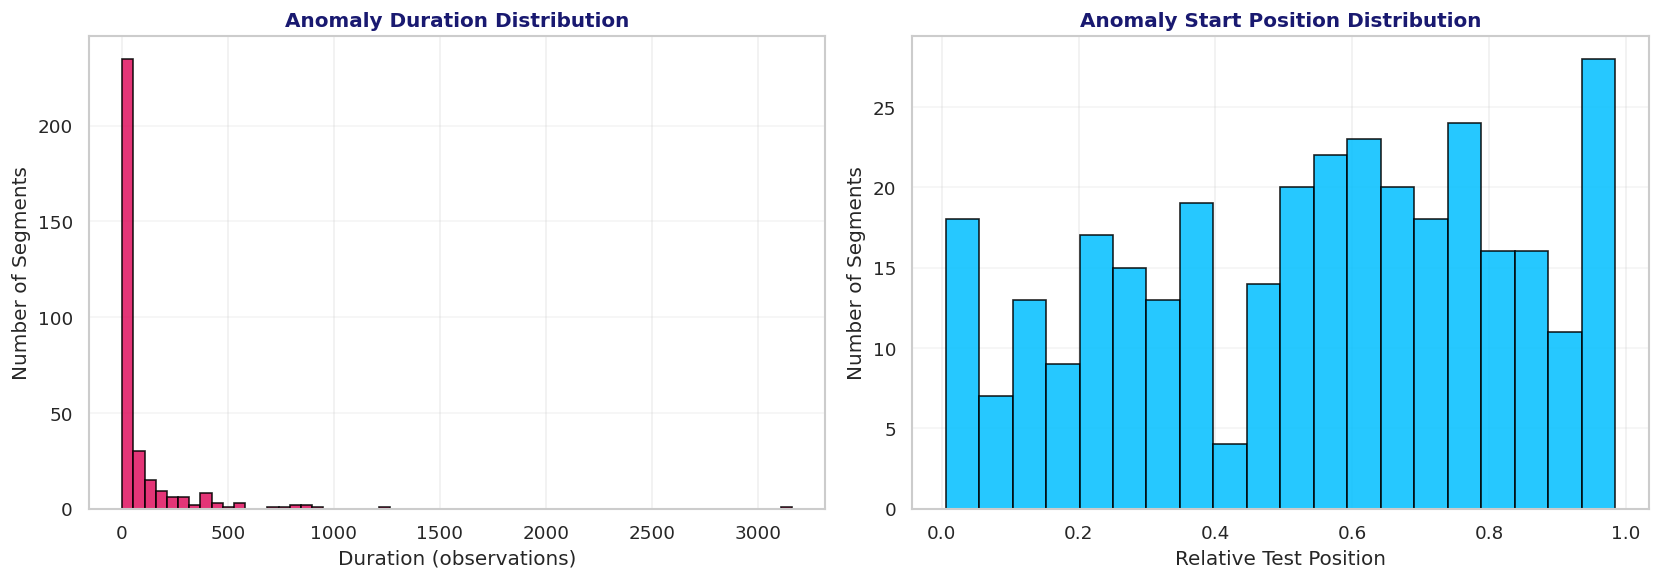


ANOMALY SEGMENT ANALYSIS COMPLETED
Machines processed: 28
Total anomaly segments: 327
Average segment duration: 90.04
Median segment duration: 11.00

Generated files:
  - anomaly_segments.csv
  - anomaly_frequency.csv
  - anomaly_duration_position.png

Metrics directory: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/metrics
Plots directory: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/plots


In [ ]:
# ============================================================
# ANOMALY SEGMENT AND FREQUENCY ANALYSIS - SMD DATASET
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path


# ------------------------------------------------------------
# 1. CREATE OUTPUT DIRECTORIES
# ------------------------------------------------------------

METRICS_PATH = Path(METRICS_PATH)
PLOTS_PATH = Path(PLOTS_PATH)

METRICS_PATH.mkdir(parents=True, exist_ok=True)
PLOTS_PATH.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. FUNCTION TO IDENTIFY CONTIGUOUS ANOMALY SEGMENTS
# ------------------------------------------------------------

def anomaly_segments(labels):
    """
    Identify contiguous anomaly segments.

    Parameters
    ----------
    labels : array-like
        Binary anomaly labels:
        0 = Normal
        1 = Anomaly

    Returns
    -------
    list of tuples
        Each tuple contains:
        (start_index, end_index_exclusive)
    """

    labels = np.asarray(labels).flatten()

    if len(labels) == 0:
        return []

    anomaly_indices = np.where(labels == 1)[0]

    if len(anomaly_indices) == 0:
        return []

    # Split anomaly indices wherever consecutive positions
    # are separated by more than one observation.
    split_positions = np.where(
        np.diff(anomaly_indices) > 1
    )[0] + 1

    groups = np.split(anomaly_indices, split_positions)

    segments = []

    for group in groups:
        start = int(group[0])
        end_exclusive = int(group[-1]) + 1

        segments.append((start, end_exclusive))

    return segments


# ------------------------------------------------------------
# 3. ANALYSE ALL MACHINES
# ------------------------------------------------------------

segments = []
frequency = []

for machine in train_machines:

    print(f"Processing: {machine}")

    # Load test data and anomaly labels
    train, test, labels = load_machine(machine, DATASET_PATH)

    labels = np.asarray(labels).flatten()

    # Identify anomaly segments
    machine_segments = anomaly_segments(labels)

    total_observations = len(labels)

    if total_observations == 0:
        print(f"Skipping {machine}: No test observations.")
        continue

    # --------------------------------------------------------
    # 3A. STORE INDIVIDUAL ANOMALY SEGMENTS
    # --------------------------------------------------------

    for start, end_exclusive in machine_segments:

        duration = end_exclusive - start

        segments.append({
            'machine': machine,
            'start': start,
            'end_inclusive': end_exclusive - 1,
            'duration': duration,
            'relative_start': start / total_observations,
            'point_anomaly': duration == 1
        })

    # --------------------------------------------------------
    # 3B. STORE MACHINE-LEVEL ANOMALY FREQUENCY
    # --------------------------------------------------------

    anomaly_points = int(np.sum(labels == 1))

    segment_count = len(machine_segments)

    segment_frequency = (
        1000 * segment_count / total_observations
    )

    frequency.append({
        'machine': machine,
        'total_observations': total_observations,
        'segments': segment_count,
        'anomaly_points': anomaly_points,
        'anomaly_percentage': (
            100 * anomaly_points / total_observations
        ),
        'segment_frequency_per_1000': segment_frequency
    })

    print(f"  Anomaly segments: {segment_count}")
    print(f"  Anomaly points: {anomaly_points}")


# ------------------------------------------------------------
# 4. CREATE DATAFRAMES
# ------------------------------------------------------------

segment_columns = [
    'machine',
    'start',
    'end_inclusive',
    'duration',
    'relative_start',
    'point_anomaly'
]

frequency_columns = [
    'machine',
    'total_observations',
    'segments',
    'anomaly_points',
    'anomaly_percentage',
    'segment_frequency_per_1000'
]

segment_df = pd.DataFrame(
    segments,
    columns=segment_columns
)

frequency_df = pd.DataFrame(
    frequency,
    columns=frequency_columns
)


# ------------------------------------------------------------
# 5. SAVE CSV FILES
# ------------------------------------------------------------

segment_file = METRICS_PATH / 'anomaly_segments.csv'
frequency_file = METRICS_PATH / 'anomaly_frequency.csv'

segment_df.to_csv(segment_file, index=False)
frequency_df.to_csv(frequency_file, index=False)

print("\nCSV files saved:")
print(f"  {segment_file}")
print(f"  {frequency_file}")


# ------------------------------------------------------------
# 6. DISPLAY ANOMALY DURATION STATISTICS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("ANOMALY SEGMENT DURATION STATISTICS")
print("=" * 65)

if not segment_df.empty:

    duration_summary = segment_df['duration'].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    )

    display(duration_summary.to_frame().T.round(4))

    # Additional segment statistics
    total_segments = len(segment_df)

    point_anomalies = int(
        segment_df['point_anomaly'].sum()
    )

    longer_segments = total_segments - point_anomalies

    print(f"\nTotal anomaly segments: {total_segments}")
    print(f"Single-point anomalies: {point_anomalies}")
    print(f"Multi-point anomalies: {longer_segments}")

else:
    print("No anomaly segments found.")


# ------------------------------------------------------------
# 7. DISPLAY MACHINE-LEVEL ANOMALY FREQUENCY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("MACHINE-LEVEL ANOMALY FREQUENCY")
print("=" * 65)

display(
    frequency_df.sort_values(
        'segment_frequency_per_1000',
        ascending=False
    ).round(4)
)


# ------------------------------------------------------------
# 8. VISUALISE ANOMALY DURATION AND START POSITION
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

# ------------------------------------------------------------
# 8A. ANOMALY DURATION DISTRIBUTION
# ------------------------------------------------------------

if not segment_df.empty:

    axes[0].hist(
        segment_df['duration'],
        bins=60,
        color=MASTER_PALETTE['ruby'],
        edgecolor='black',
        alpha=0.85
    )

    axes[0].set(
        xlabel='Duration (observations)',
        ylabel='Number of Segments',
        title='Anomaly Duration Distribution'
    )

else:
    axes[0].text(
        0.5, 0.5,
        'No anomaly segments available',
        ha='center',
        va='center',
        transform=axes[0].transAxes
    )

axes[0].grid(
    axis='y',
    alpha=0.2
)


# ------------------------------------------------------------
# 8B. ANOMALY START POSITION DISTRIBUTION
# ------------------------------------------------------------

if not segment_df.empty:

    axes[1].hist(
        segment_df['relative_start'],
        bins=20,
        color=MASTER_PALETTE['electric'],
        edgecolor='black',
        alpha=0.85
    )

    axes[1].set(
        xlabel='Relative Test Position',
        ylabel='Number of Segments',
        title='Anomaly Start Position Distribution'
    )

else:
    axes[1].text(
        0.5, 0.5,
        'No anomaly segments available',
        ha='center',
        va='center',
        transform=axes[1].transAxes
    )

axes[1].grid(
    axis='y',
    alpha=0.2
)


# ------------------------------------------------------------
# 9. SAVE FIGURE
# ------------------------------------------------------------

fig.tight_layout()

plot_file = PLOTS_PATH / 'anomaly_duration_position.png'

fig.savefig(
    plot_file,
    dpi=300,
    bbox_inches='tight'
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 10. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("ANOMALY SEGMENT ANALYSIS COMPLETED")
print("=" * 65)

print(f"Machines processed: {len(frequency_df)}")
print(f"Total anomaly segments: {len(segment_df)}")

if not segment_df.empty:
    print(
        f"Average segment duration: "
        f"{segment_df['duration'].mean():.2f}"
    )

    print(
        f"Median segment duration: "
        f"{segment_df['duration'].median():.2f}"
    )

print("\nGenerated files:")
print(f"  - {segment_file.name}")
print(f"  - {frequency_file.name}")
print(f"  - {plot_file.name}")

print(f"\nMetrics directory: {METRICS_PATH}")
print(f"Plots directory: {PLOTS_PATH}")

#### Before/after anomaly onset and contextual candidates

Compare mean feature values in 30 observations before and after anomaly onset, normalized by training standard deviation. This is exploratory and **not** a causal attribution or confirmed contextual-anomaly classification.

In [ ]:
# ============================================================
# ANOMALY ONSET FEATURE-CHANGE ANALYSIS - SMD DATASET
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path


# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

CONTEXT_WINDOW = 30
TOP_FEATURES = 5

METRICS_PATH = Path(METRICS_PATH)
METRICS_PATH.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. FUNCTION: IDENTIFY ANOMALY SEGMENTS
# ------------------------------------------------------------

def anomaly_segments(labels):
    """
    Identify contiguous anomaly segments.

    Returns:
        List of (start, end_exclusive) tuples.
    """

    labels = np.asarray(labels).flatten()

    if len(labels) == 0:
        return []

    anomaly_indices = np.where(labels == 1)[0]

    if len(anomaly_indices) == 0:
        return []

    split_positions = np.where(
        np.diff(anomaly_indices) > 1
    )[0] + 1

    groups = np.split(anomaly_indices, split_positions)

    return [
        (int(group[0]), int(group[-1]) + 1)
        for group in groups
    ]


# ------------------------------------------------------------
# 3. ANALYSE FEATURE CHANGES AROUND ANOMALY ONSETS
# ------------------------------------------------------------

changes = []

processed_segments = 0
skipped_segments = 0

for machine in train_machines:

    print(f"\nProcessing: {machine}")

    # Correct load_machine argument order
    train, test, labels = load_machine(machine, DATASET_PATH)

    # Convert NumPy arrays into DataFrames
    train = pd.DataFrame(train)
    test = pd.DataFrame(test)

    labels = np.asarray(labels).flatten()

    # Ensure training and test data have matching features
    if train.shape[1] != test.shape[1]:
        print(f"Skipping {machine}: Feature count mismatch.")
        continue

    # Assign consistent feature names
    feature_names = [
        f'feature_{i}' for i in range(train.shape[1])
    ]

    train.columns = feature_names
    test.columns = feature_names

    # Convert values to numeric
    train = train.apply(pd.to_numeric, errors='coerce')
    test = test.apply(pd.to_numeric, errors='coerce')

    # --------------------------------------------------------
    # 3A. CALCULATE TRAINING STANDARD DEVIATION
    # --------------------------------------------------------

    # Training data provides the reference scale.
    train_std = train.std()

    # Remove zero, infinite and invalid standard deviations.
    train_std = train_std.replace(
        [0, np.inf, -np.inf],
        np.nan
    )

    valid_features = train_std.dropna().index

    if len(valid_features) == 0:
        print(f"Skipping {machine}: No valid features.")
        continue

    test = test[valid_features]
    train_std = train_std[valid_features]

    # --------------------------------------------------------
    # 3B. IDENTIFY ANOMALY SEGMENTS
    # --------------------------------------------------------

    machine_segments = anomaly_segments(labels)

    machine_changes_before = len(changes)

    for start, end_exclusive in machine_segments:

        duration = end_exclusive - start

        # Need 30 observations before and after onset.
        if (
            start < CONTEXT_WINDOW
            or start + CONTEXT_WINDOW > len(test)
        ):
            skipped_segments += 1
            continue

        # ----------------------------------------------------
        # 3C. CALCULATE PRE- AND POST-ONSET MEANS
        # ----------------------------------------------------

        pre_window = test.iloc[
            start - CONTEXT_WINDOW:start
        ]

        post_window = test.iloc[
            start:start + CONTEXT_WINDOW
        ]

        pre_mean = pre_window.mean()
        post_mean = post_window.mean()

        # ----------------------------------------------------
        # 3D. CALCULATE STANDARDISED MEAN SHIFT
        # ----------------------------------------------------

        mean_difference = post_mean - pre_mean

        standardised_shift = (
            mean_difference / train_std
        ).abs()

        # Remove invalid values
        standardised_shift = (
            standardised_shift
            .replace([np.inf, -np.inf], np.nan)
            .dropna()
            .sort_values(ascending=False)
        )

        # ----------------------------------------------------
        # 3E. STORE TOP CHANGING FEATURES
        # ----------------------------------------------------

        for feature, value in standardised_shift.head(
            TOP_FEATURES
        ).items():

            changes.append({
                'machine': machine,
                'onset': start,
                'end_inclusive': end_exclusive - 1,
                'duration': duration,
                'feature': feature,
                'pre_mean': pre_mean[feature],
                'post_mean': post_mean[feature],
                'mean_difference': mean_difference[feature],
                'training_std': train_std[feature],
                'abs_standardized_mean_shift': value
            })

        processed_segments += 1

    machine_changes = len(changes) - machine_changes_before

    print(f"  Anomaly segments: {len(machine_segments)}")
    print(f"  Feature changes recorded: {machine_changes}")


# ------------------------------------------------------------
# 4. CREATE RESULTS DATAFRAME
# ------------------------------------------------------------

columns = [
    'machine',
    'onset',
    'end_inclusive',
    'duration',
    'feature',
    'pre_mean',
    'post_mean',
    'mean_difference',
    'training_std',
    'abs_standardized_mean_shift'
]

change_df = pd.DataFrame(
    changes,
    columns=columns
)


# ------------------------------------------------------------
# 5. SAVE RESULTS
# ------------------------------------------------------------

output_file = METRICS_PATH / 'anomaly_onset_changes.csv'

change_df.to_csv(
    output_file,
    index=False
)


# ------------------------------------------------------------
# 6. DISPLAY TOP RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("ANOMALY ONSET FEATURE CHANGES")
print("=" * 65)

if not change_df.empty:

    display(
        change_df.sort_values(
            'abs_standardized_mean_shift',
            ascending=False
        ).head(15).round(4)
    )

else:
    print("No valid anomaly onset changes were found.")


# ------------------------------------------------------------
# 7. FEATURE-LEVEL SUMMARY
# ------------------------------------------------------------

if not change_df.empty:

    print("\n" + "=" * 65)
    print("FEATURE-LEVEL SUMMARY")
    print("=" * 65)

    feature_summary = (
        change_df
        .groupby('feature')
        .agg(
            observations=('abs_standardized_mean_shift', 'count'),
            mean_shift=('abs_standardized_mean_shift', 'mean'),
            median_shift=('abs_standardized_mean_shift', 'median'),
            maximum_shift=('abs_standardized_mean_shift', 'max')
        )
        .sort_values(
            'median_shift',
            ascending=False
        )
    )

    display(feature_summary.round(4))

    feature_summary.to_csv(
        METRICS_PATH / 'anomaly_feature_shift_summary.csv'
    )


# ------------------------------------------------------------
# 8. MACHINE-LEVEL SUMMARY
# ------------------------------------------------------------

if not change_df.empty:

    print("\n" + "=" * 65)
    print("MACHINE-LEVEL SUMMARY")
    print("=" * 65)

    machine_summary = (
        change_df
        .groupby('machine')
        .agg(
            recorded_feature_changes=(
                'abs_standardized_mean_shift', 'count'
            ),
            mean_standardized_shift=(
                'abs_standardized_mean_shift', 'mean'
            ),
            median_standardized_shift=(
                'abs_standardized_mean_shift', 'median'
            ),
            maximum_standardized_shift=(
                'abs_standardized_mean_shift', 'max'
            )
        )
        .sort_values(
            'mean_standardized_shift',
            ascending=False
        )
    )

    display(machine_summary.round(4))

    machine_summary.to_csv(
        METRICS_PATH / 'anomaly_machine_shift_summary.csv'
    )


# ------------------------------------------------------------
# 9. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("ANOMALY ONSET ANALYSIS COMPLETED")
print("=" * 65)

print(f"Machines processed: {len(train_machines)}")
print(f"Valid anomaly segments analysed: {processed_segments}")
print(f"Segments skipped due to boundaries: {skipped_segments}")
print(f"Feature-change records: {len(change_df)}")

print("\nGenerated files:")

print(" - anomaly_onset_changes.csv")

if not change_df.empty:
    print(" - anomaly_feature_shift_summary.csv")
    print(" - anomaly_machine_shift_summary.csv")

print(f"\nOutput directory: {METRICS_PATH}")

print(
    "\nNOTE: Contextual anomaly types are not assigned. "
    "Large metric changes alone do not establish the "
    "underlying cause of an anomaly."
)


Processing: machine-1-1
  Anomaly segments: 8
  Feature changes recorded: 40

Processing: machine-1-2
  Anomaly segments: 10
  Feature changes recorded: 50

Processing: machine-1-3
  Anomaly segments: 12
  Feature changes recorded: 60

Processing: machine-1-4
  Anomaly segments: 12
  Feature changes recorded: 60

Processing: machine-1-5
  Anomaly segments: 7
  Feature changes recorded: 35

Processing: machine-1-6
  Anomaly segments: 30
  Feature changes recorded: 150

Processing: machine-1-7
  Anomaly segments: 13
  Feature changes recorded: 65

Processing: machine-1-8
  Anomaly segments: 20
  Feature changes recorded: 100

Processing: machine-2-1
  Anomaly segments: 13
  Feature changes recorded: 65

Processing: machine-2-2
  Anomaly segments: 11
  Feature changes recorded: 55

Processing: machine-2-3
  Anomaly segments: 10
  Feature changes recorded: 50

Processing: machine-2-4
  Anomaly segments: 20
  Feature changes recorded: 100

Processing: machine-2-5
  Anomaly segments: 21
  F

,machine,onset,end_inclusive,duration,feature,pre_mean,post_mean,mean_difference,training_std,abs_standardized_mean_shift
1225,machine-3-11,27995,28000,6,feature_9,0.0003,0.0333,0.0330,0.0000,3640.0568
1215,machine-3-11,21230,21295,66,feature_9,0.0000,0.0299,0.0299,0.0000,3304.7965
1075,machine-2-8,17580,17740,161,feature_29,0.0011,0.3144,0.3134,0.0001,2749.4113
1085,machine-2-9,15598,16011,414,feature_9,0.0003,0.0399,0.0397,0.0000,1941.0903
1145,machine-3-1,27839,27963,125,feature_34,0.0032,0.3049,0.3016,0.0002,1323.4822
1146,machine-3-1,27839,27963,125,feature_35,0.0032,0.3049,0.3016,0.0002,1322.0041
200,machine-1-4,22970,23015,46,feature_16,0.0000,0.2165,0.2165,0.0002,1119.6516
1630,machine-3-9,27849,27949,101,feature_34,0.0031,0.2376,0.2344,0.0002,1079.1256
1631,machine-3-9,27849,27949,101,feature_35,0.0031,0.2376,0.2344,0.0002,1078.3694
1076,machine-2-8,17580,17740,161,feature_31,0.0008,0.3057,0.3049,0.0004,821.3760



FEATURE-LEVEL SUMMARY


,observations,mean_shift,median_shift,maximum_shift
feature,,,,
feature_4,4,32.4230,14.6754,99.5765
feature_17,14,30.1365,12.8552,199.1155
feature_28,1,11.4236,11.4236,11.4236
feature_16,14,100.5700,5.9872,1119.6516
feature_27,13,5.5881,3.7671,22.7614
feature_1,55,19.1613,3.3111,185.9766
feature_2,67,23.0775,2.4626,261.1927
feature_26,1,2.2951,2.2951,2.2951
feature_9,84,132.4677,2.2647,3640.0568



MACHINE-LEVEL SUMMARY


,recorded_feature_changes,mean_standardized_shift,median_standardized_shift,maximum_standardized_shift
machine,,,,
machine-2-8,5,1073.5226,813.4955,2749.4113
machine-3-11,15,486.9777,0.9803,3640.0568
machine-3-1,20,138.2352,6.3043,1323.4822
machine-3-9,20,114.0522,6.2226,1079.1256
machine-2-9,50,66.1934,6.0262,1941.0903
machine-1-5,35,62.4530,10.7738,261.1927
machine-1-4,60,28.6821,0.7902,1119.6516
machine-2-2,55,28.3879,2.1147,236.5019
machine-3-4,40,25.3268,2.1924,630.3236



ANOMALY ONSET ANALYSIS COMPLETED
Machines processed: 28
Valid anomaly segments analysed: 327
Segments skipped due to boundaries: 0
Feature-change records: 1635

Generated files:
 - anomaly_onset_changes.csv
 - anomaly_feature_shift_summary.csv
 - anomaly_machine_shift_summary.csv

Output directory: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/metrics

NOTE: Contextual anomaly types are not assigned. Large metric changes alone do not establish the underlying cause of an anomaly.


### 2.5 — Window Length Justification

**SMD Phase 2 EDA** · Run cells in order. All results are calculated from files; no observation counts are hard-coded.

**Paths:** `data/raw/OmniAnomaly/ServerMachineDataset/` → `results/metrics/`, `results/plots/`. Test labels are for descriptive EDA only, not model fitting.

#### Coverage of anomaly segments

Evaluate window lengths 10, 30 and 60 against **observed test-label segment durations**. The proportion of segments shorter than a window is descriptive, not model performance. No verified sampling interval is supplied by these files.

Processing: machine-1-1
  Test observations: 28,479
  Anomaly segments: 8
  Anomaly points: 2,694
Processing: machine-1-2
  Test observations: 23,694
  Anomaly segments: 10
  Anomaly points: 542
Processing: machine-1-3
  Test observations: 23,703
  Anomaly segments: 12
  Anomaly points: 817
Processing: machine-1-4
  Test observations: 23,707
  Anomaly segments: 12
  Anomaly points: 720
Processing: machine-1-5
  Test observations: 23,706
  Anomaly segments: 7
  Anomaly points: 100
Processing: machine-1-6
  Test observations: 23,689
  Anomaly segments: 30
  Anomaly points: 3,708
Processing: machine-1-7
  Test observations: 23,697
  Anomaly segments: 13
  Anomaly points: 2,398
Processing: machine-1-8
  Test observations: 23,699
  Anomaly segments: 20
  Anomaly points: 763
Processing: machine-2-1
  Test observations: 23,694
  Anomaly segments: 13
  Anomaly points: 1,170
Processing: machine-2-2
  Test observations: 23,700
  Anomaly segments: 11
  Anomaly points: 2,833
Processing: machine-2-

,machine,window,test_rows,available_sliding_windows,total_anomaly_segments,segments_with_duration_le_window,pct_segments_with_duration_le_window,total_anomaly_points,anomaly_points_in_short_segments,pct_anomaly_points_in_short_segments
0,machine-1-1,10,28479,28470,8,3,37.500,2694,7,0.260
1,machine-1-1,30,28479,28450,8,3,37.500,2694,7,0.260
2,machine-1-1,60,28479,28420,8,3,37.500,2694,7,0.260
3,machine-1-2,10,23694,23685,10,2,20.000,542,8,1.476
4,machine-1-2,30,23694,23665,10,3,30.000,542,30,5.535
...,...,...,...,...,...,...,...,...,...,...
79,machine-3-8,30,28704,28675,6,1,16.667,1371,17,1.240
80,machine-3-8,60,28704,28645,6,1,16.667,1371,17,1.240
81,machine-3-9,10,28713,28704,4,0,0.000,303,0,0.000
82,machine-3-9,30,28713,28684,4,0,0.000,303,0,0.000



Machine-level results saved: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/metrics/window_coverage.csv

WINDOW-LEVEL SUMMARY


,window,machines,mean_segment_coverage,median_segment_coverage,mean_anomaly_point_coverage,median_anomaly_point_coverage,mean_available_windows
0,10,28,36.024,31.667,3.314,1.544,25291.714
1,30,28,51.694,51.923,9.626,5.648,25271.714
2,60,28,63.401,68.333,17.244,12.798,25241.714


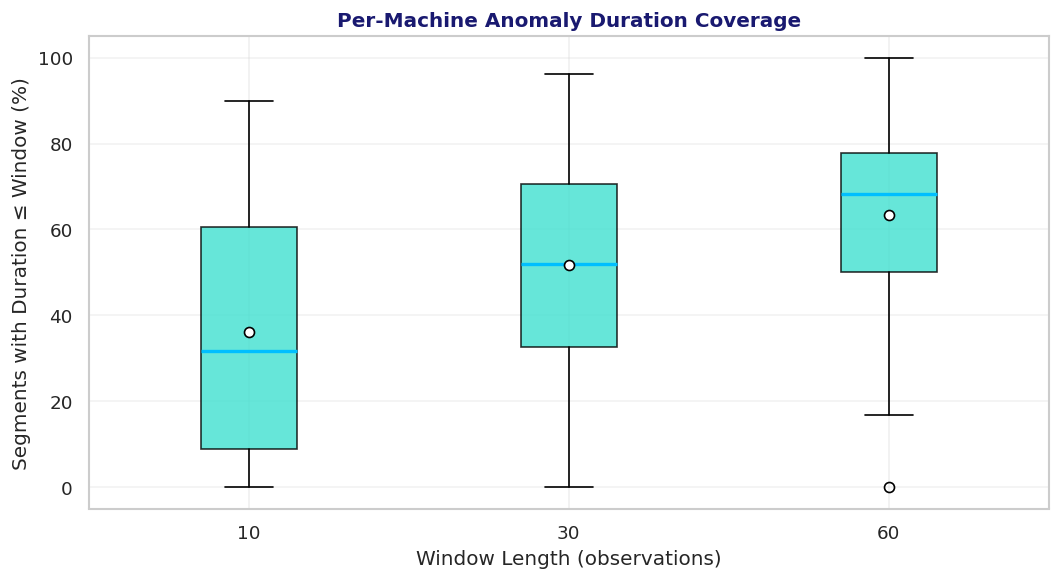

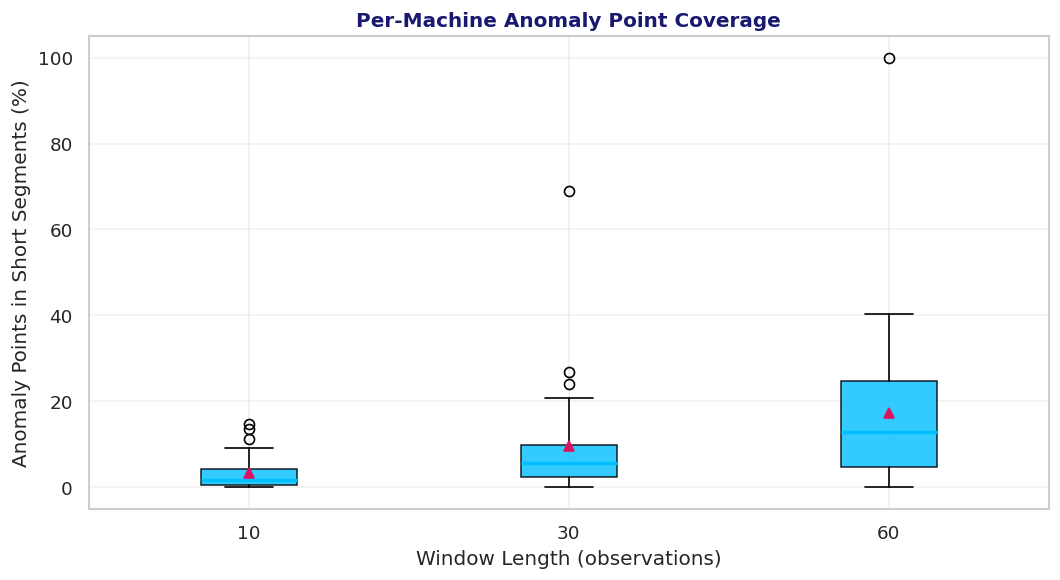


WINDOW COVERAGE ANALYSIS COMPLETED
Machines processed: 28
Window lengths analysed: [10, 30, 60]

Generated files:
1. anomaly_segments.csv
2. anomaly_frequency.csv
3. window_coverage.csv
4. window_coverage_summary.csv
5. window_coverage.png
6. window_anomaly_point_coverage.png

Metrics directory: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/metrics
Plots directory: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/plots


In [ ]:
# ============================================================
# WINDOW LENGTH vs ANOMALY DURATION COVERAGE - SMD DATASET
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path


# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

WINDOWS = [10, 30, 60]

METRICS_PATH = Path(METRICS_PATH)
PLOTS_PATH = Path(PLOTS_PATH)

METRICS_PATH.mkdir(parents=True, exist_ok=True)
PLOTS_PATH.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. FUNCTION: IDENTIFY ANOMALY SEGMENTS
# ------------------------------------------------------------

def anomaly_segments(labels):
    """
    Identify contiguous anomaly segments.

    0 = Normal
    1 = Anomaly

    Returns:
        List of (start, end_exclusive) tuples.
    """

    labels = np.asarray(labels).flatten()

    if len(labels) == 0:
        return []

    anomaly_indices = np.where(labels == 1)[0]

    if len(anomaly_indices) == 0:
        return []

    split_positions = np.where(
        np.diff(anomaly_indices) > 1
    )[0] + 1

    groups = np.split(
        anomaly_indices,
        split_positions
    )

    return [
        (int(group[0]), int(group[-1]) + 1)
        for group in groups
    ]


# ------------------------------------------------------------
# 3. CALCULATE WINDOW COVERAGE FOR ALL MACHINES
# ------------------------------------------------------------

rows = []

for machine in train_machines:

    print(f"Processing: {machine}")

    # Load test data and labels
    train, test, labels = load_machine(machine, DATASET_PATH)

    test = np.asarray(test)
    labels = np.asarray(labels).flatten()

    # Validate data
    if len(test) != len(labels):
        print(f"Skipping {machine}: Length mismatch.")
        continue

    test_rows = len(test)

    if test_rows == 0:
        print(f"Skipping {machine}: Empty test dataset.")
        continue

    # Identify anomaly segments
    machine_segments = anomaly_segments(labels)

    durations = np.array(
        [end - start for start, end in machine_segments],
        dtype=int
    )

    total_segments = len(durations)

    total_anomaly_points = int(
        np.sum(labels == 1)
    )

    # --------------------------------------------------------
    # 3A. ANALYSE EACH WINDOW LENGTH
    # --------------------------------------------------------

    for window in WINDOWS:

        # Available overlapping sliding windows
        available_windows = max(
            0,
            test_rows - window + 1
        )

        # Segments with duration <= window
        short_segments = durations[
            durations <= window
        ]

        short_segment_count = len(short_segments)

        # Percentage of anomaly segments
        pct_segments_covered = (
            100 * short_segment_count / total_segments
            if total_segments > 0
            else np.nan
        )

        # Anomaly points belonging to short segments
        anomaly_points_in_short_segments = int(
            short_segments.sum()
        )

        # Percentage of anomaly points
        pct_anomaly_points_covered = (
            100 * anomaly_points_in_short_segments
            / total_anomaly_points
            if total_anomaly_points > 0
            else np.nan
        )

        rows.append({

            'machine': machine,

            'window': window,

            'test_rows': test_rows,

            'available_sliding_windows': available_windows,

            'total_anomaly_segments': total_segments,

            'segments_with_duration_le_window':
                short_segment_count,

            'pct_segments_with_duration_le_window':
                pct_segments_covered,

            'total_anomaly_points':
                total_anomaly_points,

            'anomaly_points_in_short_segments':
                anomaly_points_in_short_segments,

            'pct_anomaly_points_in_short_segments':
                pct_anomaly_points_covered

        })

    print(f"  Test observations: {test_rows:,}")
    print(f"  Anomaly segments: {total_segments}")
    print(f"  Anomaly points: {total_anomaly_points:,}")


# ------------------------------------------------------------
# 4. CREATE COVERAGE DATAFRAME
# ------------------------------------------------------------

coverage = pd.DataFrame(rows)

print("\n" + "=" * 65)
print("WINDOW COVERAGE RESULTS")
print("=" * 65)

display(coverage.round(3))


# ------------------------------------------------------------
# 5. SAVE MACHINE-LEVEL RESULTS
# ------------------------------------------------------------

coverage_file = METRICS_PATH / 'window_coverage.csv'

coverage.to_csv(
    coverage_file,
    index=False
)

print(f"\nMachine-level results saved: {coverage_file}")


# ------------------------------------------------------------
# 6. WINDOW-LEVEL SUMMARY
# ------------------------------------------------------------

if not coverage.empty:

    summary = (
        coverage
        .groupby('window')
        .agg(
            machines=('machine', 'nunique'),

            mean_segment_coverage=(
                'pct_segments_with_duration_le_window',
                'mean'
            ),

            median_segment_coverage=(
                'pct_segments_with_duration_le_window',
                'median'
            ),

            mean_anomaly_point_coverage=(
                'pct_anomaly_points_in_short_segments',
                'mean'
            ),

            median_anomaly_point_coverage=(
                'pct_anomaly_points_in_short_segments',
                'median'
            ),

            mean_available_windows=(
                'available_sliding_windows',
                'mean'
            )
        )
        .reset_index()
    )

    print("\n" + "=" * 65)
    print("WINDOW-LEVEL SUMMARY")
    print("=" * 65)

    display(summary.round(3))

    summary_file = (
        METRICS_PATH / 'window_coverage_summary.csv'
    )

    summary.to_csv(summary_file, index=False)


# ------------------------------------------------------------
# 7. BOXPLOT: ANOMALY SEGMENT DURATION COVERAGE
# ------------------------------------------------------------

if not coverage.empty:

    fig, ax = plt.subplots(figsize=(9, 5))

    boxplot_data = [
        coverage.loc[
            coverage['window'] == window,
            'pct_segments_with_duration_le_window'
        ].dropna().values

        for window in WINDOWS
    ]

    box = ax.boxplot(
        boxplot_data,
        patch_artist=True,
        showmeans=True,
        medianprops={'linewidth': 2},
        meanprops={
            'marker': 'o',
            'markerfacecolor': 'white',
            'markeredgecolor': 'black'
        }
    )

    for patch in box['boxes']:
        patch.set_facecolor(
            MASTER_PALETTE['turquoise']
        )
        patch.set_alpha(0.8)

    # Version-compatible x-axis labels
    ax.set_xticks(range(1, len(WINDOWS) + 1))
    ax.set_xticklabels([str(w) for w in WINDOWS])

    ax.set(
        xlabel='Window Length (observations)',
        ylabel='Segments with Duration ≤ Window (%)',
        title='Per-Machine Anomaly Duration Coverage'
    )

    ax.grid(axis='y', alpha=0.25)

    fig.tight_layout()

    plot_file = PLOTS_PATH / 'window_coverage.png'

    fig.savefig(
        plot_file,
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 8. BOXPLOT: ANOMALY POINT COVERAGE
# ------------------------------------------------------------

if not coverage.empty:

    fig, ax = plt.subplots(figsize=(9, 5))

    boxplot_data = [
        coverage.loc[
            coverage['window'] == window,
            'pct_anomaly_points_in_short_segments'
        ].dropna().values

        for window in WINDOWS
    ]

    box = ax.boxplot(
        boxplot_data,
        patch_artist=True,
        showmeans=True,
        medianprops={'linewidth': 2}
    )

    for patch in box['boxes']:
        patch.set_facecolor(
            MASTER_PALETTE['electric']
        )
        patch.set_alpha(0.8)

    # Version-compatible x-axis labels
    ax.set_xticks(range(1, len(WINDOWS) + 1))
    ax.set_xticklabels([str(w) for w in WINDOWS])

    ax.set(
        xlabel='Window Length (observations)',
        ylabel='Anomaly Points in Short Segments (%)',
        title='Per-Machine Anomaly Point Coverage'
    )

    ax.grid(axis='y', alpha=0.25)

    fig.tight_layout()

    point_plot_file = (
        PLOTS_PATH / 'window_anomaly_point_coverage.png'
    )

    fig.savefig(
        point_plot_file,
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 9. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("WINDOW COVERAGE ANALYSIS COMPLETED")
print("=" * 65)

print(f"Machines processed: {coverage['machine'].nunique()}")
print(f"Window lengths analysed: {WINDOWS}")

print("\nGenerated files:")

print("1. anomaly_segments.csv")
print("2. anomaly_frequency.csv")
print("3. window_coverage.csv")
print("4. window_coverage_summary.csv")
print("5. window_coverage.png")
print("6. window_anomaly_point_coverage.png")

print(f"\nMetrics directory: {METRICS_PATH}")
print(f"Plots directory: {PLOTS_PATH}")

#### Experimental rationale and representative machines

10 is short-context, 30 intermediate, 60 longer-context **in observations**. Convert to elapsed time only after independent documentation verifies sampling frequency. Use all machines for final evaluation; the subset below is for visual case studies.

In [ ]:
# ============================================================
# REPRESENTATIVE MACHINE SELECTION - SMD DATASET
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path


# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

METRICS_PATH = Path(METRICS_PATH)
METRICS_PATH.mkdir(parents=True, exist_ok=True)

summary_path = METRICS_PATH / 'machine_summary.csv'

output_path = METRICS_PATH / 'representative_machines.csv'


# ------------------------------------------------------------
# 2. LOAD OR GENERATE MACHINE SUMMARY
# ------------------------------------------------------------

if summary_path.exists():

    print("Loading existing machine summary...")

    summary = pd.read_csv(summary_path)

    required_columns = {
        'machine',
        'anomaly_percentage'
    }

    if not required_columns.issubset(summary.columns):

        raise ValueError(
            "machine_summary.csv must contain "
            "'machine' and 'anomaly_percentage' columns."
        )

else:

    print("Machine summary not found. Generating summary...")

    temp = []

    for machine in train_machines:

        print(f"Processing: {machine}")

        # Correct load_machine argument order
        train, test, labels = load_machine(
            machine,
            DATASET_PATH
        )

        labels = np.asarray(labels).flatten()

        if len(labels) == 0:
            anomaly_percentage = np.nan

        else:
            anomaly_percentage = (
                100 * np.mean(labels == 1)
            )

        temp.append({
            'machine': machine,
            'anomaly_points': int(np.sum(labels == 1)),
            'total_test_observations': len(labels),
            'anomaly_percentage': anomaly_percentage
        })

    summary = pd.DataFrame(temp)

    # Save complete machine summary
    summary.to_csv(
        summary_path,
        index=False
    )

    print(f"Machine summary saved: {summary_path}")


# ------------------------------------------------------------
# 3. CLEAN AND VALIDATE SUMMARY
# ------------------------------------------------------------

summary['anomaly_percentage'] = pd.to_numeric(
    summary['anomaly_percentage'],
    errors='coerce'
)

summary = summary.dropna(
    subset=['machine', 'anomaly_percentage']
)

summary = summary.drop_duplicates(
    subset='machine'
)

if summary.empty:

    raise ValueError(
        "No valid machine anomaly percentages available."
    )

# Ensure percentages are valid
summary = summary[
    summary['anomaly_percentage'].between(0, 100)
]

if len(summary) < 5:

    print(
        f"Warning: Only {len(summary)} valid machines available."
    )


# ------------------------------------------------------------
# 4. CALCULATE MEDIAN ANOMALY PERCENTAGE
# ------------------------------------------------------------

median_anomaly_percentage = (
    summary['anomaly_percentage'].median()
)

print("\n" + "=" * 65)
print("MACHINE ANOMALY DISTRIBUTION")
print("=" * 65)

print(
    f"Number of valid machines: {len(summary)}"
)

print(
    f"Median anomaly percentage: "
    f"{median_anomaly_percentage:.4f}%"
)


# ------------------------------------------------------------
# 5. SELECT REPRESENTATIVE MACHINES
# ------------------------------------------------------------

# Two machines with the highest anomaly percentages
highest = summary.nlargest(
    2,
    'anomaly_percentage'
)

# One machine closest to the median
median_machine = (
    summary.assign(
        median_distance=(
            summary['anomaly_percentage']
            - median_anomaly_percentage
        ).abs()
    )
    .nsmallest(1, 'median_distance')
)

# Two machines with the lowest anomaly percentages
lowest = summary.nsmallest(
    2,
    'anomaly_percentage'
)

# Combine selections
selected = pd.concat(
    [highest, median_machine, lowest],
    ignore_index=True
)

# Remove duplicate machines
selected = selected.drop_duplicates(
    subset='machine'
)

# Remove temporary selection column if present
selected = selected.drop(
    columns=['median_distance'],
    errors='ignore'
)

# Sort selected machines by anomaly percentage
selected = selected.sort_values(
    'anomaly_percentage',
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# 6. ADD SELECTION CATEGORY
# ------------------------------------------------------------

def get_selection_category(machine):

    if machine in highest['machine'].values:
        return 'High anomaly percentage'

    elif machine in median_machine['machine'].values:
        return 'Median anomaly percentage'

    elif machine in lowest['machine'].values:
        return 'Low anomaly percentage'

    return 'Other'


selected['selection_category'] = (
    selected['machine'].apply(get_selection_category)
)


# ------------------------------------------------------------
# 7. SAVE REPRESENTATIVE MACHINES
# ------------------------------------------------------------

selected_columns = [
    'machine',
    'anomaly_percentage',
    'selection_category'
]

selected[selected_columns].to_csv(
    output_path,
    index=False
)


# ------------------------------------------------------------
# 8. DISPLAY COMPLETE MACHINE SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("ALL MACHINES - ANOMALY PERCENTAGE")
print("=" * 65)

display(
    summary.sort_values(
        'anomaly_percentage',
        ascending=False
    ).round(4)
)


# ------------------------------------------------------------
# 9. DISPLAY SELECTED MACHINES
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("SELECTED REPRESENTATIVE MACHINES")
print("=" * 65)

display(
    selected[selected_columns].round(4)
)


# ------------------------------------------------------------
# 10. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("REPRESENTATIVE MACHINE SELECTION COMPLETED")
print("=" * 65)

print(f"Total machines available: {len(summary)}")
print(f"Machines selected: {len(selected)}")

print("\nSelection distribution:")

print(
    selected['selection_category'].value_counts()
)

print("\nSelected machine IDs:")

for machine in selected['machine']:
    print(f" - {machine}")

print(f"\nSaved file: {output_path}")


# ------------------------------------------------------------
# 11. NEXT EXPERIMENTAL STEP
# ------------------------------------------------------------

print("\nNEXT STEP:")
print(
    "Compare window lengths 10, 30 and 60 using "
    "validation-only hyperparameter tuning."
)

print(
    "Use the same representative machines and "
    "validation protocol for both MLP and LSTM."
)

print(
    "Freeze the selected hyperparameters before "
    "evaluating all 28 machines on the test data."
)

Loading existing machine summary...

MACHINE ANOMALY DISTRIBUTION
Number of valid machines: 28
Median anomaly percentage: 3.3332%

ALL MACHINES - ANOMALY PERCENTAGE


,machine,anomaly_points,total_test_observations,anomaly_percentage
5,machine-1-6,3708,23689,15.6528
9,machine-2-2,2833,23700,11.9536
6,machine-1-7,2398,23697,10.1194
0,machine-1-1,2694,28479,9.4596
11,machine-2-4,1694,23689,7.1510
16,machine-2-9,1755,28722,6.1103
8,machine-2-1,1170,23694,4.9380
26,machine-3-8,1371,28704,4.7763
20,machine-3-2,1109,23703,4.6787
18,machine-3-10,1047,23693,4.4190



SELECTED REPRESENTATIVE MACHINES


,machine,anomaly_percentage,selection_category
0,machine-1-6,15.6528,High anomaly percentage
1,machine-2-2,11.9536,High anomaly percentage
2,machine-1-3,3.4468,Median anomaly percentage
3,machine-2-8,0.6792,Low anomaly percentage
4,machine-1-5,0.4218,Low anomaly percentage



REPRESENTATIVE MACHINE SELECTION COMPLETED
Total machines available: 28
Machines selected: 5

Selection distribution:
selection_category
High anomaly percentage      2
Low anomaly percentage       2
Median anomaly percentage    1
Name: count, dtype: int64

Selected machine IDs:
 - machine-1-6
 - machine-2-2
 - machine-1-3
 - machine-2-8
 - machine-1-5

Saved file: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/metrics/representative_machines.csv

NEXT STEP:
Compare window lengths 10, 30 and 60 using validation-only hyperparameter tuning.
Use the same representative machines and validation protocol for both MLP and LSTM.
Freeze the selected hyperparameters before evaluating all 28 machines on the test data.


#### Interpretation and limitations

- **Class imbalance:** report per-machine anomaly prevalence, not only aggregate accuracy.
- **Temporal windows:** 10, 30, 60 refer to observations. Do not claim minutes without verified sampling interval.
- **Contextual anomalies:** label-based windows are candidates; the labels do not identify anomaly mechanisms.
- **Leakage:** use test labels for exploratory reporting only, not model selection.
- **Representative machines:** selection from anomaly prevalence alone is provisional; combine feature variability and duration evidence.

# Phase 3 – Data Preprocessing implementation

It includes:

- Chronological training and validation splitting.
- A separate normal validation segment for early stopping.
- A labelled validation segment for threshold and hyperparameter selection.
- A final untouched test segment.
- Training-only StandardScaler fitting.
- Window generation for 10, 30 and 60 observations.
- Identical windows for MLP and LSTM.
- Saving processed datasets, scalers and split information

### 3.1 Imports and configuration

In [ ]:
# ============================================================
# PHASE 3: DATA PREPROCESSING
# SMD ANOMALY DETECTION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.preprocessing import StandardScaler
import joblib

import warnings
warnings.filterwarnings('ignore')


# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

WINDOWS = [10, 30, 60]

TRAIN_RATIO = 0.80

# First 20% of original test data is labelled validation.
TEST_VALIDATION_RATIO = 0.20

RANDOM_STATE = 42

# Process all machines
MACHINES = train_machines

# Output directories
PREPROCESSING_PATH = Path(
    METRICS_PATH
).parent / 'processed_data'

SCALER_PATH = PREPROCESSING_PATH / 'scalers'

WINDOW_PATH = PREPROCESSING_PATH / 'windows'

PREPROCESSING_PATH.mkdir(parents=True, exist_ok=True)
SCALER_PATH.mkdir(parents=True, exist_ok=True)
WINDOW_PATH.mkdir(parents=True, exist_ok=True)

print("Phase 3 configuration loaded.")
print(f"Machines: {len(MACHINES)}")
print(f"Window lengths: {WINDOWS}")
print(f"Training ratio: {TRAIN_RATIO}")
print(f"Labelled validation ratio: {TEST_VALIDATION_RATIO}")
print(f"Output directory: {PREPROCESSING_PATH}")

Phase 3 configuration loaded.
Machines: 28
Window lengths: [10, 30, 60]
Training ratio: 0.8
Labelled validation ratio: 0.2
Output directory: /content/drive/MyDrive/SMD_Anomaly_Detection_Colab/results/processed_data


### 3.2 Define the preprocessing functions

We need two main functions:

- create_windows(): Converts observations into sliding windows.
- create_window_labels(): Assigns an anomaly label to each window.

For this experiment, a window is labelled anomalous if at least one observation inside that window is anomalous.

In [ ]:
# ============================================================
# 3.2 WINDOW GENERATION FUNCTIONS
# ============================================================

def create_windows(data, window_size):
    """
    Generate overlapping sliding windows.

    Input:
        data: (observations, features)

    Output:
        windows: (samples, window_size, features)
    """

    data = np.asarray(data, dtype=np.float32)

    if data.ndim != 2:
        raise ValueError(
            "Input data must have shape (observations, features)."
        )

    n_observations, n_features = data.shape

    if n_observations < window_size:
        return np.empty(
            (0, window_size, n_features),
            dtype=np.float32
        )

    windows = np.lib.stride_tricks.sliding_window_view(
        data,
        window_shape=window_size,
        axis=0
    )

    # sliding_window_view returns:
    # (samples, features, window_size)
    windows = np.moveaxis(windows, -1, 1)

    return np.ascontiguousarray(
        windows,
        dtype=np.float32
    )


def create_window_labels(labels, window_size):
    """
    Assign a binary label to each window.

    0 = Normal window
    1 = Anomalous window

    A window is anomalous if at least one
    observation inside it is anomalous.
    """

    labels = np.asarray(labels).flatten()

    if len(labels) < window_size:
        return np.empty(0, dtype=np.int32)

    windows = np.lib.stride_tricks.sliding_window_view(
        labels,
        window_shape=window_size
    )

    window_labels = np.any(
        windows == 1,
        axis=1
    ).astype(np.int32)

    return window_labels


def create_window_metadata(labels, window_size, start_index=0):
    """
    Store the original observation indices covered by each window.

    Useful for mapping window-level predictions back to
    the original timeline.
    """

    labels = np.asarray(labels).flatten()

    n_windows = max(
        0,
        len(labels) - window_size + 1
    )

    starts = (
        np.arange(n_windows) + start_index
    )

    ends = starts + window_size - 1

    return pd.DataFrame({
        'window_start': starts,
        'window_end': ends
    })

### 3.3 Process each machine

This is the main preprocessing section.

For every machine:

Original training data:

First 80% → Model training.
Last 20% → Normal validation.

Original test data:

First 20% → Labelled validation.
Remaining 80% → Final test.

The final test segment is not used for model training, early stopping, hyperparameter tuning or threshold selection.

In [ ]:
# ============================================================
# 3.3 MACHINE-LEVEL DATA SPLITTING AND NORMALIZATION
# ============================================================

def preprocess_machine(machine):

    print("\n" + "=" * 70)
    print(f"PROCESSING MACHINE: {machine}")
    print("=" * 70)

    # --------------------------------------------------------
    # 1. LOAD ORIGINAL SMD DATA
    # --------------------------------------------------------

    train, test, labels = load_machine(
        machine,
        DATASET_PATH
    )

    train = np.asarray(train, dtype=np.float64)
    test = np.asarray(test, dtype=np.float64)
    labels = np.asarray(labels).flatten()

    # --------------------------------------------------------
    # 2. VALIDATE INPUT DATA
    # --------------------------------------------------------

    if train.ndim != 2 or test.ndim != 2:
        raise ValueError(
            f"{machine}: Training and test data must be 2D."
        )

    if train.shape[1] != test.shape[1]:
        raise ValueError(
            f"{machine}: Training and test feature counts differ."
        )

    if len(test) != len(labels):
        raise ValueError(
            f"{machine}: Test data and label lengths differ."
        )

    if not np.isin(labels, [0, 1]).all():
        raise ValueError(
            f"{machine}: Labels must contain only 0 and 1."
        )

    if not np.isfinite(train).all():
        raise ValueError(
            f"{machine}: Training data contains NaN or infinity. "
            "Investigate missing values before preprocessing."
        )

    if not np.isfinite(test).all():
        raise ValueError(
            f"{machine}: Test data contains NaN or infinity. "
            "Investigate missing values before preprocessing."
        )

    n_features = train.shape[1]

    # --------------------------------------------------------
    # 3. SPLIT ORIGINAL TRAINING DATA
    # --------------------------------------------------------

    train_split_index = int(
        len(train) * TRAIN_RATIO
    )

    train_segment = train[:train_split_index]

    normal_validation_segment = train[
        train_split_index:
    ]

    # --------------------------------------------------------
    # 4. SPLIT ORIGINAL TEST DATA CHRONOLOGICALLY
    # --------------------------------------------------------

    test_validation_index = int(
        len(test) * TEST_VALIDATION_RATIO
    )

    labelled_validation_segment = test[
        :test_validation_index
    ]

    labelled_validation_labels = labels[
        :test_validation_index
    ]

    final_test_segment = test[
        test_validation_index:
    ]

    final_test_labels = labels[
        test_validation_index:
    ]

    # --------------------------------------------------------
    # 5. FIT SCALER USING TRAINING SEGMENT ONLY
    # --------------------------------------------------------

    scaler = StandardScaler()

    scaler.fit(train_segment)

    # Transform all segments using the same scaler.
    train_scaled = scaler.transform(
        train_segment
    )

    normal_validation_scaled = scaler.transform(
        normal_validation_segment
    )

    labelled_validation_scaled = scaler.transform(
        labelled_validation_segment
    )

    final_test_scaled = scaler.transform(
        final_test_segment
    )

    # --------------------------------------------------------
    # 6. SAVE SCALER
    # --------------------------------------------------------

    scaler_file = (
        SCALER_PATH / f'{machine}_scaler.joblib'
    )

    joblib.dump(
        scaler,
        scaler_file
    )

    # --------------------------------------------------------
    # 7. GENERATE WINDOWS FOR EACH WINDOW SIZE
    # --------------------------------------------------------

    machine_results = {}

    for window_size in WINDOWS:

        print(f"\nWindow size: {window_size}")

        # Training windows
        X_train = create_windows(
            train_scaled,
            window_size
        )

        # Normal validation windows
        X_normal_val = create_windows(
            normal_validation_scaled,
            window_size
        )

        # Labelled validation windows
        X_labelled_val = create_windows(
            labelled_validation_scaled,
            window_size
        )

        y_labelled_val = create_window_labels(
            labelled_validation_labels,
            window_size
        )

        # Final test windows
        X_test = create_windows(
            final_test_scaled,
            window_size
        )

        y_test = create_window_labels(
            final_test_labels,
            window_size
        )

        # ----------------------------------------------------
        # 8. GENERATE WINDOW METADATA
        # ----------------------------------------------------

        train_metadata = create_window_metadata(
            np.zeros(len(train_segment)),
            window_size,
            start_index=0
        )

        normal_val_metadata = create_window_metadata(
            np.zeros(len(normal_validation_segment)),
            window_size,
            start_index=train_split_index
        )

        labelled_val_metadata = create_window_metadata(
            labelled_validation_labels,
            window_size,
            start_index=0
        )

        final_test_metadata = create_window_metadata(
            final_test_labels,
            window_size,
            start_index=test_validation_index
        )

        # ----------------------------------------------------
        # 9. VERIFY WINDOW SHAPES
        # ----------------------------------------------------

        assert X_train.shape[1:] == (
            window_size,
            n_features
        )

        assert X_normal_val.shape[1:] == (
            window_size,
            n_features
        )

        assert X_labelled_val.shape[1:] == (
            window_size,
            n_features
        )

        assert X_test.shape[1:] == (
            window_size,
            n_features
        )

        assert len(X_labelled_val) == len(y_labelled_val)

        assert len(X_test) == len(y_test)

        # ----------------------------------------------------
        # 10. SAVE PROCESSED DATA
        # ----------------------------------------------------

        machine_window_path = (
            WINDOW_PATH / machine / f'window_{window_size}'
        )

        machine_window_path.mkdir(
            parents=True,
            exist_ok=True
        )

        np.savez_compressed(
            machine_window_path / 'processed_data.npz',

            X_train=X_train,

            X_normal_val=X_normal_val,

            X_labelled_val=X_labelled_val,

            y_labelled_val=y_labelled_val,

            X_test=X_test,

            y_test=y_test,

            train_metadata=train_metadata.to_numpy(),

            normal_val_metadata=normal_val_metadata.to_numpy(),

            labelled_val_metadata=labelled_val_metadata.to_numpy(),

            final_test_metadata=final_test_metadata.to_numpy()
        )

        # ----------------------------------------------------
        # 11. STORE RESULTS
        # ----------------------------------------------------

        machine_results[window_size] = {

            'X_train': X_train,

            'X_normal_val': X_normal_val,

            'X_labelled_val': X_labelled_val,

            'y_labelled_val': y_labelled_val,

            'X_test': X_test,

            'y_test': y_test,

            'train_metadata': train_metadata,

            'normal_val_metadata': normal_val_metadata,

            'labelled_val_metadata': labelled_val_metadata,

            'final_test_metadata': final_test_metadata

        }

        # ----------------------------------------------------
        # 12. PRINT WINDOW INFORMATION
        # ----------------------------------------------------

        print(
            f"Training windows: {len(X_train):,}"
        )

        print(
            f"Normal validation windows: {len(X_normal_val):,}"
        )

        print(
            f"Labelled validation windows: {len(X_labelled_val):,}"
        )

        print(
            f"Final test windows: {len(X_test):,}"
        )

        if len(y_labelled_val) > 0:

            print(
                "Labelled validation anomaly windows: "
                f"{int(y_labelled_val.sum()):,}"
            )

        if len(y_test) > 0:

            print(
                "Final test anomaly windows: "
                f"{int(y_test.sum()):,}"
            )

        print(
            f"Feature count: {n_features}"
        )

    # --------------------------------------------------------
    # 13. RETURN MACHINE RESULTS
    # --------------------------------------------------------

    machine_info = {

        'machine': machine,

        'original_train_rows': len(train),

        'original_test_rows': len(test),

        'features': n_features,

        'train_rows': len(train_segment),

        'normal_validation_rows': len(
            normal_validation_segment
        ),

        'labelled_validation_rows': len(
            labelled_validation_segment
        ),

        'final_test_rows': len(
            final_test_segment
        ),

        'labelled_validation_anomaly_percentage': (
            100 * labelled_validation_labels.mean()
            if len(labelled_validation_labels) else np.nan
        ),

        'final_test_anomaly_percentage': (
            100 * final_test_labels.mean()
            if len(final_test_labels) else np.nan
        )

    }

    print("\nMachine preprocessing completed.")

    return machine_results, machine_info

### 3.4 Run preprocessing across all machines

In [ ]:
# ============================================================
# 3.4 RUN PREPROCESSING FOR ALL MACHINES
# ============================================================

all_processed_data = {}

machine_information = []

for machine in MACHINES:

    results, info = preprocess_machine(machine)

    all_processed_data[machine] = results

    machine_information.append(info)


# Create preprocessing summary
preprocessing_summary = pd.DataFrame(
    machine_information
)

summary_file = (
    PREPROCESSING_PATH / 'preprocessing_summary.csv'
)

preprocessing_summary.to_csv(
    summary_file,
    index=False
)

print("\n" + "=" * 70)
print("PHASE 3 PREPROCESSING COMPLETED")
print("=" * 70)

display(preprocessing_summary.round(3))

print(f"\nSummary saved: {summary_file}")

### 3.5 Verify the processed datasets

This section checks whether all machines and window sizes have been processed correctly.

In [ ]:
# ============================================================
# 3.5 DATASET VALIDATION
# ============================================================

validation_results = []

for machine in MACHINES:

    for window_size in WINDOWS:

        data = all_processed_data[machine][window_size]

        X_train = data['X_train']
        X_normal_val = data['X_normal_val']
        X_labelled_val = data['X_labelled_val']
        X_test = data['X_test']

        y_labelled_val = data['y_labelled_val']
        y_test = data['y_test']

        validation_results.append({

            'machine': machine,

            'window': window_size,

            'train_windows': len(X_train),

            'normal_val_windows': len(X_normal_val),

            'labelled_val_windows': len(X_labelled_val),

            'test_windows': len(X_test),

            'features': X_train.shape[2],

            'train_shape_valid': (
                X_train.shape[1:] ==
                (window_size, X_train.shape[2])
            ),

            'test_shape_valid': (
                X_test.shape[1:] ==
                (window_size, X_train.shape[2])
            ),

            'label_lengths_valid': (
                len(X_labelled_val) == len(y_labelled_val)
                and len(X_test) == len(y_test)
            ),

            'no_nan': all(
                np.isfinite(array).all()
                for array in [
                    X_train,
                    X_normal_val,
                    X_labelled_val,
                    X_test
                ]
            )

        })


validation_df = pd.DataFrame(validation_results)

print("\nDATASET VALIDATION RESULTS")

display(validation_df.head(15))

print("\nValidation checks:")

print(
    "Valid training shapes:",
    validation_df['train_shape_valid'].all()
)

print(
    "Valid test shapes:",
    validation_df['test_shape_valid'].all()
)

print(
    "Valid label lengths:",
    validation_df['label_lengths_valid'].all()
)

print(
    "No NaN or infinite values:",
    validation_df['no_nan'].all()
)

validation_df.to_csv(
    PREPROCESSING_PATH / 'dataset_validation.csv',
    index=False
)

if not validation_df.drop(
    columns=['machine', 'window']
).all().all():

    raise AssertionError(
        "Dataset validation failed. "
        "Check dataset_validation.csv."
    )

print("\nAll preprocessing validation checks passed.")

### 3.6 Visualise the splitting strategy

This figure helps document the chronological split in your report.

In [ ]:
# ============================================================
# 3.6 VISUALISE DATA SPLITTING
# ============================================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 6)
)

# Original training data
axes[0].barh(
    0,
    TRAIN_RATIO,
    left=0,
    height=0.5,
    label='Training segment'
)

axes[0].barh(
    0,
    1 - TRAIN_RATIO,
    left=TRAIN_RATIO,
    height=0.5,
    label='Normal validation segment'
)

axes[0].set_xlim(0, 1)

axes[0].set_yticks([0])
axes[0].set_yticklabels(['Original training data'])

axes[0].set_title(
    'Original Training Data Split'
)

axes[0].set_xlabel('Relative chronological position')

axes[0].legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.3),
    ncol=2
)


# Original test data
axes[1].barh(
    0,
    TEST_VALIDATION_RATIO,
    left=0,
    height=0.5,
    label='Labelled validation'
)

axes[1].barh(
    0,
    1 - TEST_VALIDATION_RATIO,
    left=TEST_VALIDATION_RATIO,
    height=0.5,
    label='Final untouched test'
)

axes[1].set_xlim(0, 1)

axes[1].set_yticks([0])
axes[1].set_yticklabels(['Original test data'])

axes[1].set_title(
    'Original Test Data Split'
)

axes[1].set_xlabel('Relative chronological position')

axes[1].legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.3),
    ncol=2
)

fig.tight_layout()

fig.savefig(
    PLOTS_PATH / 'phase3_data_splitting.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()
plt.close(fig)

### 3.7 Load the processed data for MLP and LSTM

Both models must receive the exact same windows.

The difference is only how the input is presented to the architecture.

In [ ]:
# ============================================================
# 3.7 LOAD PROCESSED DATA FOR MODEL TRAINING
# ============================================================

def load_processed_data(machine, window_size):

    file_path = (
        WINDOW_PATH
        / machine
        / f'window_{window_size}'
        / 'processed_data.npz'
    )

    if not file_path.exists():

        raise FileNotFoundError(
            f"Processed dataset not found: {file_path}"
        )

    data = np.load(file_path)

    # Original sequential windows for LSTM
    X_train_lstm = data['X_train']

    X_normal_val_lstm = data['X_normal_val']

    X_labelled_val_lstm = data['X_labelled_val']

    X_test_lstm = data['X_test']

    # Flattened windows for MLP
    X_train_mlp = X_train_lstm.reshape(
        len(X_train_lstm), -1
    )

    X_normal_val_mlp = X_normal_val_lstm.reshape(
        len(X_normal_val_lstm), -1
    )

    X_labelled_val_mlp = X_labelled_val_lstm.reshape(
        len(X_labelled_val_lstm), -1
    )

    X_test_mlp = X_test_lstm.reshape(
        len(X_test_lstm), -1
    )

    return {

        # MLP
        'X_train_mlp': X_train_mlp,
        'X_normal_val_mlp': X_normal_val_mlp,
        'X_labelled_val_mlp': X_labelled_val_mlp,
        'X_test_mlp': X_test_mlp,

        # LSTM
        'X_train_lstm': X_train_lstm,
        'X_normal_val_lstm': X_normal_val_lstm,
        'X_labelled_val_lstm': X_labelled_val_lstm,
        'X_test_lstm': X_test_lstm,

        # Labels
        'y_labelled_val': data['y_labelled_val'],
        'y_test': data['y_test']

    }

### 3.8 Test MLP and LSTM input shapes

In [ ]:
# ============================================================
# 3.8 VERIFY MLP AND LSTM INPUT SHAPES
# ============================================================

example_machine = MACHINES[0]

example_window = 10

example_data = load_processed_data(
    example_machine,
    example_window
)

print("=" * 65)
print("MLP AND LSTM INPUT SHAPE COMPARISON")
print("=" * 65)

print("\nMLP input shapes:")

print(
    "Training:",
    example_data['X_train_mlp'].shape
)

print(
    "Normal validation:",
    example_data['X_normal_val_mlp'].shape
)

print(
    "Labelled validation:",
    example_data['X_labelled_val_mlp'].shape
)

print(
    "Final test:",
    example_data['X_test_mlp'].shape
)


print("\nLSTM input shapes:")

print(
    "Training:",
    example_data['X_train_lstm'].shape
)

print(
    "Normal validation:",
    example_data['X_normal_val_lstm'].shape
)

print(
    "Labelled validation:",
    example_data['X_labelled_val_lstm'].shape
)

print(
    "Final test:",
    example_data['X_test_lstm'].shape
)


print("\nFeature count:")

print(
    example_data['X_train_lstm'].shape[2]
)

print("\nFlattened MLP input features:")

print(
    example_data['X_train_mlp'].shape[1]
)

# PHASE 04 - Model Architecture Development

In [ ]:
print("PyTorch version:", torch.__version__)

print("CUDA available:", torch.cuda.is_available())

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Selected device:", device)

### 4.1 model_development

In [ ]:
# Phase 4 uses optional source/config/report files from the original project.
# If only ServerMachineDataset was uploaded to Drive, this phase is skipped rather than failing.
_PHASE4_REQUIRED = [
    PROJECT_ROOT / "src" / "lstm_autoencoder.py",
    PROJECT_ROOT / "src" / "mlp_autoencoder.py",
    PROJECT_ROOT / "configs" / "lstm.json",
    PROJECT_ROOT / "configs" / "mlp_window_10.json",
    PROJECT_ROOT / "configs" / "mlp_window_30.json",
    PROJECT_ROOT / "configs" / "mlp_window_60.json",
    PROJECT_ROOT / "results" / "metrics" / "parameter_count_comparison.csv",
    PROJECT_ROOT / "results" / "metrics" / "phase4_architecture_tests.csv",
]
if all(p.is_file() for p in _PHASE4_REQUIRED):
    from src.lstm_autoencoder import LSTMAutoencoder
    from src.mlp_autoencoder import MLPAutoencoder


    # ============================================================
    # 1. DEFINE PARAMETER COUNTING FUNCTION
    # ============================================================

    def count_parameters(model):

        return sum(
            parameter.numel()
            for parameter in model.parameters()
            if parameter.requires_grad
        )


    # ============================================================
    # 2. LOAD MODEL CONFIGURATIONS
    # ============================================================

    with open(
        PROJECT_ROOT / "configs" / "lstm.json",
        "r"
    ) as file:

        lstm_config = json.load(file)


    print("LSTM configuration:")
    print(lstm_config)


    mlp_configs = {}

    for window_size in [10, 30, 60]:

        config_file = (
            PROJECT_ROOT /
            "configs" /
            f"mlp_window_{window_size}.json"
        )

        with open(config_file, "r") as file:

            mlp_configs[window_size] = json.load(file)

        print(f"\nMLP configuration - Window {window_size}:")
        print(mlp_configs[window_size])


    # ============================================================
    # 3. DISPLAY LSTM ARCHITECTURE
    # ============================================================

    lstm_model = LSTMAutoencoder(
        **lstm_config
    ).to(device)

    print("\n" + "=" * 60)
    print("LSTM AUTOENCODER")
    print("=" * 60)

    print(lstm_model)

    lstm_parameters = count_parameters(lstm_model)

    print(
        "\nTrainable parameters:",
        f"{lstm_parameters:,}"
    )


    # ============================================================
    # 4. DISPLAY MLP ARCHITECTURES
    # ============================================================

    mlp_models = {}

    for window_size in [10, 30, 60]:

        mlp_model = MLPAutoencoder(
            **mlp_configs[window_size]
        ).to(device)

        mlp_models[window_size] = mlp_model

        print("\n" + "=" * 60)
        print(f"MLP AUTOENCODER - WINDOW {window_size}")
        print("=" * 60)

        print(mlp_model)

        print(
            "\nTrainable parameters:",
            f"{count_parameters(mlp_model):,}"
        )


    # ============================================================
    # 5. LOAD PARAMETER COMPARISON RESULTS
    # ============================================================

    comparison_path = (
        PROJECT_ROOT /
        "results" /
        "metrics" /
        "parameter_count_comparison.csv"
    )

    comparison_df = pd.read_csv(comparison_path)

    print("\nParameter comparison:")
    display(comparison_df)


    # ============================================================
    # 6. VISUALISE PARAMETER COUNTS
    # ============================================================

    plt.figure(figsize=(9, 5))

    plt.plot(
        comparison_df["window_size"],
        comparison_df["mlp_parameters"],
        marker="o",
        label="MLP"
    )

    plt.plot(
        comparison_df["window_size"],
        comparison_df["lstm_parameters"],
        marker="s",
        label="LSTM"
    )

    plt.xlabel("Window size")
    plt.ylabel("Trainable parameters")

    plt.title("MLP and LSTM Parameter Comparison")

    plt.xticks([10, 30, 60])

    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.show()


    # ============================================================
    # 7. VISUALISE PARAMETER DIFFERENCES
    # ============================================================

    plt.figure(figsize=(9, 5))

    plt.bar(
        comparison_df["window_size"].astype(str),
        comparison_df["percentage_difference"]
    )

    plt.axhline(
        5,
        linestyle="--",
        label="5% target"
    )

    plt.xlabel("Window size")
    plt.ylabel("Parameter difference (%)")

    plt.title("Relative Parameter Difference")

    plt.legend()
    plt.tight_layout()

    plt.show()


    # ============================================================
    # 8. REVIEW ARCHITECTURE TEST RESULTS
    # ============================================================

    test_path = (
        PROJECT_ROOT /
        "results" /
        "metrics" /
        "phase4_architecture_tests.csv"
    )

    test_results = pd.read_csv(test_path)

    print("\nArchitecture test results:")

    display(test_results)


    # ============================================================
    # 9. FINAL PARAMETER VERIFICATION
    # ============================================================

    print("\n" + "=" * 60)
    print("PHASE 4 MODEL VERIFICATION")
    print("=" * 60)

    print(
        "LSTM parameters:",
        f"{count_parameters(lstm_model):,}"
    )

    for window_size in [10, 30, 60]:

        print(
            f"MLP window {window_size} parameters:",
            f"{count_parameters(mlp_models[window_size]):,}"
        )

    print("\nArchitecture inspection completed.")
else:
    print("PHASE 4 source/config/report artifacts are not all present in PROJECT_ROOT.")
    print("Skipping the optional external-module architecture inspection; Phase 5 and Phase 6 define and train their own models.")
    print("To execute the original Phase 4 inspection, place src/, configs/ and Phase 4 metrics in the project root on Drive.")


# PHASE 5 — Pilot Experiments: SMD

In [ ]:
import gc
import hashlib
import itertools
import json
import os
import platform
import random
import threading
import time
import traceback
from datetime import datetime, timezone
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from IPython.display import display, Markdown

print("Python:", platform.python_version())
print("NumPy:", np.__version__, "Pandas:", pd.__version__, "PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


In [ ]:
# Reuse the Google Drive paths from the first setup cell.
PROJECT_ROOT = Path(PROJECT_ROOT)
DATASET_PATH = Path(DATASET_PATH)
TRAIN_PATH = DATASET_PATH / "train"
TEST_PATH = DATASET_PATH / "test"
LABEL_PATH = DATASET_PATH / "test_label"

CFG = dict(
    machines=["machine-1-1", "machine-1-2"],
    windows=[10, 30, 60],
    models=["MLP", "LSTM"],
    seeds=[1, 2],
    epochs=5,
    batch_size=64,
    hidden=32,
    learning_rate=1e-3,
    fit_fraction=0.80,          # remaining official train rows calibrate threshold
    validation_fraction=0.20,  # prefix of official test, reassigned to validation
    quantile=0.99,
    expected_features=38,
    device="auto",             # auto, cpu, or cuda
    threads=1,
)
# Optional small run: 4 configurations (still both machines/models).
# CFG.update(windows=[10], seeds=[1], epochs=2)

assert PROJECT_ROOT.is_dir(), f"Edit PROJECT_ROOT: {PROJECT_ROOT}"
for folder in (TRAIN_PATH, TEST_PATH, LABEL_PATH):
    assert folder.is_dir(), f"Missing dataset directory: {folder}"
assert CFG["epochs"] >= 2 and CFG["hidden"] >= 4
assert CFG["batch_size"] > 0 and CFG["threads"] > 0
assert 0 < CFG["fit_fraction"] < 1 and 0 < CFG["validation_fraction"] < 1
assert 0 < CFG["quantile"] < 1 and np.isfinite(CFG["learning_rate"]) and CFG["learning_rate"] > 0
for key in ("machines", "windows", "models", "seeds"):
    assert CFG[key] and len(CFG[key]) == len(set(CFG[key])), f"Invalid {key}"
assert min(CFG["windows"]) >= 1 and set(CFG["models"]) <= {"MLP", "LSTM"}
assert all(Path(m).name == m for m in CFG["machines"])
assert CFG["device"] in {"auto", "cpu", "cuda"}
if CFG["device"] == "cuda" and not torch.cuda.is_available():
    raise RuntimeError("CUDA requested but unavailable")
DEVICE = torch.device(("cuda" if torch.cuda.is_available() else "cpu")
                      if CFG["device"] == "auto" else CFG["device"])
torch.set_num_threads(CFG["threads"])

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
RUN_PATH = PROJECT_ROOT / "results" / "pilot_experiments" / RUN_ID
REPORT_PATH = PROJECT_ROOT / "reports" / "Pilot_Experiments" / RUN_ID
RUN_PATH.mkdir(parents=True, exist_ok=False)
REPORT_PATH.mkdir(parents=True, exist_ok=False)
ARGS = SimpleNamespace(**CFG)
metadata = dict(config=CFG, project_root=str(PROJECT_ROOT), created_utc=RUN_ID,
                python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__,
                torch=torch.__version__, cuda_runtime=torch.version.cuda, device=str(DEVICE),
                gpu=torch.cuda.get_device_name(DEVICE) if DEVICE.type == "cuda" else None)
(RUN_PATH / "config.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Device:", DEVICE, "| Planned runs:", np.prod([len(CFG[k]) for k in ("machines", "windows", "models", "seeds")]))
print("Results:", RUN_PATH)
print("Reports:", REPORT_PATH)


### 5.1 Read native SMD files and freeze the split

In [ ]:
def count_rows(path):
    with path.open(encoding="utf-8") as stream:
        return sum(bool(line.strip()) for line in stream)


def file_hash(path):
    h = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def load_prefix(path, rows):
    # islice limits parsing to the selected nonempty prefix, including for labels.
    with path.open(encoding="utf-8") as stream:
        lines = itertools.islice((line for line in stream if line.strip()), rows)
        return np.loadtxt(lines, delimiter=",", dtype=np.float32, ndmin=2)


def prepare_machine(machine):
    paths = {"train": TRAIN_PATH / f"{machine}.txt",
             "test": TEST_PATH / f"{machine}.txt",
             "labels": LABEL_PATH / f"{machine}.txt"}
    for path in paths.values():
        if not path.is_file():
            raise FileNotFoundError(path)
    n_test, n_labels = count_rows(paths["test"]), count_rows(paths["labels"])
    if n_test != n_labels:
        raise ValueError(f"{machine}: test/label row counts differ")
    n_val = int(n_test * CFG["validation_fraction"])
    raw_train = np.loadtxt(paths["train"], delimiter=",", dtype=np.float32, ndmin=2)
    cut = int(len(raw_train) * CFG["fit_fraction"])
    if min(cut, len(raw_train)-cut, n_val) < max(CFG["windows"]):
        raise ValueError(f"{machine}: each split needs >= max(window) rows")
    raw_val = load_prefix(paths["test"], n_val)
    raw_labels = load_prefix(paths["labels"], n_val)
    if raw_labels.shape != (n_val, 1):
        raise ValueError("Expected one binary label per validation row")
    y = raw_labels[:, 0]
    if not np.isin(y, [0, 1]).all():
        raise ValueError("Invalid validation labels")
    if raw_train.shape[1] != CFG["expected_features"] or raw_val.shape != (n_val, CFG["expected_features"]):
        raise ValueError("Expected 38 sensor features, with matching validation rows")
    if not np.isfinite(raw_train).all() or not np.isfinite(raw_val).all():
        raise ValueError("NaN/Inf in sensor data")
    mean = raw_train[:cut].mean(axis=0, dtype=np.float64)
    std = raw_train[:cut].std(axis=0, dtype=np.float64)
    constant = std < 1e-8
    std[constant] = 1.0
    fit = ((raw_train[:cut] - mean) / std).astype(np.float32)
    cal = ((raw_train[cut:] - mean) / std).astype(np.float32)
    val = ((raw_val - mean) / std).astype(np.float32)
    if not all(np.isfinite(a).all() for a in (fit, cal, val)):
        raise ValueError("Nonfinite scaled data")
    folder = RUN_PATH / "data_audit" / machine
    folder.mkdir(parents=True, exist_ok=True)
    np.savez(folder / "scaler.npz", mean=mean, scale=std, constant_features=constant)
    manifest = dict(machine=machine, features=raw_train.shape[1],
                    fit_train_rows=[0, cut], calibration_train_rows=[cut, len(raw_train)],
                    validation_test_rows=[0, n_val], excluded_test_rows=[n_val, n_test],
                    interval_convention="zero-based half-open [start, stop)",
                    validation_positive_rows=int(y.sum()), constant_fit_features=int(constant.sum()),
                    train_sha256=file_hash(paths["train"]),
                    validation_features_sha256=hashlib.sha256(raw_val.tobytes()).hexdigest(),
                    validation_labels_sha256=hashlib.sha256(y.tobytes()).hexdigest(),
                    source_paths={k: str(v) for k, v in paths.items()})
    (folder / "split_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    return dict(fit=fit, calibration=cal, validation=val, labels=y.astype(np.int64), manifest=manifest)


### 5.2 Lazy windows and baseline autoencoders

In [ ]:
class Windows(Dataset):
    """Lazy windows: never materialize N x window x features in RAM."""
    def __init__(self, x, labels, window, normal_only=False):
        self.x = np.asarray(x, dtype=np.float32)
        self.window = window
        ends = np.arange(window - 1, len(x))
        if normal_only:
            prefix = np.r_[0, np.cumsum(np.asarray(labels) != 0)]
            ends = ends[(prefix[ends + 1] - prefix[ends + 1 - window]) == 0]
        self.ends = ends
        if not len(ends):
            raise ValueError('No eligible windows; provide more rows/normal data.')

    def __len__(self):
        return len(self.ends)

    def __getitem__(self, i):
        end = int(self.ends[i])
        return torch.from_numpy(self.x[end + 1 - self.window:end + 1].copy())

class MLPAE(nn.Module):
    def __init__(self, window, features, hidden):
        super().__init__()
        n = window * features
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(n, hidden), nn.ReLU(),
                                 nn.Linear(hidden, max(4, hidden // 4)), nn.ReLU(),
                                 nn.Linear(max(4, hidden // 4), hidden), nn.ReLU(),
                                 nn.Linear(hidden, n))

    def forward(self, x):
        return self.net(x).reshape_as(x)

class LSTMAE(nn.Module):
    def __init__(self, window, features, hidden):
        super().__init__()
        self.encoder = nn.LSTM(features, hidden, batch_first=True)
        self.decoder = nn.LSTM(hidden, hidden, batch_first=True)
        self.output = nn.Linear(hidden, features)

    def forward(self, x):
        _, (h, _) = self.encoder(x)
        repeated = h[-1].unsqueeze(1).expand(-1, x.shape[1], -1)
        decoded, _ = self.decoder(repeated)
        return self.output(decoded)

def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def loader(dataset, args, shuffle=False):
    return DataLoader(dataset, batch_size=args.batch_size, shuffle=shuffle,
                      num_workers=0, drop_last=False)

def scores(model, dataset, args, device):
    """Endpoint reconstruction MSE aligned to window END, not full-window MSE."""
    model.eval()
    result = []
    with torch.no_grad():
        for x in loader(dataset, args):
            x = x.to(device)
            reconstructed = model(x)
            error = (reconstructed[:, -1] - x[:, -1]).square().mean(dim=1)
            result.append(error.cpu().numpy())
    values = np.concatenate(result)
    if not np.isfinite(values).all():
        raise FloatingPointError('Non-finite reconstruction scores')
    return values

def metrics(y, pred):
    y, pred = np.asarray(y, bool), np.asarray(pred, bool)
    tp = int((y & pred).sum()); fp = int((~y & pred).sum())
    fn = int((y & ~pred).sum()); tn = int((~y & ~pred).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return dict(tp=tp, fp=fp, fn=fn, tn=tn, precision=precision, recall=recall,
                f1=2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0,
                f1_informative=bool(y.any()), positives=int(y.sum()))

class MemoryMonitor:
    def __enter__(self):
        self.stop = threading.Event()
        self.peak = psutil.Process().memory_info().rss
        self.min_available = psutil.virtual_memory().available
        def sample():
            while not self.stop.wait(.05):
                self.peak = max(self.peak, psutil.Process().memory_info().rss)
                self.min_available = min(self.min_available, psutil.virtual_memory().available)
        self.thread = threading.Thread(target=sample, daemon=True)
        self.thread.start()
        return self

    def __exit__(self, *args):
        self.peak = max(self.peak, psutil.Process().memory_info().rss)
        self.stop.set()
        self.thread.join()

### 5.3 Deterministic alignment and metric checks

In [ ]:
def pipeline_self_checks():
    x = np.arange(20, dtype=np.float32).reshape(10, 2)
    ds = Windows(x, np.zeros(10, dtype=int), 3)
    np.testing.assert_array_equal(ds.ends, np.arange(2, 10))
    np.testing.assert_array_equal(ds[0].numpy(), x[:3])
    np.testing.assert_array_equal(ds[-1].numpy(), x[-3:])
    labels = np.array([0, 0, 1, 0, 1, 0, 0, 0, 0, 1])
    np.testing.assert_array_equal(labels[ds.ends], labels[2:])
    m = metrics([1, 1, 0, 0], [1, 0, 1, 0])
    assert m["f1"] == 0.5 and (m["tp"], m["fp"], m["fn"], m["tn"]) == (1, 1, 1, 1)
    assert not metrics([0, 0], [0, 0])["f1_informative"]
    # Known endpoint reconstruction error: model(x)=0 -> mean squared last vector.
    class Zeros(nn.Module):
        def forward(self, batch):
            return torch.zeros_like(batch)
    actual = scores(Zeros(), ds, ARGS, torch.device("cpu"))
    expected = np.mean(x[ds.ends] ** 2, axis=1)
    np.testing.assert_allclose(actual, expected)
    for constructor in (MLPAE, LSTMAE):
        model = constructor(3, 2, CFG["hidden"])
        with torch.no_grad():
            output = model(torch.randn(2, 3, 2))
        assert output.shape == (2, 3, 2) and torch.isfinite(output).all()
    print("PASS: window endpoints, label alignment, scoring, F1, MLP/LSTM output shapes")

pipeline_self_checks()


### 5.4 Train, calibrate, validate, and save diagnostics

In [ ]:
def reconstruction_loss(model, dataset):
    model.eval()
    total = 0.0
    with torch.no_grad():
        for batch in loader(dataset, ARGS):
            batch = batch.to(DEVICE)
            loss = (model(batch) - batch).square().mean()
            if not torch.isfinite(loss):
                raise FloatingPointError("Nonfinite evaluation loss")
            total += loss.item() * len(batch)
    return total / len(dataset)


def run_configuration(data, machine, window, model_name, seed, folder):
    seed_all(seed)
    datasets = {key: Windows(data[key], np.zeros(len(data[key]), dtype=int), window)
                for key in ("fit", "calibration", "validation")}
    started = time.perf_counter()
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)
        torch.cuda.reset_peak_memory_stats(DEVICE)
    history = []
    with MemoryMonitor() as memory:
        model = (MLPAE if model_name == "MLP" else LSTMAE)(
            window, CFG["expected_features"], CFG["hidden"]).to(DEVICE)
        optimizer = torch.optim.Adam(model.parameters(), lr=CFG["learning_rate"])
        initial_train_loss = reconstruction_loss(model, datasets["fit"])
        for epoch in range(1, CFG["epochs"] + 1):
            model.train()
            total = 0.0
            for batch in loader(datasets["fit"], ARGS, shuffle=True):
                batch = batch.to(DEVICE)
                optimizer.zero_grad(set_to_none=True)
                loss = (model(batch) - batch).square().mean()
                if not torch.isfinite(loss):
                    raise FloatingPointError("Nonfinite training loss")
                loss.backward()
                grad_norm = nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                if not torch.isfinite(grad_norm):
                    raise FloatingPointError("Nonfinite gradient norm")
                optimizer.step()
                total += loss.item() * len(batch)
            history.append(dict(epoch=epoch, train_batch_loss=total/len(datasets["fit"]),
                                train_eval_loss=reconstruction_loss(model, datasets["fit"]),
                                validation_loss=reconstruction_loss(model, datasets["validation"])))
        cal_scores = scores(model, datasets["calibration"], ARGS, DEVICE)
        threshold = float(np.quantile(cal_scores, CFG["quantile"]))
        val_scores = scores(model, datasets["validation"], ARGS, DEVICE)
        ends = datasets["validation"].ends
        truth = data["labels"][ends]
        pred = (val_scores > threshold).astype(np.int64)
        assert len(ends) == len(val_scores) == len(truth)
        assert ends[0] == window-1 and ends[-1] == len(data["validation"])-1
        np.testing.assert_array_equal(ends, np.arange(window-1, len(data["validation"])))
        predictions = pd.DataFrame(dict(test_row_index=ends, label=truth,
            reconstruction_error=val_scores, threshold=threshold, prediction=pred))
        predictions.to_csv(folder / "predictions.csv", index=False)
        pd.DataFrame(history).to_csv(folder / "loss.csv", index=False)
        np.save(folder / "calibration_scores.npy", cal_scores)
        torch.save(dict(state_dict=model.state_dict(), architecture=model_name,
            window=window, hidden=CFG["hidden"], features=CFG["expected_features"],
            threshold=threshold, score="last_timestep_feature_mean_squared_error",
            scaler_file=str(RUN_PATH / "data_audit" / machine / "scaler.npz")), folder / "model.pt")
        if DEVICE.type == "cuda":
            torch.cuda.synchronize(DEVICE)
        gpu_peak = torch.cuda.max_memory_allocated(DEVICE)/2**20 if DEVICE.type == "cuda" else None
        gpu_reserved = torch.cuda.max_memory_reserved(DEVICE)/2**20 if DEVICE.type == "cuda" else None
    result = dict(machine=machine, model=model_name, window=window, seed=seed, status="ok",
        **metrics(truth, pred), threshold=threshold, threshold_check=bool(np.isfinite(threshold)
        and np.array_equal(pred, val_scores > threshold)), alignment_check=True,
        reconstruction_check=True, memory_completed=True,
        initial_train_loss=initial_train_loss, final_train_loss=history[-1]["train_eval_loss"],
        loss_decreased=history[-1]["train_eval_loss"] < initial_train_loss,
        final_validation_loss=history[-1]["validation_loss"],
        calibration_exceedance_rate=float((cal_scores > threshold).mean()),
        fit_windows=len(datasets["fit"]), calibration_windows=len(datasets["calibration"]),
        validation_windows=len(datasets["validation"]), unscored_validation_prefix=window-1,
        peak_process_rss_mb=memory.peak/2**20, min_system_available_mb=memory.min_available/2**20,
        peak_gpu_allocated_mb=gpu_peak, peak_gpu_reserved_mb=gpu_reserved,
        seconds=time.perf_counter()-started)
    # Plots are also available if a run fails after model training.
    fig, axes = plt.subplots(2, 1, figsize=(12, 7))
    for key, label, color in [("train_eval_loss", "Train MSE", "#00BFFF"),
                              ("validation_loss", "Validation MSE", "#E0115F")]:
        axes[0].plot([h["epoch"] for h in history], [h[key] for h in history], label=label, color=color)
    axes[0].set(xlabel="Epoch", ylabel="Full-window MSE", title=f"{machine} {model_name} W={window} seed={seed}")
    axes[0].legend()
    axes[1].plot(ends, val_scores, color="#00BFFF", label="Endpoint error", linewidth=.7)
    axes[1].axhline(threshold, color="#E0115F", linestyle="--", label="Calibration threshold")
    axes[1].scatter(ends[truth == 1], val_scores[truth == 1], color="#8A2BE2", s=5, label="True anomaly")
    axes[1].set(xlabel="Original zero-based test row", ylabel="Endpoint MSE")
    axes[1].legend()
    fig.tight_layout()
    fig.savefig(folder / "diagnostics.png", dpi=160)
    plt.close(fig)
    return result


### 5.5 Report generation

In [ ]:
def save_report(results):
    ok = [r for r in results if r["status"] == "ok"]
    planned = int(np.prod([len(CFG[k]) for k in ("machines", "windows", "models", "seeds")]))
    checks = {
        "Models train": len(ok) == planned,
        "Finite reconstruction errors": len(ok) == planned and all(r["reconstruction_check"] for r in ok),
        "Loss decreases from pre-training baseline": len(ok) == planned and all(r["loss_decreased"] for r in ok),
        "Threshold comparison is consistent": len(ok) == planned and all(r["threshold_check"] for r in ok),
        "Predictions align to original sample indices": len(ok) == planned and all(r["alignment_check"] for r in ok),
        "F1 computed with positive validation support": len(ok) == planned and all(r["f1_informative"] for r in ok),
        "Configured workload completes within memory": len(ok) == planned,
    }
    lines = ["# Pilot Experiment Report", "", "**PILOT ONLY — NOT FINAL RESEARCH RESULTS**", "",
        f"Run: {RUN_ID}. Completed successfully: {len(ok)}/{planned}. Device: {DEVICE}.", "",
        "Official train is split chronologically 80/20 by default for fitting/calibration. "
        "The configured prefix (default 20%) of official test is reassigned to pilot validation; "
        "the test suffix is excluded from this phase. See config.json and split_manifest.json for exact boundaries.", "",
        "Scaling is fit-only. Threshold is a fixed nominal-calibration quantile. Validation labels never "
        "choose threshold or epoch. Training data is assumed nominal, not independently relabeled.", "",
        "## Seven checks", ""]
    lines += [f"- {name}: {'PASS' if passed else 'REVIEW'}." for name, passed in checks.items()]
    lines += ["", "## Per-run results", "",
        "| Machine | Model | W | Seed | Status | Initial→final train loss | F1 | Positives | RAM MiB | GPU MiB |",
        "|---|---|---:|---:|---|---|---:|---:|---:|---:|"]
    for r in results:
        prefix = f"| {r['machine']} | {r['model']} | {r['window']} | {r['seed']} | {r['status']} |"
        if r["status"] != "ok":
            lines.append(prefix + " — | — | — | — | — |")
        else:
            f1 = f"{r['f1']:.4f}" if r['f1_informative'] else "N/A"
            gpu = "N/A" if r['peak_gpu_allocated_mb'] is None else f"{r['peak_gpu_allocated_mb']:.1f}"
            lines.append(prefix + f" {r['initial_train_loss']:.6f}→{r['final_train_loss']:.6f} | {f1} | "
                         f"{r['positives']} | {r['peak_process_rss_mb']:.1f} | {gpu} |")
    lines += ["", "## Interpretation and limitations", "",
        "Endpoint reconstruction errors align to the window end. First W−1 validation rows are unscored. "
        "Different windows therefore cover slightly different evaluation intervals. No actual timestamps "
        "are supplied in these SMD files. No point adjustment is applied.", "",
        "Loss is checked against a pre-training baseline with the same full-window MSE evaluation. "
        "Failure to decrease needs investigation, not an automatic conclusion of model invalidity. "
        "Threshold checks establish implementation consistency, not detection quality.", "",
        "RAM is sampled process RSS every 50 ms; brief peaks can be missed. CUDA metrics are allocator "
        "peaks for this process. Successful completion only demonstrates the configured pilot workload. "
        "CPU runs leave GPU capacity untested. Monitor available memory before larger tuning runs.", "",
        "N/A F1 means no positive scored validation labels. Do not move split boundaries based on labels "
        "just to improve pilot F1. Review anomaly support and freeze any revised protocol explicitly.", "",
        "Do not use pilot F1 for final research claims. The full official test set is no longer a wholly "
        "held-out evaluation once its prefix is used as validation; earlier EDA also inspected test data.", "",
        "## Artifacts", "", f"Results: `{RUN_PATH}`", "",
        "Each run saves loss.csv, predictions.csv, calibration_scores.npy, model.pt, diagnostics.png and "
        "result.json (or traceback.txt). Data audit saves scaler.npz and split_manifest.json. "
        "results.json and summary.csv retain confusion counts, support, timing, memory, thresholds and checks."]
    failures = [r for r in results if r["status"] != "ok"]
    if failures:
        lines += ["", "## Failures", ""] + [f"- {r['machine']} / {r['model']} / W={r['window']} / seed={r['seed']}: {r['error']}" for r in failures]
    (RUN_PATH / "results.json").write_text(json.dumps(results, indent=2, allow_nan=False), encoding="utf-8")
    pd.json_normalize(results).to_csv(RUN_PATH / "summary.csv", index=False)
    report = REPORT_PATH / "Pilot_Experiment_Report.md"
    report.write_text("\n".join(lines) + "\n", encoding="utf-8")
    return report


### 5.6 Execute the pilot grid

In [ ]:
results = []
for machine in CFG["machines"]:
    try:
        data = prepare_machine(machine)
        preparation_error = None
        print(machine, data["manifest"])
    except Exception as exc:
        data = None
        preparation_error = (f"{type(exc).__name__}: {exc}", traceback.format_exc())
    for window, model_name, seed in itertools.product(CFG["windows"], CFG["models"], CFG["seeds"]):
        folder = RUN_PATH / f"{machine}_{model_name}_w{window}_s{seed}"
        folder.mkdir(exist_ok=False)
        try:
            if preparation_error:
                raise RuntimeError(preparation_error[0])
            r = run_configuration(data, machine, window, model_name, seed, folder)
        except Exception as exc:
            r = dict(machine=machine, model=model_name, window=window, seed=seed,
                     status="failed", error=f"{type(exc).__name__}: {exc}")
            detail = preparation_error[1] if preparation_error else traceback.format_exc()
            (folder / "traceback.txt").write_text(detail, encoding="utf-8")
        finally:
            plt.close("all")
            gc.collect()
            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()
        (folder / "result.json").write_text(json.dumps(r, indent=2, allow_nan=False), encoding="utf-8")
        results.append(r)
        report_file = save_report(results)
        print(f"{machine} {model_name} W={window} seed={seed}: {r['status']}", flush=True)
    del data
    gc.collect()

summary_df = pd.json_normalize(results)
display(summary_df)
print("Pilot report:", report_file)


### 5.7 View the report and one measured diagnostic plot

In [ ]:
display(Markdown(report_file.read_text(encoding="utf-8")))
successful = [r for r in results if r["status"] == "ok"]
if successful:
    r = successful[0]
    folder = RUN_PATH / f"{r['machine']}_{r['model']}_w{r['window']}_s{r['seed']}"
    from IPython.display import Image
    display(Image(filename=str(folder / "diagnostics.png")))
    display(pd.read_csv(folder / "predictions.csv").head())
else:
    print("No successful runs. Inspect traceback.txt before continuing.")


# PHASE 6 — Independent Hyperparameter Tuning (SMD)

In [ ]:
import copy, gc, hashlib, itertools, json, math, os, platform, random, time, traceback
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from IPython.display import display, Markdown

# PROJECT_ROOT and DATASET_PATH are configured in the Google Drive setup cell.
PROJECT_ROOT = Path(PROJECT_ROOT)
DATASET_PATH = Path(DATASET_PATH)
CFG = dict(n_machines=6, windows=[10,30,60], seeds=[1,2], candidates=20,
    max_epochs=30, patience=5, min_delta=1e-5, fit_fraction=.8,
    validation_fraction=.2, threshold_fraction=.5, features=38,
    target_parameters=100000, parameter_tolerance=.25,
    search_seed=2026, device="auto", threads=1)
# Small workflow check (still uses the same 6 representative machines):
# CFG.update(candidates=2, seeds=[1], max_epochs=3, patience=2)
assert PROJECT_ROOT.is_dir(), "Update PROJECT_ROOT"
for part in ["train","test","test_label"]:
    assert (DATASET_PATH/part).is_dir(), part
assert 5 <= CFG["n_machines"] <= 7
assert all(CFG[k] > 0 for k in ["candidates","max_epochs","patience","threads","target_parameters"])
assert all(0 < CFG[k] < 1 for k in ["fit_fraction","validation_fraction","threshold_fraction","parameter_tolerance"])
assert CFG["min_delta"] >= 0
for k in ["windows","seeds"]:
    assert CFG[k] and len(CFG[k])==len(set(CFG[k]))
assert min(CFG["windows"]) >= 1
assert CFG["device"] in ["auto","cpu","cuda"]
if CFG["device"]=="cuda" and not torch.cuda.is_available():raise RuntimeError("CUDA unavailable")
DEVICE=torch.device(("cuda" if torch.cuda.is_available() else "cpu") if CFG["device"]=="auto" else CFG["device"])
torch.set_num_threads(CFG["threads"])
RUN_ID=datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
OUT=PROJECT_ROOT/"results/hyperparameter_tuning"/RUN_ID
REPORT=PROJECT_ROOT/"reports/Hyperparameter_Tuning"/RUN_ID
OUT.mkdir(parents=True,exist_ok=False); REPORT.mkdir(parents=True,exist_ok=False)
def write_json(path,value):
    # Atomic replacement protects intermediate checkpoints from partial writes.
    tmp=path.with_suffix(path.suffix+".tmp")
    tmp.write_text(json.dumps(value,indent=2,allow_nan=False),encoding="utf-8")
    tmp.replace(path)
write_json(OUT/"protocol.json",dict(config=CFG,device=str(DEVICE),python=platform.python_version(),
    torch=torch.__version__,numpy=np.__version__,pandas=pd.__version__,
    gpu=torch.cuda.get_device_name(DEVICE) if DEVICE.type=="cuda" else None,
    score="last_timestep_feature_mean_squared_error",prediction_rule="score > threshold",
    ranking="macro F1 across all fixed machine/seed runs, zero_division=0",
    early_stopping="nominal train holdout MSE; restore best; same cap/patience/min_delta",
    validation="official test prefix: threshold block then ranking block; suffix excluded"))
print("Device:",DEVICE,"| Output:",OUT)


### 6.1 EDA descriptors and representative machine selection
Read all 28 nominal training files and only the predefined labeled validation prefix per machine.
Selection uses no model predictions, losses, or F1. Feature descriptors come from fitting rows only.
Choose high/low anomaly prevalence, shortest/longest median event duration, and high/low average metric
variability; overlapping choices are deduplicated. Fill remaining slots by farthest feature-pattern
distance. For 5 machines, overlapping priorities may leave some criteria uncovered; the coverage report
makes this explicit. Different pattern descriptors include per-feature mean, std and lag-1 correlation.
Truncated events at prefix boundaries are descriptors of that prefix, not full-test event lengths.

In [ ]:
def count_rows(path):
    with path.open(encoding="utf-8") as f:return sum(bool(line.strip()) for line in f)

def read_prefix(path,n):
    with path.open(encoding="utf-8") as f:
        return np.loadtxt(itertools.islice((s for s in f if s.strip()),n),delimiter=",",dtype=np.float32,ndmin=2)

def load_machine_parts(machine):
    train_path=DATASET_PATH/"train"/f"{machine}.txt"
    test_path=DATASET_PATH/"test"/f"{machine}.txt"
    label_path=DATASET_PATH/"test_label"/f"{machine}.txt"
    n=count_rows(test_path)
    if n!=count_rows(label_path):raise ValueError(f"{machine}: label length mismatch")
    train=np.loadtxt(train_path,delimiter=",",dtype=np.float32,ndmin=2)
    nv=int(n*CFG["validation_fraction"]); cut=int(len(train)*CFG["fit_fraction"])
    nt=int(nv*CFG["threshold_fraction"])
    if min(cut,len(train)-cut,nt,nv-nt)<max(CFG["windows"]):
        raise ValueError(f"{machine}: insufficient split rows")
    val=read_prefix(test_path,nv); labels=read_prefix(label_path,nv)
    if train.shape[1]!=CFG["features"] or val.shape!=(nv,CFG["features"]) or labels.shape!=(nv,1):
        raise ValueError(f"{machine}: invalid feature/label shape")
    if not np.isfinite(train).all() or not np.isfinite(val).all() or not np.isin(labels,[0,1]).all():
        raise ValueError(f"{machine}: missing/nonfinite features or nonbinary labels")
    return train,val,labels[:,0].astype(np.int64),cut,nt,n

def event_lengths(y):
    diff=np.diff(np.r_[0,np.asarray(y,dtype=int),0])
    return np.flatnonzero(diff==-1)-np.flatnonzero(diff==1)

def eda_descriptor(machine):
    train,val,y,cut,nt,n=load_machine_parts(machine)
    x=train[:cut].astype(np.float64)
    std=x.std(0); centered=x-x.mean(0)
    denom=np.sqrt((centered[:-1]**2).sum(0)*(centered[1:]**2).sum(0))
    lag=np.divide((centered[:-1]*centered[1:]).sum(0),denom,out=np.zeros_like(std),where=denom>0)
    events=event_lengths(y)
    row=dict(machine=machine,anomaly_percentage=100*float(y.mean()),
        median_event_length=float(np.median(events)) if len(events) else np.nan,
        event_count=len(events),variability=float(std.mean()),train_rows=len(train),
        validation_rows=len(val),threshold_positive_rows=int(y[:nt].sum()),
        ranking_positive_rows=int(y[nt+max(CFG["windows"])-1:].sum()))
    pattern=np.r_[x.mean(0),std,lag]
    return row,pattern

def select_representatives(table,patterns,n):
    table=table.sort_values("machine").reset_index(drop=True)
    # Pattern rows must correspond to table machine order.
    z=np.stack([patterns[m] for m in table.machine])
    scale=z.std(0); scale[scale<1e-10]=1
    z=(z-z.mean(0))/scale
    selected=[]; reasons={m:[] for m in table.machine}
    criteria=[("high_anomaly","anomaly_percentage",False),
              ("low_anomaly","anomaly_percentage",True),
              ("short_events","median_event_length",True),
              ("long_events","median_event_length",False),
              ("high_variability","variability",False),
              ("low_variability","variability",True)]
    extremes={}
    for label,column,ascending in criteria:
        ranked=table.dropna(subset=[column]).sort_values([column,"machine"],ascending=[ascending,True])
        if ranked.empty:continue
        machine=ranked.iloc[0].machine
        extremes[label]=machine
        reasons[machine].append(label)
        if machine not in selected and len(selected)<n:selected.append(machine)
    while len(selected)<n:
        chosen=[table.index[table.machine==m][0] for m in selected]
        distances=np.min(((z[:,None,:]-z[chosen][None,:,:])**2).mean(2),axis=1)
        distances[chosen]=-1
        idx=int(np.argmax(distances)); machine=table.iloc[idx].machine
        selected.append(machine); reasons[machine].append("feature_pattern_diversity")
    coverage={k:dict(machine=m,covered=m in selected) for k,m in extremes.items()}
    return selected,{m:reasons[m] for m in selected},coverage

machines=sorted(p.stem for p in (DATASET_PATH/"train").glob("*.txt"))
assert len(machines)==28, f"Expected 28 machines, found {len(machines)}"
assert set(machines)=={p.stem for p in (DATASET_PATH/"test").glob("*.txt")}
assert set(machines)=={p.stem for p in (DATASET_PATH/"test_label").glob("*.txt")}
rows=[]; patterns={}
for machine in machines:
    row,pattern=eda_descriptor(machine); rows.append(row); patterns[machine]=pattern
eda=pd.DataFrame(rows).sort_values("machine").reset_index(drop=True)
selected,reasons,coverage=select_representatives(eda,patterns,CFG["n_machines"])
eda["selected"]=eda.machine.isin(selected)
eda.to_csv(OUT/"representative_machine_eda.csv",index=False)
write_json(OUT/"selection.json",dict(machines=selected,reasons=reasons,coverage=coverage,
    policy="EDA-only extremes plus farthest feature-pattern distance; no performance inputs"))
display(eda[eda.selected]); print("Selected:",selected); print("Coverage:",coverage)
# Freeze these IDs before training any candidate. Selection does not change after failures.


### 6.2 Shared data protocol
No window crosses fit/early-stop/threshold/ranking boundaries. The first max(W)−1 rows of each
labeled validation block are excluded for all windows, so F1 uses identical timestamps across W.
All selected machines remain in the macro average, including no-positive blocks (F1 convention 0).
A wholly no-positive threshold block cannot identify a useful supervised F1 threshold: use a fixed
99th-percentile nominal stopping-block score and explicitly record this fallback for both architectures.
A wholly no-positive ranking collection blocks freezing and needs a prospectively revised protocol.

In [ ]:
class Windows(Dataset):
    def __init__(self,x,w,common_start=None):
        self.x=np.asarray(x,dtype=np.float32); self.w=w
        start=w-1 if common_start is None else common_start
        if start<w-1:raise ValueError("Common start precedes window availability")
        self.ends=np.arange(start,len(x))
        if not len(self.ends):raise ValueError("No windows")
    def __len__(self):return len(self.ends)
    def __getitem__(self,i):
        end=int(self.ends[i]); return torch.from_numpy(self.x[end+1-self.w:end+1].copy())

def prepare_data(machine):
    train,val,y,cut,nt,n=load_machine_parts(machine)
    mean=train[:cut].mean(0,dtype=np.float64); scale=train[:cut].std(0,dtype=np.float64)
    scale[scale<1e-8]=1
    def transform(x):
        z=((x-mean)/scale).astype(np.float32)
        if not np.isfinite(z).all():raise ValueError("Scaling overflow")
        return z
    data=dict(fit=transform(train[:cut]),stop=transform(train[cut:]),
              threshold=transform(val[:nt]),rank=transform(val[nt:]),
              threshold_y=y[:nt],rank_y=y[nt:],rank_offset=nt)
    audit=OUT/"data_audit"/machine; audit.mkdir(parents=True)
    np.savez(audit/"scaler.npz",mean=mean,scale=scale)
    write_json(audit/"split.json",dict(interval_convention="zero-based half-open",
        fit_train=[0,cut],stop_train=[cut,len(train)],threshold_test=[0,nt],rank_test=[nt,len(val)],
        excluded_test=[len(val),n],common_unscored_prefix=max(CFG["windows"])-1,
        fit_hash=hashlib.sha256(train[:cut].tobytes()).hexdigest(),
        development_hash=hashlib.sha256(val.tobytes()+y.tobytes()).hexdigest()))
    return data

DATA={machine:prepare_data(machine) for machine in selected}


### 6.3 Independent search spaces and parameter budgets
All seven requested hyperparameters vary independently by architecture. layers counts encoder
hidden layers (MLP) or encoder/decoder recurrent layers (LSTM); latent projection is separate. Dropout
is explicit and active even for a single-layer LSTM. AdamW uses the sampled weight decay.
Each architecture/window receives the same number of unique candidates inside the same parameter
band (default 75k–125k). The sampler is deterministic and does not inspect losses or F1.

In [ ]:
class MLPAE(nn.Module):
    def __init__(self,w,f,hp):
        super().__init__(); n=w*f; h=hp["hidden"]; latent=hp["latent"]; depth=hp["layers"]
        enc=[]; prev=n
        for _ in range(depth):
            enc += [nn.Linear(prev,h),nn.ReLU(),nn.Dropout(hp["dropout"])]; prev=h
        enc += [nn.Linear(prev,latent)]
        dec=[]; prev=latent
        for _ in range(depth):
            dec += [nn.Linear(prev,h),nn.ReLU(),nn.Dropout(hp["dropout"])]; prev=h
        dec += [nn.Linear(prev,n)]
        self.encoder=nn.Sequential(*enc); self.decoder=nn.Sequential(*dec)
    def forward(self,x):return self.decoder(self.encoder(x.flatten(1))).reshape_as(x)

class LSTMAE(nn.Module):
    def __init__(self,w,f,hp):
        super().__init__(); h=hp["hidden"]; latent=hp["latent"]; layers=hp["layers"]
        self.encoder=nn.LSTM(f,h,layers,batch_first=True)
        self.to_latent=nn.Linear(h,latent)
        self.dropout=nn.Dropout(hp["dropout"])
        self.decoder=nn.LSTM(latent,h,layers,batch_first=True)
        self.output=nn.Linear(h,f)
    def forward(self,x):
        _,(h,_)=self.encoder(x)
        latent=self.dropout(self.to_latent(h[-1]))
        decoded,_=self.decoder(latent[:,None,:].expand(-1,x.shape[1],-1))
        return self.output(self.dropout(decoded))

def make_model(arch,w,hp):return (MLPAE if arch=="MLP" else LSTMAE)(w,CFG["features"],hp)

def parameter_count(arch,w,hp):
    h,l,d,f=hp["hidden"],hp["latent"],hp["layers"],CFG["features"]
    if arch=="MLP":
        n=w*f
        return (n*h+h)+(d-1)*(h*h+h)+(h*l+l)+(l*h+h)+(d-1)*(h*h+h)+(h*n+n)
    # LSTM: each layer has input-hidden + hidden-hidden weights and two bias vectors.
    recurrent=lambda input_dim:4*h*(input_dim+h+2)+(d-1)*4*h*(2*h+2)
    return recurrent(f)+(h*l+l)+recurrent(l)+(h*f+f)

SPACES={
 "MLP":dict(learning_rate=[1e-4,3e-4,1e-3,3e-3],hidden=[16,24,32,48,64,96,128],
            layers=[1,2,3],latent=[4,8,16,32],batch_size=[32,64,128],dropout=[0.,.1,.2,.3],weight_decay=[0.,1e-6,1e-4,1e-3]),
 "LSTM":dict(learning_rate=[1e-4,3e-4,1e-3,2e-3],hidden=[32,48,64,80,96,128],
            layers=[1,2,3],latent=[4,8,16,32],batch_size=[32,64,128],dropout=[0.,.1,.2,.3],weight_decay=[0.,1e-6,1e-4,1e-3])}

def sample_candidates(arch,w):
    rng=np.random.default_rng(CFG["search_seed"]+w+(0 if arch=="MLP" else 10000))
    found=[]; seen=set(); low=CFG["target_parameters"]*(1-CFG["parameter_tolerance"])
    high=CFG["target_parameters"]*(1+CFG["parameter_tolerance"])
    for _ in range(200000):
        hp={k:values[int(rng.integers(len(values)))] for k,values in SPACES[arch].items()}
        if hp["latent"]>=hp["hidden"]:continue
        p=parameter_count(arch,w,hp)
        if not low<=p<=high:continue
        key=json.dumps(hp,sort_keys=True)
        if key in seen:continue
        seen.add(key); found.append(dict(id=f"{arch}_w{w}_c{len(found):03d}",arch=arch,window=w,hp=hp,parameters=p))
        if len(found)==CFG["candidates"]:return found
    raise RuntimeError("Search space cannot fill parameter band; revise budget before training")

CANDIDATES=[c for arch in ["MLP","LSTM"] for w in CFG["windows"] for c in sample_candidates(arch,w)]
# Verify analytical parameter counts against actual PyTorch modules, not approximate formulas alone.
for c in CANDIDATES:
    model=make_model(c["arch"],c["window"],c["hp"])
    assert sum(p.numel() for p in model.parameters())==c["parameters"]
    del model
write_json(OUT/"candidates.json",CANDIDATES)
write_json(OUT/"search_spaces.json",SPACES)
print("Candidates:",len(CANDIDATES),"| Fits:",len(CANDIDATES)*len(selected)*len(CFG["seeds"]))
display(pd.DataFrame([{k:v for k,v in c.items() if k!="hp"} for c in CANDIDATES]).groupby(["arch","window"]).parameters.agg(["count","min","max"]))


### 6.4 Exact validation-F1 threshold selection
Evaluate every distinct score boundary in O(N log N), including all-positive/all-negative decisions.
Rule is strictly score > threshold; score ties stay together. F1 ties select the highest threshold
(fewer alarms). Thresholds are chosen on the threshold block only and applied unchanged to ranking.
Nominal fallback for a no-positive threshold block is fixed in advance and recorded.

In [ ]:
def confusion(y,pred):
    y=np.asarray(y,dtype=bool); pred=np.asarray(pred,dtype=bool)
    tp=int((y&pred).sum()); fp=int((~y&pred).sum()); fn=int((y&~pred).sum()); tn=int((~y&~pred).sum())
    return dict(tp=tp,fp=fp,fn=fn,tn=tn,precision=tp/(tp+fp) if tp+fp else 0.,
                recall=tp/(tp+fn) if tp+fn else 0.,f1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.,
                positives=int(y.sum()),f1_informative=bool(y.any()))

def best_f1_threshold(errors,y):
    errors=np.asarray(errors,dtype=np.float64); y=np.asarray(y,dtype=np.int64)
    if not len(errors) or errors.shape!=y.shape or not np.isfinite(errors).all() or not np.isin(y,[0,1]).all():
        raise ValueError("Invalid threshold inputs")
    if not y.any():raise ValueError("No positive labels: use declared nominal fallback")
    order=np.argsort(-errors,kind="stable"); s=errors[order]; labels=y[order]
    # Evaluate only ends of groups of equal scores.
    ends=np.r_[np.flatnonzero(s[:-1]!=s[1:]),len(s)-1]
    tp=np.cumsum(labels)[ends]; alarms=ends+1; fp=alarms-tp; fn=int(y.sum())-tp
    f1=2*tp/(2*tp+fp+fn)
    thresholds=np.nextafter(s[ends],-np.inf) # includes exactly each top-score group
    # all-negative decision first; argmax resolves ties toward highest threshold.
    values=np.r_[0.,f1]; candidates=np.r_[float(s[0]),thresholds]
    idx=int(np.argmax(values)); threshold=float(candidates[idx])
    assert np.isfinite(threshold)
    measured=confusion(y,errors>threshold)
    assert np.isclose(measured["f1"],values[idx])
    return threshold,measured

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark=False; torch.backends.cudnn.deterministic=True

def batches(ds,hp,shuffle=False):return DataLoader(ds,batch_size=hp["batch_size"],shuffle=shuffle,num_workers=0)

def eval_loss(model,ds,hp):
    model.eval(); total=0.
    with torch.no_grad():
        for x in batches(ds,hp):
            x=x.to(DEVICE); loss=(model(x)-x).square().mean()
            if not torch.isfinite(loss):raise FloatingPointError("Nonfinite loss")
            total+=loss.item()*len(x)
    return total/len(ds)

def score(model,ds,hp):
    model.eval(); result=[]
    with torch.no_grad():
        for x in batches(ds,hp):
            x=x.to(DEVICE); result.append((model(x)[:,-1]-x[:,-1]).square().mean(1).cpu().numpy())
    result=np.concatenate(result).astype(np.float64)
    if not np.isfinite(result).all():raise FloatingPointError("Nonfinite scores")
    return result


### 6.5 Training with common early stopping
Choose epochs using only nominal training holdout reconstruction MSE, not F1. Restore a CPU copy of
the best weights. Loss improvement must exceed min_delta. Each fit saves its model, learning curve,
threshold, rank predictions and confusion matrix. Failed fits remain failures; no candidate is allowed
to win on only an easier subset of machines/seeds. No adaptive candidate replacement after failures.
Memory: sampled RSS once per epoch (not peak RAM); CUDA allocator peak is recorded separately.

In [ ]:
def run_fit(c,machine,seed,folder):
    seed_all(seed); hp=c["hp"]; w=c["window"]; data=DATA[machine]
    ds={k:Windows(data[k],w,max(CFG["windows"])-1 if k in ["threshold","rank"] else None)
        for k in ["fit","stop","threshold","rank"]}
    if DEVICE.type=="cuda":torch.cuda.reset_peak_memory_stats(DEVICE)
    start=time.perf_counter(); rss=psutil.Process().memory_info().rss
    model=make_model(c["arch"],w,hp).to(DEVICE)
    optimizer=torch.optim.AdamW(model.parameters(),lr=hp["learning_rate"],weight_decay=hp["weight_decay"])
    best=math.inf; best_weights=None; best_epoch=0; stale=0; history=[]
    for epoch in range(1,CFG["max_epochs"]+1):
        model.train(); total=0.
        for x in batches(ds["fit"],hp,True):
            x=x.to(DEVICE); optimizer.zero_grad(set_to_none=True)
            loss=(model(x)-x).square().mean()
            if not torch.isfinite(loss):raise FloatingPointError("Nonfinite training loss")
            loss.backward(); norm=nn.utils.clip_grad_norm_(model.parameters(),5.)
            if not torch.isfinite(norm):raise FloatingPointError("Nonfinite gradients")
            optimizer.step(); total+=loss.item()*len(x)
        stop_loss=eval_loss(model,ds["stop"],hp)
        history.append(dict(epoch=epoch,train_loss=total/len(ds["fit"]),stop_loss=stop_loss))
        rss=max(rss,psutil.Process().memory_info().rss)
        pd.DataFrame(history).to_csv(folder/"loss.csv",index=False)
        if stop_loss<best-CFG["min_delta"]:
            best=stop_loss; best_epoch=epoch; stale=0
            best_weights={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        else:stale+=1
        if stale>=CFG["patience"]:break
    if best_weights is None:raise RuntimeError("No valid checkpoint")
    model.load_state_dict(best_weights)
    t_errors=score(model,ds["threshold"],hp); t_y=data["threshold_y"][ds["threshold"].ends]
    if t_y.any():
        threshold,t_metrics=best_f1_threshold(t_errors,t_y); mode="threshold_block_F1"
    else:
        threshold=float(np.quantile(score(model,ds["stop"],hp),.99))
        t_metrics=confusion(t_y,t_errors>threshold); mode="nominal_stop_quantile_0.99_no_positive_threshold_labels"
    errors=score(model,ds["rank"],hp); y=data["rank_y"][ds["rank"].ends]
    pred=errors>threshold; metric=confusion(y,pred)
    row_index=data["rank_offset"]+ds["rank"].ends
    assert row_index[0]==data["rank_offset"]+max(CFG["windows"])-1
    pd.DataFrame(dict(test_row_index=row_index,label=y,error=errors,prediction=pred.astype(int),threshold=threshold)).to_csv(folder/"ranking_predictions.csv",index=False)
    pd.DataFrame(dict(test_row_index=ds["threshold"].ends,label=t_y,error=t_errors)).to_csv(folder/"threshold_scores.csv",index=False)
    torch.save(dict(state_dict=best_weights,candidate=c,machine=machine,seed=seed,
        threshold=threshold,score="last_timestep_feature_mean_squared_error",best_epoch=best_epoch),folder/"model.pt")
    if DEVICE.type=="cuda":torch.cuda.synchronize(DEVICE)
    return dict(candidate_id=c["id"],arch=c["arch"],window=w,machine=machine,seed=seed,
        status="ok",parameters=c["parameters"],threshold=threshold,threshold_mode=mode,
        threshold_f1=t_metrics["f1"],threshold_positive_labels=int(t_y.sum()),
        best_epoch=best_epoch,epochs_run=len(history),best_stop_loss=best,
        ranking=metric,seconds=time.perf_counter()-start,sampled_rss_mb=rss/2**20,
        peak_gpu_allocated_mb=torch.cuda.max_memory_allocated(DEVICE)/2**20 if DEVICE.type=="cuda" else None,
        checkpoint=str(folder/"model.pt"),scaler=str(OUT/"data_audit"/machine/"scaler.npz"))


### 6.6 Aggregate, report, and freeze

In [ ]:
def candidate_table(results):
    expected=len(selected)*len(CFG["seeds"]); table=[]
    for c in CANDIDATES:
        runs=[r for r in results if r["candidate_id"]==c["id"]]
        ok=[r for r in runs if r["status"]=="ok"]
        complete=len(runs)==expected and len(ok)==expected
        table.append(dict(candidate_id=c["id"],arch=c["arch"],window=c["window"],
            complete=complete,successes=len(ok),expected=expected,parameters=c["parameters"],
            macro_f1=float(np.mean([r["ranking"]["f1"] for r in ok])) if complete else None,
            macro_precision=float(np.mean([r["ranking"]["precision"] for r in ok])) if complete else None,
            macro_recall=float(np.mean([r["ranking"]["recall"] for r in ok])) if complete else None,
            positive_support_runs=sum(r["ranking"]["f1_informative"] for r in ok),
            threshold_fallback_runs=sum(r["threshold_mode"]!="threshold_block_F1" for r in ok),
            total_seconds=sum(r["seconds"] for r in ok)))
    return pd.DataFrame(table)

def get_winners(table):
    winners=[]
    for arch in ["MLP","LSTM"]:
        for w in CFG["windows"]:
            eligible=table[(table.arch==arch)&(table.window==w)&table.complete&(table.positive_support_runs>0)]
            if eligible.empty:continue
            best=eligible.sort_values(["macro_f1","macro_precision","parameters","candidate_id"],ascending=[False,False,True,True]).iloc[0]
            winners.append(str(best.candidate_id))
    return winners

def save_report(results):
    table=candidate_table(results); table.to_csv(OUT/"candidate_summary.csv",index=False)
    write_json(OUT/"fit_results.json",results)
    winners=get_winners(table)
    planned=len(CANDIDATES)*len(selected)*len(CFG["seeds"])
    lines=["# Hyperparameter Tuning Report","","**DEVELOPMENT VALIDATION ONLY — NOT FINAL TEST RESULTS**","",
        f"Run {RUN_ID}; completed attempts {len(results)}/{planned}; device {DEVICE}.","",
        "## Representative machines","", ", ".join(selected),"",
        "Selection uses anomaly prevalence/event lengths from the fixed development prefix and variability/feature "
        "patterns from fitting data. No model performance enters selection. See selection.json for reasons and coverage.","",
        "## Fairness and protocol","",
        f"Each architecture/window receives {CFG['candidates']} candidates; same machines/seeds, window lengths, "
        f"F1 rule, max epochs {CFG['max_epochs']}, patience {CFG['patience']}, min_delta {CFG['min_delta']}.","",
        "Nominal train is split into fitting and early-stopping blocks. The development prefix of official test "
        "is split into threshold and ranking blocks. Exact boundaries and data hashes are saved per machine. "
        "No window crosses blocks; common max-window warmup gives identical ranked indices across windows.","",
        "The threshold block maximizes pointwise F1 over all distinct score boundaries (strict >; tied F1 favors "
        "higher threshold). Ranking uses a separate block with frozen thresholds. Both architectures use the same "
        "99th-percentile nominal fallback if threshold labels have no positives. Macro F1 includes all machines "
        "and seeds; no-positive blocks contribute zero and are flagged. All fits must succeed for eligibility.","",
        f"Parameter target {CFG['target_parameters']} ± {100*CFG['parameter_tolerance']:.0f}% for both architectures "
        "per window. Equal fit counts are not equal wall time. Runtime totals below include successful fits only; "
        "failed attempt timings are saved separately.","",
        "## Winners","","| Architecture | Window | Candidate | Macro F1 | Precision | Recall | Parameters |",
        "|---|---:|---|---:|---:|---:|---:|"]
    for cid in winners:
        r=table[table.candidate_id==cid].iloc[0]
        lines.append(f"| {r.arch} | {r.window} | {cid} | {r.macro_f1:.5f} | {r.macro_precision:.5f} | {r.macro_recall:.5f} | {r.parameters} |")
    for arch in ["MLP","LSTM"]:
        subset=table[table.arch==arch]
        lines += ["",f"{arch}: eligible candidates {int(subset.complete.sum())}/{len(subset)}; "
            f"successful-fit time {subset.total_seconds.sum()/3600:.3f} hours."]
    lines += ["", "## Selected machine reasons", ""]
    lines += [f"- {machine}: {', '.join(reasons[machine])}." for machine in selected]
    lines += ["", "## Winning hyperparameters", ""]
    for cid in winners:
        candidate=next(c for c in CANDIDATES if c["id"]==cid)
        lines += [f"- {cid}: " + json.dumps(candidate["hp"],sort_keys=True)]
    lines += ["", f"Failed fits: {sum(r['status']!='ok' for r in results)}. Full errors are retained in fit_results.json and per-fit traceback.txt."]
    lines += ["","## Limitations and freeze status","",
        "Validation ranking is still used to choose hyperparameters, so these F1 values are optimistic tuning "
        "estimates. Threshold-block scores are optimization values and must not be presented as independent evaluation. "
        "The full official test sequence is not untouched after prefix reuse; earlier EDA also inspected test data.","",
        "See candidate_summary.csv for positive-support and fallback counts; fit_results.json for thresholds, "
        "confusion counts, epochs, timings and sampled RAM/CUDA peaks. Sampled RSS can miss brief RAM peaks.","",
        "Freeze is permitted only after all attempts finish and a valid winner exists for every architecture/window. "
        "If a group has no eligible candidate or no positive ranking support, investigate and prospectively revise "
        "the development protocol. Never use final-test outcomes to pick a fallback or alter the frozen settings."]
    (REPORT/"Hyperparameter_Tuning_Report.md").write_text("\n".join(lines)+"\n",encoding="utf-8")
    return table,winners

def sha256_file(path):
    digest=hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda:f.read(1024*1024),b""):digest.update(block)
    return digest.hexdigest()

def freeze_results(results,table,winners):
    expected=len(CANDIDATES)*len(selected)*len(CFG["seeds"])
    if len(results)!=expected or len(winners)!=2*len(CFG["windows"]):
        print("NOT FROZEN: incomplete grid, failed candidate group, or missing positive ranking support")
        return None
    freeze=dict(run_id=RUN_ID,selected_machines=selected,protocol=CFG,
        architecture_window_winners=[],prediction_rule="endpoint MSE > threshold",
        threshold_rule="maximize threshold-block F1; ties higher threshold; no positives: nominal stop quantile .99",
        final_test_evaluated=False)
    for cid in winners:
        c=next(c for c in CANDIDATES if c["id"]==cid)
        fits=[r for r in results if r["candidate_id"]==cid]
        items=[]
        for r in fits:
            items.append(dict(machine=r["machine"],seed=r["seed"],threshold=r["threshold"],
                threshold_mode=r["threshold_mode"],best_epoch=r["best_epoch"],checkpoint=r["checkpoint"],
                checkpoint_sha256=sha256_file(r["checkpoint"]),scaler=r["scaler"],scaler_sha256=sha256_file(r["scaler"])))
        freeze["architecture_window_winners"].append(dict(**c,fits=items))
    path=OUT/"frozen_hyperparameters.json"
    if path.exists():raise FileExistsError("Refusing to overwrite frozen configuration")
    write_json(path,freeze)
    path.with_suffix(".sha256").write_text(sha256_file(path)+"  "+path.name+"\n",encoding="utf-8")
    with (REPORT/"Hyperparameter_Tuning_Report.md").open("a",encoding="utf-8") as f:
        f.write("\n**FROZEN:** "+str(path)+". Do not change settings based on final test results.\n")
    return path


### 6.7 Self-checks before expensive training

In [ ]:
def self_checks():
    # Validate exact threshold search against exhaustive boundaries, including ties.
    rng=np.random.default_rng(7)
    for _ in range(50):
        errors=rng.integers(0,6,size=25).astype(float); y=rng.integers(0,2,size=25)
        if not y.any():continue
        threshold,m=best_f1_threshold(errors,y)
        candidates=np.r_[errors.max(),np.nextafter(np.unique(errors),-np.inf)]
        values=[confusion(y,errors>t)["f1"] for t in candidates]
        assert np.isclose(m["f1"],max(values))
        assert threshold==max(t for t,v in zip(candidates,values) if np.isclose(v,max(values),rtol=0,atol=1e-14))
    np.testing.assert_array_equal(event_lengths([0,1,1,0,1]),[2,1])
    for w in CFG["windows"]:
        n=max(CFG["windows"])+61
        x=np.arange(n*CFG["features"],dtype=np.float32).reshape(n,CFG["features"])
        ds=Windows(x,w,max(CFG["windows"])-1)
        np.testing.assert_array_equal(ds.ends,np.arange(max(CFG["windows"])-1,n))
        np.testing.assert_array_equal(ds[0].numpy(),x[max(CFG["windows"])-w:max(CFG["windows"])])
    for arch in ["MLP","LSTM"]:
        c=next(c for c in CANDIDATES if c["arch"]==arch)
        model=make_model(arch,c["window"],c["hp"])
        x=torch.randn(2,c["window"],CFG["features"])
        model.eval()
        with torch.no_grad():assert model(x).shape==x.shape and torch.isfinite(model(x)).all()
    print("PASS: exact/tied thresholds, event lengths, common indices, architecture shapes/counts")
self_checks()


### 6.8 Execute the full independent searches
A unique output directory prevents overwriting prior runs. Every fit saves its result and the report
is checkpointed after each attempt. A failed candidate is not replaced with a new random candidate.
This notebook checkpoints progress but does not resume training mid-run; an interrupted run may be
inspected and restarted as a new run. Set the budget before execution, not after inspecting final data.

In [ ]:
results=[]
for c in CANDIDATES:
    for machine,seed in itertools.product(selected,CFG["seeds"]):
        folder=OUT/"fits"/c["id"]/f"{machine}_s{seed}"
        folder.mkdir(parents=True,exist_ok=False)
        started=time.perf_counter()
        try:
            result=run_fit(c,machine,seed,folder)
        except Exception as exc:
            result=dict(candidate_id=c["id"],arch=c["arch"],window=c["window"],machine=machine,seed=seed,
                status="failed",error=f"{type(exc).__name__}: {exc}",attempt_seconds=time.perf_counter()-started)
            (folder/"traceback.txt").write_text(traceback.format_exc(),encoding="utf-8")
        results.append(result); write_json(folder/"result.json",result)
        table,winners=save_report(results)
        gc.collect()
        if DEVICE.type=="cuda":torch.cuda.empty_cache()
        print(c["id"],machine,seed,result["status"],flush=True)

frozen_file=freeze_results(results,table,winners)
display(table.sort_values(["arch","window","macro_f1"],ascending=[True,True,False]))
display(Markdown((REPORT/"Hyperparameter_Tuning_Report.md").read_text(encoding="utf-8")))
print("Frozen settings:",frozen_file)


### 6.9 Visual inspection and artifact integrity
The chart compares tuning validation scores only. All candidate values use separate threshold/ranking
blocks and the same ranked sample indices. Hash verification is available before final evaluation.
Load only your own trusted model checkpoints. No final testing is performed in this notebook.

In [ ]:
fig,axes=plt.subplots(1,len(CFG["windows"]),figsize=(5*len(CFG["windows"]),4),squeeze=False)
for ax,w in zip(axes[0],CFG["windows"]):
    for arch,color in [("MLP","#00BFFF"),("LSTM","#E0115F")]:
        subset=table[(table.arch==arch)&(table.window==w)&table.complete].sort_values("macro_f1",ascending=False)
        ax.plot(np.arange(1,len(subset)+1),subset.macro_f1,marker="o",label=arch,color=color)
    ax.set(title=f"W={w}: tuning validation only",xlabel="Candidate rank",ylabel="Macro F1")
    ax.legend()
fig.tight_layout(); fig.savefig(REPORT/"tuning_validation_comparison.png",dpi=180); plt.show()

if frozen_file:
    frozen=json.loads(frozen_file.read_text(encoding="utf-8"))
    assert sha256_file(frozen_file)==frozen_file.with_suffix(".sha256").read_text().split()[0]
    for winner in frozen["architecture_window_winners"]:
        for fit in winner["fits"]:
            assert sha256_file(fit["checkpoint"])==fit["checkpoint_sha256"]
            assert sha256_file(fit["scaler"])==fit["scaler_sha256"]
    print("PASS: frozen configuration, model and scaler integrity")


# PHASE 7 — Final Controlled Experiments (SMD)

In [ ]:
import gc, hashlib, itertools, json, math, platform, random, threading, time, traceback
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import sklearn
from sklearn.metrics import average_precision_score
from IPython.display import display, Markdown

# Phase 6 must finish and create a frozen_hyperparameters.json before Phase 7.
PROJECT_ROOT = Path(PROJECT_ROOT)
DATASET_PATH = Path(DATASET_PATH)
PHASE6_RUN = Path(OUT) if "OUT" in globals() else None
FROZEN_PATH = Path(frozen_file) if "frozen_file" in globals() and frozen_file else None
if FROZEN_PATH is None or not FROZEN_PATH.is_file():
    raise FileNotFoundError("Phase 6 did not produce a frozen_hyperparameters.json. Complete Phase 6 successfully before Phase 7.")
FINAL_SEEDS=[1,2,3,4,5]
DEVICE_REQUEST="auto"  # auto, cpu, cuda
THREADS=1
assert PROJECT_ROOT.is_dir(), "Update PROJECT_ROOT"
assert FROZEN_PATH.is_file(), "Set FROZEN_PATH to the actual successful Phase 6 freeze file"
assert FINAL_SEEDS and len(FINAL_SEEDS)==len(set(FINAL_SEEDS))
assert DEVICE_REQUEST in ["auto","cpu","cuda"] and THREADS>0
if DEVICE_REQUEST=="cuda" and not torch.cuda.is_available():raise RuntimeError("CUDA unavailable")
DEVICE=torch.device(("cuda" if torch.cuda.is_available() else "cpu") if DEVICE_REQUEST=="auto" else DEVICE_REQUEST)
torch.set_num_threads(THREADS)

def sha256_file(path):
    digest=hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda:f.read(1024*1024),b""):digest.update(block)
    return digest.hexdigest()

def write_json(path,value):
    temp=path.with_suffix(path.suffix+".tmp")
    temp.write_text(json.dumps(value,indent=2,allow_nan=False),encoding="utf-8");temp.replace(path)

hash_path=FROZEN_PATH.with_suffix(".sha256")
assert hash_path.is_file(), "Missing Phase 6 integrity sidecar"
assert sha256_file(FROZEN_PATH)==hash_path.read_text().split()[0], "Frozen JSON hash mismatch"
frozen=json.loads(FROZEN_PATH.read_text(encoding="utf-8"))
CFG=frozen["protocol"]
assert CFG["features"]==38 and set(CFG["windows"])=={10,30,60}
assert frozen["prediction_rule"]=="endpoint MSE > threshold", "Incompatible frozen scoring"
assert frozen["threshold_rule"]=="maximize threshold-block F1; ties higher threshold; no positives: nominal stop quantile .99"
WINNERS=frozen["architecture_window_winners"]
assert len(WINNERS)==6 and {(c["arch"],c["window"]) for c in WINNERS}==set(itertools.product(["MLP","LSTM"],[10,30,60]))
for c in WINNERS:
    assert set(c["hp"])=={"hidden","latent","layers","dropout","learning_rate","batch_size","weight_decay"}
MACHINES=sorted(p.stem for p in (DATASET_PATH/"train").glob("*.txt"))
assert len(MACHINES)==28
for sub in ["test","test_label"]:
    assert set(MACHINES)=={p.stem for p in (DATASET_PATH/sub).glob("*.txt")}
RUN_ID=datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
OUT=PROJECT_ROOT/"results/final_controlled_experiments"/RUN_ID
REPORT=PROJECT_ROOT/"reports/Final_Controlled_Experiments"/RUN_ID
OUT.mkdir(parents=True,exist_ok=False);REPORT.mkdir(parents=True,exist_ok=False)
PHASE7_RUN = OUT
write_json(OUT/"phase6_freeze_copy.json",frozen)
PROTOCOL=dict(run_id=RUN_ID,phase6_freeze_sha256=sha256_file(FROZEN_PATH),seeds=FINAL_SEEDS,
    machines=MACHINES,conditions=[dict(arch=c["arch"],window=c["window"],hp=c["hp"],parameters=c["parameters"]) for c in WINNERS],
    data_protocol=CFG,score_rule="endpoint reconstruction feature-mean squared error",
    overlap_reduction="keep only the reconstruction at each window endpoint; discard other positions",
    threshold_rule=frozen["threshold_rule"],final_interval="official test suffix after fixed validation prefix",
    pr_auc="average precision (step-integral PR-AUC); N/A with no positive labels",
    python=platform.python_version(),torch=torch.__version__,numpy=np.__version__,pandas=pd.__version__,
    device=str(DEVICE),cuda_runtime=torch.version.cuda,sklearn=sklearn.__version__,
    cpu=platform.processor(),gpu=torch.cuda.get_device_name(DEVICE) if DEVICE.type=="cuda" else None)
write_json(OUT/"final_protocol.json",PROTOCOL)
(OUT/"final_protocol.sha256").write_text(sha256_file(OUT/"final_protocol.json"),encoding="utf-8")
EXPECTED=len(WINNERS)*len(MACHINES)*len(FINAL_SEEDS)
print("Frozen source:",FROZEN_PATH,"| Device:",DEVICE,"| Planned fresh fits/evaluations:",EXPECTED)
display(pd.DataFrame(PROTOCOL["conditions"]))


### 7.1 Identical frozen architectures and threshold algorithm
Architectures, parameter count formula, seed handling, confusion counts and threshold search are
copied from the delivered Phase 6 code. The final suffix uses the same endpoint scoring definition.

In [ ]:
class MLPAE(nn.Module):
    def __init__(self,w,f,hp):
        super().__init__(); n=w*f; h=hp["hidden"]; latent=hp["latent"]; depth=hp["layers"]
        enc=[]; prev=n
        for _ in range(depth):
            enc += [nn.Linear(prev,h),nn.ReLU(),nn.Dropout(hp["dropout"])]; prev=h
        enc += [nn.Linear(prev,latent)]
        dec=[]; prev=latent
        for _ in range(depth):
            dec += [nn.Linear(prev,h),nn.ReLU(),nn.Dropout(hp["dropout"])]; prev=h
        dec += [nn.Linear(prev,n)]
        self.encoder=nn.Sequential(*enc); self.decoder=nn.Sequential(*dec)
    def forward(self,x):return self.decoder(self.encoder(x.flatten(1))).reshape_as(x)

class LSTMAE(nn.Module):
    def __init__(self,w,f,hp):
        super().__init__(); h=hp["hidden"]; latent=hp["latent"]; layers=hp["layers"]
        self.encoder=nn.LSTM(f,h,layers,batch_first=True)
        self.to_latent=nn.Linear(h,latent)
        self.dropout=nn.Dropout(hp["dropout"])
        self.decoder=nn.LSTM(latent,h,layers,batch_first=True)
        self.output=nn.Linear(h,f)
    def forward(self,x):
        _,(h,_)=self.encoder(x)
        latent=self.dropout(self.to_latent(h[-1]))
        decoded,_=self.decoder(latent[:,None,:].expand(-1,x.shape[1],-1))
        return self.output(self.dropout(decoded))

def make_model(arch,w,hp):return (MLPAE if arch=="MLP" else LSTMAE)(w,CFG["features"],hp)

def parameter_count(arch,w,hp):
    h,l,d,f=hp["hidden"],hp["latent"],hp["layers"],CFG["features"]
    if arch=="MLP":
        n=w*f
        return (n*h+h)+(d-1)*(h*h+h)+(h*l+l)+(l*h+h)+(d-1)*(h*h+h)+(h*n+n)
    # LSTM: each layer has input-hidden + hidden-hidden weights and two bias vectors.
    recurrent=lambda input_dim:4*h*(input_dim+h+2)+(d-1)*4*h*(2*h+2)
    return recurrent(f)+(h*l+l)+recurrent(l)+(h*f+f)

def confusion(y,pred):
    y=np.asarray(y,dtype=bool); pred=np.asarray(pred,dtype=bool)
    tp=int((y&pred).sum()); fp=int((~y&pred).sum()); fn=int((y&~pred).sum()); tn=int((~y&~pred).sum())
    return dict(tp=tp,fp=fp,fn=fn,tn=tn,precision=tp/(tp+fp) if tp+fp else 0.,
                recall=tp/(tp+fn) if tp+fn else 0.,f1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.,
                positives=int(y.sum()),f1_informative=bool(y.any()))

def best_f1_threshold(errors,y):
    errors=np.asarray(errors,dtype=np.float64); y=np.asarray(y,dtype=np.int64)
    if not len(errors) or errors.shape!=y.shape or not np.isfinite(errors).all() or not np.isin(y,[0,1]).all():
        raise ValueError("Invalid threshold inputs")
    if not y.any():raise ValueError("No positive labels: use declared nominal fallback")
    order=np.argsort(-errors,kind="stable"); s=errors[order]; labels=y[order]
    # Evaluate only ends of groups of equal scores.
    ends=np.r_[np.flatnonzero(s[:-1]!=s[1:]),len(s)-1]
    tp=np.cumsum(labels)[ends]; alarms=ends+1; fp=alarms-tp; fn=int(y.sum())-tp
    f1=2*tp/(2*tp+fp+fn)
    thresholds=np.nextafter(s[ends],-np.inf) # includes exactly each top-score group
    # all-negative decision first; argmax resolves ties toward highest threshold.
    values=np.r_[0.,f1]; candidates=np.r_[float(s[0]),thresholds]
    idx=int(np.argmax(values)); threshold=float(candidates[idx])
    assert np.isfinite(threshold)
    measured=confusion(y,errors>threshold)
    assert np.isclose(measured["f1"],values[idx])
    return threshold,measured

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark=False; torch.backends.cudnn.deterministic=True

### 7.2 Read data without using final labels for training
The dataset loader reads feature arrays and only threshold-block labels. Final suffix ground truth is
read by a separate evaluation function after checkpoint and threshold have been saved. Per-machine
hashes preserve feature and development-label provenance. The scaler is fit to fitting rows only.
Full feature arrays are held once per machine, not all 28 simultaneously. Windows are sliced lazily.

In [ ]:
def count_rows(path):
    with path.open(encoding="utf-8") as f:return sum(bool(s.strip()) for s in f)

def read_label_range(path,start,stop):
    with path.open(encoding="utf-8") as f:
        lines=itertools.islice((s for s in f if s.strip()),start,stop)
        arr=np.loadtxt(lines,delimiter=",",dtype=np.float64,ndmin=2)
    if arr.shape!=(stop-start,1) or not np.isin(arr,[0,1]).all():raise ValueError("Invalid binary label range")
    return arr[:,0].astype(np.int64)

def prepare_machine(machine):
    train_path=DATASET_PATH/"train"/f"{machine}.txt"
    test_path=DATASET_PATH/"test"/f"{machine}.txt"
    label_path=DATASET_PATH/"test_label"/f"{machine}.txt"
    train=np.loadtxt(train_path,delimiter=",",dtype=np.float32,ndmin=2)
    test=np.loadtxt(test_path,delimiter=",",dtype=np.float32,ndmin=2)
    if train.shape[1]!=CFG["features"] or test.shape[1]!=CFG["features"]:raise ValueError("Feature count mismatch")
    if not np.isfinite(train).all() or not np.isfinite(test).all():raise ValueError("Nonfinite features")
    if len(test)!=count_rows(label_path):raise ValueError("Test/label count mismatch")
    cut=int(len(train)*CFG["fit_fraction"])
    ndev=int(len(test)*CFG["validation_fraction"])
    nthreshold=int(ndev*CFG["threshold_fraction"])
    common=max(CFG["windows"])-1
    if min(cut,len(train)-cut,nthreshold)<common+1 or len(test)<=ndev or ndev<common:
        raise ValueError("Insufficient split/context length")
    mean=train[:cut].mean(0,dtype=np.float64);scale=train[:cut].std(0,dtype=np.float64)
    scale[scale<1e-8]=1
    def transform(x):
        z=((x-mean)/scale).astype(np.float32)
        if not np.isfinite(z).all():raise ValueError("Scaling overflow")
        return z
    threshold_y=read_label_range(label_path,0,nthreshold)
    data=dict(fit=transform(train[:cut]),stop=transform(train[cut:]),test=transform(test),
        threshold_y=threshold_y,nthreshold=nthreshold,ndev=ndev,n_test=len(test),label_path=label_path)
    folder=OUT/"data_audit"/machine;folder.mkdir(parents=True,exist_ok=False)
    np.savez(folder/"scaler.npz",mean=mean,scale=scale)
    audit=dict(machine=machine,intervals="zero-based half-open [start,stop)",
        fit_train=[0,cut],early_stop_train=[cut,len(train)],threshold_test=[0,nthreshold],
        unused_ranking_test=[nthreshold,ndev],final_test=[ndev,len(test)],
        threshold_unscored_prefix=common,final_unscored_points=0,
        score_context="past feature rows only; endpoint windows include no future point",
        train_sha256=sha256_file(train_path),test_features_sha256=sha256_file(test_path),
        threshold_label_hash=hashlib.sha256(threshold_y.tobytes()).hexdigest())
    write_json(folder/"split.json",audit)
    # Enforce unchanged Phase 6 split/features for the tuning machines when audit files are present.
    old=FROZEN_PATH.parent/"data_audit"/machine/"split.json"
    if machine in frozen["selected_machines"]:
        if not old.is_file():raise FileNotFoundError(f"Phase 6 split audit required: {old}")
        previous=json.loads(old.read_text(encoding="utf-8"))
        assert previous["fit_train"]==[0,cut] and previous["stop_train"]==[cut,len(train)]
        assert previous["threshold_test"]==[0,nthreshold] and previous["excluded_test"]==[ndev,len(test)]
        dev_y=read_label_range(label_path,0,ndev) # development labels only, never final suffix
        assert previous["fit_hash"]==hashlib.sha256(train[:cut].tobytes()).hexdigest()
        assert previous["development_hash"]==hashlib.sha256(test[:ndev].tobytes()+dev_y.tobytes()).hexdigest()
    data["scaler"]=str(folder/"scaler.npz")
    return data

class EndWindows(Dataset):
    def __init__(self,x,w,start=None,stop=None):
        self.x=np.asarray(x,dtype=np.float32);self.w=w
        start=w-1 if start is None else start;stop=len(x) if stop is None else stop
        if not (w-1<=start<stop<=len(x)):raise ValueError("Invalid window endpoint range")
        self.ends=np.arange(start,stop)
    def __len__(self):return len(self.ends)
    def __getitem__(self,i):
        end=int(self.ends[i]);return torch.from_numpy(self.x[end+1-self.w:end+1].copy())

def batches(ds,hp,shuffle=False):
    return DataLoader(ds,batch_size=hp["batch_size"],shuffle=shuffle,num_workers=0)

def synchronize():
    if DEVICE.type=="cuda":torch.cuda.synchronize(DEVICE)

def eval_loss(model,ds,hp):
    model.eval();total=0.
    with torch.no_grad():
        for x in batches(ds,hp):
            x=x.to(DEVICE);loss=(model(x)-x).square().mean()
            if not torch.isfinite(loss):raise FloatingPointError("Nonfinite loss")
            total+=loss.item()*len(x)
    return total/len(ds)

def endpoint_scores(model,ds,hp):
    model.eval();values=[]
    with torch.no_grad():
        for x in batches(ds,hp):
            x=x.to(DEVICE);values.append((model(x)[:,-1]-x[:,-1]).square().mean(1).cpu().numpy())
    values=np.concatenate(values).astype(np.float64)
    if not np.isfinite(values).all():raise FloatingPointError("Nonfinite reconstruction error")
    return values

class RAMMonitor:
    def __enter__(self):
        self.event=threading.Event();self.peak=psutil.Process().memory_info().rss
        def sample():
            while not self.event.wait(.05):self.peak=max(self.peak,psutil.Process().memory_info().rss)
        self.thread=threading.Thread(target=sample,daemon=True);self.thread.start();return self
    def __exit__(self,*args):
        self.peak=max(self.peak,psutil.Process().memory_info().rss);self.event.set();self.thread.join()


### 7.3 Fresh training and validation calibration

In [ ]:
def train_calibrate_predict(c,machine,seed,data,folder):
    seed_all(seed);hp=c["hp"];w=c["window"];common=max(CFG["windows"])-1
    ds_fit=EndWindows(data["fit"],w);ds_stop=EndWindows(data["stop"],w)
    ds_threshold=EndWindows(data["test"],w,common,data["nthreshold"])
    ds_final=EndWindows(data["test"],w,data["ndev"],data["n_test"])
    synchronize()
    if DEVICE.type=="cuda":torch.cuda.reset_peak_memory_stats(DEVICE)
    started=time.perf_counter();history=[]
    with RAMMonitor() as memory:
        model=make_model(c["arch"],w,hp).to(DEVICE)
        nparams=sum(p.numel() for p in model.parameters())
        assert nparams==c["parameters"]==parameter_count(c["arch"],w,hp)
        optimizer=torch.optim.AdamW(model.parameters(),lr=hp["learning_rate"],weight_decay=hp["weight_decay"])
        best=math.inf;weights=None;best_epoch=0;stale=0
        for epoch in range(1,CFG["max_epochs"]+1):
            model.train();total=0.
            for x in batches(ds_fit,hp,True):
                x=x.to(DEVICE);optimizer.zero_grad(set_to_none=True)
                loss=(model(x)-x).square().mean()
                if not torch.isfinite(loss):raise FloatingPointError("Nonfinite training loss")
                loss.backward();norm=nn.utils.clip_grad_norm_(model.parameters(),5.)
                if not torch.isfinite(norm):raise FloatingPointError("Nonfinite gradients")
                optimizer.step();total+=loss.item()*len(x)
            stop_loss=eval_loss(model,ds_stop,hp)
            history.append(dict(epoch=epoch,train_loss=total/len(ds_fit),stop_loss=stop_loss))
            if stop_loss<best-CFG["min_delta"]:
                best=stop_loss;best_epoch=epoch;stale=0
                weights={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
            else:stale+=1
            if stale>=CFG["patience"]:break
        if weights is None:raise RuntimeError("No finite checkpoint")
        model.load_state_dict(weights);synchronize();training_seconds=time.perf_counter()-started
        pd.DataFrame(history).to_csv(folder/"loss.csv",index=False)
        synchronize();start=time.perf_counter()
        errors=endpoint_scores(model,ds_threshold,hp);y=data["threshold_y"][ds_threshold.ends]
        if y.any():threshold,tm=best_f1_threshold(errors,y);mode="validation_threshold_block_F1"
        else:
            threshold=float(np.quantile(endpoint_scores(model,ds_stop,hp),.99))
            tm=confusion(y,errors>threshold);mode="nominal_stop_quantile_0.99_no_positive_threshold_labels"
        synchronize();calibration_seconds=time.perf_counter()-start
        # Persist weights and lock calibration BEFORE loading any final labels.
        torch.save(dict(state_dict=weights,candidate=c,machine=machine,seed=seed,best_epoch=best_epoch,
            threshold=threshold,score_rule=PROTOCOL["score_rule"]),folder/"model.pt")
        lock=dict(threshold=threshold,threshold_mode=mode,threshold_f1=tm["f1"],
            threshold_positive_labels=int(y.sum()),model_sha256=sha256_file(folder/"model.pt"),
            frozen_protocol_sha256=sha256_file(OUT/"final_protocol.json"))
        write_json(folder/"calibration_lock.json",lock)
        pd.DataFrame(dict(test_row_index=ds_threshold.ends,label=y,error=errors)).to_csv(folder/"validation_threshold_scores.csv",index=False)
        # A fixed small forward warmup uses development data only; not timed as final inference.
        model.eval()
        with torch.no_grad():model(ds_threshold[0].unsqueeze(0).to(DEVICE))
        synchronize();start=time.perf_counter()
        final_errors=endpoint_scores(model,ds_final,hp)
        synchronize();inference_seconds=time.perf_counter()-start
        indices=ds_final.ends
        np.testing.assert_array_equal(indices,np.arange(data["ndev"],data["n_test"]))
        assert len(indices)==len(np.unique(indices))==len(final_errors)
        pd.DataFrame(dict(test_row_index=indices,error=final_errors,threshold=threshold,
            prediction=(final_errors>threshold).astype(int))).to_csv(folder/"unlabeled_final_predictions.csv",index=False)
        gpu_peak=torch.cuda.max_memory_allocated(DEVICE)/2**20 if DEVICE.type=="cuda" else None
    result=dict(arch=c["arch"],window=w,machine=machine,seed=seed,candidate_id=c["id"],
        status="predicted",parameters=nparams,threshold=threshold,threshold_mode=mode,
        threshold_positive_labels=int(y.sum()),epochs_run=len(history),best_epoch=best_epoch,
        best_stop_loss=best,training_seconds=training_seconds,calibration_seconds=calibration_seconds,
        inference_seconds=inference_seconds,inference_ms_per_point=1000*inference_seconds/len(indices),
        final_points=len(indices),peak_process_rss_mb=memory.peak/2**20,peak_gpu_allocated_mb=gpu_peak,
        scaler=data["scaler"],final_error_mean=float(final_errors.mean()),
        final_error_p95=float(np.quantile(final_errors,.95)))
    return result


### 7.4 Point-level metrics using original final labels

In [ ]:
def evaluate_locked_predictions(result,data,folder):
    lock=json.loads((folder/"calibration_lock.json").read_text(encoding="utf-8"))
    assert sha256_file(folder/"model.pt")==lock["model_sha256"]
    assert sha256_file(OUT/"final_protocol.json")==lock["frozen_protocol_sha256"]
    pred=pd.read_csv(folder/"unlabeled_final_predictions.csv",float_precision="round_trip")
    indices=pred.test_row_index.to_numpy(dtype=np.int64)
    np.testing.assert_array_equal(indices,np.arange(data["ndev"],data["n_test"]))
    assert np.all(pred.threshold.to_numpy()==lock["threshold"])
    error=pred.error.to_numpy();p=pred.prediction.to_numpy(dtype=np.int64)
    np.testing.assert_array_equal(p,error>lock["threshold"])
    truth=read_label_range(data["label_path"],data["ndev"],data["n_test"])
    assert len(truth)==len(indices)
    result.update(status="ok",**confusion(truth,p),
        pr_auc_ap=float(average_precision_score(truth,error)) if truth.any() else None,
        pr_auc_informative=bool(truth.any()),label_sha256=hashlib.sha256(truth.tobytes()).hexdigest())
    pred.insert(1,"label",truth);pred.to_csv(folder/"point_predictions.csv",index=False)
    return result


### 7.5 Summaries and Final Controlled Experiment Report
For each condition/seed, macro-average over all 28 machines. A seed is complete only if all 28
succeed. Compute condition mean and sample SD across these complete seed-level macro values.
Do not treat 140 machine-seed observations as 140 independent machines. Incomplete conditions are
clearly marked; official condition means are withheld until all planned seeds/machines succeed.
Micro F1 is derived from pooled confusion counts per seed and reported alongside macro F1. Macro
AP excludes undefined no-positive-machine AP and reports the number of informative machines.
Training/inference seconds in the condition summary are totals across 28 machines per seed, then
mean/SD over seeds. Do not interpret an across-seed SD as uncertainty over new machines.

In [ ]:
def summarize(results):
    raw=pd.json_normalize(results);raw.to_csv(OUT/"per_run_metrics.csv",index=False)
    write_json(OUT/"results.json",results)
    seed_rows=[]
    for c in WINNERS:
        for seed in FINAL_SEEDS:
            runs=[r for r in results if r["arch"]==c["arch"] and r["window"]==c["window"] and r["seed"]==seed]
            ok=[r for r in runs if r["status"]=="ok"]
            complete=len(ok)==len(MACHINES) and {r["machine"] for r in ok}==set(MACHINES)
            row=dict(arch=c["arch"],window=c["window"],seed=seed,complete=complete,completed_machines=len(ok))
            if complete:
                tp=sum(r["tp"] for r in ok);fp=sum(r["fp"] for r in ok);fn=sum(r["fn"] for r in ok)
                aps=[r["pr_auc_ap"] for r in ok if r["pr_auc_ap"] is not None]
                row.update(macro_f1=float(np.mean([r["f1"] for r in ok])),
                    macro_precision=float(np.mean([r["precision"] for r in ok])),
                    macro_recall=float(np.mean([r["recall"] for r in ok])),
                    macro_pr_auc_ap=float(np.mean(aps)) if aps else None,
                    ap_supported_machines=len(aps),positive_supported_machines=sum(r["f1_informative"] for r in ok),
                    micro_f1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.,
                    total_training_seconds=sum(r["training_seconds"] for r in ok),
                    total_inference_seconds=sum(r["inference_seconds"] for r in ok),parameters=c["parameters"])
            seed_rows.append(row)
    seeds=pd.DataFrame(seed_rows);seeds.to_csv(OUT/"per_seed_summary.csv",index=False)
    condition_rows=[]
    for c in WINNERS:
        subset=[r for r in seed_rows if r["arch"]==c["arch"] and r["window"]==c["window"] and r["complete"]]
        row=dict(arch=c["arch"],window=c["window"],complete_seeds=len(subset),planned_seeds=len(FINAL_SEEDS),
                 condition_complete=len(subset)==len(FINAL_SEEDS),parameters=c["parameters"])
        if row["condition_complete"]:
            for metric in ["macro_f1","macro_precision","macro_recall","macro_pr_auc_ap","micro_f1",
                           "total_training_seconds","total_inference_seconds"]:
                values=[r[metric] for r in subset if r[metric] is not None]
                row[metric+"_mean"]=float(np.mean(values)) if values else None
                row[metric+"_sd"]=float(np.std(values,ddof=1)) if len(values)>1 else None
        condition_rows.append(row)
    conditions=pd.DataFrame(condition_rows);conditions.to_csv(OUT/"condition_summary.csv",index=False)
    return raw,seeds,conditions

def write_report(results):
    raw,seeds,conditions=summarize(results)
    completed=sum(r["status"]=="ok" for r in results)
    lines=["# Final Controlled Experiment Report","",f"Run {RUN_ID}; successful evaluations {completed}/{EXPECTED}.","",
        "## Protocol","", "28 SMD machines; six architecture/window conditions; fixed random seeds. "
        "Fresh training uses Phase 6 frozen hyperparameters and identical nominal early stopping. "
        "Scalers use fitting rows only. Thresholds are recalibrated with the frozen validation-F1 algorithm "
        "on the same designated development block; no-positive labels use the frozen nominal quantile fallback.","",
        "Final interval is the official test suffix after the fixed development prefix. Original point-level "
        "labels are used without point adjustment. Past development observations initialize endpoint windows, "
        "so every final point is scored. A point contributes only its endpoint reconstruction error, "
        "not all overlapping reconstructions. Both architectures use the identical scoring rule.","",
        "PR-AUC is average precision (step-integral convention), computed from continuous errors. "
        "AP is N/A without positive support. Macro F1 includes all 28 machines, using zero_division=0.","",
        "## Condition results","", "Values are mean ± sample SD over complete seed-level 28-machine macro scores. "
        "An incomplete condition is withheld rather than silently dropping failed machines/seeds.","",
        "| Architecture | Window | Seeds | Macro F1 | Precision | Recall | PR-AUC (AP) | Parameters |",
        "|---|---:|---|---|---|---|---|---:|"]
    def fmt(row,metric):
        mean=row.get(metric+"_mean");sd=row.get(metric+"_sd")
        if mean is None or pd.isna(mean):return "N/A"
        return f"{mean:.5f} ± {sd:.5f}" if sd is not None and not pd.isna(sd) else f"{mean:.5f} (SD N/A)"
    for row in conditions.to_dict("records"):
        lines.append(f"| {row['arch']} | {row['window']} | {row['complete_seeds']}/{row['planned_seeds']} | "
            +" | ".join(fmt(row,m) for m in ["macro_f1","macro_precision","macro_recall","macro_pr_auc_ap"])
            +f" | {row['parameters']} |")
    lines += ["","## Timing","","| Architecture | Window | Total training seconds / seed | Total inference seconds / seed |",
              "|---|---:|---|---|"]
    for row in conditions.to_dict("records"):
        lines.append(f"| {row['arch']} | {row['window']} | {fmt(row,'total_training_seconds')} | {fmt(row,'total_inference_seconds')} |")
    failures=[r for r in results if r["status"]!="ok"]
    lines += ["","## Audit and limitations","",f"Failed attempts: {len(failures)}. See per-run tracebacks and results.json.","",
        "Full official test is not untouched: its prefix was used for development and earlier EDA inspected "
        "whole-test statistics. These are suffix-protocol results, not directly the standard full-test benchmark. "
        "Do not modify settings after reading this report. All 840 planned final runs are fresh fits; earlier "
        "tuning/pilot/preprocessing are additional costs.","",
        "Training time includes initialization/optimization/early stopping; calibration is separate. Inference "
        "time includes batching/transfers/endpoint scoring and CUDA synchronization, excluding disk/labels/metrics. "
        "RAM is sampled at 50 ms and can miss short peaks; CUDA allocator peak is process-specific.","",
        "per_run_metrics.csv includes F1/precision/recall/AP, confusion counts, support, parameter count, train/"
        "calibration/inference timing, endpoint-error diagnostics and memory. per_seed_summary.csv includes "
        "micro F1, positive/AP machine counts, and complete-seed status. condition_summary.csv gives mean/SD. "
        "Each fit saves weights, loss.csv, calibration lock, validation scores, unlabeled predictions and "
        "point_predictions.csv with original labels. final_protocol.json/.sha256 and data_audit preserve provenance."]
    if completed==EXPECTED:lines += ["","**STATUS: COMPLETE.**"]
    else:lines += ["","**STATUS: INCOMPLETE — inspect failures or remaining attempts.**"]
    report=REPORT/"Final_Controlled_Experiment_Report.md"
    report.write_text("\n".join(lines)+"\n",encoding="utf-8")
    return raw,seeds,conditions


### 7.6 Preflight tests (before real final metrics)
Checks all parameter counts and forward shapes, score alignment at boundary context, and the exact
threshold rule. These are deterministic synthetic implementation checks, not research results.

In [ ]:
def preflight_checks():
    for c in WINNERS:
        model=make_model(c["arch"],c["window"],c["hp"])
        assert sum(p.numel() for p in model.parameters())==c["parameters"]
        x=torch.randn(2,c["window"],CFG["features"])
        model.eval()
        with torch.no_grad():
            reconstruction=model(x)
        assert reconstruction.shape==x.shape and torch.isfinite(reconstruction).all()
    x=np.arange(200*38,dtype=np.float32).reshape(200,38)
    for w in [10,30,60]:
        ds=EndWindows(x,w,80,200)
        np.testing.assert_array_equal(ds.ends,np.arange(80,200))
        np.testing.assert_array_equal(ds[0].numpy(),x[81-w:81])
        # Repeated presence in earlier positions creates no extra score contributions.
        class Zero(nn.Module):
            def forward(self,batch):return torch.zeros_like(batch)
        vals=endpoint_scores(Zero().to(DEVICE),ds,WINNERS[0]["hp"])
        np.testing.assert_allclose(vals,np.mean(x[80:]**2,axis=1),rtol=1e-6)
    threshold,m=best_f1_threshold(np.array([.1,.2,.8,.9]),np.array([0,0,1,1]))
    assert m["f1"]==1 and np.isfinite(threshold)
    assert confusion([1,1,0,0],[1,0,1,0])["f1"]==.5
    assert average_precision_score([0,1],[0.,1.])==1
    print("PASS: frozen architectures/counts, endpoint aggregation, complete final indices, threshold F1, AP")
preflight_checks()


### 7.7 Execute the fixed 840-run grid
All attempts are checkpointed after every run; failures are retained, not replaced by easier machines.
This notebook does not automatically tune, retry, resume or change settings after seeing final metrics.
If interrupted, preserve the run directory. It can be summarized from results.json; rerunning this cell
inside the same run refuses existing fit directories. Restarting all cells creates a separate audit run.
Avoid repeated full-experiment runs selected by which final score looks best.

In [ ]:
results=[]
for machine in MACHINES:
    try:
        data=prepare_machine(machine);preparation_error=None
    except Exception as exc:
        data=None;preparation_error=(f"{type(exc).__name__}: {exc}",traceback.format_exc())
    for c,seed in itertools.product(WINNERS,FINAL_SEEDS):
        folder=OUT/"fits"/f"{c['arch']}_w{c['window']}"/f"{machine}_s{seed}"
        folder.mkdir(parents=True,exist_ok=False)
        attempt_start=time.perf_counter()
        try:
            if preparation_error:raise RuntimeError(preparation_error[0])
            result=train_calibrate_predict(c,machine,seed,data,folder)
            write_json(folder/"pre_evaluation_result.json",result)
            result=evaluate_locked_predictions(result,data,folder)
        except Exception as exc:
            result=dict(arch=c["arch"],window=c["window"],machine=machine,seed=seed,
                candidate_id=c["id"],status="failed",error=f"{type(exc).__name__}: {exc}",
                attempt_seconds=time.perf_counter()-attempt_start)
            (folder/"traceback.txt").write_text(preparation_error[1] if preparation_error else traceback.format_exc(),encoding="utf-8")
        write_json(folder/"result.json",result);results.append(result)
        raw,seed_summary,condition_summary=write_report(results)
        gc.collect()
        if DEVICE.type=="cuda":torch.cuda.empty_cache()
        print(machine,c["arch"],c["window"],seed,result["status"],flush=True)
    del data;gc.collect()
assert sha256_file(OUT/"final_protocol.json")==(OUT/"final_protocol.sha256").read_text()
display(condition_summary)
display(Markdown((REPORT/"Final_Controlled_Experiment_Report.md").read_text(encoding="utf-8")))
print("Report:",REPORT/"Final_Controlled_Experiment_Report.md")


### 7.8 Research visualization (complete conditions only)
Error bars show sample SD over seed-level macro F1, not independent-machine confidence intervals.
Keep incomplete conditions visible in the report; do not draw favorable partial summaries.

In [ ]:
complete=condition_summary[condition_summary.condition_complete]
if len(complete):
    fig,ax=plt.subplots(figsize=(9,5))
    for arch,color in [("MLP","#00BFFF"),("LSTM","#E0115F")]:
        part=complete[complete.arch==arch].sort_values("window")
        if len(part):
            ax.errorbar(part.window,part.macro_f1_mean,yerr=part.macro_f1_sd.fillna(0),
                        marker="o",capsize=4,color=color,label=arch)
    ax.set(xlabel="Window length (observations)",ylabel="28-machine macro F1",
           title="Final suffix evaluation: mean ± seed SD",xticks=[10,30,60])
    ax.legend();fig.tight_layout();fig.savefig(REPORT/"final_f1_by_window.png",dpi=200);plt.show()
else:
    print("No complete conditions to plot. Inspect the report and tracebacks.")


# PHASE 8 — Statistical Analysis (SMD)

In [ ]:
import hashlib, itertools, json, math, platform
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
from scipy.stats import rankdata
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT_ROOT = Path(PROJECT_ROOT)
assert "PHASE7_RUN" in globals() and Path(PHASE7_RUN).is_dir(), "Run Phase 7 successfully before Phase 8."
PHASE7_RUN = Path(PHASE7_RUN)
ANALYSIS=dict(alpha=.05,permutation_draws=99999,bootstrap_draws=20000,
    resampling_seed=20261031,exact_sign_limit=16,difference_round_decimals=12,
    multiple_testing="Holm across all 17 prespecified tests",ci_level=.95)
assert 0<ANALYSIS["alpha"]<1 and ANALYSIS["permutation_draws"]>=999
assert ANALYSIS["bootstrap_draws"]>=1000
assert PHASE7_RUN.is_dir(), "Set PHASE7_RUN to your completed Phase 7 run directory"
RUN_ID=datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
OUT=PROJECT_ROOT/"results/statistical_analysis"/RUN_ID
REPORT=PROJECT_ROOT/"reports/Statistical_Analysis"/RUN_ID
OUT.mkdir(parents=True,exist_ok=False);REPORT.mkdir(parents=True,exist_ok=False)
PHASE8_RUN = OUT

def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda:f.read(1024*1024),b""):h.update(block)
    return h.hexdigest()

def write_json(path,value):
    path.write_text(json.dumps(value,indent=2,allow_nan=False),encoding="utf-8")


### 8.1 Strict complete-design validation
Read authoritative JSON, not rounded report tables. Require the exact machine/architecture/window/seed
grid, no duplicate rows, no failed runs, valid confusion counts/F1, identical final label hashes and
point counts across every condition/seed for each machine, and frozen per-condition parameter counts.
Never silently drop missing machines, impute failed F1, select the best seed, or use only favorable
complete pairs. If validation fails, fix the Phase 7 execution issue under the original protocol first.

In [ ]:
def validate_results(records,protocol):
    machines=protocol["machines"];seeds=protocol["seeds"]
    conditions=[(c["arch"],c["window"]) for c in protocol["conditions"]]
    if len(machines)!=28 or len(set(machines))!=28:raise ValueError("Expected 28 unique machines")
    if not seeds or len(set(seeds))!=len(seeds):raise ValueError("Invalid fixed seed list")
    if len(conditions)!=6 or set(conditions)!=set(itertools.product(["MLP","LSTM"],[10,30,60])):
        raise ValueError("Expected six architecture/window conditions")
    expected=set((m,a,w,s) for m in machines for a,w in conditions for s in seeds)
    keys=[];params={(c["arch"],c["window"]):c["parameters"] for c in protocol["conditions"]}
    point_counts={m:set() for m in machines};label_hashes={m:set() for m in machines}
    positive_counts={m:set() for m in machines}
    for r in records:
        if r.get("status")!="ok":raise ValueError("Failed/incomplete Phase 7 run: no complete-case filtering allowed")
        key=(r["machine"],r["arch"],r["window"],r["seed"]);keys.append(key)
        if key not in expected:raise ValueError(f"Unexpected run {key}")
        counts=np.array([r[k] for k in ["tp","fp","fn","tn"]],dtype=float)
        if not np.isfinite(counts).all() or (counts<0).any() or not np.equal(counts,np.floor(counts)).all():
            raise ValueError("Invalid confusion counts")
        tp,fp,fn,tn=counts
        calculated=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.
        f1=float(r["f1"])
        if not np.isfinite(f1) or not 0<=f1<=1 or not np.isclose(f1,calculated,atol=1e-12,rtol=1e-10):
            raise ValueError("F1 does not match original confusion counts")
        if counts.sum()!=r["final_points"] or r["final_points"]<=0:raise ValueError("Point-count mismatch")
        if r["parameters"]!=params[(r["arch"],r["window"])]:raise ValueError("Frozen parameter-count mismatch")
        if not isinstance(r.get("label_sha256"),str) or len(r["label_sha256"])!=64:raise ValueError("Missing label provenance")
        point_counts[r["machine"]].add(r["final_points"]);label_hashes[r["machine"]].add(r["label_sha256"])
        positive_counts[r["machine"]].add(int(tp+fn))
    if len(keys)!=len(set(keys)):raise ValueError("Duplicate machine/condition/seed rows")
    if set(keys)!=expected:raise ValueError(f"Incomplete design: expected {len(expected)}, found {len(keys)}")
    if any(len(v)!=1 for v in point_counts.values()) or any(len(v)!=1 for v in label_hashes.values()) or any(len(v)!=1 for v in positive_counts.values()):
        raise ValueError("Final point intervals/labels differ across conditions or seeds")
    return pd.DataFrame(records)

results_path=PHASE7_RUN/"results.json";protocol_path=PHASE7_RUN/"final_protocol.json"
assert results_path.is_file() and protocol_path.is_file()
protocol_hash_path=PHASE7_RUN/"final_protocol.sha256"
assert protocol_hash_path.is_file() and sha256_file(protocol_path)==protocol_hash_path.read_text().split()[0]
protocol=json.loads(protocol_path.read_text(encoding="utf-8"))
records=json.loads(results_path.read_text(encoding="utf-8"))
raw=validate_results(records,protocol)
MACHINES=sorted(protocol["machines"]);WINDOWS=[10,30,60];ARCHES=["MLP","LSTM"]
INPUT_HASHES={"results.json":sha256_file(results_path),"final_protocol.json":sha256_file(protocol_path)}
write_json(OUT/"analysis_plan.json",dict(settings=ANALYSIS,input_run=str(PHASE7_RUN),
    input_hashes=INPUT_HASHES,machines=MACHINES,seeds=protocol["seeds"],experimental_unit="machine",
    paired_tests=13,friedman_tests=3,interaction_omnibus_tests=1,total_holm_tests=17,
    python=platform.python_version(),numpy=np.__version__,pandas=pd.__version__,scipy=scipy.__version__))
print("Validated runs:",len(raw),"| Independent analysis units:",len(MACHINES))


### 8.2 Seed averaging and descriptive summaries
Every machine receives equal weight, regardless of sequence length. Condition means are means across
machine-level seed averages; they equal Phase 7 macro means for the balanced complete design. Machine
SD describes between-machine variation. Seed SD within a machine describes training randomness, not
additional independent sample size. Bootstrap intervals resample complete machine profiles.

In [ ]:
machine_stats=(raw.groupby(["machine","arch","window"],as_index=False)
    .agg(mean_f1=("f1","mean"),seed_sd=("f1","std"),seed_count=("seed","nunique")))
machine_stats.to_csv(OUT/"machine_condition_seed_averages.csv",index=False)
wide=machine_stats.pivot(index="machine",columns=["arch","window"],values="mean_f1").reindex(MACHINES)
X=np.stack([np.stack([wide[(a,w)].to_numpy(float) for w in WINDOWS],axis=1) for a in ARCHES],axis=1)
assert X.shape==(28,2,3) and np.isfinite(X).all()
# X indices: machine, architecture (MLP/LSTM), window (10/30/60)
DIFF=X[:,1,:]-X[:,0,:]
rng=np.random.default_rng(ANALYSIS["resampling_seed"])
BOOT_INDEX=rng.integers(0,len(MACHINES),size=(ANALYSIS["bootstrap_draws"],len(MACHINES)))
bootstrap_means=X[BOOT_INDEX].mean(axis=1)
q=[(1-ANALYSIS["ci_level"])/2,1-(1-ANALYSIS["ci_level"])/2]
descriptive=[]
for ai,a in enumerate(ARCHES):
    for wi,w in enumerate(WINDOWS):
        lo,hi=np.quantile(bootstrap_means[:,ai,wi],q)
        descriptive.append(dict(arch=a,window=w,n_machines=28,mean_f1=float(X[:,ai,wi].mean()),
            machine_sd=float(X[:,ai,wi].std(ddof=1)),median_f1=float(np.median(X[:,ai,wi])),
            mean_ci_low=float(lo),mean_ci_high=float(hi)))
descriptive=pd.DataFrame(descriptive);descriptive.to_csv(OUT/"condition_descriptives.csv",index=False)
paired_table=pd.DataFrame({"machine":MACHINES})
for j,w in enumerate(WINDOWS):
    paired_table[f"MLP_w{w}"]=X[:,0,j];paired_table[f"LSTM_w{w}"]=X[:,1,j]
    paired_table[f"LSTM_minus_MLP_w{w}"]=DIFF[:,j]
paired_table.to_csv(OUT/"machine_level_paired_F1.csv",index=False)
display(descriptive);display(paired_table.head())


### 8.3 Resampling tests and effects
Wilcoxon: drop exact-zero differences, average tied absolute ranks, use two-sided signed-rank statistic.
Differences are rounded to 12 decimal places solely for rank/zero comparisons to prevent floating-point
subtraction artifacts. Effects and bootstrap CIs use unrounded F1 differences. Enumerate all signs when
nonzero n≤16; otherwise use 99,999 random sign patterns and (extreme+1)/(B+1). Zeros/ties are handled
without incorrectly claiming the usual no-ties exact table applies. All-zero differences give p=1.

Friedman: permute window ranks independently within each machine and calibrate the tie-corrected
Friedman statistic by Monte Carlo, avoiding reliance on a small-k chi-square approximation. No-change
profiles across every machine give statistic=0, p=1, W=0.

Interaction: flip the entire two-contrast vector per machine with a common sign. Statistic is the
maximum absolute standardized contrast mean; each contrast uses sign-invariant root-mean-square scaling.
A constant model advantage across windows cancels. This tests a joint symmetric-zero interaction null;
it is not a distribution-free test under arbitrary machine dependence or asymmetric contrasts.

In [ ]:
def stable_seed(label):
    return int.from_bytes(hashlib.sha256(label.encode()).digest()[:8],"little") ^ ANALYSIS["resampling_seed"]

def signflip_pvalue(vectors,statistic,label):
    vectors=np.asarray(vectors,dtype=float)
    if vectors.ndim==1:vectors=vectors[:,None]
    n=len(vectors);observed=float(statistic(vectors.sum(axis=0,keepdims=True))[0])
    if not np.isfinite(observed):raise ValueError("Invalid sign-flip statistic")
    exact=n<=ANALYSIS["exact_sign_limit"]
    total=2**n if exact else ANALYSIS["permutation_draws"]
    generator=np.random.default_rng(stable_seed(label));exceed=0
    tolerance=1e-12*max(1.,abs(observed))
    for start in range(0,total,2048):
        size=min(2048,total-start)
        if exact:
            ids=np.arange(start,start+size,dtype=np.uint64)
            signs=2*((ids[:,None]>>np.arange(n,dtype=np.uint64))&1).astype(float)-1
        else:signs=generator.integers(0,2,size=(size,n))*2.-1.
        values=statistic(signs@vectors)
        exceed+=int(np.sum(values>=observed-tolerance))
    p=exceed/total if exact else (exceed+1)/(total+1)
    return dict(statistic=observed,p_raw=float(p),resampling="exact sign enumeration" if exact else "Monte Carlo sign flips",
                resamples=int(total),mc_standard_error=None if exact else float(np.sqrt(p*(1-p)/(total+1))))

def rank_biserial_rows(samples):
    samples=np.asarray(samples,dtype=float)
    if samples.ndim==1:samples=samples[None,:]
    rounded=np.round(samples,ANALYSIS["difference_round_decimals"])
    ranks=rankdata(np.abs(rounded),axis=1,method="average")
    zeros=rounded==0;zero_count=zeros.sum(axis=1,keepdims=True)
    # Zero ranks precede all nonzero ranks; subtract them then exclude zeros.
    ranks=np.where(zeros,0.,ranks-zero_count)
    denom=ranks.sum(axis=1)
    return np.divide((ranks*np.sign(rounded)).sum(axis=1),denom,out=np.zeros(len(samples)),where=denom>0)

def paired_analysis(diff,test_id,family,contrast):
    diff=np.asarray(diff,dtype=float)
    d=np.round(diff,ANALYSIS["difference_round_decimals"]);nz=d[d!=0]
    if len(nz):
        ranks=rankdata(np.abs(nz),method="average")
        res=signflip_pvalue(ranks*np.sign(nz),lambda sums:np.abs(sums[:,0]),test_id)
        wp=float(ranks[nz>0].sum());wm=float(ranks[nz<0].sum())
    else:
        res=dict(statistic=0.,p_raw=1.,resampling="all zero differences",resamples=0,mc_standard_error=None)
        wp=wm=0.
    boot=diff[BOOT_INDEX];means=boot.mean(1);medians=np.median(boot,axis=1)
    rbcs=rank_biserial_rows(boot)
    mean_ci=np.quantile(means,q);median_ci=np.quantile(medians,q);rbc_ci=np.quantile(rbcs,q)
    return dict(test_id=test_id,family=family,contrast=contrast,method="paired Wilcoxon signed-rank",
        n_machines=len(diff),nonzero_pairs=int(len(nz)),wilcoxon_W_min=min(wp,wm),**res,
        mean_difference=float(diff.mean()),mean_ci_low=float(mean_ci[0]),mean_ci_high=float(mean_ci[1]),
        median_difference=float(np.median(diff)),median_ci_low=float(median_ci[0]),median_ci_high=float(median_ci[1]),
        rank_biserial=float(rank_biserial_rows(diff)[0]),rbc_ci_low=float(rbc_ci[0]),rbc_ci_high=float(rbc_ci[1]),
        positive_machine_differences=int((d>0).sum()),negative_machine_differences=int((d<0).sum()),
        zero_machine_differences=int((d==0).sum()))

def friedman_permutation(values,test_id,contrast):
    values=np.round(np.asarray(values,dtype=float),ANALYSIS["difference_round_decimals"])
    n,k=values.shape;ranks=rankdata(values,axis=1,method="average")
    tied=0
    for row in values:
        counts=np.unique(row,return_counts=True)[1];tied+=np.sum(counts**3-counts)
    correction=1-tied/(n*k*(k*k-1))
    if correction<=1e-14:
        return dict(test_id=test_id,family="window_omnibus",contrast=contrast,method="permutation Friedman",
            statistic=0.,p_raw=1.,kendalls_W=0.,n_machines=n,resamples=0,resampling="all within-machine windows tied",mc_standard_error=None)
    def statistic(sums):
        return np.maximum(0.,(12*np.sum(sums**2,axis=-1)/(n*k*(k+1))-3*n*(k+1))/correction)
    observed=float(statistic(ranks.sum(0)))
    generator=np.random.default_rng(stable_seed(test_id));b=ANALYSIS["permutation_draws"];exceed=0
    for start in range(0,b,2048):
        size=min(2048,b-start)
        # Independent uniform rank permutations for each complete machine profile.
        order=np.argsort(generator.random((size,n,k)),axis=2)
        permuted=np.take_along_axis(np.broadcast_to(ranks,(size,n,k)),order,axis=2)
        stats=statistic(permuted.sum(axis=1));exceed+=int((stats>=observed-1e-12).sum())
    p=(exceed+1)/(b+1)
    return dict(test_id=test_id,family="window_omnibus",contrast=contrast,method="permutation Friedman",
        statistic=observed,p_raw=float(p),kendalls_W=float(np.clip(observed/(n*(k-1)),0,1)),n_machines=n,
        resamples=b,resampling="within-machine window permutations",mc_standard_error=float(np.sqrt(p*(1-p)/(b+1))))

def interaction_test(differences):
    d=np.asarray(differences,dtype=float)
    contrasts=np.column_stack([d[:,1]-d[:,0],d[:,2]-d[:,0]])
    contrasts=np.round(contrasts,ANALYSIS["difference_round_decimals"])
    scale=np.sqrt(np.mean(contrasts**2,axis=0));scale[scale<1e-15]=1.
    stat=lambda sums:np.max(np.abs(sums/(np.sqrt(len(d))*scale)),axis=1)
    if not np.any(contrasts):
        res=dict(statistic=0.,p_raw=1.,resampling="all zero interaction contrasts",resamples=0,mc_standard_error=None)
    else:res=signflip_pvalue(contrasts,stat,"interaction_omnibus")
    return dict(test_id="interaction_omnibus",family="interaction_omnibus",method="machine-vector sign-flip max statistic",
        contrast="joint: (LSTM−MLP)_30−(LSTM−MLP)_10 and (LSTM−MLP)_60−(LSTM−MLP)_10",
        n_machines=len(d),**res)

def holm_adjust(pvalues):
    p=np.asarray(pvalues,dtype=float)
    if not np.isfinite(p).all() or ((p<0)|(p>1)).any():raise ValueError("Invalid p-values")
    order=np.argsort(p,kind="stable");m=len(p)
    adjusted_sorted=np.minimum(1.,np.maximum.accumulate((m-np.arange(m))*p[order]))
    result=np.empty(m);result[order]=adjusted_sorted;return result


### 8.4 Run all prespecified hypotheses
Positive effects mean LSTM better for architecture tests, longer-window better for window tests, and
increasing LSTM advantage for interaction follow-ups. Positive does not imply statistically significant.
A nonsignificant result is insufficient evidence for equivalence or absence of an effect.

In [ ]:
tests=[]
for wi,w in enumerate(WINDOWS):
    tests.append(paired_analysis(DIFF[:,wi],f"architecture_w{w}","architecture_by_window",f"LSTM − MLP at W={w}"))
tests.append(paired_analysis(DIFF.mean(1),"architecture_marginal","architecture_marginal","LSTM − MLP averaged over fixed windows"))
for ai,a in enumerate(ARCHES):
    tests.append(friedman_permutation(X[:,ai,:],f"window_omnibus_{a}",f"W=10/30/60 within {a}"))
    for lo,hi in itertools.combinations(range(3),2):
        tests.append(paired_analysis(X[:,ai,hi]-X[:,ai,lo],f"window_{a}_{WINDOWS[hi]}_minus_{WINDOWS[lo]}",
            "window_pairs",f"{a}: W={WINDOWS[hi]} − W={WINDOWS[lo]}"))
tests.append(friedman_permutation(X.mean(1),"window_omnibus_marginal","W=10/30/60 averaged over architectures"))
tests.append(interaction_test(DIFF))
for lo,hi in itertools.combinations(range(3),2):
    tests.append(paired_analysis(DIFF[:,hi]-DIFF[:,lo],f"interaction_{WINDOWS[hi]}_minus_{WINDOWS[lo]}",
        "interaction_followup",f"(LSTM−MLP) at W={WINDOWS[hi]} minus W={WINDOWS[lo]}"))
assert len(tests)==17 and len({t["test_id"] for t in tests})==17
adjusted=holm_adjust([t["p_raw"] for t in tests])
for t,p in zip(tests,adjusted):
    t["p_holm"]=float(p);t["reject_holm"]=bool(p<=ANALYSIS["alpha"])
    t["decision"]="reject null after Holm correction" if t["reject_holm"] else "insufficient evidence after Holm correction"
write_json(OUT/"all_tests.json",tests)
test_table=pd.DataFrame(tests);test_table.to_csv(OUT/"all_tests_holm_corrected.csv",index=False)
for family in test_table.family.unique():
    test_table[test_table.family==family].to_csv(OUT/(family+".csv"),index=False)
display(test_table[["test_id","method","p_raw","p_holm","decision"]])


### 8.5 Machine-level interaction summaries and figures
F1 profiles and LSTM-minus-MLP profiles preserve pairing. CIs are machine-bootstrap pointwise intervals,
not independent-seed intervals. Avoid inferring an interaction solely because one within-window test is
significant and another is not; use the direct interaction test and its adjusted p-value.`m

In [ ]:
delta_boot=DIFF[BOOT_INDEX].mean(1)
interaction_summary=[]
for wi,w in enumerate(WINDOWS):
    lo,hi=np.quantile(delta_boot[:,wi],q)
    interaction_summary.append(dict(window=w,mean_LSTM_minus_MLP=float(DIFF[:,wi].mean()),
        ci_low=float(lo),ci_high=float(hi),median_difference=float(np.median(DIFF[:,wi]))))
interaction_summary=pd.DataFrame(interaction_summary)
interaction_summary.to_csv(OUT/"interaction_by_window.csv",index=False)
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ai,a,color in [(0,"MLP","#00BFFF"),(1,"LSTM","#E0115F")]:
    part=descriptive[descriptive.arch==a].sort_values("window")
    axes[0].plot(WINDOWS,part.mean_f1,marker="o",color=color,label=a)
    axes[0].fill_between(WINDOWS,part.mean_ci_low,part.mean_ci_high,color=color,alpha=.16)
for row in DIFF:axes[1].plot(WINDOWS,row,color="#AEB6BF",alpha=.35,linewidth=.8)
means=interaction_summary.mean_LSTM_minus_MLP.to_numpy()
axes[1].plot(WINDOWS,means,color="#8A2BE2",marker="o",linewidth=2,label="Machine mean")
axes[1].fill_between(WINDOWS,interaction_summary.ci_low,interaction_summary.ci_high,color="#8A2BE2",alpha=.15)
axes[1].axhline(0,color="black",linestyle="--",linewidth=.8)
axes[0].set(xlabel="Window length",ylabel="F1 (seed-averaged per machine)",title="Architecture × window profiles")
axes[1].set(xlabel="Window length",ylabel="LSTM − MLP F1",title="Paired machine-level differences")
for ax in axes:ax.set_xticks(WINDOWS);ax.legend()
fig.tight_layout();fig.savefig(REPORT/"architecture_window_interaction.png",dpi=200);plt.show()

fig,axes=plt.subplots(1,3,figsize=(14,4))
for wi,(ax,w) in enumerate(zip(axes,WINDOWS)):
    ax.scatter(X[:,0,wi],X[:,1,wi],color="#008080")
    ax.plot([0,1],[0,1],"--",color="gray")
    ax.set(xlabel="MLP F1",ylabel="LSTM F1",title=f"W={w}; n=28 machines",xlim=(0,1),ylim=(0,1))
fig.tight_layout();fig.savefig(REPORT/"paired_model_comparisons.png",dpi=200);plt.show()

paired=test_table[test_table.method=="paired Wilcoxon signed-rank"].reset_index(drop=True)
fig,ax=plt.subplots(figsize=(11,8))
for i,row in paired.iterrows():
    color="#E0115F" if row.reject_holm else "#008080"
    ax.plot([row.mean_ci_low,row.mean_ci_high],[i,i],color=color)
    ax.scatter(row.mean_difference,i,color=color,s=25)
ax.axvline(0,color="gray",linestyle="--");ax.set_yticks(range(len(paired)),paired.contrast)
ax.set(xlabel="Mean paired F1 difference with pointwise 95% machine-bootstrap CI",
       title="Effects; red points indicate Holm rejection (CI itself is unadjusted)")
fig.tight_layout();fig.savefig(REPORT/"paired_effect_sizes.png",dpi=200);plt.show()


### 8.6 Generate Statistical Analysis Report
No illustrative result is substituted for measured data. All conclusions below are generated from
actual Phase 7 inputs. The report includes directions, effect sizes, CIs and adjusted p-values; it does
not label every non-rejection as no effect. Full machine tables and every planned test are exported.

In [ ]:
def format_p(p):return f"{p:.6g}"
def build_report():
    lines=["# Statistical Analysis Report","",f"Analysis run: {RUN_ID}.","",
        "## Design and independent unit","",f"Input: `{PHASE7_RUN}`. All {len(raw)} required evaluations validated. "
        f"Each of 28 machines has six conditions and {len(protocol['seeds'])} fixed seeds. Seeds were averaged "
        "within machine/condition before tests. n=28 machines; seeds are not independent machine replicates.","",
        "Architecture and window are repeated factors. Primary dependent variable is point-level F1 on the "
        "Phase 7 held-out suffix. This is the revised suffix protocol, not untouched full official SMD test. "
        "Earlier EDA inspected whole-test statistics. The same original label hashes/point counts were "
        "verified for every condition/seed within each machine.","",
        "## Descriptive F1","","| Architecture | Window | Mean F1 | Between-machine SD | Pointwise 95% CI for mean |",
        "|---|---:|---:|---:|---|"]
    for r in descriptive.to_dict("records"):
        lines.append(f"| {r['arch']} | {r['window']} | {r['mean_f1']:.5f} | {r['machine_sd']:.5f} | [{r['mean_ci_low']:.5f}, {r['mean_ci_high']:.5f}] |")
    lines += ["","## Statistical methods","",
        "All architecture/window pairwise comparisons use two-sided Wilcoxon signed-rank with average tied "
        "ranks and zero exclusion. Differences are rounded to 12 decimals only for rank/zero comparisons. "
        "Sign enumeration is exact when nonzero n≤16; otherwise Monte Carlo uses (extreme+1)/(B+1). "
        "The resampling scheme, counts and Monte Carlo standard errors are in all_tests.json.","",
        "Window omnibus tests use within-machine rank permutations of the tie-corrected Friedman statistic, "
        "not a small-k chi-square approximation. Kendall's W is the omnibus effect size. Interaction jointly "
        "tests window changes in each machine's LSTM−MLP difference by flipping the entire two-contrast vector "
        "per machine. The max standardized-contrast statistic removes a common architecture advantage.","",
        f"One Holm family includes all 17 planned tests at alpha={ANALYSIS['alpha']}. No significance-gated "
        "selection of comparisons. Effect intervals are paired machine-bootstrap percentile CIs with "
        f"{ANALYSIS['bootstrap_draws']} draws. They are pointwise 95%, not simultaneous or multiplicity-adjusted. "
        "Decisions are based on adjusted p-values, not CI exclusion alone.","",
        "## Architecture comparison","","| Contrast | Mean difference [95% CI] | Rank-biserial [95% CI] | Raw p | Holm p | Decision |",
        "|---|---|---|---:|---:|---|"]
    for t in tests:
        if t["family"] not in ["architecture_by_window","architecture_marginal"]:continue
        lines.append(f"| {t['contrast']} | {t['mean_difference']:.5f} [{t['mean_ci_low']:.5f}, {t['mean_ci_high']:.5f}] | "
            f"{t['rank_biserial']:.4f} [{t['rbc_ci_low']:.4f}, {t['rbc_ci_high']:.4f}] | {format_p(t['p_raw'])} | {format_p(t['p_holm'])} | {t['decision']} |")
    lines += ["","## Window comparison","","| Contrast | Test/effect | Raw p | Holm p | Decision |","|---|---|---:|---:|---|"]
    for t in tests:
        if t["family"] not in ["window_omnibus","window_pairs"]:continue
        effect=f"Kendall W={t['kendalls_W']:.4f}" if t["family"]=="window_omnibus" else f"Mean Δ={t['mean_difference']:.5f} [{t['mean_ci_low']:.5f}, {t['mean_ci_high']:.5f}]"
        lines.append(f"| {t['contrast']} | {effect} | {format_p(t['p_raw'])} | {format_p(t['p_holm'])} | {t['decision']} |")
    inter=next(t for t in tests if t["test_id"]=="interaction_omnibus")
    lines += ["","## Architecture × window interaction","",
        f"Joint machine-vector sign-flip test: statistic={inter['statistic']:.5f}; raw p={format_p(inter['p_raw'])}; "
        f"Holm p={format_p(inter['p_holm'])}. Decision: **{inter['decision']}**.","",
        "A difference in significance between two separate model-comparison tests is not itself evidence of "
        "interaction. The direct test above and difference-of-differences below address interaction.","",
        "| Window | Mean LSTM−MLP F1 | Pointwise 95% CI |","|---:|---:|---|"]
    for r in interaction_summary.to_dict("records"):
        lines.append(f"| {r['window']} | {r['mean_LSTM_minus_MLP']:.5f} | [{r['ci_low']:.5f}, {r['ci_high']:.5f}] |")
    lines += ["","| Follow-up contrast | Mean change [95% CI] | Rank-biserial | Raw p | Holm p | Decision |",
              "|---|---|---:|---:|---:|---|"]
    for t in tests:
        if t["family"]!="interaction_followup":continue
        lines.append(f"| {t['contrast']} | {t['mean_difference']:.5f} [{t['mean_ci_low']:.5f}, {t['mean_ci_high']:.5f}] | "
            f"{t['rank_biserial']:.4f} | {format_p(t['p_raw'])} | {format_p(t['p_holm'])} | {t['decision']} |")
    lines += ["","## Interpretation and limitations","",
        "Positive architecture effects favor LSTM; positive window effects favor longer windows; positive "
        "interaction follow-ups indicate increased LSTM advantage. Do not infer monotonicity merely from an "
        "omnibus window rejection. Non-rejection is not proof of equivalence or absence of a useful effect.","",
        "Signed-rank tests and interaction flips require independent machines and symmetric contrast "
        "distributions under their nulls. Window permutation inference assumes within-machine exchangeability "
        "under the window-null. Machine dependence, asymmetric contrasts, a fixed benchmark and only 28 units "
        "limit inference. No assumption is established solely by running a normality test. Machine-level CIs "
        "describe uncertainty over comparable machines conditional on the observed seed set, not seed-level "
        "training uncertainty or an automatic random population sample.","",
        "Hyperparameters were tuned separately per architecture/window. Therefore architecture/window effects "
        "describe complete tuned pipelines and do not isolate a pure causal receptive-window effect. Keep "
        "this analysis plan fixed; do not use these tests to retune the final models.","",
        "The report provides inferential evidence and effect magnitude without automatic research claims. "
        "Confirmatory status also depends on whether hypotheses and this analysis plan were specified before "
        "viewing final outcomes. If designed afterward, disclose the analysis as retrospective/exploratory.","",
        "## Files and reproducibility","",
        "analysis_plan.json records settings, versions and input hashes. all_tests_holm_corrected.csv/.json "
        "retain all planned tests and resampling details. machine_condition_seed_averages.csv, "
        "machine_level_paired_F1.csv, condition_descriptives.csv and interaction_by_window.csv contain effects. "
        "Figures: architecture_window_interaction.png, paired_model_comparisons.png, paired_effect_sizes.png.","",
        "## Method references","",
        "- SciPy Wilcoxon: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wilcoxon.html",
        "- SciPy Friedman: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.friedmanchisquare.html",
        "- Winkler et al. (2014), Permutation inference for the general linear model: https://pmc.ncbi.nlm.nih.gov/articles/PMC4010955/"]
    path=REPORT/"Statistical_Analysis_Report.md"
    path.write_text("\n".join(lines)+"\n",encoding="utf-8")
    return path

assert sha256_file(results_path)==INPUT_HASHES["results.json"]
assert sha256_file(protocol_path)==INPUT_HASHES["final_protocol.json"]
report_file=build_report()
display(Markdown(report_file.read_text(encoding="utf-8")))
print("Report:",report_file)


# PHASE 9 — Computational Efficiency Analysis (SMD)
Research question
Does the measured increase in anomaly-detection F1 justify training/inference resource costs?
There is no universal conversion of F1 into seconds or memory. Report paired gains, cost ratios,
Pareto trade-offs and explicit workload assumptions. Optional acceptance limits express a practical
preference; they do not constitute new statistical evidence or authorize retuning on final results.
Measurements and units
- Parameters: exact trainable parameter counts recorded and checked against frozen conditions.
- Training seconds: Phase 7 model initialization + optimization + early-stopping evaluation.
- Calibration seconds: separate validation-based threshold calibration.
- Inference seconds: synchronized end-to-end batches including slicing/transfers/endpoint scoring,
  excluding disk/ground-truth/metric computation. Normalized ms/point is not single-request latency.
- CPU RAM: 50-ms sampled whole-process peak RSS, including data and runtime overhead. Not incremental
  model-only RAM; comparison can be influenced by previous allocations and execution order.
- GPU: PyTorch allocator peak allocated MiB for each run, not reserved VRAM or total GPU usage.
  CPU-only runs have GPU memory N/A, never zero. Do not compare CPU RSS with GPU allocated memory.
- F1: average seeds inside each machine/condition, then macro-average over 28 machines.
Fairness: Phase 6 used approximately matched parameter bands, but exact parameters, tuned batch sizes,
best epochs and epoch caps can differ. Architecture/window results represent tuned pipelines on the
recorded hardware. Equal parameter counts or max epochs do not guarantee equal compute. Timing is
observational from the final runs, not a new isolated repeated microbenchmark. Background load,
thermal state, library warmup and hardware counters were not independently controlled by this analysis.

In [ ]:
import hashlib,itertools,json,platform
from datetime import datetime,timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown

PROJECT_ROOT = Path(PROJECT_ROOT)
assert "PHASE7_RUN" in globals() and Path(PHASE7_RUN).is_dir(), "Run Phase 7 successfully before Phase 9."
PHASE7_RUN = Path(PHASE7_RUN)
SETTINGS=dict(bootstrap_draws=20000,resampling_seed=20261031,ci_level=.95,
    amortization_points=[1000,10000,100000,1000000],ratio_zero_tolerance=1e-12)
# Optional explicit practical limits; leave None to avoid imposing arbitrary preferences.
# A decision means ONLY that these selected limits are met by point estimates.
# CIs are reported separately; this is not a statistical significance test.
LIMITS=dict(min_f1_gain=None,max_training_ratio=None,max_inference_ratio=None,
            max_process_rss_ratio=None,max_gpu_allocated_ratio=None)
# Example preference (not a research result):
# LIMITS.update(min_f1_gain=.01,max_training_ratio=2.,max_inference_ratio=1.5)
assert PHASE7_RUN.is_dir(), "Set PHASE7_RUN to your completed Phase 7 run"
assert SETTINGS["bootstrap_draws"]>=1000 and 0<SETTINGS["ci_level"]<1
assert SETTINGS["amortization_points"] and min(SETTINGS["amortization_points"])>0
assert len(set(SETTINGS["amortization_points"]))==len(SETTINGS["amortization_points"])
for k,v in LIMITS.items():
    assert v is None or np.isfinite(v)
    if k.startswith("max_"):assert v is None or v>0
RUN_ID=datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
OUT=PROJECT_ROOT/"results/computational_efficiency"/RUN_ID
REPORT=PROJECT_ROOT/"reports/Computational_Efficiency"/RUN_ID
OUT.mkdir(parents=True,exist_ok=False);REPORT.mkdir(parents=True,exist_ok=False)
PHASE9_RUN = OUT

def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda:f.read(1024*1024),b""):h.update(block)
    return h.hexdigest()

def write_json(path,value):
    path.write_text(json.dumps(value,indent=2,allow_nan=False),encoding="utf-8")


### 9.1 Require a complete, internally consistent Phase 7 design
Reject failed/missing runs, duplicates, mismatched labels/point counts or inconsistent frozen parameters.
Training/inference/calibration seconds must be finite; inference/training durations positive; RAM
positive. Check reported normalized latency against measured seconds/point count. CUDA measurements
must be present when the recorded device is CUDA. Do not replace missing values with zero or drop an
expensive failed machine. This analysis uses one recorded hardware protocol, not merged run folders.

In [ ]:
def validate_results(records,protocol):
    machines=protocol["machines"];seeds=protocol["seeds"]
    conditions=[(c["arch"],c["window"]) for c in protocol["conditions"]]
    if len(machines)!=28 or len(set(machines))!=28:raise ValueError("Expected 28 unique machines")
    if not seeds or len(set(seeds))!=len(seeds):raise ValueError("Invalid fixed seed list")
    if len(conditions)!=6 or set(conditions)!=set(itertools.product(["MLP","LSTM"],[10,30,60])):
        raise ValueError("Expected six architecture/window conditions")
    expected=set((m,a,w,s) for m in machines for a,w in conditions for s in seeds)
    keys=[];params={(c["arch"],c["window"]):c["parameters"] for c in protocol["conditions"]}
    point_counts={m:set() for m in machines};label_hashes={m:set() for m in machines}
    positive_counts={m:set() for m in machines}
    for r in records:
        if r.get("status")!="ok":raise ValueError("Failed/incomplete Phase 7 run: no complete-case filtering allowed")
        key=(r["machine"],r["arch"],r["window"],r["seed"]);keys.append(key)
        if key not in expected:raise ValueError(f"Unexpected run {key}")
        counts=np.array([r[k] for k in ["tp","fp","fn","tn"]],dtype=float)
        if not np.isfinite(counts).all() or (counts<0).any() or not np.equal(counts,np.floor(counts)).all():
            raise ValueError("Invalid confusion counts")
        tp,fp,fn,tn=counts
        calculated=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.
        f1=float(r["f1"])
        if not np.isfinite(f1) or not 0<=f1<=1 or not np.isclose(f1,calculated,atol=1e-12,rtol=1e-10):
            raise ValueError("F1 does not match original confusion counts")
        if counts.sum()!=r["final_points"] or r["final_points"]<=0:raise ValueError("Point-count mismatch")
        if r["parameters"]!=params[(r["arch"],r["window"])]:raise ValueError("Frozen parameter-count mismatch")
        if not isinstance(r.get("label_sha256"),str) or len(r["label_sha256"])!=64:raise ValueError("Missing label provenance")
        point_counts[r["machine"]].add(r["final_points"]);label_hashes[r["machine"]].add(r["label_sha256"])
        positive_counts[r["machine"]].add(int(tp+fn))
    if len(keys)!=len(set(keys)):raise ValueError("Duplicate machine/condition/seed rows")
    if set(keys)!=expected:raise ValueError(f"Incomplete design: expected {len(expected)}, found {len(keys)}")
    if any(len(v)!=1 for v in point_counts.values()) or any(len(v)!=1 for v in label_hashes.values()) or any(len(v)!=1 for v in positive_counts.values()):
        raise ValueError("Final point intervals/labels differ across conditions or seeds")
    return pd.DataFrame(records)

def validate_efficiency(records,protocol):
    frame=validate_results(records,protocol)
    params={(c["arch"],c["window"]):c for c in protocol["conditions"]}
    cuda=str(protocol["device"]).startswith("cuda")
    for r in records:
        for k in ["training_seconds","inference_seconds","calibration_seconds","peak_process_rss_mb"]:
            value=float(r[k])
            if not np.isfinite(value) or value<0:raise ValueError(f"Invalid {k}")
            if k!="calibration_seconds" and value<=0:raise ValueError(f"Nonpositive {k}")
        latency=1000*r["inference_seconds"]/r["final_points"]
        if not np.isclose(latency,r["inference_ms_per_point"],rtol=1e-10,atol=1e-12):
            raise ValueError("Latency does not match measured inference time/points")
        epochs=r["epochs_run"];best=r["best_epoch"]
        if int(epochs)!=epochs or int(best)!=best or not 1<=best<=epochs<=protocol["data_protocol"]["max_epochs"]:
            raise ValueError("Invalid epoch audit")
        gpu=r["peak_gpu_allocated_mb"]
        if gpu is not None and (not np.isfinite(gpu) or gpu<0):raise ValueError("Invalid GPU memory")
        if cuda and (gpu is None or gpu<=0):raise ValueError("Missing CUDA peak allocation")
        if not cuda and gpu is not None:raise ValueError("CPU protocol cannot contain CUDA peak measurements")
        hp=params[(r["arch"],r["window"])]["hp"]
        if hp["batch_size"]<=0:raise ValueError("Invalid frozen batch size")
    return frame

results_path=PHASE7_RUN/"results.json";protocol_path=PHASE7_RUN/"final_protocol.json"
protocol=json.loads(protocol_path.read_text(encoding="utf-8"))
records=json.loads(results_path.read_text(encoding="utf-8"))
assert sha256_file(protocol_path)==(PHASE7_RUN/"final_protocol.sha256").read_text().split()[0]
raw=validate_efficiency(records,protocol)
INPUT_HASHES=dict(results=sha256_file(results_path),protocol=sha256_file(protocol_path))
MACHINES=sorted(protocol["machines"]);ARCHES=["MLP","LSTM"];WINDOWS=[10,30,60]
HAS_GPU=str(protocol["device"]).startswith("cuda")
write_json(OUT/"efficiency_analysis_plan.json",dict(settings=SETTINGS,practical_limits=LIMITS,
    phase7_run=str(PHASE7_RUN),input_hashes=INPUT_HASHES,experimental_unit="machine; average fixed seeds first",
    bootstrap="paired whole-machine resampling, pointwise percentile CIs",
    inference_unit="ms per point = measured batch inference seconds / point count * 1000",
    cpu_memory_scope="sampled whole-process peak RSS",gpu_memory_scope="allocator peak allocated",
    hardware={k:protocol.get(k) for k in ["device","gpu","cpu","cuda_runtime","torch","numpy","python"]},
    python=platform.python_version(),numpy=np.__version__,pandas=pd.__version__))
print("Validated evaluations:",len(raw),"| Device:",protocol["device"],"| GPU memory:","measured" if HAS_GPU else "N/A")


### 9.2 Seed averaging and paired machine bootstrap
Every machine has equal weight for F1 and paired effect summaries. Workload timing totals sum all
28 machines after seed averaging. Throughput uses total points / total inference seconds (not an
average of per-run rates). Ratio of mean costs is the primary workload cost ratio; geometric mean of
machine-wise ratios is also reported. Paired bootstrap resamples whole machines with their MLP/LSTM
measurements together; these pointwise CIs describe variation over comparable machines conditional
on the observed seeds/hardware, not independent-seed uncertainty or a controlled hardware benchmark.

In [ ]:
raw=raw.copy()
raw["inference_seconds_per_point"]=raw.inference_seconds/raw.final_points
raw["points_per_second"]=raw.final_points/raw.inference_seconds
raw["train_seconds_per_executed_epoch"]=raw.training_seconds/raw.epochs_run
raw["training_plus_calibration_seconds"]=raw.training_seconds+raw.calibration_seconds
# Per-epoch timing includes initialization and validation overhead; it is diagnostic, not pure optimizer cost.
METRICS=["f1","parameters","training_seconds","calibration_seconds","training_plus_calibration_seconds",
    "inference_seconds","inference_ms_per_point","inference_seconds_per_point","peak_process_rss_mb",
    "epochs_run","best_epoch","train_seconds_per_executed_epoch","final_points"]
if HAS_GPU:METRICS += ["peak_gpu_allocated_mb"]
machine=(raw.groupby(["machine","arch","window"],as_index=False)[METRICS].mean())
assert len(machine)==28*6
machine.to_csv(OUT/"machine_condition_efficiency.csv",index=False)
raw.to_csv(OUT/"per_run_efficiency.csv",index=False)
seed_variability=(raw.groupby(["machine","arch","window"])[["f1","training_seconds","inference_ms_per_point"]]
    .std().reset_index())
seed_variability.to_csv(OUT/"within_machine_seed_sd.csv",index=False)
BOOT_INDEX=np.random.default_rng(SETTINGS["resampling_seed"]).integers(0,28,size=(SETTINGS["bootstrap_draws"],28))
Q=[(1-SETTINGS["ci_level"])/2,1-(1-SETTINGS["ci_level"])/2]

def condition_arrays(arch,window):
    subset=machine[(machine.arch==arch)&(machine.window==window)].set_index("machine").reindex(MACHINES)
    assert not subset[METRICS].isna().any().any()
    return {k:subset[k].to_numpy(float) for k in METRICS}

def paired_ratio_summary(numerator,denominator):
    numerator=np.asarray(numerator,float);denominator=np.asarray(denominator,float)
    if np.any(denominator<=SETTINGS["ratio_zero_tolerance"]) or np.any(numerator<=SETTINGS["ratio_zero_tolerance"]):
        return dict(ratio_mean=None,ratio_ci_low=None,ratio_ci_high=None,geomean_machine_ratio=None)
    boot=numerator[BOOT_INDEX].mean(1)/denominator[BOOT_INDEX].mean(1)
    lo,hi=np.quantile(boot,Q)
    return dict(ratio_mean=float(numerator.mean()/denominator.mean()),ratio_ci_low=float(lo),ratio_ci_high=float(hi),
                geomean_machine_ratio=float(np.exp(np.mean(np.log(numerator/denominator)))))

def mean_ci(values):
    means=np.asarray(values)[BOOT_INDEX].mean(1);lo,hi=np.quantile(means,Q)
    return float(np.mean(values)),float(lo),float(hi)

condition_rows=[];paired_rows=[];pair_machine_rows=[]
COSTS=["training_seconds","inference_ms_per_point","peak_process_rss_mb"]
if HAS_GPU:COSTS += ["peak_gpu_allocated_mb"]
for w in WINDOWS:
    arrays={a:condition_arrays(a,w) for a in ARCHES}
    for a in ARCHES:
        d=arrays[a];row=dict(arch=a,window=w,parameters=int(d["parameters"][0]),n_machines=28,
            mean_training_seconds=float(d["training_seconds"].mean()),
            total_28_machine_training_seconds=float(d["training_seconds"].sum()),
            total_28_machine_calibration_seconds=float(d["calibration_seconds"].sum()),
            total_28_machine_inference_seconds=float(d["inference_seconds"].sum()),
            total_final_points=int(d["final_points"].sum()),
            workload_inference_ms_per_point=float(1000*d["inference_seconds"].sum()/d["final_points"].sum()),
            workload_points_per_second=float(d["final_points"].sum()/d["inference_seconds"].sum()),
            mean_epochs=float(d["epochs_run"].mean()),mean_best_epoch=float(d["best_epoch"].mean()),
            mean_seconds_per_epoch_diagnostic=float(d["train_seconds_per_executed_epoch"].mean()))
        for metric in ["f1","inference_ms_per_point","peak_process_rss_mb"]+(["peak_gpu_allocated_mb"] if HAS_GPU else []):
            value,lo,hi=mean_ci(d[metric]);row.update({metric+"_mean":value,metric+"_ci_low":lo,metric+"_ci_high":hi})
        if not HAS_GPU:row["peak_gpu_allocated_mb_mean"]=None
        condition_rows.append(row)
    mlp,lstm=arrays["MLP"],arrays["LSTM"];gain=lstm["f1"]-mlp["f1"]
    value,lo,hi=mean_ci(gain)
    pair=dict(window=w,n_machines=28,f1_gain=value,f1_gain_ci_low=lo,f1_gain_ci_high=hi,
              parameter_ratio=float(lstm["parameters"][0]/mlp["parameters"][0]),
              higher_f1_machines=int((gain>1e-12).sum()),lower_f1_machines=int((gain< -1e-12).sum()),
              tied_f1_machines=int((np.abs(gain)<=1e-12).sum()))
    for metric in COSTS:
        ratio=paired_ratio_summary(lstm[metric],mlp[metric])
        pair.update({metric+"_"+k:v for k,v in ratio.items()})
        diff,dlo,dhi=mean_ci(lstm[metric]-mlp[metric])
        pair.update({metric+"_difference":diff,metric+"_difference_ci_low":dlo,metric+"_difference_ci_high":dhi})
    # Seconds per +0.01 absolute F1 gain; only meaningful in the positive-gain/positive-extra-cost quadrant.
    extra_train=float((lstm["training_seconds"]-mlp["training_seconds"]).mean())
    pair["extra_training_seconds_per_0_01_f1"]=extra_train/(value/.01) if value>0 and extra_train>0 else None
    pair["accuracy_training_tradeoff"]=("LSTM weakly dominates MLP on F1/train time" if value>=0 and extra_train<=0 and (value>0 or extra_train<0)
        else "MLP weakly dominates LSTM on F1/train time" if value<=0 and extra_train>=0 and (value<0 or extra_train>0)
        else "LSTM accuracy gain with higher training cost" if value>0 and extra_train>0
        else "MLP accuracy gain with higher training cost" if value<0 and extra_train<0
        else "ties or mixed trade-off")
    paired_rows.append(pair)
    for i,m in enumerate(MACHINES):
        record=dict(machine=m,window=w,MLP_f1=float(mlp["f1"][i]),LSTM_f1=float(lstm["f1"][i]),f1_gain=float(gain[i]))
        for metric in COSTS:
            record["MLP_"+metric]=float(mlp[metric][i]);record["LSTM_"+metric]=float(lstm[metric][i])
            record[metric+"_ratio"]=float(lstm[metric][i]/mlp[metric][i]) if mlp[metric][i]>0 else None
        pair_machine_rows.append(record)
conditions=pd.DataFrame(condition_rows);comparisons=pd.DataFrame(paired_rows)
conditions.to_csv(OUT/"condition_efficiency_summary.csv",index=False)
comparisons.to_csv(OUT/"paired_architecture_costs.csv",index=False)
pd.DataFrame(pair_machine_rows).to_csv(OUT/"machine_paired_accuracy_cost.csv",index=False)
display(conditions);display(comparisons)


### 9.3 Pareto trade-offs, practical limits, and workload scenarios
Pareto fronts use measured aggregate point estimates, not claims of statistical dominance. A condition
is dominated when another has at least as high F1 and no higher selected cost(s), with one strict
improvement (numerical tolerance 1e−12). Compute separate fronts for training, inference and both.
Memory remains a resource diagnostic because CPU RSS is not model-attributable. Do not combine CPU/GPU
memory as a single comparable total. These six conditions are fixed final conditions, not a new search.

Optional preference decisions use point estimates and display unmet or unavailable constraints.
A policy is personal/practical, not an automatic scientific conclusion. Workload scenarios estimate
training+calibration + N × measured inference seconds/point per trained machine model, averaging over
machines/seeds. Linear scaling assumes similar batching/load; scenario times are projections, not new
benchmarks. N is the number of future scored points per model. Break-even N concerns compute time only,
not money/energy, anomaly severity, F1 utility or deployment latency guarantees.

In [ ]:
def pareto_mask(f1,costs,tol=1e-12):
    f1=np.asarray(f1,float);costs=np.asarray(costs,float)
    if costs.ndim==1:costs=costs[:,None]
    if len(costs)!=len(f1) or not np.isfinite(f1).all() or not np.isfinite(costs).all():raise ValueError("Invalid Pareto inputs")
    front=np.ones(len(f1),dtype=bool)
    for i in range(len(f1)):
        no_worse=(f1>=f1[i]-tol)&np.all(costs<=costs[i]+tol,axis=1)
        strict=(f1>f1[i]+tol)|np.any(costs<costs[i]-tol,axis=1)
        if np.any(no_worse&strict):front[i]=False
    return front

conditions["pareto_F1_training"]=pareto_mask(conditions.f1_mean,conditions.mean_training_seconds)
conditions["pareto_F1_inference"]=pareto_mask(conditions.f1_mean,conditions.workload_inference_ms_per_point)
conditions["pareto_F1_training_inference"]=pareto_mask(conditions.f1_mean,
    conditions[["mean_training_seconds","workload_inference_ms_per_point"]].to_numpy())
conditions.to_csv(OUT/"condition_efficiency_summary.csv",index=False)

def assess_limits(row,limits):
    active={k:v for k,v in limits.items() if v is not None}
    if not active:return "No practical acceptance limits specified"
    mapping=dict(max_training_ratio="training_seconds_ratio_mean",max_inference_ratio="inference_ms_per_point_ratio_mean",
        max_process_rss_ratio="peak_process_rss_mb_ratio_mean",max_gpu_allocated_ratio="peak_gpu_allocated_mb_ratio_mean")
    failures=[];missing=[]
    for key,limit in active.items():
        value=row.get("f1_gain") if key=="min_f1_gain" else row.get(mapping[key])
        if value is None or pd.isna(value):missing.append(key)
        elif (value<limit if key=="min_f1_gain" else value>limit):failures.append(key)
    if failures:return "Does not meet configured limits: "+", ".join(failures)+(f"; unavailable: {', '.join(missing)}" if missing else "")
    if missing:return "Cannot assess configured limits: "+", ".join(missing)
    return "Meets configured limits by point estimates only"

comparisons["practical_assessment"]=[assess_limits(row,LIMITS) for row in comparisons.to_dict("records")]
comparisons.to_csv(OUT/"paired_architecture_costs.csv",index=False)
scenario_rows=[];breakeven_rows=[]
for w in WINDOWS:
    parts={a:condition_arrays(a,w) for a in ARCHES}
    for a,d in parts.items():
        for points in SETTINGS["amortization_points"]:
            projected=d["training_plus_calibration_seconds"]+points*d["inference_seconds_per_point"]
            mean,lo,hi=mean_ci(projected)
            scenario_rows.append(dict(arch=a,window=w,future_points_per_model=points,
                projected_mean_seconds_per_model=mean,ci_low=lo,ci_high=hi,
                interpretation="projection at measured batch throughput, includes training+calibration"))
    delta_base=float((parts["LSTM"]["training_plus_calibration_seconds"]-parts["MLP"]["training_plus_calibration_seconds"]).mean())
    delta_perpoint=float((parts["LSTM"]["inference_seconds_per_point"]-parts["MLP"]["inference_seconds_per_point"]).mean())
    crossing=-delta_base/delta_perpoint if abs(delta_perpoint)>1e-15 else None
    crossing_type=("identical_compute_curves" if abs(delta_perpoint)<=1e-15 and abs(delta_base)<=1e-12
        else "parallel_no_crossing" if abs(delta_perpoint)<=1e-15
        else "nonnegative_crossing" if crossing>=0 else "negative_crossing_only")
    breakeven_rows.append(dict(window=w,crossing_type=crossing_type,LSTM_minus_MLP_base_seconds=delta_base,
        LSTM_minus_MLP_inference_seconds_per_point=delta_perpoint,
        crossing_future_points_per_model=float(crossing) if crossing is not None and crossing>=0 else None,
        lower_compute_after_crossing="LSTM" if delta_perpoint<0 else "MLP" if delta_perpoint>0 else "no slope difference"))
scenarios=pd.DataFrame(scenario_rows);breakeven=pd.DataFrame(breakeven_rows)
scenarios.to_csv(OUT/"amortization_scenarios.csv",index=False)
breakeven.to_csv(OUT/"compute_break_even.csv",index=False)
display(comparisons[["window","f1_gain","training_seconds_ratio_mean","inference_ms_per_point_ratio_mean","accuracy_training_tradeoff","practical_assessment"]])


### 9.4 Visualize measured accuracy–cost relationships
Condition plots use point estimates; paired contrast plots include pointwise machine-bootstrap CIs.
Memory plots retain the process/allocator scope in their labels. Color identifies architecture and
window labels identify each fixed experimental condition. No fictitious values are supplied.

In [ ]:
COLORS={"MLP":"#00BFFF","LSTM":"#E0115F"}
fig,axes=plt.subplots(1,2,figsize=(12,5))
for a in ARCHES:
    part=conditions[conditions.arch==a].sort_values("window")
    for ax,col in [(axes[0],"mean_training_seconds"),(axes[1],"workload_inference_ms_per_point")]:
        ax.scatter(part[col],part.f1_mean,color=COLORS[a],label=a,s=60)
        for row in part.to_dict("records"):
            ax.annotate(f"W={row['window']}",(row[col],row["f1_mean"]),xytext=(5,5),textcoords="offset points",fontsize=8)
axes[0].set(xlabel="Mean training seconds per machine fit",ylabel="28-machine macro F1",title="Accuracy vs training cost")
axes[1].set(xlabel="Workload-weighted batch inference ms/point",ylabel="28-machine macro F1",title="Accuracy vs inference cost")
for ax in axes:ax.legend();ax.grid(alpha=.2)
fig.tight_layout();fig.savefig(REPORT/"accuracy_compute_tradeoff.png",dpi=200);plt.show()

fig,axes=plt.subplots(1,3,figsize=(14,4))
plots=[("f1_gain","F1 gain: LSTM − MLP",0),
       ("training_seconds_ratio_mean","Training cost ratio: LSTM/MLP",1),
       ("inference_ms_per_point_ratio_mean","Batch inference cost ratio: LSTM/MLP",1)]
for ax,(metric,title,baseline) in zip(axes,plots):
    if metric=="f1_gain":low="f1_gain_ci_low";high="f1_gain_ci_high"
    else:base=metric[:-len("_mean")];low=base+"_ci_low";high=base+"_ci_high"
    for row in comparisons.to_dict("records"):
        value=row[metric]
        if value is None or pd.isna(value):continue
        ax.plot([row["window"],row["window"]],[row[low],row[high]],color="#8A2BE2")
        ax.scatter(row["window"],value,color="#8A2BE2")
    ax.axhline(baseline,color="gray",linestyle="--");ax.set(title=title,xlabel="Window",xticks=WINDOWS)
fig.tight_layout();fig.savefig(REPORT/"paired_gain_and_cost_ratios.png",dpi=200);plt.show()

fig,axes=plt.subplots(1,2 if HAS_GPU else 1,figsize=(12 if HAS_GPU else 7,4),squeeze=False)
for index,(metric,title) in enumerate([("peak_process_rss_mb_mean","Sampled whole-process peak RSS (MiB)")]+
    ([("peak_gpu_allocated_mb_mean","GPU allocator peak allocated (MiB)")] if HAS_GPU else [])):
    ax=axes[0,index]
    for a in ARCHES:
        part=conditions[conditions.arch==a].sort_values("window")
        ax.plot(part.window,part[metric],marker="o",label=a,color=COLORS[a])
    ax.set(title=title,xlabel="Window",xticks=WINDOWS);ax.legend()
fig.tight_layout();fig.savefig(REPORT/"memory_scope_comparison.png",dpi=200);plt.show()

fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,w in zip(axes,WINDOWS):
    for a in ARCHES:
        part=scenarios[(scenarios.arch==a)&(scenarios.window==w)].sort_values("future_points_per_model")
        ax.plot(part.future_points_per_model,part.projected_mean_seconds_per_model,marker="o",label=a,color=COLORS[a])
    ax.set(xscale="log",yscale="log",xlabel="Future points per model",ylabel="Projected compute seconds",title=f"W={w}: training+calibration+inference")
    ax.legend()
fig.tight_layout();fig.savefig(REPORT/"amortized_compute_scenarios.png",dpi=200);plt.show()


### 9.5 Generate Computational Efficiency Analysis Report
Pointwise CIs are descriptive and are not multiple-testing-adjusted hypothesis tests. Use the Phase 8
analysis for F1 hypothesis evidence. No arbitrary F1-per-second score is presented as a universal
ranking. Negative or zero gain/cost denominators are not converted into misleading cost-per-gain ratios.

In [ ]:
def number(value,digits=4):
    return "N/A" if value is None or pd.isna(value) else f"{value:.{digits}f}"

def generate_report():
    lines=["# Computational Efficiency Analysis Report","",f"Run: {RUN_ID}. Source: `{PHASE7_RUN}`.","",
        f"Validated evaluations: {len(raw)}. Experimental units for paired summaries: 28 machines. "
        f"Seeds: {protocol['seeds']}. Recorded device: {protocol['device']}; GPU: {protocol.get('gpu') or 'N/A'}.","",
        "## Accuracy and computational costs","",
        "F1 is the machine-macro mean after averaging each machine's seeds. Timing totals are the average "
        "28-machine workload over seeds. Throughput uses total points / measured seconds; ms/point is its inverse multiplied by 1000. "
        "Peak RAM is whole-process RSS, not incremental model memory. GPU allocated memory is N/A on CPU.","",
        "| Model | Window | Parameters | F1 | Train seconds/fit | Workload inference ms/point | Process peak RSS MiB | GPU allocated peak MiB |",
        "|---|---:|---:|---:|---:|---:|---:|---:|"]
    for r in conditions.to_dict("records"):
        lines.append(f"| {r['arch']} | {r['window']} | {r['parameters']} | {r['f1_mean']:.5f} | {r['mean_training_seconds']:.3f} | "
            f"{r['workload_inference_ms_per_point']:.6f} | {r['peak_process_rss_mb_mean']:.2f} | {number(r.get('peak_gpu_allocated_mb_mean'),2)} |")
    lines += ["","## Paired accuracy–cost trade-off","",
        "All ratios below are LSTM/MLP. Primary cost ratio is the ratio of paired machine-mean costs. "
        "Inference-ratio comparison uses machine-normalized ms/point, giving every machine equal weight; "
        "it can differ from the workload-weighted rate in the table above. Pointwise 95% CIs use paired "
        "machine bootstrap; seeds are not treated as independent machines.","",
        "| Window | F1 gain [95% CI] | Training ratio [95% CI] | Inference ratio [95% CI] | Practical interpretation |",
        "|---:|---|---|---|---|"]
    def interval(r,base):
        return f"{number(r.get(base+'_ratio_mean'))} [{number(r.get(base+'_ratio_ci_low'))}, {number(r.get(base+'_ratio_ci_high'))}]"
    for r in comparisons.to_dict("records"):
        lines.append(f"| {r['window']} | {r['f1_gain']:.5f} [{r['f1_gain_ci_low']:.5f}, {r['f1_gain_ci_high']:.5f}] | "
            f"{interval(r,'training_seconds')} | {interval(r,'inference_ms_per_point')} | {r['accuracy_training_tradeoff']} |")
    lines += ["","## Is the gain worth the cost?","",
        "That judgment depends on deployment constraints and anomaly costs. The measured gain/cost pairs "
        "above support a practical decision; F1 alone cannot define the monetary value of detection. "
        "Cost ratios above 1 indicate more compute per measured unit, not automatically an unacceptable model.","",
        "Configured practical limits: `"+json.dumps(LIMITS,sort_keys=True)+"`.",""]
    for r in comparisons.to_dict("records"):
        lines.append(f"- W={r['window']}: {r['practical_assessment']}. "
            f"Extra training seconds per +0.01 absolute F1: {number(r['extra_training_seconds_per_0_01_f1'],3)} "
            "(defined only for positive gain and positive extra training time).")
    lines += ["","## Pareto point-estimate screening","",
        "These are descriptive fixed-condition trade-offs, not statistically demonstrated dominance or "
        "a new final-test hyperparameter search. Memory attribution is insufficient for a model-only RAM frontier.",""]
    for col,label in [("pareto_F1_training","F1 + training"),("pareto_F1_inference","F1 + inference"),
                      ("pareto_F1_training_inference","F1 + training + inference")]:
        front=conditions[conditions[col]]
        lines.append(f"- {label}: "+", ".join(f"{r.arch} W={r.window}" for r in front.itertuples()))
    lines += ["","## Workload and break-even scenarios","",
        "amortization_scenarios.csv estimates training+calibration+N×inference for future points per machine "
        "model. These are linear projections at the measured batch throughput, not newly measured times. "
        "Compute break-even ignores differences in F1 utility, energy, money, preprocessing and deployment "
        "latency; only a nonnegative intersection is reported.",""]
    for r in breakeven.to_dict("records"):
        crossing=r["crossing_future_points_per_model"]
        lines.append(f"- W={r['window']}: projected crossing N={number(crossing,1)}; "
            + (f"lower compute beyond crossing: {r['lower_compute_after_crossing']}." if crossing is not None and not pd.isna(crossing)
               else "identical projected compute curves for all N." if r["crossing_type"]=="identical_compute_curves"
               else "no nonnegative finite crossing in the linear cost model."))
    lines += ["","## Fairness, scope and limitations","",
        "Frozen parameter counts, tuned batch sizes and mean executed/best epochs are in condition_efficiency_summary.csv "
        "and condition_controls.csv. Epoch-normalized training time includes initialization and validation overhead "
        "and is not pure optimization throughput. Equal parameter budgets do not establish equal computational effort.","",
        "Timing comes from the same recorded Phase 7 device/protocol. Background load, thermal state and independent "
        "isolated timing trials were not controlled here. Batch inference includes slicing/transfers and endpoint "
        "scoring; ms/point is not single-request latency. Training includes early-stop validation; calibration "
        "is separate. Preprocessing, disk I/O, energy and hardware purchase cost are not measured.","",
        "RAM is 50-ms sampled whole-process peak RSS, including datasets, runtime and possible allocation-history "
        "effects; short peaks can be missed. GPU peak allocated is allocator-specific, not total or reserved VRAM. "
        "No model-only memory advantage is established from CPU RSS. A dedicated isolated-process benchmark with "
        "baseline and peak measurements would be needed for stronger model-memory attribution.","",
        "CIs are pointwise machine-bootstrap intervals conditional on observed seeds/hardware and assume comparable "
        "independent machine profiles. They are not simultaneous confidence regions or independent-seed intervals. "
        "Use Phase 8 for F1 hypothesis tests. No final-test outcome is used to alter frozen models.","",
        "Accuracy is measured on the Phase 7 suffix after the development prefix. Earlier EDA inspected full-test "
        "statistics; do not label these as untouched full official SMD benchmark results.","",
        "## Artifacts","",
        "per_run_efficiency.csv; machine_condition_efficiency.csv; within_machine_seed_sd.csv; "
        "condition_efficiency_summary.csv; paired_architecture_costs.csv; machine_paired_accuracy_cost.csv; "
        "condition_controls.csv; amortization_scenarios.csv; compute_break_even.csv; efficiency_analysis_plan.json. "
        "Four figures visualize accuracy/compute, paired gains/ratios, scoped memory, and amortization projections."]
    path=REPORT/"Computational_Efficiency_Analysis_Report.md"
    path.write_text("\n".join(lines)+"\n",encoding="utf-8");return path

controls=[]
for c in protocol["conditions"]:
    controls.append(dict(arch=c["arch"],window=c["window"],parameters=c["parameters"],**c["hp"]))
pd.DataFrame(controls).to_csv(OUT/"condition_controls.csv",index=False)
assert sha256_file(results_path)==INPUT_HASHES["results"] and sha256_file(protocol_path)==INPUT_HASHES["protocol"]
report_file=generate_report()
display(Markdown(report_file.read_text(encoding="utf-8")))
print("Report:",report_file)


# PHASE 10 — Research Report Generator
Complete standalone code to assemble an evidence-linked research manuscript from completed Phases 6–9.
The ten chapters follow your requested structure. Outputs: Research_Report.md, self-contained
Research_Report.html, references.json/BibTeX, source tables, figures, evidence manifest, and ZIP bundle.
Open HTML in a browser to read or print to PDF. PDF pagination depends on your browser; this code does
not claim a DOCX or publication-ready PDF was rendered. No network, model training or retuning runs here.

The notebook refuses incomplete final results, mismatched analysis runs, missing references to frozen
settings, changed input hashes, or incompatible summary values. It never inserts illustrative F1 values,
fabricated p-values, unknown author details, or hypothetical literature benchmarks as measured results.
This produces a research-report draft for author/supervisor review, not a claim of completed research
in the absence of your measured files. Literature coverage is a verified foundational selection, not a
systematic review. Expand it to meet your institution's requirements.

In [ ]:
import base64,hashlib,html,itertools,json,platform,re,shutil,zipfile
from datetime import datetime,timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown

PROJECT_ROOT = Path(PROJECT_ROOT)
assert all(name in globals() for name in ("PHASE7_RUN", "PHASE8_RUN", "PHASE9_RUN")), "Run Phases 7, 8 and 9 before Phase 10."
PHASE7_RUN, PHASE8_RUN, PHASE9_RUN = map(Path, (PHASE7_RUN, PHASE8_RUN, PHASE9_RUN))
AUTHOR = input("Author name for the report: ").strip()
INSTITUTION = input("Institution for the report: ").strip()
SUPERVISOR=""  # optional; leave empty when unspecified
TITLE="Architecture and Window Length in Server Machine Anomaly Detection"
assert AUTHOR and not AUTHOR.startswith("REPLACE_"), "Set AUTHOR"
assert INSTITUTION and not INSTITUTION.startswith("REPLACE_"), "Set INSTITUTION"
for folder in [PHASE7_RUN,PHASE8_RUN,PHASE9_RUN]:assert folder.is_dir(), f"Set input run path: {folder}"
RUN_ID=datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
OUT=PROJECT_ROOT/"reports/Research_Report"/RUN_ID
OUT.mkdir(parents=True,exist_ok=False)
TABLES=OUT/"tables";FIGURES=OUT/"figures"
TABLES.mkdir();FIGURES.mkdir()
EVIDENCE=[]

def sha256_file(path):
    digest=hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda:stream.read(1024*1024),b""):digest.update(block)
    return digest.hexdigest()

def register(path,role):
    path=Path(path)
    if not path.is_file():raise FileNotFoundError(f"Required {role}: {path}")
    EVIDENCE.append(dict(path=str(path),role=role,sha256=sha256_file(path)))
    return path

def read_json(path,role):return json.loads(register(path,role).read_text(encoding="utf-8"))
def read_csv(path,role):return pd.read_csv(register(path,role),float_precision="round_trip")
def write_json(path,value):path.write_text(json.dumps(value,indent=2,allow_nan=False),encoding="utf-8")
def num(value,digits=4):
    return "N/A" if value is None or pd.isna(value) else f"{float(value):.{digits}f}"
def pvalue(value):return f"{float(value):.6g}"


### 10.1 Validate experiment provenance across phases
Phase 8/9 input hashes must match this exact Phase 7 results file and protocol. The original Phase 6
freeze and data audit are required. Statistical Holm values are recalculated for consistency; F1 means
and efficiency ratios are cross-checked against per-run measurements. No summaries from other runs
are silently mixed. The source manifest records every input file read by this notebook.

In [ ]:
def validate_results(records,protocol):
    machines=protocol["machines"];seeds=protocol["seeds"]
    conditions=[(c["arch"],c["window"]) for c in protocol["conditions"]]
    if len(machines)!=28 or len(set(machines))!=28:raise ValueError("Expected 28 unique machines")
    if not seeds or len(set(seeds))!=len(seeds):raise ValueError("Invalid fixed seed list")
    if len(conditions)!=6 or set(conditions)!=set(itertools.product(["MLP","LSTM"],[10,30,60])):
        raise ValueError("Expected six architecture/window conditions")
    expected=set((m,a,w,s) for m in machines for a,w in conditions for s in seeds)
    keys=[];params={(c["arch"],c["window"]):c["parameters"] for c in protocol["conditions"]}
    point_counts={m:set() for m in machines};label_hashes={m:set() for m in machines}
    positive_counts={m:set() for m in machines}
    for r in records:
        if r.get("status")!="ok":raise ValueError("Failed/incomplete Phase 7 run: no complete-case filtering allowed")
        key=(r["machine"],r["arch"],r["window"],r["seed"]);keys.append(key)
        if key not in expected:raise ValueError(f"Unexpected run {key}")
        counts=np.array([r[k] for k in ["tp","fp","fn","tn"]],dtype=float)
        if not np.isfinite(counts).all() or (counts<0).any() or not np.equal(counts,np.floor(counts)).all():
            raise ValueError("Invalid confusion counts")
        tp,fp,fn,tn=counts
        calculated=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.
        f1=float(r["f1"])
        if not np.isfinite(f1) or not 0<=f1<=1 or not np.isclose(f1,calculated,atol=1e-12,rtol=1e-10):
            raise ValueError("F1 does not match original confusion counts")
        if counts.sum()!=r["final_points"] or r["final_points"]<=0:raise ValueError("Point-count mismatch")
        if r["parameters"]!=params[(r["arch"],r["window"])]:raise ValueError("Frozen parameter-count mismatch")
        if not isinstance(r.get("label_sha256"),str) or len(r["label_sha256"])!=64:raise ValueError("Missing label provenance")
        point_counts[r["machine"]].add(r["final_points"]);label_hashes[r["machine"]].add(r["label_sha256"])
        positive_counts[r["machine"]].add(int(tp+fn))
    if len(keys)!=len(set(keys)):raise ValueError("Duplicate machine/condition/seed rows")
    if set(keys)!=expected:raise ValueError(f"Incomplete design: expected {len(expected)}, found {len(keys)}")
    if any(len(v)!=1 for v in point_counts.values()) or any(len(v)!=1 for v in label_hashes.values()) or any(len(v)!=1 for v in positive_counts.values()):
        raise ValueError("Final point intervals/labels differ across conditions or seeds")
    return pd.DataFrame(records)

protocol=read_json(PHASE7_RUN/"final_protocol.json","Phase 7 experimental protocol")
records=read_json(PHASE7_RUN/"results.json","Phase 7 final per-run results")
sidecar=register(PHASE7_RUN/"final_protocol.sha256","Phase 7 protocol checksum")
assert sha256_file(PHASE7_RUN/"final_protocol.json")==sidecar.read_text().split()[0]
raw=validate_results(records,protocol)
phase7_hash=sha256_file(PHASE7_RUN/"results.json")
protocol_hash=sha256_file(PHASE7_RUN/"final_protocol.json")
plan8=read_json(PHASE8_RUN/"analysis_plan.json","Phase 8 analysis plan")
plan9=read_json(PHASE9_RUN/"efficiency_analysis_plan.json","Phase 9 efficiency plan")
assert plan8["input_hashes"]["results.json"]==phase7_hash and plan8["input_hashes"]["final_protocol.json"]==protocol_hash
assert plan9["input_hashes"]["results"]==phase7_hash and plan9["input_hashes"]["protocol"]==protocol_hash
assert plan8["total_holm_tests"]==17
assert np.isclose(plan8["settings"]["ci_level"],.95) and np.isclose(plan9["settings"]["ci_level"],.95), "This report labels pointwise 95% intervals"
assert sorted(plan8["machines"])==sorted(protocol["machines"]) and plan8["seeds"]==protocol["seeds"]
freeze_copy=read_json(PHASE7_RUN/"phase6_freeze_copy.json","Phase 7 copy of frozen Phase 6 configuration")
PHASE6_RUN=PROJECT_ROOT/"results/hyperparameter_tuning"/freeze_copy["run_id"]
freeze=read_json(PHASE6_RUN/"frozen_hyperparameters.json","Original Phase 6 frozen configuration")
assert freeze==freeze_copy
assert sha256_file(PHASE6_RUN/"frozen_hyperparameters.json")==protocol["phase6_freeze_sha256"]
assert freeze["protocol"]==protocol["data_protocol"]
selection=read_json(PHASE6_RUN/"selection.json","EDA-based representative machine selection")
assert selection["machines"]==freeze["selected_machines"]
eda=read_csv(PHASE6_RUN/"representative_machine_eda.csv","All-machine development EDA descriptors")
candidates=read_json(PHASE6_RUN/"candidates.json","Independent tuning candidates")
tuning=read_csv(PHASE6_RUN/"candidate_summary.csv","Candidate-level tuning outcomes")
tests=read_json(PHASE8_RUN/"all_tests.json","Seventeen statistical tests and effects")
descriptives=read_csv(PHASE8_RUN/"condition_descriptives.csv","Machine-level F1 descriptive intervals")
deltas=read_csv(PHASE8_RUN/"interaction_by_window.csv","Machine-level architecture differences")
eff=read_csv(PHASE9_RUN/"condition_efficiency_summary.csv","Measured condition efficiency")
cost=read_csv(PHASE9_RUN/"paired_architecture_costs.csv","Paired machine accuracy-cost trade-offs")
controls=read_csv(PHASE9_RUN/"condition_controls.csv","Frozen architecture controls")
assert len(eda)==28 and set(eda.machine)==set(protocol["machines"])
for r in records:
    assert r["positives"]==r["tp"]+r["fn"]
    precision=r["tp"]/(r["tp"]+r["fp"]) if r["tp"]+r["fp"] else 0.
    recall=r["tp"]/(r["tp"]+r["fn"]) if r["tp"]+r["fn"] else 0.
    assert np.isclose(r["precision"],precision) and np.isclose(r["recall"],recall)
    assert r["pr_auc_ap"] is None or (np.isfinite(r["pr_auc_ap"]) and 0<=r["pr_auc_ap"]<=1)
    assert (r["pr_auc_ap"] is not None)==bool(r["positives"]>0)
assert len(candidates)==6*freeze["protocol"]["candidates"] and len(tuning)==len(candidates)
for c in freeze["architecture_window_winners"]:
    assert any(candidate=={k:c[k] for k in ["id","arch","window","hp","parameters"]} for candidate in candidates)

assert len(tests)==17 and len({t["test_id"] for t in tests})==17
required_ids={"architecture_marginal","window_omnibus_MLP","window_omnibus_LSTM","window_omnibus_marginal","interaction_omnibus"}
required_ids |= {f"architecture_w{w}" for w in [10,30,60]}
required_ids |= {f"window_{a}_{hi}_minus_{lo}" for a in ["MLP","LSTM"] for lo,hi in [(10,30),(10,60),(30,60)]}
required_ids |= {f"interaction_{hi}_minus_{lo}" for lo,hi in [(10,30),(10,60),(30,60)]}
assert {t["test_id"] for t in tests}==required_ids
p=np.array([t["p_raw"] for t in tests]);assert np.isfinite(p).all() and ((p>=0)&(p<=1)).all()
order=np.argsort(p,kind="stable");adj=np.empty(17)
adj[order]=np.minimum(1,np.maximum.accumulate((17-np.arange(17))*p[order]))
ALPHA=plan8["settings"]["alpha"]
for t,adjusted in zip(tests,adj):
    assert t["n_machines"]==28
    assert np.isclose(t["p_holm"],adjusted,atol=1e-12,rtol=1e-10)
    assert t["reject_holm"]==bool(t["p_holm"]<=ALPHA)
TEST={t["test_id"]:t for t in tests}
stat_csv=read_csv(PHASE8_RUN/"all_tests_holm_corrected.csv","Statistical CSV consistency check")
assert len(stat_csv)==17 and set(stat_csv.test_id)==required_ids
for row in stat_csv.to_dict("records"):
    assert np.isclose(row["p_raw"],TEST[row["test_id"]]["p_raw"],atol=1e-12)
    assert np.isclose(row["p_holm"],TEST[row["test_id"]]["p_holm"],atol=1e-12)
assert all(len(frame)==expected for frame,expected in [(descriptives,6),(deltas,3),(eff,6),(cost,3),(controls,6)])
for frame in [descriptives,eff,controls]:
    assert set(zip(frame.arch,frame.window))==set(itertools.product(["MLP","LSTM"],[10,30,60]))
assert set(cost.window)=={10,30,60} and set(deltas.window)=={10,30,60}
MACHINES=sorted(protocol["machines"]);SEEDS=protocol["seeds"];CFG=protocol["data_protocol"]
machine=raw.groupby(["machine","arch","window"],as_index=False).agg(
    f1=("f1","mean"),training_seconds=("training_seconds","mean"),
    inference_ms_per_point=("inference_ms_per_point","mean"))
for a,w in itertools.product(["MLP","LSTM"],[10,30,60]):
    mean=machine[(machine.arch==a)&(machine.window==w)].f1.mean()
    row=descriptives[(descriptives.arch==a)&(descriptives.window==w)].iloc[0]
    erow=eff[(eff.arch==a)&(eff.window==w)].iloc[0]
    assert np.isclose(mean,row.mean_f1,atol=1e-12) and np.isclose(mean,erow.f1_mean,atol=1e-12)
    assert np.isclose(machine[(machine.arch==a)&(machine.window==w)].training_seconds.mean(),erow.mean_training_seconds)
    expected_param=next(c["parameters"] for c in protocol["conditions"] if c["arch"]==a and c["window"]==w)
    assert erow.parameters==expected_param
for w in [10,30,60]:
    mlp=machine[(machine.arch=="MLP")&(machine.window==w)].set_index("machine").reindex(MACHINES)
    lstm=machine[(machine.arch=="LSTM")&(machine.window==w)].set_index("machine").reindex(MACHINES)
    gain=float((lstm.f1-mlp.f1).mean());c=cost[cost.window==w].iloc[0]
    assert np.isclose(c.f1_gain,gain,atol=1e-12)
    assert np.isclose(TEST[f"architecture_w{w}"]["mean_difference"],gain,atol=1e-12)
    assert np.isclose(deltas[deltas.window==w].iloc[0].mean_LSTM_minus_MLP,gain,atol=1e-12)
    assert np.isclose(c.training_seconds_ratio_mean,lstm.training_seconds.mean()/mlp.training_seconds.mean())
    assert np.isclose(c.inference_ms_per_point_ratio_mean,lstm.inference_ms_per_point.mean()/mlp.inference_ms_per_point.mean())
audits={m:read_json(PHASE7_RUN/"data_audit"/m/"split.json",f"Final split audit for {m}") for m in MACHINES}
for m,audit in audits.items():
    expected_points=audit["final_test"][1]-audit["final_test"][0]
    assert raw[raw.machine==m].final_points.eq(expected_points).all()
    assert audit["threshold_test"][0]==0 and audit["unused_ranking_test"][1]==audit["final_test"][0]
print("PASS: complete design, frozen configuration, cross-phase provenance, statistics, accuracy/cost consistency")


### 10.2 Report uncertainty definitions explicitly: Chapter 6 uses sample SD of the 28-machine macro metric over
seeds; Chapter 7 confidence intervals resample machines. These are different quantities. PR-AUC uses
average precision (AP); no-positive-machine AP is undefined and excluded with support counts reported.
No point adjustment is applied. Statistical conclusions use adjusted p-values, not the biggest raw F1.

In [ ]:
summary_rows=[]
for a,w in itertools.product(["MLP","LSTM"],[10,30,60]):
    seed_rows=[]
    for seed in SEEDS:
        sub=raw[(raw.arch==a)&(raw.window==w)&(raw.seed==seed)]
        assert len(sub)==28
        seed_rows.append(dict(f1=float(sub.f1.mean()),precision=float(sub.precision.mean()),
            recall=float(sub.recall.mean()),ap=float(sub.pr_auc_ap.dropna().mean()) if sub.pr_auc_ap.notna().any() else None,
            ap_support=int(sub.pr_auc_ap.notna().sum())))
    row=dict(arch=a,window=w,ap_supported_machines=seed_rows[0]["ap_support"])
    for name in ["f1","precision","recall","ap"]:
        values=[r[name] for r in seed_rows if r[name] is not None]
        row[name+"_mean"]=float(np.mean(values)) if values else None
        row[name+"_seed_sd"]=float(np.std(values,ddof=1)) if len(values)>1 else None
    summary_rows.append(row)
summary=pd.DataFrame(summary_rows)
assert all(summary.ap_supported_machines.between(0,28))
summary.to_csv(TABLES/"final_results_mean_seed_sd.csv",index=False)
# Copy authoritative analysis tables into the portable report bundle.
for source,name in [(PHASE8_RUN/"all_tests_holm_corrected.csv","statistical_tests.csv"),
    (PHASE8_RUN/"machine_level_paired_F1.csv","machine_paired_F1.csv"),
    (PHASE9_RUN/"condition_efficiency_summary.csv","efficiency_summary.csv"),
    (PHASE9_RUN/"paired_architecture_costs.csv","accuracy_cost_tradeoffs.csv")]:
    shutil.copy2(register(source,"Supporting report table"),TABLES/name)
eda.to_csv(TABLES/"development_eda.csv",index=False)
controls.to_csv(TABLES/"frozen_hyperparameters.csv",index=False)
train_rows=sum(a["early_stop_train"][1] for a in audits.values())
final_rows=sum(a["final_test"][1]-a["final_test"][0] for a in audits.values())
final_support=raw.sort_values(["machine","arch","window","seed"]).drop_duplicates("machine")
final_anomalies=int(final_support.positives.sum())
weighted_dev_anomaly=float(np.average(eda.anomaly_percentage,weights=eda.validation_rows))
display(summary)


### 10.3 Verified foundational references
References are short paraphrases linked to primary papers/publisher records. Historical paper scores
are not imported into the experiment tables. No claim is made that a foundation reference reproduces
the exact architecture, scoring rule, split or result of this study. The review is intentionally scoped.

In [ ]:
REFERENCES=[
 dict(id=1,key="hinton2006",authors="Geoffrey E. Hinton and Ruslan R. Salakhutdinov",year=2006,
    title="Reducing the Dimensionality of Data with Neural Networks",venue="Science",
    doi="10.1126/science.1127647",url="https://doi.org/10.1126/science.1127647",
    bib_authors="Hinton, Geoffrey E. and Salakhutdinov, Ruslan R."),
 dict(id=2,key="hochreiter1997",authors="Sepp Hochreiter and Jürgen Schmidhuber",year=1997,
    title="Long Short-Term Memory",venue="Neural Computation",
    doi="10.1162/neco.1997.9.8.1735",url="https://doi.org/10.1162/neco.1997.9.8.1735",
    bib_authors="Hochreiter, Sepp and Schmidhuber, Jürgen"),
 dict(id=3,key="malhotra2016",authors="Pankaj Malhotra, Anusha Ramakrishnan, Gaurangi Anand, Lovekesh Vig, Puneet Agarwal and Gautam Shroff",year=2016,
    title="LSTM-based Encoder-Decoder for Multi-sensor Anomaly Detection",venue="arXiv:1607.00148",
    doi=None,url="https://arxiv.org/abs/1607.00148",
    bib_authors="Malhotra, Pankaj and Ramakrishnan, Anusha and Anand, Gaurangi and Vig, Lovekesh and Agarwal, Puneet and Shroff, Gautam"),
 dict(id=4,key="su2019",authors="Ya Su, Youjian Zhao, Chenhao Niu, Rong Liu, Wei Sun and Dan Pei",year=2019,
    title="Robust Anomaly Detection for Multivariate Time Series through Stochastic Recurrent Neural Network",venue="ACM SIGKDD",
    doi="10.1145/3292500.3330672",url="https://doi.org/10.1145/3292500.3330672",
    bib_authors="Su, Ya and Zhao, Youjian and Niu, Chenhao and Liu, Rong and Sun, Wei and Pei, Dan"),
 dict(id=5,key="kim2022",authors="Siwon Kim, Kukjin Choi, Hyun-Soo Choi, Byunghan Lee and Sungroh Yoon",year=2022,
    title="Towards a Rigorous Evaluation of Time-Series Anomaly Detection",venue="AAAI",
    doi="10.1609/aaai.v36i7.20680",url="https://arxiv.org/abs/2109.05257",
    bib_authors="Kim, Siwon and Choi, Kukjin and Choi, Hyun-Soo and Lee, Byunghan and Yoon, Sungroh"),
 dict(id=6,key="saito2015",authors="Takaya Saito and Marc Rehmsmeier",year=2015,
    title="The Precision-Recall Plot Is More Informative than the ROC Plot When Evaluating Binary Classifiers on Imbalanced Datasets",venue="PLOS ONE",
    doi="10.1371/journal.pone.0118432",url="https://doi.org/10.1371/journal.pone.0118432",
    bib_authors="Saito, Takaya and Rehmsmeier, Marc"),
 dict(id=7,key="winkler2014",authors="Anderson M. Winkler, Gerard R. Ridgway, Matthew A. Webster, Stephen M. Smith and Thomas E. Nichols",year=2014,
    title="Permutation Inference for the General Linear Model",venue="NeuroImage",
    doi="10.1016/j.neuroimage.2014.01.060",url="https://pmc.ncbi.nlm.nih.gov/articles/PMC4010955/",
    bib_authors="Winkler, Anderson M. and Ridgway, Gerard R. and Webster, Matthew A. and Smith, Stephen M. and Nichols, Thomas E."),
 dict(id=8,key="holm1979",authors="Sture Holm",year=1979,
    title="A Simple Sequentially Rejective Multiple Test Procedure",venue="Scandinavian Journal of Statistics",
    doi="10.2307/4615733",url="https://www.jstor.org/stable/4615733",bib_authors="Holm, Sture")]
write_json(OUT/"references.json",REFERENCES)
bib=[]
for r in REFERENCES:
    entry="@misc" if r["id"]==3 else "@inproceedings" if r["id"] in [4,5] else "@article"
    venue_field="howpublished" if r["id"]==3 else "booktitle" if r["id"] in [4,5] else "journal"
    lines=[entry+"{"+r["key"]+",", "  author = {"+r["bib_authors"]+"},", "  title = {{"+r["title"]+"}},",
           "  year = {"+str(r["year"])+"},", "  "+venue_field+" = {"+r["venue"]+"},", "  url = {"+r["url"]+"}"]
    if r["doi"]:lines[-1]+=",";lines.append("  doi = {"+r["doi"]+"}")
    lines.append("}");bib.append("\n".join(lines))
(OUT/"references.bib").write_text("\n\n".join(bib)+"\n",encoding="utf-8")


### 10.4 Produce figures directly from validated inputs
No plots from an unknown run are copied. Error bars in the results profile show seed SD; the paired
effect and interaction figures use Chapter 7's pointwise machine-bootstrap confidence intervals.

In [ ]:
COLORS={"MLP":"#00BFFF","LSTM":"#E0115F"}
fig,ax=plt.subplots(figsize=(8,4))
for a in ["MLP","LSTM"]:
    sub=summary[summary.arch==a].sort_values("window")
    ax.errorbar(sub.window,sub.f1_mean,yerr=sub.f1_seed_sd.fillna(0),marker="o",capsize=4,color=COLORS[a],label=a)
ax.set(xlabel="Window length in observations",ylabel="28-machine macro F1",title="Final suffix performance with seed standard deviation",xticks=[10,30,60])
ax.legend();fig.tight_layout();fig.savefig(FIGURES/"final_f1.png",dpi=180);plt.close(fig)
fig,ax=plt.subplots(figsize=(8,4))
sub=deltas.sort_values("window")
ax.plot(sub.window,sub.mean_LSTM_minus_MLP,marker="o",color="#8A2BE2")
ax.fill_between(sub.window,sub.ci_low,sub.ci_high,color="#8A2BE2",alpha=.2)
ax.axhline(0,color="gray",linestyle="--");ax.set(xlabel="Window",ylabel="LSTM minus MLP F1",title="Architecture advantage with pointwise machine bootstrap intervals",xticks=[10,30,60])
fig.tight_layout();fig.savefig(FIGURES/"interaction.png",dpi=180);plt.close(fig)
fig,axes=plt.subplots(1,2,figsize=(11,4))
for a in ["MLP","LSTM"]:
    part=eff[eff.arch==a]
    for ax,col in [(axes[0],"mean_training_seconds"),(axes[1],"workload_inference_ms_per_point")]:
        ax.scatter(part[col],part.f1_mean,color=COLORS[a],label=a)
        for r in part.to_dict("records"):ax.annotate(f"W={r['window']}",(r[col],r['f1_mean']),fontsize=8,xytext=(4,4),textcoords="offset points")
axes[0].set(xlabel="Training seconds per fit",ylabel="Macro F1",title="Accuracy and training cost")
axes[1].set(xlabel="Batch inference ms per point",ylabel="Macro F1",title="Accuracy and inference cost")
for ax in axes:ax.legend()
fig.tight_layout();fig.savefig(FIGURES/"accuracy_cost.png",dpi=180);plt.close(fig)
fig,ax=plt.subplots(figsize=(10,4))
order=eda.sort_values("machine")
ax.bar(order.machine,order.anomaly_percentage,color="#008080")
ax.set(ylabel="Anomaly percentage",title="Development prefix anomaly prevalence across machines")
ax.tick_params(axis="x",rotation=90,labelsize=7)
fig.tight_layout();fig.savefig(FIGURES/"development_prevalence.png",dpi=180);plt.close(fig)


### 10.5 Safe document renderer
The same structured content generates Markdown and self-contained HTML. HTML text/table cells are
escaped; figures are embedded as base64 data URLs, so the HTML does not depend on local image paths.
The Markdown and ZIP retain relative figure paths. No external scripts or fonts are loaded.

In [ ]:
class Manuscript:
    def __init__(self):self.blocks=[]
    def heading(self,title,level=1):self.blocks.append(("heading",str(title),level))
    def para(self,text):self.blocks.append(("para",str(text)))
    def bullets(self,items):self.blocks.append(("bullets",[str(x) for x in items]))
    def table(self,headers,rows,caption):
        headers=[str(x) for x in headers];rows=[[str(x) for x in row] for row in rows]
        if any(len(row)!=len(headers) for row in rows):raise ValueError("Table width mismatch")
        self.blocks.append(("table",headers,rows,str(caption)))
    def figure(self,path,caption):
        path=Path(path)
        if path.parent!=FIGURES or not path.is_file():raise ValueError("Only verified generated figures can be embedded")
        self.blocks.append(("figure",path,str(caption)))
    def render_markdown(self):
        out=["# "+TITLE,"",AUTHOR,"",INSTITUTION,"", "Research report draft for author and supervisor review",""]
        if SUPERVISOR:out += ["Supervisor: "+SUPERVISOR,""]
        def cell(text):return text.replace("|","\\|").replace("\n"," ")
        for block in self.blocks:
            kind=block[0]
            if kind=="heading":out += ["#"*(block[2]+1)+" "+block[1],""]
            elif kind=="para":out += [block[1],""]
            elif kind=="bullets":out += ["- "+item for item in block[1]]+[""]
            elif kind=="table":
                out += [block[3],"", "| "+" | ".join(cell(s) for s in block[1])+" |",
                        "| "+" | ".join("---" for _ in block[1])+" |"]
                out += ["| "+" | ".join(cell(s) for s in row)+" |" for row in block[2]]+[""]
            elif kind=="figure":out += ["!["+block[2]+"](figures/"+block[1].name+")", "",block[2],""]
        return "\n".join(out)
    def render_html(self):
        esc=lambda x:html.escape(str(x),quote=True)
        headings=[b for b in self.blocks if b[0]=="heading" and b[2]==1]
        toc="<nav><h2>Contents</h2><ol>"+"".join(f'<li><a href="#section-{i}">{esc(b[1])}</a></li>' for i,b in enumerate(headings))+"</ol></nav>"
        out=["<!doctype html><html lang='en'><head><meta charset='utf-8'><title>"+esc(TITLE)+"</title><style>"+CSS+"</style></head><body>",
             "<header><h1>"+esc(TITLE)+"</h1><p>"+esc(AUTHOR)+"<br>"+esc(INSTITUTION)+"</p>",
             "<p>Research report draft for author and supervisor review</p>"]
        if SUPERVISOR:out.append("<p>Supervisor: "+esc(SUPERVISOR)+"</p>")
        out += ["</header>",toc];index=0
        for b in self.blocks:
            kind=b[0]
            if kind=="heading":
                level=min(b[2]+1,6);anchor=f' id="section-{index}"' if b[2]==1 else ""
                out.append(f"<h{level}{anchor}>"+esc(b[1])+f"</h{level}>")
                if b[2]==1:index+=1
            elif kind=="para":out.append("<p>"+esc(b[1])+"</p>")
            elif kind=="bullets":out.append("<ul>"+"".join("<li>"+esc(s)+"</li>" for s in b[1])+"</ul>")
            elif kind=="table":
                table="<div class='table-wrap'><table><caption>"+esc(b[3])+"</caption><thead><tr>"+"".join("<th>"+esc(s)+"</th>" for s in b[1])+"</tr></thead><tbody>"
                table+="".join("<tr>"+"".join("<td>"+esc(s)+"</td>" for s in row)+"</tr>" for row in b[2])+"</tbody></table></div>"
                out.append(table)
            elif kind=="figure":
                uri="data:image/png;base64,"+base64.b64encode(b[1].read_bytes()).decode("ascii")
                out.append('<figure><img src="'+uri+'" alt="'+esc(b[2])+'"><figcaption>'+esc(b[2])+"</figcaption></figure>")
        out.append("</body></html>");return "\n".join(out)

CSS="""
@page {size:A4; margin:20mm;}
* {box-sizing:border-box;} body {max-width:1000px;margin:36px auto;padding:0 24px;font-family:Georgia,'Times New Roman',serif;color:#171717;line-height:1.55;font-size:16px;}
header {margin:35px 0 45px;} header h1 {font-size:32px;line-height:1.2;} h1,h2,h3,h4 {color:#000;line-height:1.25;} h2 {margin:42px 0 16px;font-size:25px;} h3 {margin:24px 0 12px;font-size:20px;}
p {margin:0 0 14px;overflow-wrap:anywhere;} nav {padding:0 0 20px;} nav a {color:#174166;text-decoration:none;}
table {border-collapse:collapse;width:100%;font-size:12px;line-height:1.4;margin:18px 0 24px;}
caption {text-align:left;font-size:14px;font-weight:bold;margin-bottom:10px;} th,td {border:1px solid #d9d9d9;padding:8px;vertical-align:middle;overflow-wrap:anywhere;}
th {background:#1e405b;color:white;text-align:left;} tbody tr:nth-child(even) {background:#f3f6f8;}
.table-wrap {overflow-x:auto;} figure {margin:22px 0;} figure img {display:block;max-width:100%;height:auto;} figcaption {font-size:13px;margin-top:8px;}
@media print {body {max-width:none;margin:0;padding:0;font-size:10.5pt;} header {break-after:page;} nav {break-after:page;} h2 {break-before:page;} h2,h3,caption {break-after:avoid;} figure {break-inside:avoid;} figure img {max-height:190mm;object-fit:contain;} table {font-size:8pt;} thead {display:table-header-group;} tr {break-inside:avoid;} .table-wrap {overflow:visible;} a {color:#000;} }
"""


### 10.6 Write the ten chapters from the validated evidence
The narrative distinguishes descriptive rankings, adjusted statistical evidence and practical costs.
Conclusions are conditional on the reported design. No unsupported claim is made that LSTM always
wins, longer windows always help, or a nonsignificant test proves models equivalent.

In [ ]:
doc=Manuscript()
best=summary.loc[summary.f1_mean.idxmax()]
inter=TEST["interaction_omnibus"]

# Front matter
doc.heading("Abstract")
doc.para(f"This study compares MLP and LSTM autoencoders on 28 Server Machine Dataset machines at window lengths 10, 30 and 60. "
    f"Each condition was repeated with {len(SEEDS)} random seeds, producing {len(raw)} final training/evaluation runs. "
    "Architecture-specific hyperparameters were selected on representative development machines and frozen before final evaluation. "
    "Point-level endpoint reconstruction scores and validation-calibrated thresholds were applied identically to both architectures. "
    f"The highest observed macro F1 was {best.f1_mean:.5f} for {best.arch} at window {int(best.window)}; this descriptive maximum is not a new model-selection step. "
    f"The direct interaction test produced Holm-adjusted p={pvalue(inter['p_holm'])}. "
    "Training/inference costs and scoped memory measurements quantify the practical trade-off. Results apply to the held-out suffix of the official test sequence after its prefix was reused for development, rather than untouched full-test benchmark evaluation.")

# 1
doc.heading("1 Introduction")
doc.para("Multivariate server monitoring produces streams whose unusual behavior can affect service reliability. An anomaly detector must distinguish deviations from nominal behavior while keeping false alarms, missed events and computation at an acceptable level. Reconstruction autoencoders provide a common framework for comparing feedforward and recurrent representations, but architectural complexity alone does not establish either greater accuracy or greater practical value.")
doc.para("The research problem is to determine how a tuned feedforward MLP autoencoder and a tuned recurrent LSTM autoencoder differ across fixed temporal window lengths under the same data protocol. The objectives are to quantify point-level detection performance, determine whether architecture differences depend on window length, and relate measured performance gains to training, inference and memory costs. The study compares complete tuned pipelines; it does not isolate a causal window effect while holding every architecture parameter constant.")
doc.bullets(["RQ1: How do MLP and LSTM point-level F1 scores compare at each window length?",
    "RQ2: How does performance differ across windows 10, 30 and 60 within each architecture?",
    "RQ3: Does the LSTM-minus-MLP performance difference change with window length?",
    "RQ4: What computational cost accompanies any measured F1 improvement?"])
doc.para("The contribution is an auditable controlled comparison with independent architecture tuning, fixed final settings, machine-level statistical analysis and explicit efficiency measurements. No claim is made that the architectures, dataset or general reconstruction approach are novel. The report separates measured evidence from interpretation and states the limits of the revised development/test split.")

# 2
doc.heading("2 Literature Review")
doc.heading("Reconstruction and feedforward representations",2)
doc.para("Hinton and Salakhutdinov [1] studied multilayer reconstruction networks with compact internal representations. This provides a foundation for an MLP autoencoder: an encoder maps a flattened input window to a latent vector and a decoder reconstructs it. Reconstruction learning does not by itself establish anomaly-detection performance; the nominal training distribution, reconstruction score and decision threshold remain design choices.")
doc.heading("Recurrent representations and time series",2)
doc.para("Hochreiter and Schmidhuber [2] introduced LSTM to address learning over extended temporal intervals with gated recurrent memory. Malhotra et al. [3] applied an LSTM encoder-decoder to reconstruct nominal multisensor sequences and use reconstruction errors for anomaly detection. These references motivate temporal representations, but do not imply that a recurrent detector must outperform a feedforward detector on every machine, window or computational budget.")
doc.heading("Multivariate anomaly detection and evaluation",2)
doc.para("Su et al. [4] proposed OmniAnomaly, combining stochastic recurrent representations with reconstruction-based anomaly detection, and introduced a server-machine dataset in their evaluation. The present work uses SMD to compare simpler deterministic MLP/LSTM baselines. It does not implement OmniAnomaly's stochastic model or transfer its published performance into this study.")
doc.para("Kim et al. [5] showed that point adjustment can inflate time-series anomaly-detection results and distort comparisons. Accordingly, this study scores original point labels without expanding a detected point into a correctly detected whole event. Saito and Rehmsmeier [6] discuss precision-recall evaluation under class imbalance; here precision, recall and average precision complement the primary F1 metric. Published scores using different splits or adjustment rules are not directly ranked against the revised suffix results.")
doc.heading("Inference and scope of the review",2)
doc.para("Winkler et al. [7] describe permutation/sign-flip inference under exchangeability or symmetry assumptions. These principles motivate resampling complete machine profiles, while the study's specific interaction contrast and statistic are defined in Chapter 7. Holm [8] provides the sequential multiple-test procedure used to adjust the planned family of p-values. This chapter is a foundational targeted review, not a systematic literature search or evidence that no related comparison has been published.")

# 3
doc.heading("3 Dataset and EDA")
doc.para(f"The experiment uses SMD [4] with 28 machines and {CFG['features']} anonymous numeric metrics per observation. "
    f"The split audits contain {train_rows:,} total official training rows and {final_rows:,} unique final-suffix points across machines. "
    f"Of those final points, {final_anomalies:,} are labeled anomalous ({100*final_anomalies/final_rows:.3f}%). "
    "No sampling frequency or wall-clock timestamps are inferred from the text files; window lengths count observations. Final counts describe the evaluation interval and were not used to select models.")
doc.para(f"Development EDA was recomputed for all 28 machines before tuning. The row-weighted anomaly prevalence in the designated development prefixes was {weighted_dev_anomaly:.3f}%. "
    "Selection descriptors included anomaly prevalence, median anomaly-event duration, fitting-data metric variability, and feature-pattern diversity. Prefix-truncated events describe that prefix only. Earlier EDA in the original notebook also inspected full-test statistics; that historical exposure is disclosed rather than claiming the entire official test sequence was unseen.")
doc.figure(FIGURES/"development_prevalence.png","Figure 1 Development-prefix anomaly prevalence from the Phase 6 EDA table")
selected_rows=[]
for m in selection["machines"]:
    r=eda[eda.machine==m].iloc[0]
    selected_rows.append([m,num(r.anomaly_percentage,3),num(r.median_event_length,1),num(r.variability,5),", ".join(selection["reasons"][m])])
doc.table(["Machine","Dev anomaly %","Median event length","Metric variability","Selection reasons"],selected_rows,
    "Table 1 Representative tuning machines selected using EDA only")
doc.para("A machine can satisfy more than one criterion. Criteria coverage and selection reasons are retained in the source selection.json. No model loss, reconstruction score, final F1 or architecture advantage entered representative-machine selection. Strict loaders rejected nonfinite values and inconsistent dimensions rather than silently imputing them. Data-quality statements here describe the executed checks, not a claim that anomaly labels or machine independence are free from error.")

# 4
doc.heading("4 Methodology")
doc.heading("Preprocessing and temporal splits",2)
doc.para(f"For each machine, the first {100*CFG['fit_fraction']:.1f}% of official training rows fit the scaler/model; the remaining training rows formed the nominal early-stopping holdout. "
    f"The first {100*CFG['validation_fraction']:.1f}% of official test rows were reassigned to development. Its first {100*CFG['threshold_fraction']:.1f}% chose thresholds and the remainder ranked tuning candidates. "
    "The remaining official-test suffix was excluded from model tuning. Feature means and standard deviations were estimated only on fitting rows. A fitting standard deviation below 1e−8 was replaced by 1. No clipping, automatic imputation or validation-label filtering altered the feature arrays.")
doc.heading("Models and reconstruction scoring",2)
doc.para("The MLP encoder flattens a window, applies the configured hidden layers with ReLU/dropout, and maps to a latent vector. The decoder mirrors the hidden stack and produces all window values. The LSTM encoder maps the sequence to a final hidden state and a latent projection; a repeated latent vector drives the LSTM decoder and output projection. Dropout is explicit. Both models minimize full-window mean squared reconstruction error using AdamW and gradient clipping at norm 5.")
doc.para("The point score at endpoint t is the mean across features of the squared difference between x[t] and the reconstruction of the final position in the window ending at t. Non-endpoint reconstructions are discarded. Each point therefore receives one score even though it appears in several overlapping contexts. Training reconstructs full windows, but decision scoring uses endpoint error. Both architectures use exactly this scoring reduction.")
doc.heading("Independent tuning and frozen settings",2)
doc.para(f"Each architecture/window received {CFG['candidates']} sampled candidate configurations inside a common parameter band centered at {CFG['target_parameters']:,} ± {100*CFG['parameter_tolerance']:.0f}%. "
    f"The search used {len(selection['machines'])} representative machines and seeds {CFG['seeds']}. Learning rate, hidden units, layers, latent dimension, batch size, dropout and weight decay varied independently by architecture. "
    f"Early stopping restored the best nominal-holdout checkpoint, with a cap of {CFG['max_epochs']} epochs, patience {CFG['patience']} and minimum improvement {CFG['min_delta']}. Equal search counts do not imply equal GPU hours.")
hp_rows=[]
for c in sorted(freeze["architecture_window_winners"],key=lambda c:(c["arch"],c["window"])):
    hp=c["hp"]
    hp_rows.append([c["arch"],c["window"],hp["hidden"],hp["layers"],hp["latent"],hp["batch_size"],hp["learning_rate"],hp["dropout"],hp["weight_decay"]])
doc.table(["Model","W","Hidden","Layers","Latent","Batch","Learning rate","Dropout","Weight decay"],hp_rows,
    "Table 2 Frozen hyperparameters from the successful Phase 6 run")
doc.para("Candidates ranked by macro F1 on the ranking block after threshold selection on a separate block. A candidate needed every selected machine/seed fit to succeed. Ties favored macro precision, then fewer parameters, then candidate ID. The best candidate was frozen separately for each architecture/window. New final seeds recalibrated numeric thresholds because retraining changes reconstruction scales; the threshold-selection algorithm remained frozen.")
doc.para("Thresholds maximize pointwise F1 over all distinct score boundaries in the threshold block, using score > threshold and favoring the higher threshold when F1 ties. If that block has no positive labels, the fixed fallback is the 99th percentile of nominal-holdout endpoint errors. Final labels never choose thresholds. This is a development-label-assisted thresholding protocol, not fully unsupervised final-label-free model fitting plus an unlabeled calibration claim.")

# 5
doc.heading("5 Experimental Design")
doc.table(["Architecture","Window 10","Window 30","Window 60"],
    [["MLP","Condition 1","Condition 2","Condition 3"],["LSTM","Condition 4","Condition 5","Condition 6"]],
    "Table 3 Six fixed experimental conditions")
doc.para(f"The complete final matrix contains 6 conditions × 28 machines × {len(SEEDS)} seeds = {len(raw)} fresh training/evaluation runs, with fixed seeds {SEEDS}. "
    "Pilot, tuning and preprocessing costs are additional. Every architecture uses the same machine set, split boundaries, early-stopping principle, scoring rule and final point indices. Historical development feature rows initialize the first final windows; no future observations or final labels are used as context. Every final-suffix point receives one prediction.")
doc.para("F1 is primary; precision, recall and PR-AUC are secondary. PR-AUC is computed as average precision, not trapezoidal PR area. No-positive-machine AP is undefined and excluded with its support count reported; macro F1 retains every machine using zero_division=0. Confusion counts, reconstruction errors, timings, memory, checkpoints and thresholds are saved per run. No event-level point adjustment is applied.")
fallback_count=int(raw.threshold_mode.ne("validation_threshold_block_F1").sum())
doc.para(f"The executed final runs used the predeclared no-positive-threshold fallback in {fallback_count}/{len(raw)} evaluations. "
    f"The recorded execution device was {protocol['device']}; GPU identification: {protocol.get('gpu') or 'not applicable'}. "
    "Within-machine seed averaging precedes inferential tests. This avoids treating repeated initializations as additional machines. Comparisons across this fixed SMD benchmark should not be generalized to a random population without additional assumptions.")

# 6
doc.heading("6 Results")
result_rows=[]
for r in summary.to_dict("records"):
    def metric(name):return num(r[name+"_mean"],5)+" ± "+num(r[name+"_seed_sd"],5)
    result_rows.append([r["arch"],r["window"],metric("f1"),metric("precision"),metric("recall"),metric("ap"),r["ap_supported_machines"]])
doc.table(["Model","W","F1","Precision","Recall","PR AUC as AP","AP machines"],result_rows,
    "Table 4 Mean and sample SD across seed-level 28-machine macro metrics")
doc.para("For each seed, metrics were macro-averaged over the same 28 machines. Means and sample SDs in Table 4 are then calculated over seeds. They describe training-seed variation, not a confidence interval over independent machines. The separate Chapter 7 CIs resample whole machine profiles. Undefined AP is reported as N/A, never converted into evidence of successful detection.")
doc.figure(FIGURES/"final_f1.png","Figure 2 Final-suffix macro F1 with sample standard deviation across fixed seeds")
for w in [10,30,60]:
    t=TEST[f"architecture_w{w}"]
    doc.para(f"At window {w}, the machine-level mean LSTM−MLP F1 difference was {t['mean_difference']:.5f}, "
        f"with a pointwise machine-bootstrap 95% interval [{t['mean_ci_low']:.5f}, {t['mean_ci_high']:.5f}]. "
        f"The adjusted inferential result is reported in Chapter 7; the sign of the observed difference alone does not establish superiority.")

# 7
doc.heading("7 Statistical Analysis")
doc.para(f"Machine is the principal experimental unit (n=28). The analysis prespecified 17 tests and applied one Holm family at α={ALPHA} [8]. "
    "Two-sided Wilcoxon signed-rank comparisons exclude zero differences and use average tied ranks; rank differences are rounded to 12 decimals only for numerical tie handling. Exact sign enumeration is used for at most 16 nonzero pairs, otherwise Monte Carlo sign flips use a plus-one correction. Effects include mean/median differences and matched-pairs rank-biserial correlation. Bootstrap CIs are pointwise, not multiplicity-adjusted.")
doc.para("Window omnibus tests use within-machine permutations of the tie-corrected Friedman statistic and report Kendall's W. Interaction forms each machine's LSTM−MLP difference at the three windows, then jointly sign-flips the two changes from W=10 to W=30/60. One sign flips the entire machine contrast vector, preserving its dependence. The null concerns zero interaction contrasts, not merely a common architecture advantage. Exchangeability or contrast symmetry and independent machines are required [7].")
stat_rows=[]
for t in tests:
    effect=("Δ="+num(t["mean_difference"],5)+"; r="+num(t["rank_biserial"],4) if "mean_difference" in t
            else "Kendall W="+num(t["kendalls_W"],4) if "kendalls_W" in t else "max contrast="+num(t["statistic"],4))
    stat_rows.append([t["test_id"],effect,pvalue(t["p_raw"]),pvalue(t["p_holm"]),"Reject" if t["reject_holm"] else "Insufficient evidence"])
doc.table(["Planned test","Effect or statistic","Raw p","Holm p","Decision"],stat_rows,
    "Table 5 All planned hypotheses with familywise adjusted p values")
doc.figure(FIGURES/"interaction.png","Figure 3 Machine-level LSTM advantage with pointwise 95 percent bootstrap intervals")
doc.para(f"The direct architecture-by-window interaction result was {'a rejection of the interaction null' if inter['reject_holm'] else 'insufficient evidence to reject the interaction null'} "
    f"after Holm correction (p={pvalue(inter['p_holm'])}). A significant architecture comparison at one window and a nonsignificant comparison at another do not by themselves establish interaction. Non-rejection is not proof of equivalence or absence of a practically useful difference.")

# 8
doc.heading("8 Computational Analysis")
cost_rows=[]
for r in eff.sort_values(["arch","window"]).to_dict("records"):
    cost_rows.append([r["arch"],r["window"],r["parameters"],num(r["mean_training_seconds"],3),
        num(r["workload_inference_ms_per_point"],6),num(r["peak_process_rss_mb_mean"],2),num(r.get("peak_gpu_allocated_mb_mean"),2)])
doc.table(["Model","W","Parameters","Train seconds per fit","Batch inference ms per point","Process RSS MiB","GPU allocated MiB"],cost_rows,
    "Table 6 Measured computational resource summaries from Phase 7")
doc.para("Training time includes initialization, optimization and early-stopping evaluation; calibration is measured separately. Inference includes window batching, transfers and endpoint scoring with CUDA synchronization, excluding disk I/O, final labels and metric computation. Normalized ms/point describes batch throughput, not guaranteed single-request latency. CPU RAM is 50-ms sampled whole-process peak RSS, including data/runtime and allocation-history effects. GPU memory is allocator peak allocated, not total/reserved VRAM; CPU runs report N/A rather than zero.")
doc.figure(FIGURES/"accuracy_cost.png","Figure 4 Measured accuracy versus training and batch inference cost")
for r in cost.sort_values("window").to_dict("records"):
    doc.para(f"At window {r['window']}, LSTM−MLP F1 gain was {r['f1_gain']:.5f}; the LSTM/MLP training-cost ratio was "
        f"{num(r['training_seconds_ratio_mean'])} and the machine-normalized inference-cost ratio was {num(r['inference_ms_per_point_ratio_mean'])}. "
        f"The paired point-estimate training trade-off was: {r['accuracy_training_tradeoff']}. "
        f"Configured practical-limit assessment: {r['practical_assessment']}.")
doc.para("Whether an improvement is worth its compute depends on deployment limits and the consequence of false alarms or missed anomalies. Pareto fronts and amortization scenarios in Phase 9 are descriptive projections, not proof of statistical dominance or monetary value. Equal parameter bands do not establish equal compute, and whole-process RAM cannot establish incremental model-memory superiority. No timing, energy or hardware measurements are invented beyond the executed protocol.")

# 9
doc.heading("9 Discussion")
doc.heading("Answers to the research questions",2)
marginal=TEST["architecture_marginal"]
doc.para(f"RQ1: At each fixed window, the architecture effects and adjusted tests in Chapters 6–7 quantify the comparison. "
    f"Averaging the fixed windows within each machine gave a mean LSTM−MLP F1 difference of {marginal['mean_difference']:.5f}, "
    f"with Holm-adjusted p={pvalue(marginal['p_holm'])}. "
    "This marginal result summarizes the tested window set; it does not replace the window-specific effects or demonstrate universal architecture superiority.")
for a in ["MLP","LSTM"]:
    t=TEST["window_omnibus_"+a]
    doc.para(f"RQ2 for {a}: the window omnibus had Kendall's W={t['kendalls_W']:.4f} and Holm p={pvalue(t['p_holm'])}; "
        f"the decision was {'reject the equal-window null' if t['reject_holm'] else 'insufficient evidence after correction'}. "
        "The paired window contrasts specify where differences occur. An omnibus rejection does not imply that F1 increases monotonically with longer windows.")
doc.para(f"RQ3: The direct interaction Holm p was {pvalue(inter['p_holm'])}. "
    "The interaction profile shows observed architecture advantage as a function of context length, while the direct joint test and corrected follow-ups determine the inferential evidence. "
    "Because hyperparameters were tuned separately per condition, any interaction describes tuned pipelines rather than a causal effect of sequence memory alone.")
doc.para("RQ4: The paired cost tables show the measured compute required for the observed F1 differences. A practically relevant conclusion must state the acceptable F1 gain, training budget, throughput and memory limits. With no such limits supplied, the defensible answer is the measured gain/cost pair, not an unconditional claim that a recurrent model is worthwhile or wasteful.")
doc.heading("Threats to validity",2)
doc.para("The official test prefix was repurposed for development and earlier EDA inspected full-test information. Results therefore concern a revised suffix evaluation, not untouched standard benchmark performance. Development-machine selection is EDA-based but does not make the 28 benchmark machines a random sample. Related machines may violate independence; contrast symmetry and within-machine exchangeability are inferential assumptions. Pointwise F1 does not measure event delay or operational incident cost.")
doc.para("Seeds characterize optimizer randomness within each machine, not additional independent machines. Machine-bootstrap CIs condition on the observed seed set and are pointwise rather than simultaneous. Multiple-comparison correction governs the 17 planned tests but does not establish a preregistration if hypotheses were formulated after viewing results. Disclose retrospective analyses as such. Whole-process memory, batch timing and uncontrolled background hardware load limit deployment claims.")
doc.para("The methods can be extended with independent datasets, prospectively locked splits, event-level detection-delay analysis without point adjustment, isolated-process memory baselines, controlled repeated inference benchmarks, and sensitivity checks for dependent machines or asymmetric contrasts. These are future work, not measured findings of the present experiment.")

# 10
doc.heading("10 Conclusion")
doc.para(f"This report documents six frozen MLP/LSTM window conditions evaluated across 28 machines and {len(SEEDS)} seeds. "
    "The original point-level suffix labels, a shared endpoint scoring rule, development-only thresholds and independent architecture tuning support a controlled pipeline comparison. "
    f"The highest descriptive macro F1 was {best.f1_mean:.5f} ({best.arch}, W={int(best.window)}), while the architecture/window conclusions depend on corrected paired evidence rather than that maximum alone.")
doc.para(f"For the principal interaction question, Holm-adjusted p={pvalue(inter['p_holm'])} yielded "
    f"{'evidence against the zero-interaction null under the stated assumptions' if inter['reject_holm'] else 'insufficient evidence to reject the zero-interaction null under the stated assumptions'}. "
    "The computational analysis relates every measured accuracy difference to recorded training/inference cost and scoped memory. The practical preference remains conditional on explicit deployment requirements.")
doc.para("The conclusions are limited to the executed suffix protocol, tuned configurations, machine set, seed set and hardware context. They do not establish universal recurrent superiority, equivalence after non-rejection, or incremental model-only RAM efficiency. Preserve frozen artifacts and disclose the earlier test-data EDA exposure. Future validation should lock an independent final protocol before outcomes are examined.")

# Back matter
doc.heading("References")
for r in REFERENCES:
    doc.para(f"[{r['id']}] {r['authors']} ({r['year']}). {r['title']}. {r['venue']}. "
        +(f"DOI: {r['doi']}. " if r["doi"] else "")+r["url"])
doc.heading("Reproducibility Appendix")
doc.para("The evidence manifest records source hashes and generated file hashes. It checks identity and consistency of available artifacts, not independent experimental replication. Statistical code, model checkpoints and raw data remain in their original phase folders; the report ZIP bundles manuscript, citations, figures and selected tables without copying trained model weights.")
doc.para(f"Phase 6 source: {PHASE6_RUN}. Phase 7 source: {PHASE7_RUN}. Phase 8 source: {PHASE8_RUN}. Phase 9 source: {PHASE9_RUN}. "
    f"Recorded Python: {protocol.get('python','not recorded')}; PyTorch: {protocol.get('torch','not recorded')}; device: {protocol['device']}. "
    "Review authorship, institution rules, citation formatting, analysis chronology and scientific interpretation before submission. The generated prose is a draft and should not be presented as a systematic review or a substitute for author judgment.")


### 10.7 Save, validate and package
Validate chapter coverage, reference markers, HTML escaping, table widths, figure existence and unchanged
input hashes. The resulting HTML embeds four figures; the ZIP includes source tables, Markdown, HTML,
references and the evidence manifest. No sample numeric research results are generated in this step.

In [ ]:
for source in EVIDENCE:
    assert sha256_file(source["path"])==source["sha256"], "An input changed during report generation"
chapter_titles=[b[1] for b in doc.blocks if b[0]=="heading" and re.match(r"^(?:10|[1-9]) ",b[1])]
assert len(chapter_titles)==10
assert len([b for b in doc.blocks if b[0]=="figure"])==4
md_text=doc.render_markdown();html_text=doc.render_html()
for ref in REFERENCES:assert f"[{ref['id']}]" in md_text
assert html_text.count("data:image/png;base64,")==4
assert "<script" not in html_text.lower()
assert "REPLACE_WITH" not in md_text
(OUT/"Research_Report.md").write_text(md_text,encoding="utf-8")
(OUT/"Research_Report.html").write_text(html_text,encoding="utf-8")
write_json(OUT/"evidence_manifest.json",dict(created_utc=RUN_ID,inputs=EVIDENCE,
    outputs=[dict(path=str(p.relative_to(OUT)),sha256=sha256_file(p)) for p in sorted(OUT.rglob("*")) if p.is_file()],
    report_status="draft for author and supervisor review",literature_scope="targeted verified foundational references",
    python=platform.python_version(),numpy=np.__version__,pandas=pd.__version__))
bundle=OUT/"Research_Report_Bundle.zip"
with zipfile.ZipFile(bundle,"w",zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(OUT.rglob("*")):
        if path.is_file() and path!=bundle:archive.write(path,path.relative_to(OUT))
print("Markdown:",OUT/"Research_Report.md")
print("Print-ready HTML:",OUT/"Research_Report.html")
print("Complete bundle:",bundle)
display(Markdown("Report generated successfully. Open Research_Report.html to read or print; edit Research_Report.md for revisions."))
